# Northside Café (anonymized client): POS Sales Analysis

Sep 2025 to May 2026 point-of-sale data from an independent café. The client's identity, staff, customers and raw transaction records are not included. `data/` holds only hourly aggregates and per-item totals. See the README for details.


In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load the anonymized hourly aggregate (see README: raw POS exports are not published).
# Each row = all orders in one (date, hour, order type, segment) group.
agg = pd.read_csv('data/orders_hourly.csv')
agg.head()


,date,hour,order_type,is_catering,is_gift_card,is_repeat_client_catering,rung_by_owner,orders,revenue
0,2025-09-02,7,Unspecified,False,False,False,True,2,18.59
1,2025-09-02,8,Unspecified,False,False,False,True,2,10.87
2,2025-09-02,9,Unspecified,False,False,False,True,13,167.86
3,2025-09-02,10,Dine In,False,False,False,True,5,88.31
4,2025-09-02,10,Unspecified,False,False,False,True,4,50.17


In [3]:
# Expand each aggregate row back into one row per order so the analysis below can use
# plain groupby/size/sum. Each order in a group gets the group's average revenue, so every
# hourly sum, count and average-order-value in this notebook matches the raw-data result exactly.
orders = agg.loc[agg.index.repeat(agg['orders'])].copy()
orders['revenue'] = orders['revenue'] / orders['orders']
orders['order_date'] = pd.to_datetime(orders['date']) + pd.to_timedelta(orders['hour'], unit='h')
orders['order_type'] = orders['order_type'].replace('Unspecified', np.nan)
orders = (orders.drop(columns=['date', 'hour', 'orders'])
                .sort_values('order_date').reset_index(drop=True))
print(len(orders), 'orders;', f"total revenue ${orders['revenue'].sum():,.2f}")
orders.head()


13428 orders; total revenue $190,421.27


,order_type,is_catering,is_gift_card,is_repeat_client_catering,rung_by_owner,revenue,order_date
0,NaN,False,False,False,True,9.295000,2025-09-02 07:00:00
1,NaN,False,False,False,True,9.295000,2025-09-02 07:00:00
2,NaN,False,False,False,True,5.435000,2025-09-02 08:00:00
3,NaN,False,False,False,True,5.435000,2025-09-02 08:00:00
4,NaN,False,False,False,True,12.912308,2025-09-02 09:00:00


In [4]:
# Cleaning applied upstream, before the data was aggregated:
#  - the three POS order exports were concatenated; no duplicate rows found
#  - Open (unprocessed) payments were dropped
#  - revenue = payments_total - refunds_total
#  - catering / gift-card / repeat-client flags were derived from free-text notes, then the notes were discarded
#  - employee names were reduced to a single boolean, rung_by_owner
#  - order IDs, card codes and all other identifiers were dropped
orders.dtypes


order_type                              str
is_catering                            bool
is_gift_card                           bool
is_repeat_client_catering              bool
rung_by_owner                          bool
revenue                             float64
order_date                   datetime64[us]
dtype: object

In [5]:
# Compute Revenue = payments_total - refunds_total column first

# (revenue was computed upstream as payments_total - refunds_total)

# Total monthly revenue from Sep 2025 - May 2026
monthly_revenue = (
    orders.groupby([orders['order_date'].dt.year, orders['order_date'].dt.month])['revenue']
    .sum()
)

days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Total revenue by day (adds up to total absolute revenue)
day_of_week_revenue_sum = (
    orders.groupby(orders['order_date'].dt.day_name())['revenue']
    .sum()
    .reindex(days)
)

print(monthly_revenue)
print(day_of_week_revenue_sum)


order_date  order_date
2025        9             16390.38
            10            19388.23
            11            18055.00
            12            16965.75
2026        1             19708.34
            2             20321.29
            3             22803.23
            4             26982.98
            5             29806.07
Name: revenue, dtype: float64
order_date
Monday       23521.42
Tuesday      22235.26
Wednesday    24295.39
Thursday     25058.33
Friday       28536.44
Saturday     34023.45
Sunday       32750.98
Name: revenue, dtype: float64


In [6]:
EXTENSION_START = pd.Timestamp('2025-12-01')

post = orders[orders['order_date'] >= EXTENSION_START]
pre = orders[orders['order_date'] < EXTENSION_START]

# Revenue for each individual calendar date
daily_revenue_post = (
    post.groupby(post['order_date'].dt.normalize())['revenue']
    .sum()
)
daily_revenue_pre = (
    pre.groupby(pre['order_date'].dt.normalize())['revenue']
    .sum()
)

# Mean Revenue of each day of the week
day_of_week_revenue_mean_post = (
    daily_revenue_post.groupby(daily_revenue_post.index.day_name())
    .mean()
    .reindex(days)
)
day_of_week_revenue_mean_pre = (
    daily_revenue_pre.groupby(daily_revenue_pre.index.day_name())
    .mean()
    .reindex(days)
)

print(day_of_week_revenue_mean_pre)
print(day_of_week_revenue_mean_post)

order_date
Monday       503.570833
Tuesday      575.507500
Wednesday    597.498462
Thursday     596.575385
Friday       676.575385
Saturday     618.767692
Sunday       655.557692
Name: revenue, dtype: float64
order_date
Monday       672.252692
Tuesday      589.583462
Wednesday    635.688846
Thursday     692.114000
Friday       789.638400
Saturday     999.210385
Sunday       931.874231
Name: revenue, dtype: float64


In [7]:
# Verified operating hours (confirmed against order timestamps in the audit,
# cross-checked against the cafe's posted hours):
#   Pre:  Mon-Fri 7am-5pm,  Sat-Sun 9am-5pm
#   Post: Mon-Fri 8am-8pm,  Sat-Sun 9am-8pm
# The uniform 6am-8pm range used up to this point pooled closed-day zeros
# in with real data when averaging by hour -- e.g. weekend mornings (closed
# until 9am) diluted the weekday 7am figure. Masking fixes that.

WEEKEND_DAYS = {'Saturday', 'Sunday'}
OPEN_HOURS = {
    ('pre', 'weekday'): set(range(7, 17)),
    ('pre', 'weekend'): set(range(9, 17)),
    ('post', 'weekday'): set(range(8, 20)),
    ('post', 'weekend'): set(range(9, 20)),
}

def is_open_hour(period, weekday, hour):
    kind = 'weekend' if weekday in WEEKEND_DAYS else 'weekday'
    return hour in OPEN_HOURS[(period, kind)]

def mask_to_open_hours(daily_hour_grid, period):
    # NaN out hours outside the posted operating window for that weekday.
    # A handful of early/late stragglers occasionally show up outside these
    # windows (a few dollars here and there) -- excluded here since they're
    # rare exceptions, not normal operations, and would just add noise to a
    # "typical hour" picture meant to inform staffing.
    grid = daily_hour_grid.astype(float).copy()
    weekday_names = pd.Series(grid.index).dt.day_name().values
    for row_i, wd in enumerate(weekday_names):
        for h in grid.columns:
            if not is_open_hour(period, wd, h):
                grid.iat[row_i, grid.columns.get_loc(h)] = np.nan
    return grid

In [8]:
hourly_revenue_sum_post = post.groupby(post['order_date'].dt.hour)['revenue'].sum()
hourly_revenue_sum_pre = pre.groupby(pre['order_date'].dt.hour)['revenue'].sum()

hourly_daily_revenue_post = (
    post.groupby([post['order_date'].dt.normalize(), post['order_date'].dt.hour])['revenue']
    .sum()
    .unstack(level=1, fill_value=0)
    .reindex(columns=range(6, 21), fill_value=0)
)
hourly_daily_revenue_pre = (
    pre.groupby([pre['order_date'].dt.normalize(), pre['order_date'].dt.hour])['revenue']
    .sum()
    .unstack(level=1, fill_value=0)
    .reindex(columns=range(6, 21), fill_value=0)
)

# Mask out hours the store wasn't actually open, per weekday and period.
hourly_daily_revenue_post = mask_to_open_hours(hourly_daily_revenue_post, 'post')
hourly_daily_revenue_pre = mask_to_open_hours(hourly_daily_revenue_pre, 'pre')

hourly_revenue_mean_post = hourly_daily_revenue_post.mean()
hourly_revenue_mean_pre = hourly_daily_revenue_pre.mean()

all_hours = range(6, 21)

print(hourly_revenue_mean_pre)
print(hourly_revenue_mean_post)

order_date
6           NaN
7     31.858571
8     48.230794
9     63.814045
10    73.282584
11    92.517978
12    96.331348
13    77.346742
14    52.945955
15    59.707303
16    29.815843
17          NaN
18          NaN
19          NaN
20          NaN
dtype: float64
order_date
6            NaN
7            NaN
8      50.759766
9      63.469278
10     79.763500
11    109.896222
12    123.873389
13     92.107333
14     76.475611
15     64.056778
16     44.560722
17     28.635778
18     22.973833
19     13.279444
20           NaN
dtype: float64


In [9]:
hourly_daily_count_post = (
    post.groupby([post['order_date'].dt.normalize(), post['order_date'].dt.hour])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(6, 21), fill_value=0)
)

hourly_daily_count_pre = (
    pre.groupby([pre['order_date'].dt.normalize(), pre['order_date'].dt.hour])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(6, 21), fill_value=0)
)

# Mask out hours the store wasn't actually open, per weekday and period.
hourly_daily_count_post = mask_to_open_hours(hourly_daily_count_post, 'post')
hourly_daily_count_pre = mask_to_open_hours(hourly_daily_count_pre, 'pre')

hourly_txn_count_mean_post = hourly_daily_count_post.mean()
hourly_txn_count_mean_pre = hourly_daily_count_pre.mean()

print(hourly_txn_count_mean_pre)
print(hourly_txn_count_mean_post)

order_date
6          NaN
7     3.349206
8     4.698413
9     5.134831
10    6.112360
11    5.898876
12    6.123596
13    4.471910
14    4.078652
15    3.561798
16    2.101124
17         NaN
18         NaN
19         NaN
20         NaN
dtype: float64
order_date
6          NaN
7          NaN
8     5.296875
9     5.366667
10    6.333333
11    6.938889
12    7.155556
13    6.127778
14    5.316667
15    4.533333
16    3.416667
17    1.755556
18    1.305556
19    0.750000
20         NaN
dtype: float64


In [10]:
# Number of customers/orders every day of week

daily_count_pre = (
    pre.groupby([pre['order_date'].dt.normalize()])
    .size()
)

daily_count_post = (
    post.groupby([post['order_date'].dt.normalize()])
    .size()
)

day_of_week_txn_count_mean_post = daily_count_post.groupby(daily_count_post.index.day_name()).mean().reindex(days)
day_of_week_txn_count_mean_pre = daily_count_pre.groupby(daily_count_pre.index.day_name()).mean().reindex(days)

print(day_of_week_txn_count_mean_pre)
print(day_of_week_txn_count_mean_post)
print(day_of_week_txn_count_mean_pre.mean())
print(day_of_week_txn_count_mean_post.mean())

order_date
Monday       39.250000
Tuesday      45.333333
Wednesday    45.846154
Thursday     43.307692
Friday       42.692308
Saturday     40.000000
Sunday       47.000000
dtype: float64
order_date
Monday       50.692308
Tuesday      46.538462
Wednesday    46.923077
Thursday     51.600000
Friday       55.000000
Saturday     62.000000
Sunday       59.346154
dtype: float64
43.3470695970696
53.15714285714285


In [11]:
# Hourly average transaction value
hourly_aov_pre = hourly_revenue_mean_pre / hourly_txn_count_mean_pre
hourly_aov_post = hourly_revenue_mean_post / hourly_txn_count_mean_post

print(hourly_aov_pre)
print(hourly_aov_post)


order_date
6           NaN
7      9.512275
8     10.265338
9     12.427681
10    11.989246
11    15.684000
12    15.731174
13    17.296131
14    12.981240
15    16.763249
16    14.190428
17          NaN
18          NaN
19          NaN
20          NaN
dtype: float64
order_date
6           NaN
7           NaN
8      9.582965
9     11.826573
10    12.594237
11    15.837726
12    17.311498
13    15.031115
14    14.384127
15    14.130172
16    13.042163
17    16.311519
18    17.596979
19    17.705926
20          NaN
dtype: float64


In [12]:
# Day of weekly average transaction value

# First count each days total transaction count
daily_count_post = post.groupby(post['order_date'].dt.normalize()).size()
daily_count_pre = pre.groupby(pre['order_date'].dt.normalize()).size()

# Second compute the mean transaction of each day of the week (day_name())
day_of_week_count_mean_post = daily_count_post.groupby(daily_count_post.index.day_name()).mean().reindex(days)
day_of_week_count_mean_pre = daily_count_pre.groupby(daily_count_pre.index.day_name()).mean().reindex(days)

day_of_week_aov_pre = day_of_week_revenue_mean_pre / day_of_week_count_mean_pre
day_of_week_aov_post = day_of_week_revenue_mean_post / day_of_week_count_mean_post

print(day_of_week_aov_pre)
print(day_of_week_aov_post)

order_date
Monday       12.829830
Tuesday      12.695018
Wednesday    13.032685
Thursday     13.775275
Friday       15.847712
Saturday     15.469192
Sunday       13.948036
dtype: float64
order_date
Monday       13.261434
Tuesday      12.668736
Wednesday    13.547467
Thursday     13.413062
Friday       14.357062
Saturday     16.116297
Sunday       15.702353
dtype: float64


In [13]:
# 2D Matrix of Day of Week x Time

hourly_dow_revenue_pre = (
    hourly_daily_revenue_pre
    .groupby(hourly_daily_revenue_pre.index.day_name())
    .mean()
    .reindex(days)
    .reindex(columns=all_hours, fill_value=0)
)

print(hourly_dow_revenue_pre)

order_date  6          7          8          9           10          11  \
order_date                                                                
Monday     NaN  17.710833  45.944167  51.275000   48.456667  101.317500   
Tuesday    NaN  22.113333  51.355000  74.398333   63.567500   81.014167   
Wednesday  NaN  57.160769  48.827692  59.201538   80.930769   66.823846   
Thursday   NaN  25.900769  40.230000  64.140000   78.861538   69.290000   
Friday     NaN  34.569231  54.861538  99.585385   62.575385   89.369231   
Saturday   NaN        NaN        NaN  50.100000   75.740000  115.243077   
Sunday     NaN        NaN        NaN  47.847692  100.189231  124.360000   

order_date          12          13         14         15         16  17  18  \
order_date                                                                    
Monday       87.250000   54.248333  44.786667  38.195833  14.217500 NaN NaN   
Tuesday      96.499167   77.703333  40.272500  41.681667  26.508333 NaN NaN   
Wednesda

In [14]:

hourly_dow_revenue_post = (
    hourly_daily_revenue_post
    .groupby(hourly_daily_revenue_post.index.day_name())
    .mean()
    .reindex(days)
    .reindex(columns=all_hours, fill_value=0)
)

print(hourly_dow_revenue_post)

order_date  6   7          8          9           10          11          12  \
order_date                                                                     
Monday     NaN NaN  36.741923  64.892692   71.319231  112.141154   98.160000   
Tuesday    NaN NaN  53.661154  44.752692   62.272692   73.530385   89.847308   
Wednesday  NaN NaN  48.767308  63.934615   50.821538   88.881154   93.470769   
Thursday   NaN NaN  52.494000  65.840400   66.264400   85.067600  138.061600   
Friday     NaN NaN  62.658800  64.232800   75.593200   99.670800  120.060400   
Saturday   NaN NaN        NaN  72.881154  125.210769  174.438846  150.934231   
Sunday     NaN NaN        NaN  67.871154  106.183077  134.195385  176.978462   

order_date          13          14          15         16         17  \
order_date                                                             
Monday       85.021923   71.021923   52.915000  37.698462  15.450385   
Tuesday      65.725385   48.630769   45.060000  47.553462  16.4

In [15]:
# is_catering / is_gift_card / is_repeat_client_catering were derived upstream from order notes.
clean_orders = orders[~orders['is_catering'] & ~orders['is_gift_card']]

aov_unfiltered = orders['revenue'].sum() / len(orders)
aov_excl_outliers = clean_orders['revenue'].sum() / len(clean_orders)

print('unfiltered AOV:', aov_unfiltered)
print('excl. catering/gift-card AOV:', aov_excl_outliers)


unfiltered AOV: 14.180910783437593
excl. catering/gift-card AOV: 13.985811717352414


## Variable Reference — ready for visualization

**Scope / setup**
- `orders` — cleaned order-level data (Open orders dropped; `revenue`, `is_catering`, `is_gift_card`, `is_repeat_client_catering`, `rung_by_owner` columns)
- `pre` / `post` — `orders` split at the evening-extension start date
- `clean_orders` — `orders` with catering and gift-card rows excluded
- `EXTENSION_START` — 2025-12-01, the 5-8pm evening extension start date
- `days` — ordered weekday names (Monday→Sunday), used for reindexing
- `all_hours` — range(6, 21), hour axis used for reindexing hourly series

**Revenue trend**
- `monthly_revenue` — total revenue by (year, month), full period
- `day_of_week_revenue_sum` — total revenue summed by weekday, full period

**Daily / weekday revenue, pre vs. post extension**
- `daily_revenue_pre` / `daily_revenue_post` — revenue per calendar date
- `day_of_week_revenue_mean_pre` / `_post` — average daily revenue by weekday

**Hourly revenue, pre vs. post extension**
- `hourly_revenue_sum_pre` / `_post` — total revenue by hour, summed over the whole period
- `hourly_daily_revenue_pre` / `_post` — (date × hour) revenue grid, zero-filled
- `hourly_revenue_mean_pre` / `_post` — average revenue by hour

**Transaction counts, pre vs. post extension**
- `hourly_daily_count_pre` / `_post` — (date × hour) order-count grid, zero-filled
- `hourly_txn_count_mean_pre` / `_post` — average order count by hour
- `daily_count_pre` / `_post` — order count per calendar date
- `day_of_week_txn_count_mean_pre` / `_post` — average daily order count by weekday
- `day_of_week_count_mean_pre` / `_post` — same as above, recomputed alongside the AOV calc

**Average order value**
- `hourly_aov_pre` / `_post` — average transaction value by hour
- `day_of_week_aov_pre` / `_post` — average transaction value by weekday
- `is_catering` — flags catering orders (derived upstream from order notes)
- `is_gift_card` — flags gift card / voucher sales (derived upstream from order notes)
- `aov_unfiltered` — overall average transaction value, all orders
- `aov_excl_outliers` — overall average transaction value, catering/gift-card excluded

**Peak hours (2D)**
- `hourly_dow_revenue_pre` / `_post` — weekday × hour matrix of average revenue


In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.transforms as transforms
import os, re

plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

INK        = '#222222'
INK_SOFT   = '#444444'
MUTED      = '#888888'
LABEL      = '#666666'
TICK       = '#555555'
AXIS       = '#e0e0e0'
GREY_BAR   = '#bcbcbc'
GREY_LINE  = '#cccccc'
BLUE       = '#4a6fa5'
ORANGE     = '#e08a3c'
RED        = '#c0392b'
GREEN      = '#2a8f6e'

# High-res chart export -- called once per chart cell, right before plt.show().
# Each figure is saved at whatever DPI hits at least 3840px on its widest side
# (true 4K UHD width), regardless of the figure's original size.
OUTPUT_DIR = 'charts'
os.makedirs(OUTPUT_DIR, exist_ok=True)
TARGET_WIDTH_PX = 3840
MIN_DPI = 300
_chart_counter = [0]

def slugify(text, maxlen=60):
    text = re.sub(r'[^a-zA-Z0-9]+', '_', text).strip('_').lower()
    return text[:maxlen] or 'chart'

def save_chart(fig, bbox='tight'):
    # bbox='tight' (default) auto-crops to content, like every other chart.
    # bbox=None saves the full, uncropped figsize canvas -- used by the
    # 4-part progressive-build sequence so all four share an identical
    # canvas/axes position regardless of each one's side-annotation width.
    _chart_counter[0] += 1
    title = fig._suptitle.get_text() if fig._suptitle is not None else f'chart_{_chart_counter[0]}'
    fname = f'{_chart_counter[0]:02d}_{slugify(title)}.png'
    fig_width_in, _ = fig.get_size_inches()
    dpi = max(MIN_DPI, int(TARGET_WIDTH_PX / fig_width_in))
    fig.savefig(os.path.join(OUTPUT_DIR, fname), dpi=dpi, bbox_inches=bbox, facecolor='white')
    return fname

def add_year_axis_groups(ax, groups):
    # groups: list of (label, x_start_index, x_end_index) -- draws a thin,
    # compact bracket line + centered year label just below the month tick
    # labels, so the year doesn't have to repeat on every single month tick.
    for label, x0, x1 in groups:
        xm = (x0 + x1) / 2
        ax.plot([x0 - 0.15, x1 + 0.15], [-0.065, -0.065], transform=ax.get_xaxis_transform(),
                color=AXIS, lw=1, clip_on=False)
        ax.text(xm, -0.09, label, transform=ax.get_xaxis_transform(), ha='center', va='top',
                fontsize=8.5, color=MUTED)


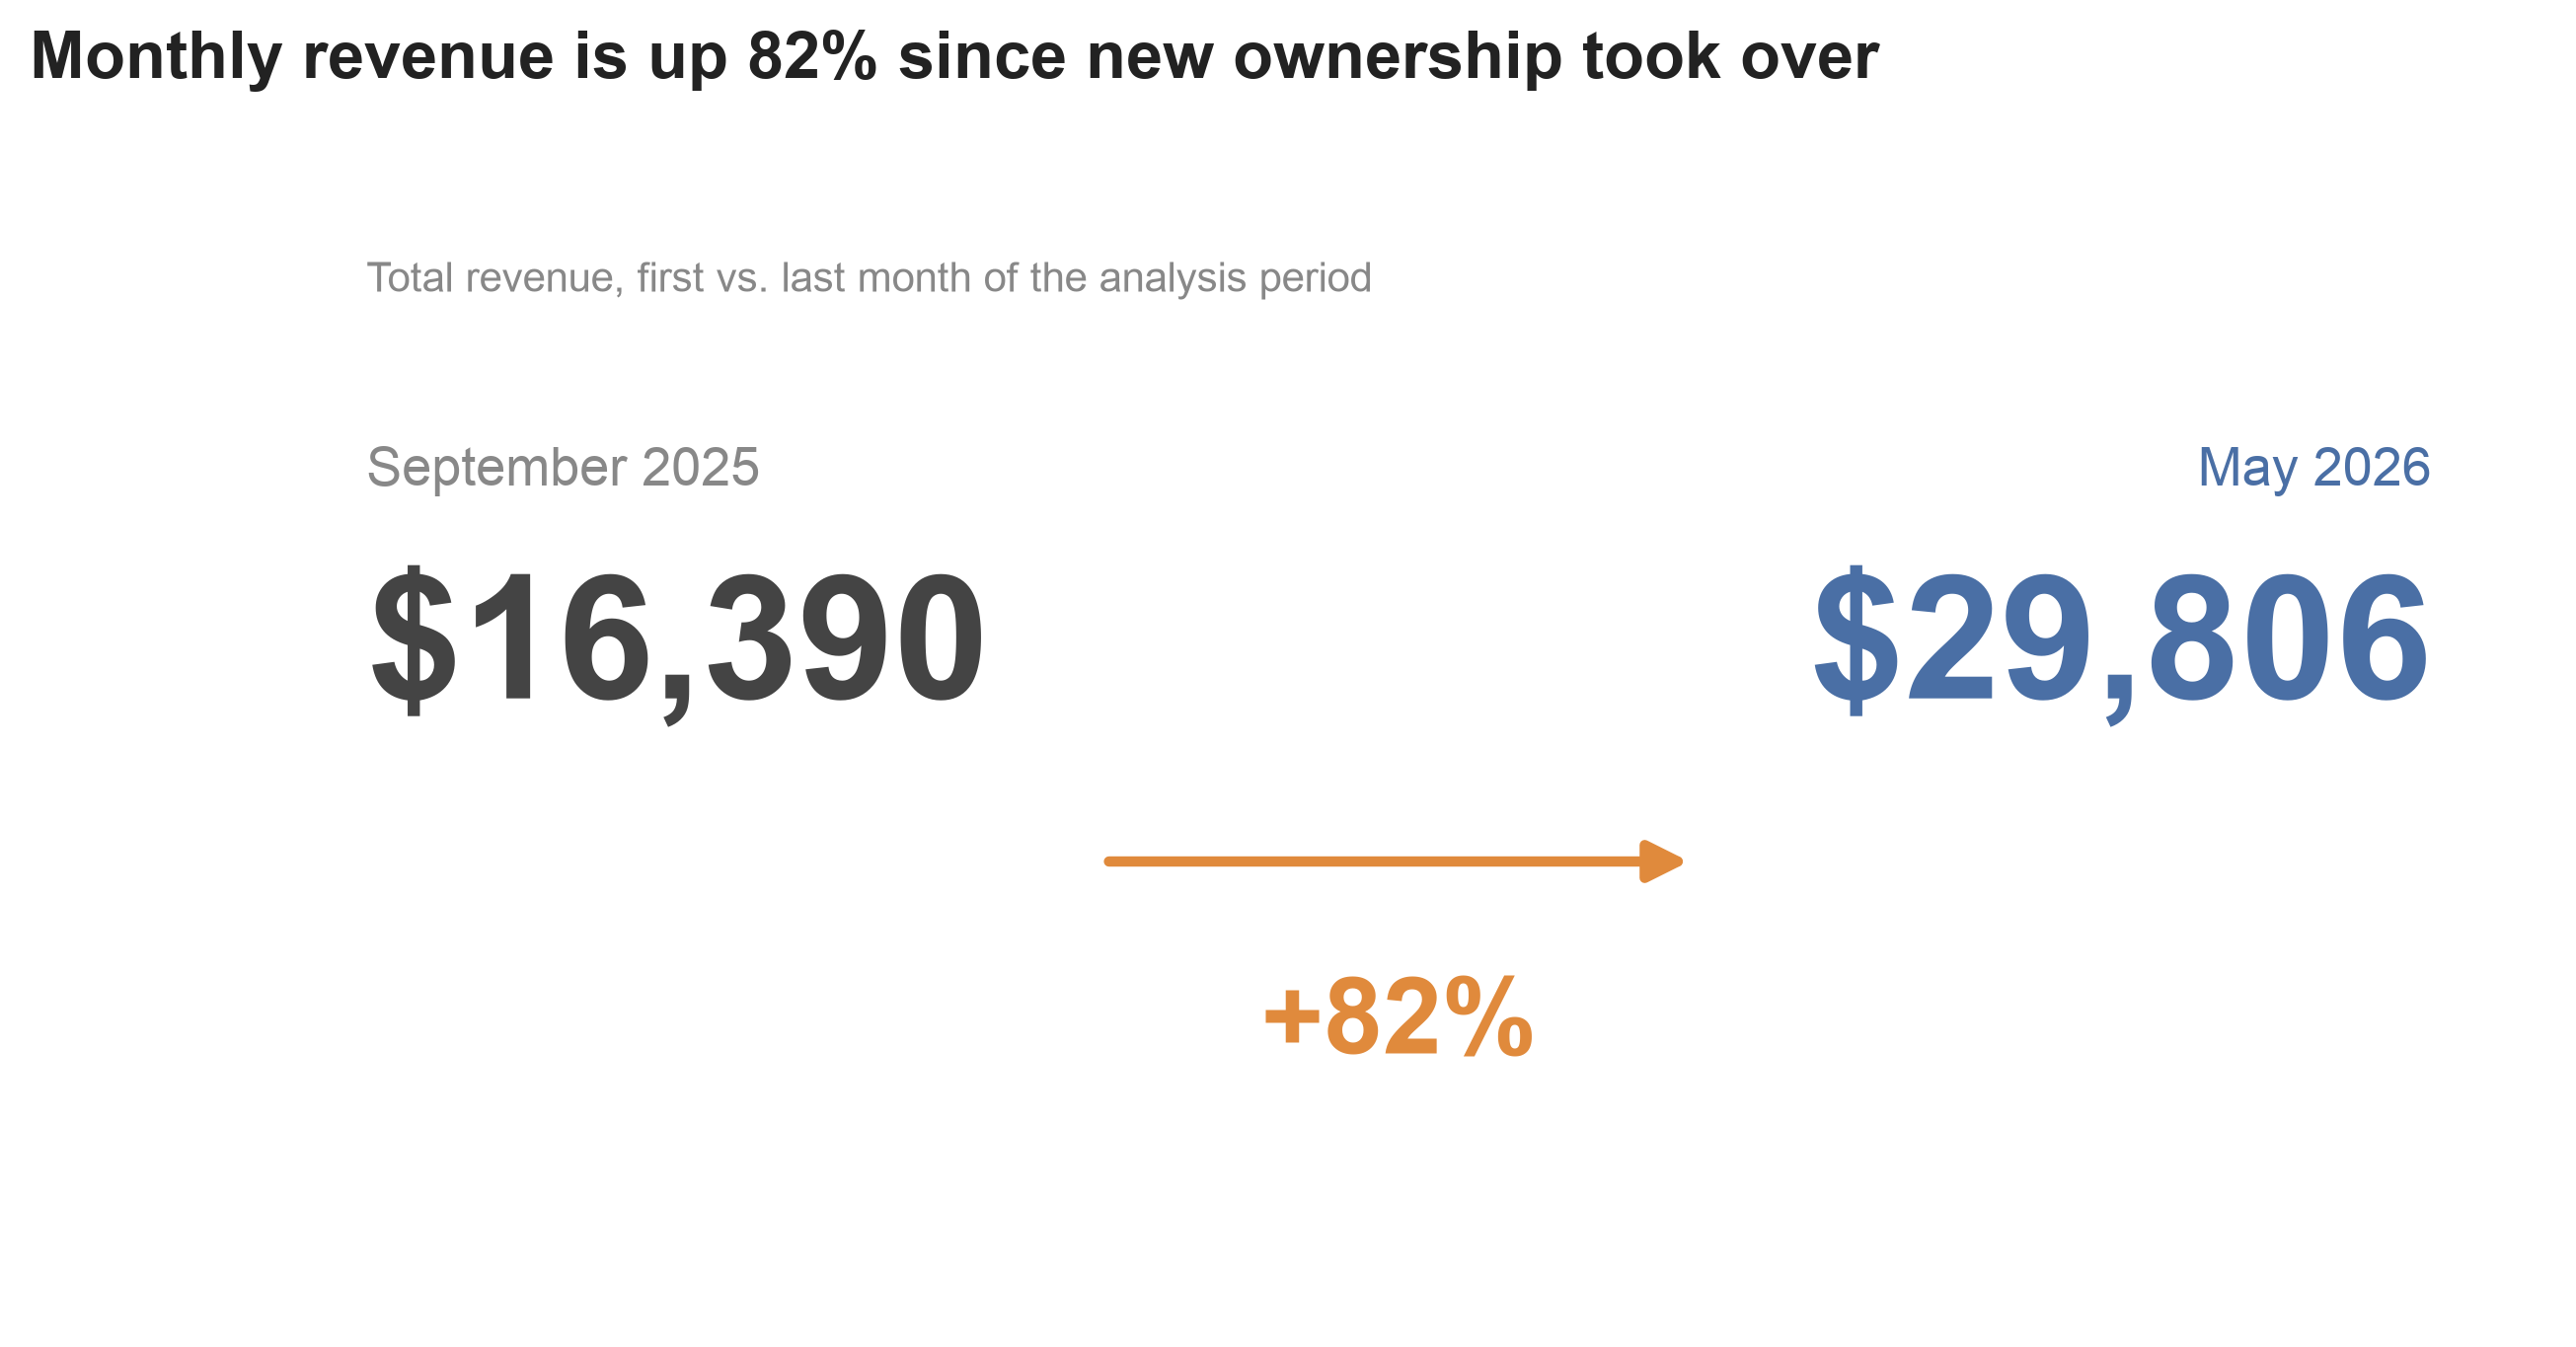

In [17]:
# CHART 1a — Monthly revenue: September vs May, big-number comparison

sep_val = monthly_revenue.iloc[0]
may_val = monthly_revenue.iloc[-1]
growth = (may_val / sep_val - 1) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

ax.text(0.05, 0.72, 'September 2025', fontsize=13, color=MUTED, ha='left', va='bottom')
ax.text(0.05, 0.66, f'${sep_val:,.0f}', fontsize=42, fontweight='bold', color=INK_SOFT, ha='left', va='top')

ax.text(0.95, 0.72, 'May 2026', fontsize=13, color=BLUE, ha='right', va='bottom')
ax.text(0.95, 0.66, f'${may_val:,.0f}', fontsize=42, fontweight='bold', color=BLUE, ha='right', va='top')

ax.annotate('', xy=(0.63, 0.40), xytext=(0.37, 0.40),
            arrowprops=dict(arrowstyle='-|>', color=ORANGE, lw=2.5, mutation_scale=20))
ax.text(0.5, 0.30, f'+{growth:.0f}%', fontsize=26, fontweight='bold', color=ORANGE, ha='center', va='top')

fig.suptitle('Monthly revenue is up 82% since new ownership took over', x=0.05, ha='left', y=0.98,
             fontsize=16, fontweight='bold', color=INK)
ax.text(0.05, 0.9, 'Total revenue, first vs. last month of the analysis period', fontsize=10, color=MUTED)

save_chart(fig)
plt.show()

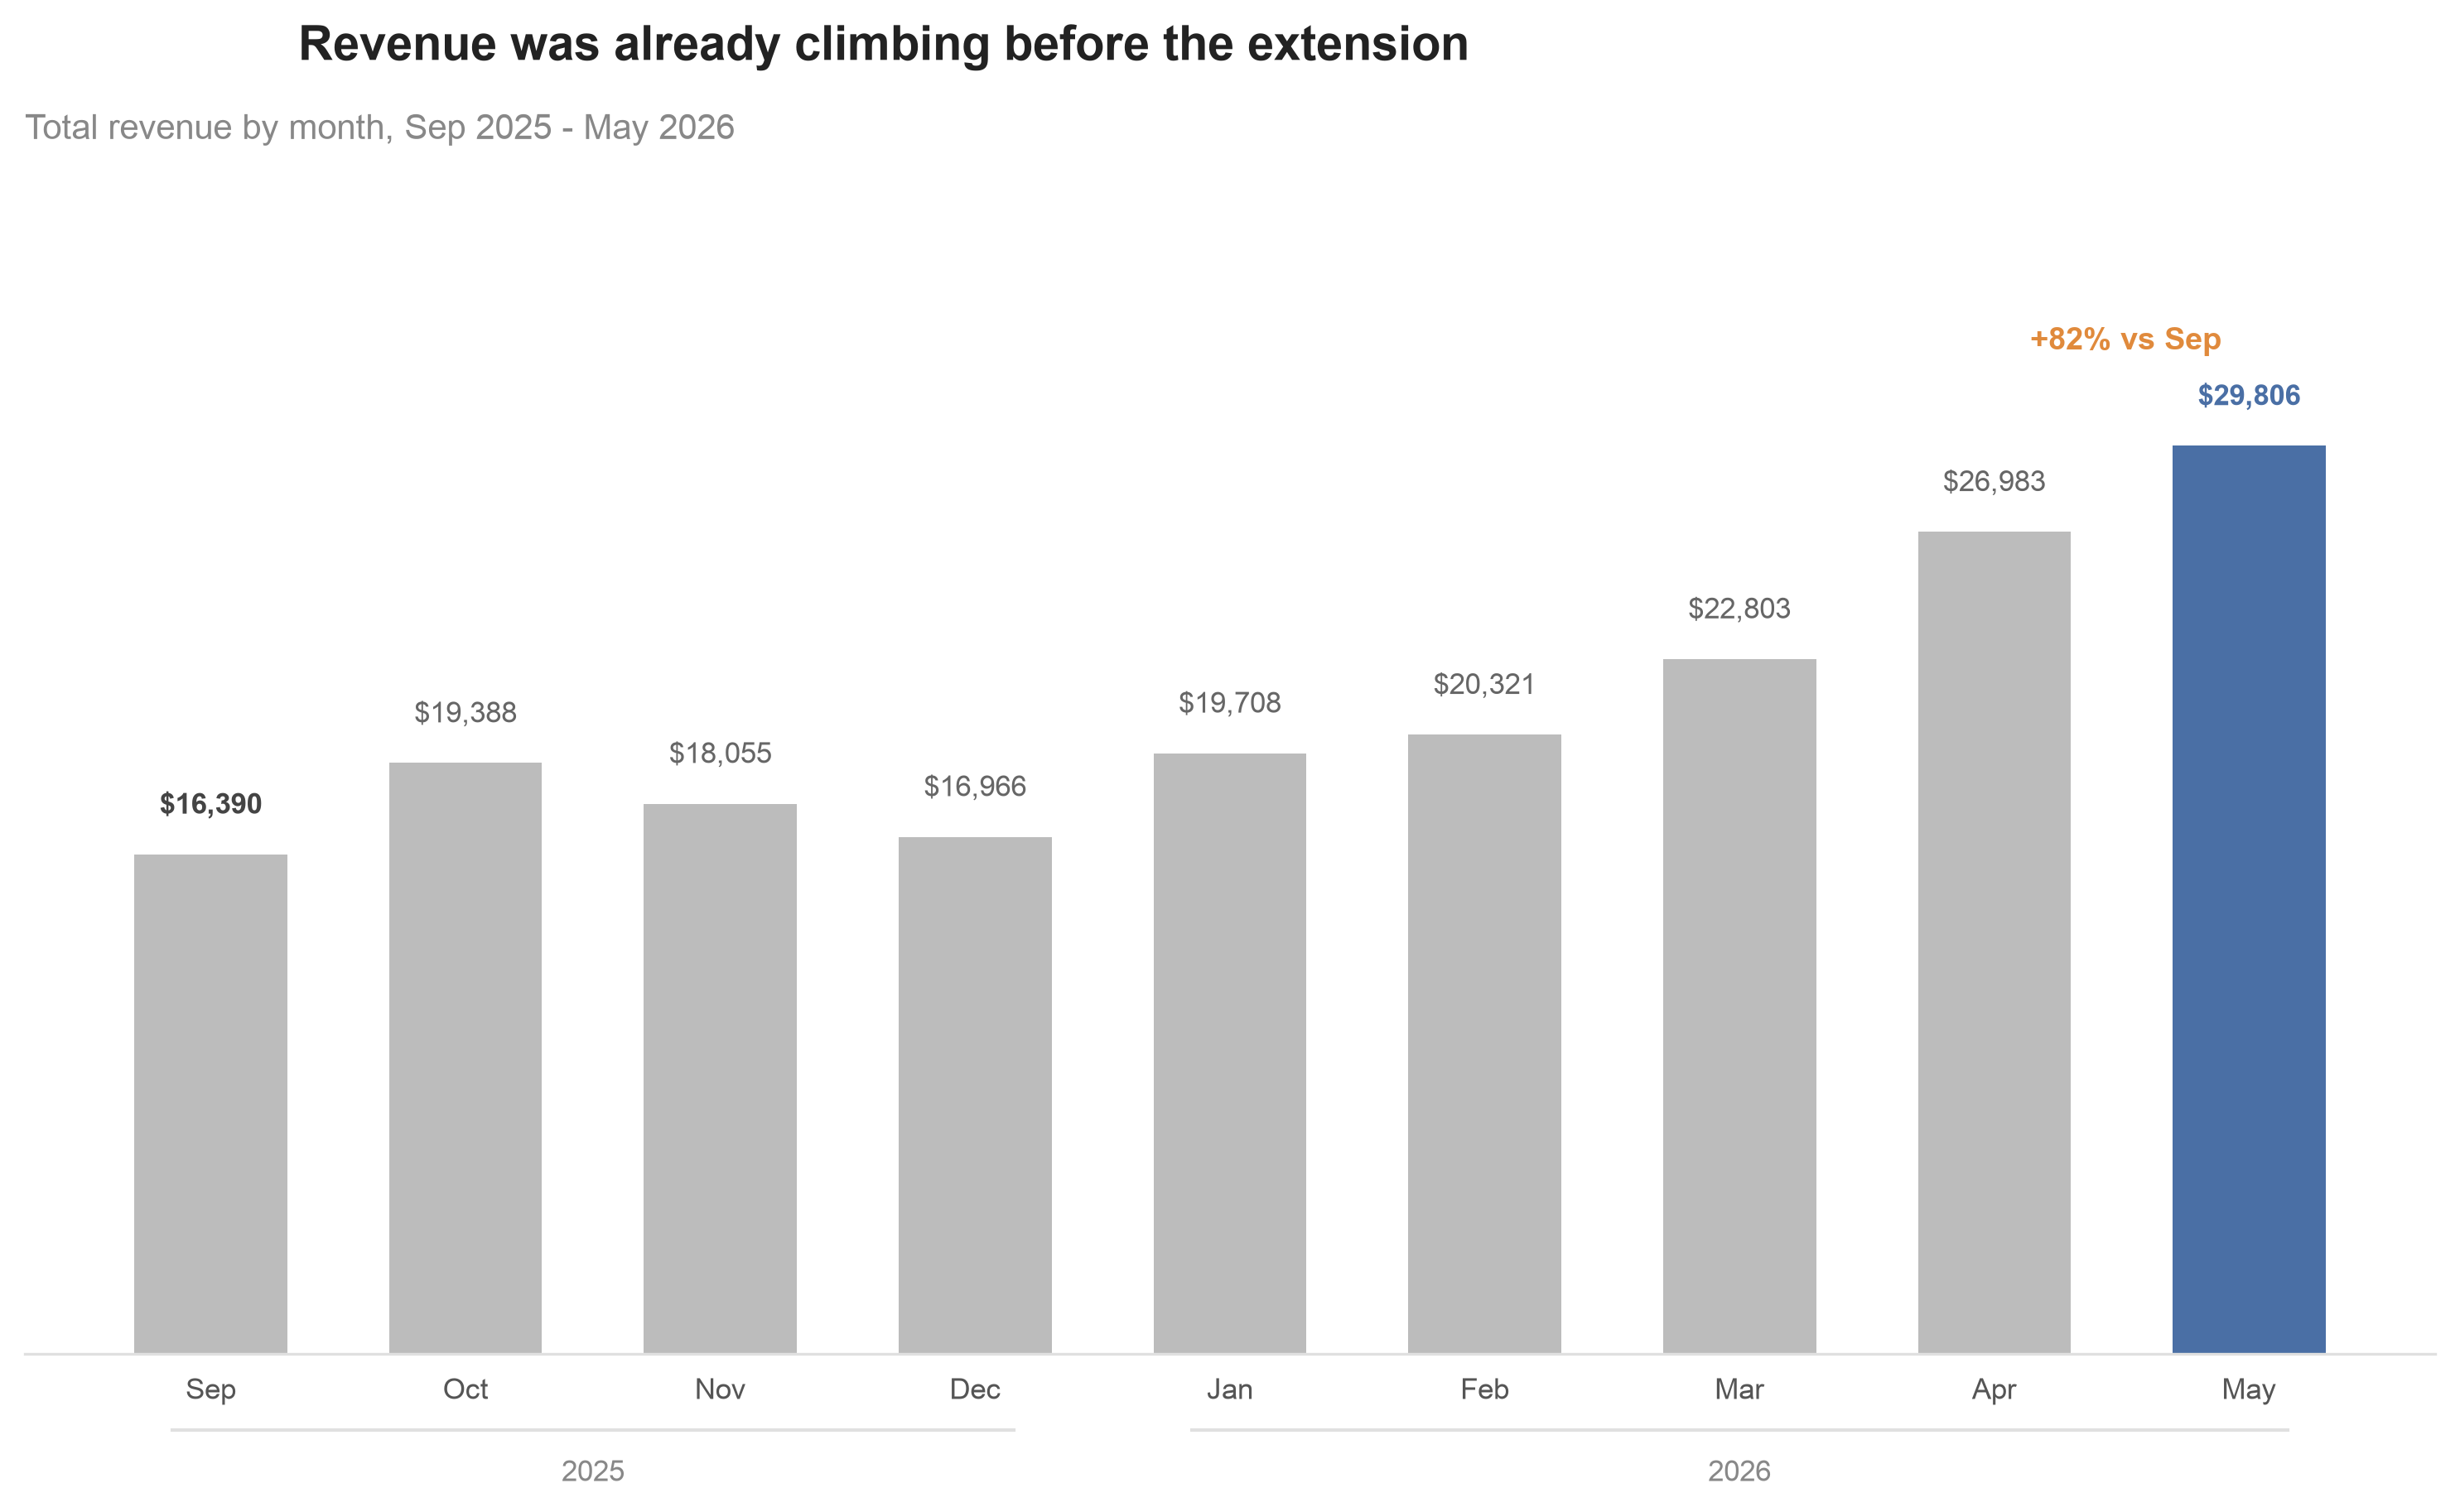

In [18]:
# CHART 1b — Monthly revenue by month (bar chart: focused on magnitude per month)
# Scale/margins locked to match Chart 1c exactly, so the bar->line transition
# between the two doesn't shift ticks, labels, or the plot area around.

month_labels = [pd.Timestamp(year=y, month=m, day=1).strftime('%b') for y, m in monthly_revenue.index]
x = list(range(len(monthly_revenue)))
vals = monthly_revenue.values

peak = int(vals.argmax())
growth = (vals[peak] / vals[0] - 1) * 100

fig, ax = plt.subplots(figsize=(10, 6.3))
bar_colors = [BLUE if i == peak else GREY_BAR for i in range(len(vals))]
ax.bar(x, vals, color=bar_colors, width=0.6, zorder=2)
ax.set_ylim(0, vals.max() * 1.3)

for i, v in enumerate(vals):
    is_peak = i == peak
    is_start = i == 0
    color = BLUE if is_peak else (INK_SOFT if is_start else LABEL)
    ax.annotate(f'${v:,.0f}', xy=(i, v), textcoords='offset points',
                xytext=(0, 10), ha='center', va='bottom', fontsize=8.5,
                color=color, fontweight='bold' if (is_peak or is_start) else 'normal')

# compact growth badge next to the peak bar, instead of a full-width arrow
ax.annotate(f'+{growth:.0f}% vs Sep', xy=(peak, vals[peak]), xytext=(-8, 26),
            textcoords='offset points', ha='right', va='bottom',
            fontsize=9, fontweight='bold', color=ORANGE)

fig.suptitle('Revenue was already climbing before the extension', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Total revenue by month, Sep 2025 - May 2026', loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=8.5, color=TICK)
add_year_axis_groups(ax, [('2025', 0, 3), ('2026', 4, 8)])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()

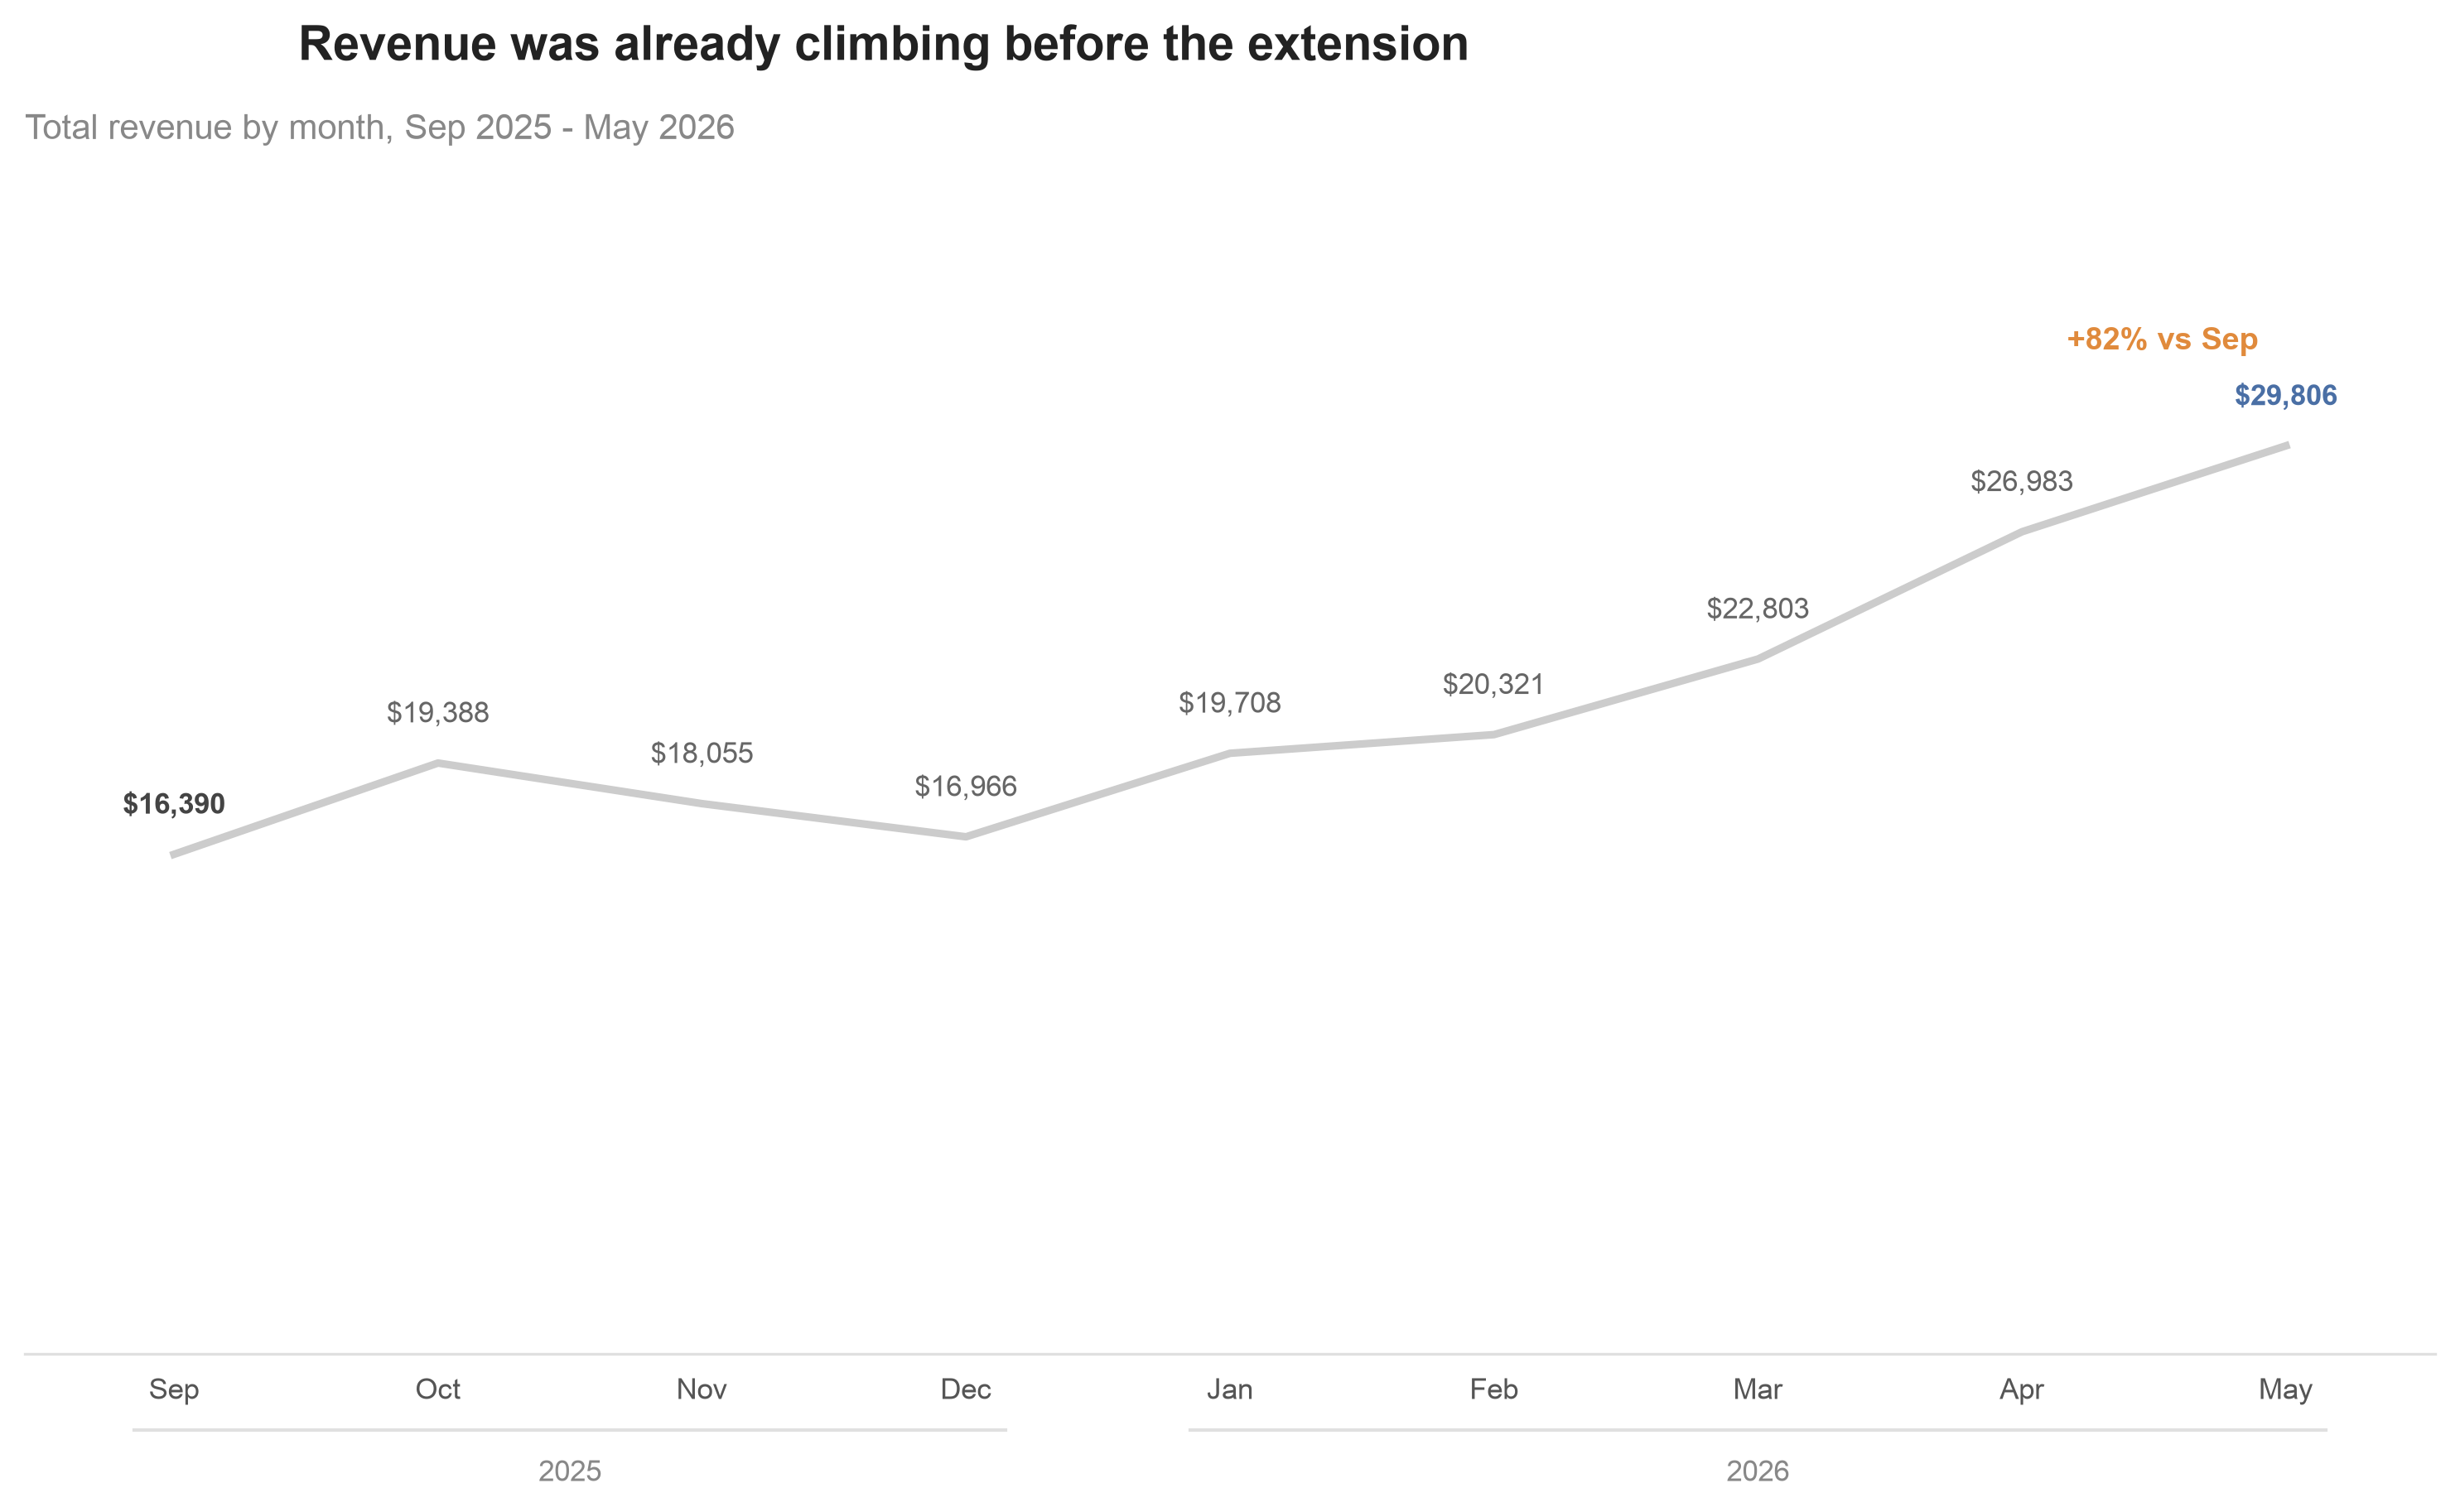

In [19]:
# CHART 1b2 — Monthly revenue progression (single line, no pre/post split)
# Bridge chart between the bar chart (magnitude per month) and the
# pre/post-shaded chart (extension impact) -- same per-month labeling and
# growth badge as the bar chart, just as a connected line.

fig, ax = plt.subplots(figsize=(10, 6.3))
ax.plot(x, vals, color=GREY_LINE, lw=2.2, zorder=2)

peak = int(vals.argmax())
growth = (vals[peak] / vals[0] - 1) * 100

ax.set_ylim(0, vals.max() * 1.3)

for i, v in enumerate(vals):
    is_peak = i == peak
    is_start = i == 0
    color = BLUE if is_peak else (INK_SOFT if is_start else LABEL)
    ax.annotate(f'${v:,.0f}', xy=(i, v), textcoords='offset points',
                xytext=(0, 10), ha='center', va='bottom', fontsize=8.5,
                color=color, fontweight='bold' if (is_peak or is_start) else 'normal')

# compact growth badge next to the peak point, instead of a full-width arrow
ax.annotate(f'+{growth:.0f}% vs Sep', xy=(peak, vals[peak]), xytext=(-8, 26),
            textcoords='offset points', ha='right', va='bottom',
            fontsize=9, fontweight='bold', color=ORANGE)

fig.suptitle('Revenue was already climbing before the extension', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Total revenue by month, Sep 2025 - May 2026', loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=8.5, color=TICK)
add_year_axis_groups(ax, [('2025', 0, 3), ('2026', 4, 8)])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()

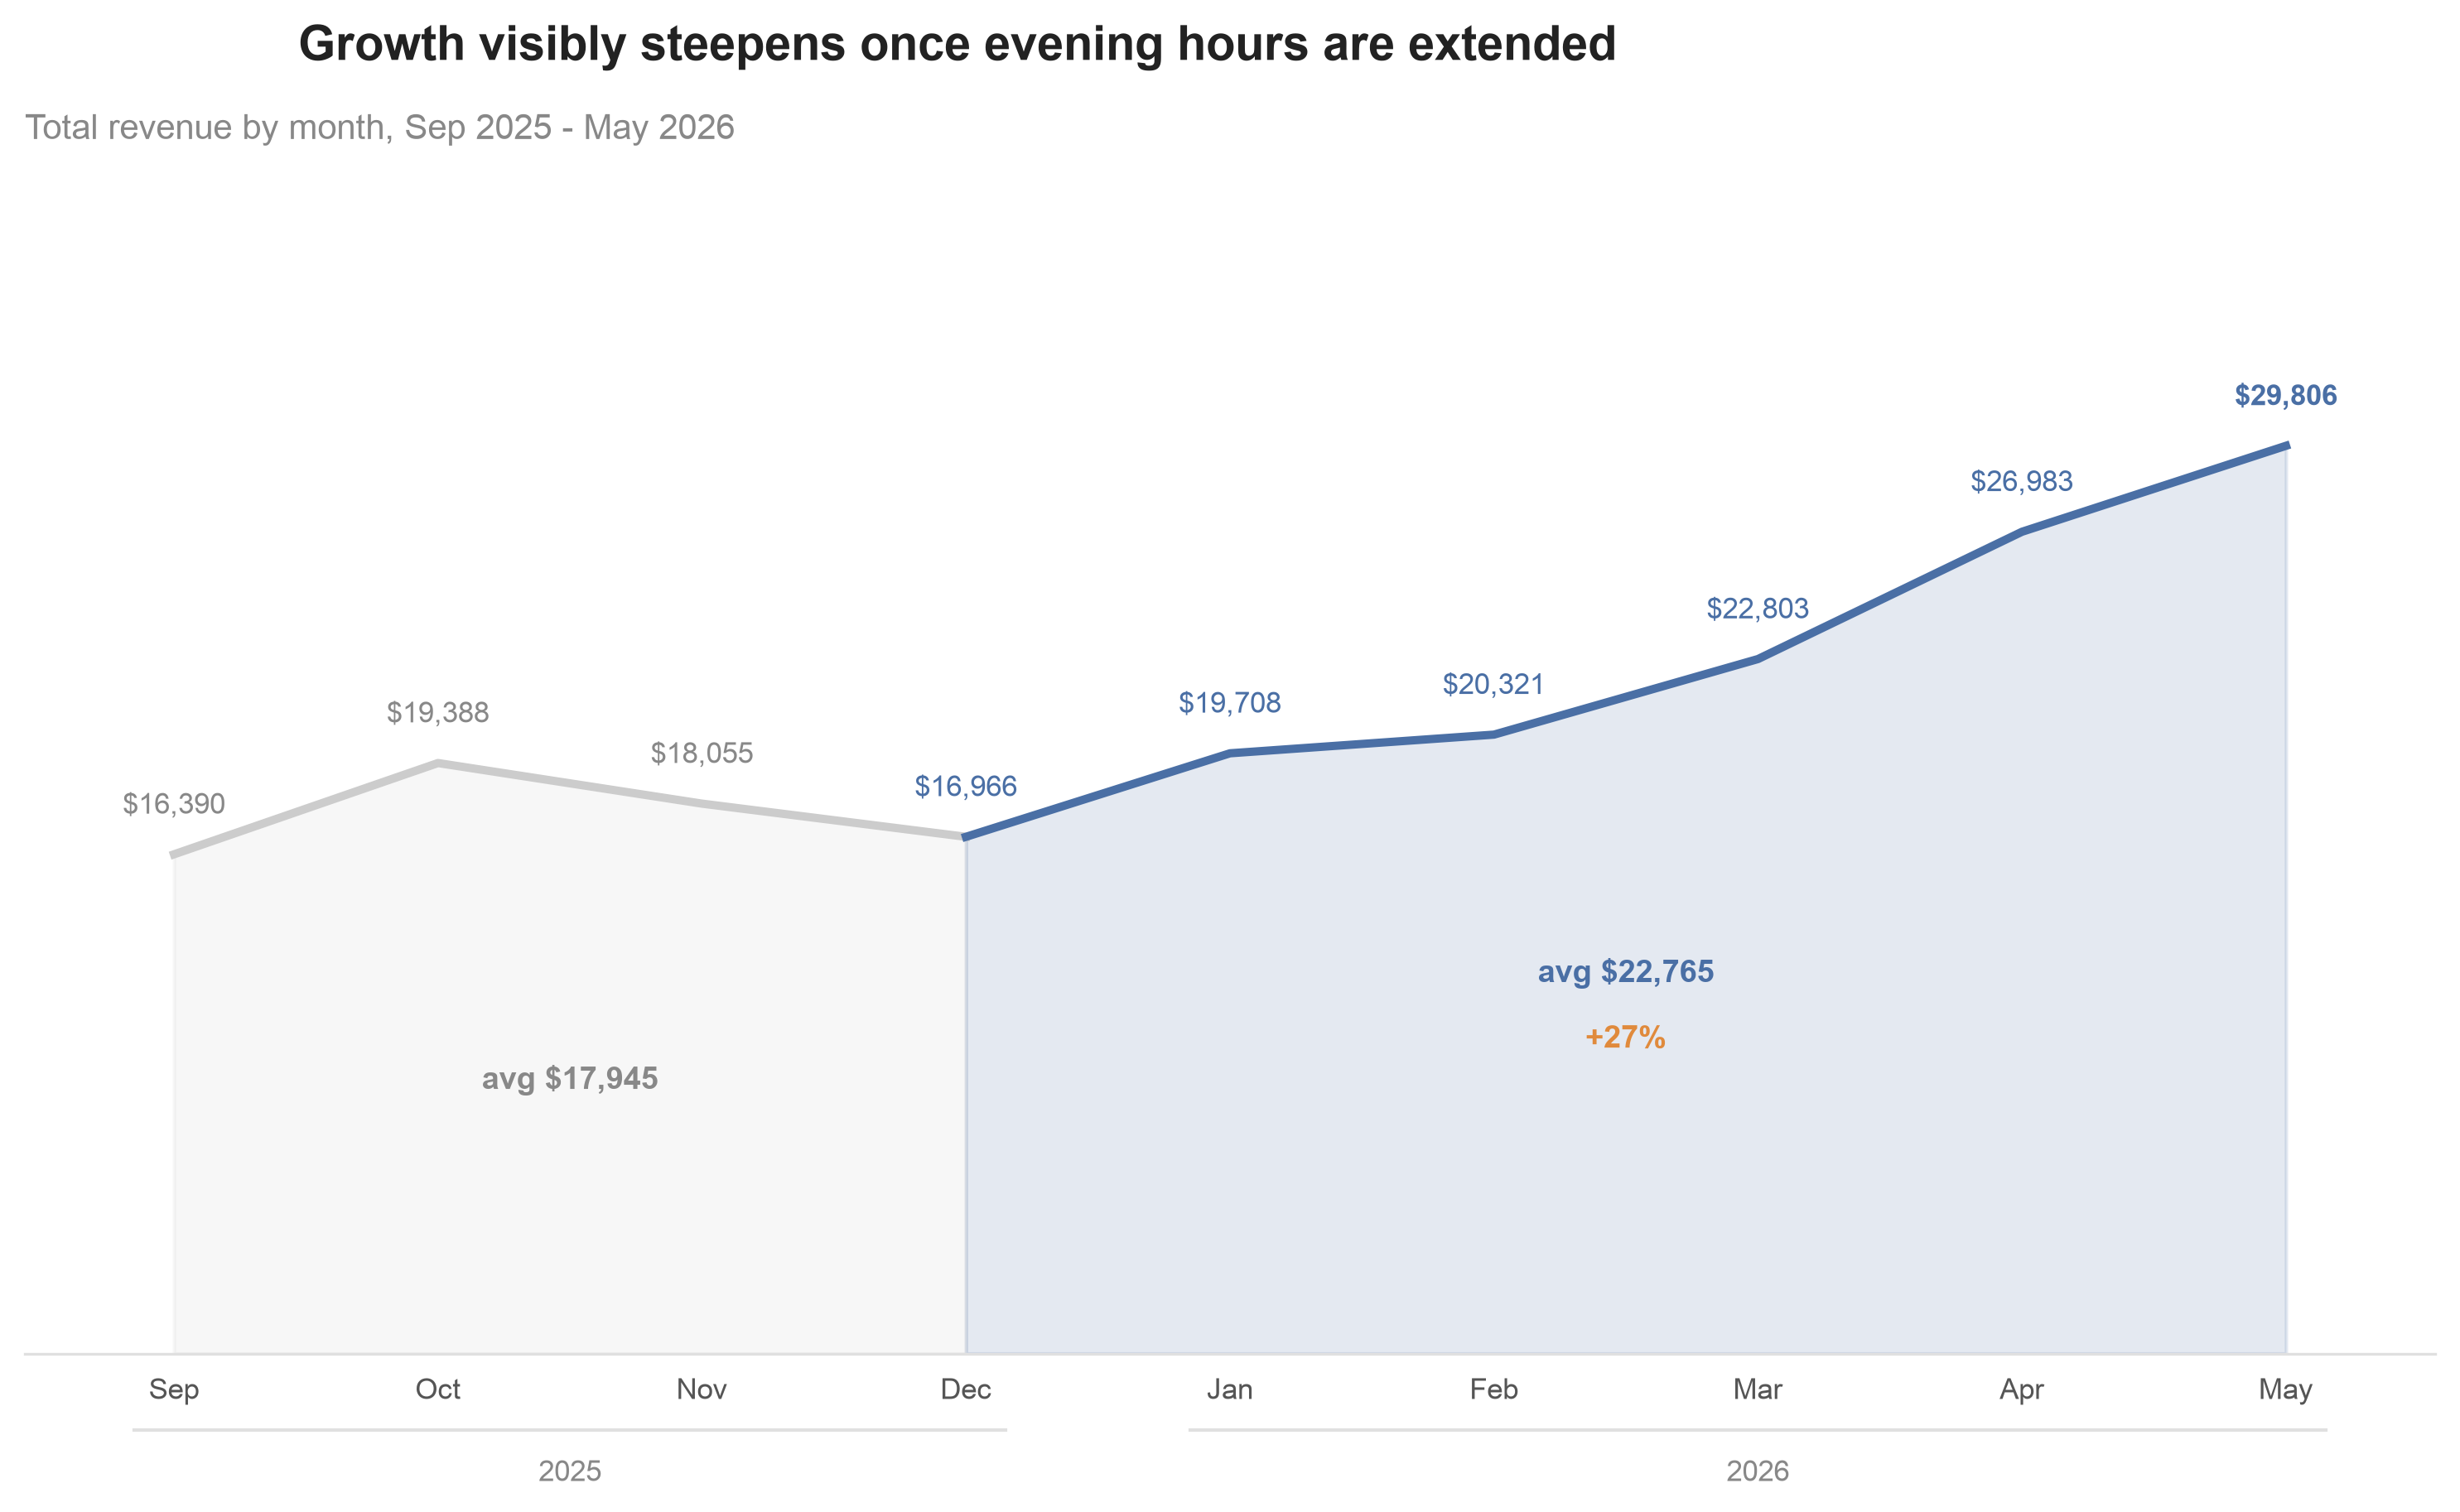

In [20]:
# CHART 1c — Monthly revenue: pre vs post evening-extension coloring
# Scale/margins locked to match Chart 1b exactly. Per-month labels above
# the line (colored by segment); avg + increase labels sit inside the
# shaded fill areas so they don't compete with the per-month labels.

fig, ax = plt.subplots(figsize=(10, 6.3))

# Pre = Sep-Nov (fully before the Dec 1 extension), Post = Dec-May
# (matches the EXTENSION_START cutoff used everywhere else in this analysis)
pre_avg = vals[:3].mean()
post_avg = vals[3:].mean()
avg_increase = (post_avg / pre_avg - 1) * 100

# grey segment: Sep(0) through Dec(3) -- last pre-extension movement, ending at the Dec point
ax.plot(x[:4], vals[:4], color=GREY_LINE, lw=2.4, zorder=2)
ax.fill_between(x[:4], vals[:4], 0, color=GREY_LINE, alpha=0.15, zorder=1)
# blue segment: Dec(3) through May(8) -- fully post-extension
ax.plot(x[3:], vals[3:], color=BLUE, lw=2.4, zorder=3)
ax.fill_between(x[3:], vals[3:], 0, color=BLUE, alpha=0.15, zorder=1)

ax.set_ylim(0, vals.max() * 1.3)

for i, v in enumerate(vals):
    color = BLUE if i >= 3 else MUTED
    weight = 'bold' if i == len(vals) - 1 else 'normal'
    ax.annotate(f'${v:,.0f}', xy=(i, v), textcoords='offset points',
                xytext=(0, 10), ha='center', va='bottom', fontsize=8.5, color=color, fontweight=weight)

ax.text(1.5, pre_avg * 0.5, f'avg ${pre_avg:,.0f}', ha='center', va='center',
        fontsize=9, color=MUTED, fontweight='bold')

gap = vals.max() * 0.02
ax.text(5.5, post_avg * 0.5 + gap, f'avg ${post_avg:,.0f}', ha='center', va='bottom',
        fontsize=9, color=BLUE, fontweight='bold')
ax.text(5.5, post_avg * 0.5 - gap, f'+{avg_increase:.0f}%', ha='center', va='top',
        fontsize=9, color=ORANGE, fontweight='bold')

fig.suptitle('Growth visibly steepens once evening hours are extended', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Total revenue by month, Sep 2025 - May 2026', loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_xticks(x)
ax.set_xticklabels(month_labels, fontsize=8.5, color=TICK)
add_year_axis_groups(ax, [('2025', 0, 3), ('2026', 4, 8)])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()


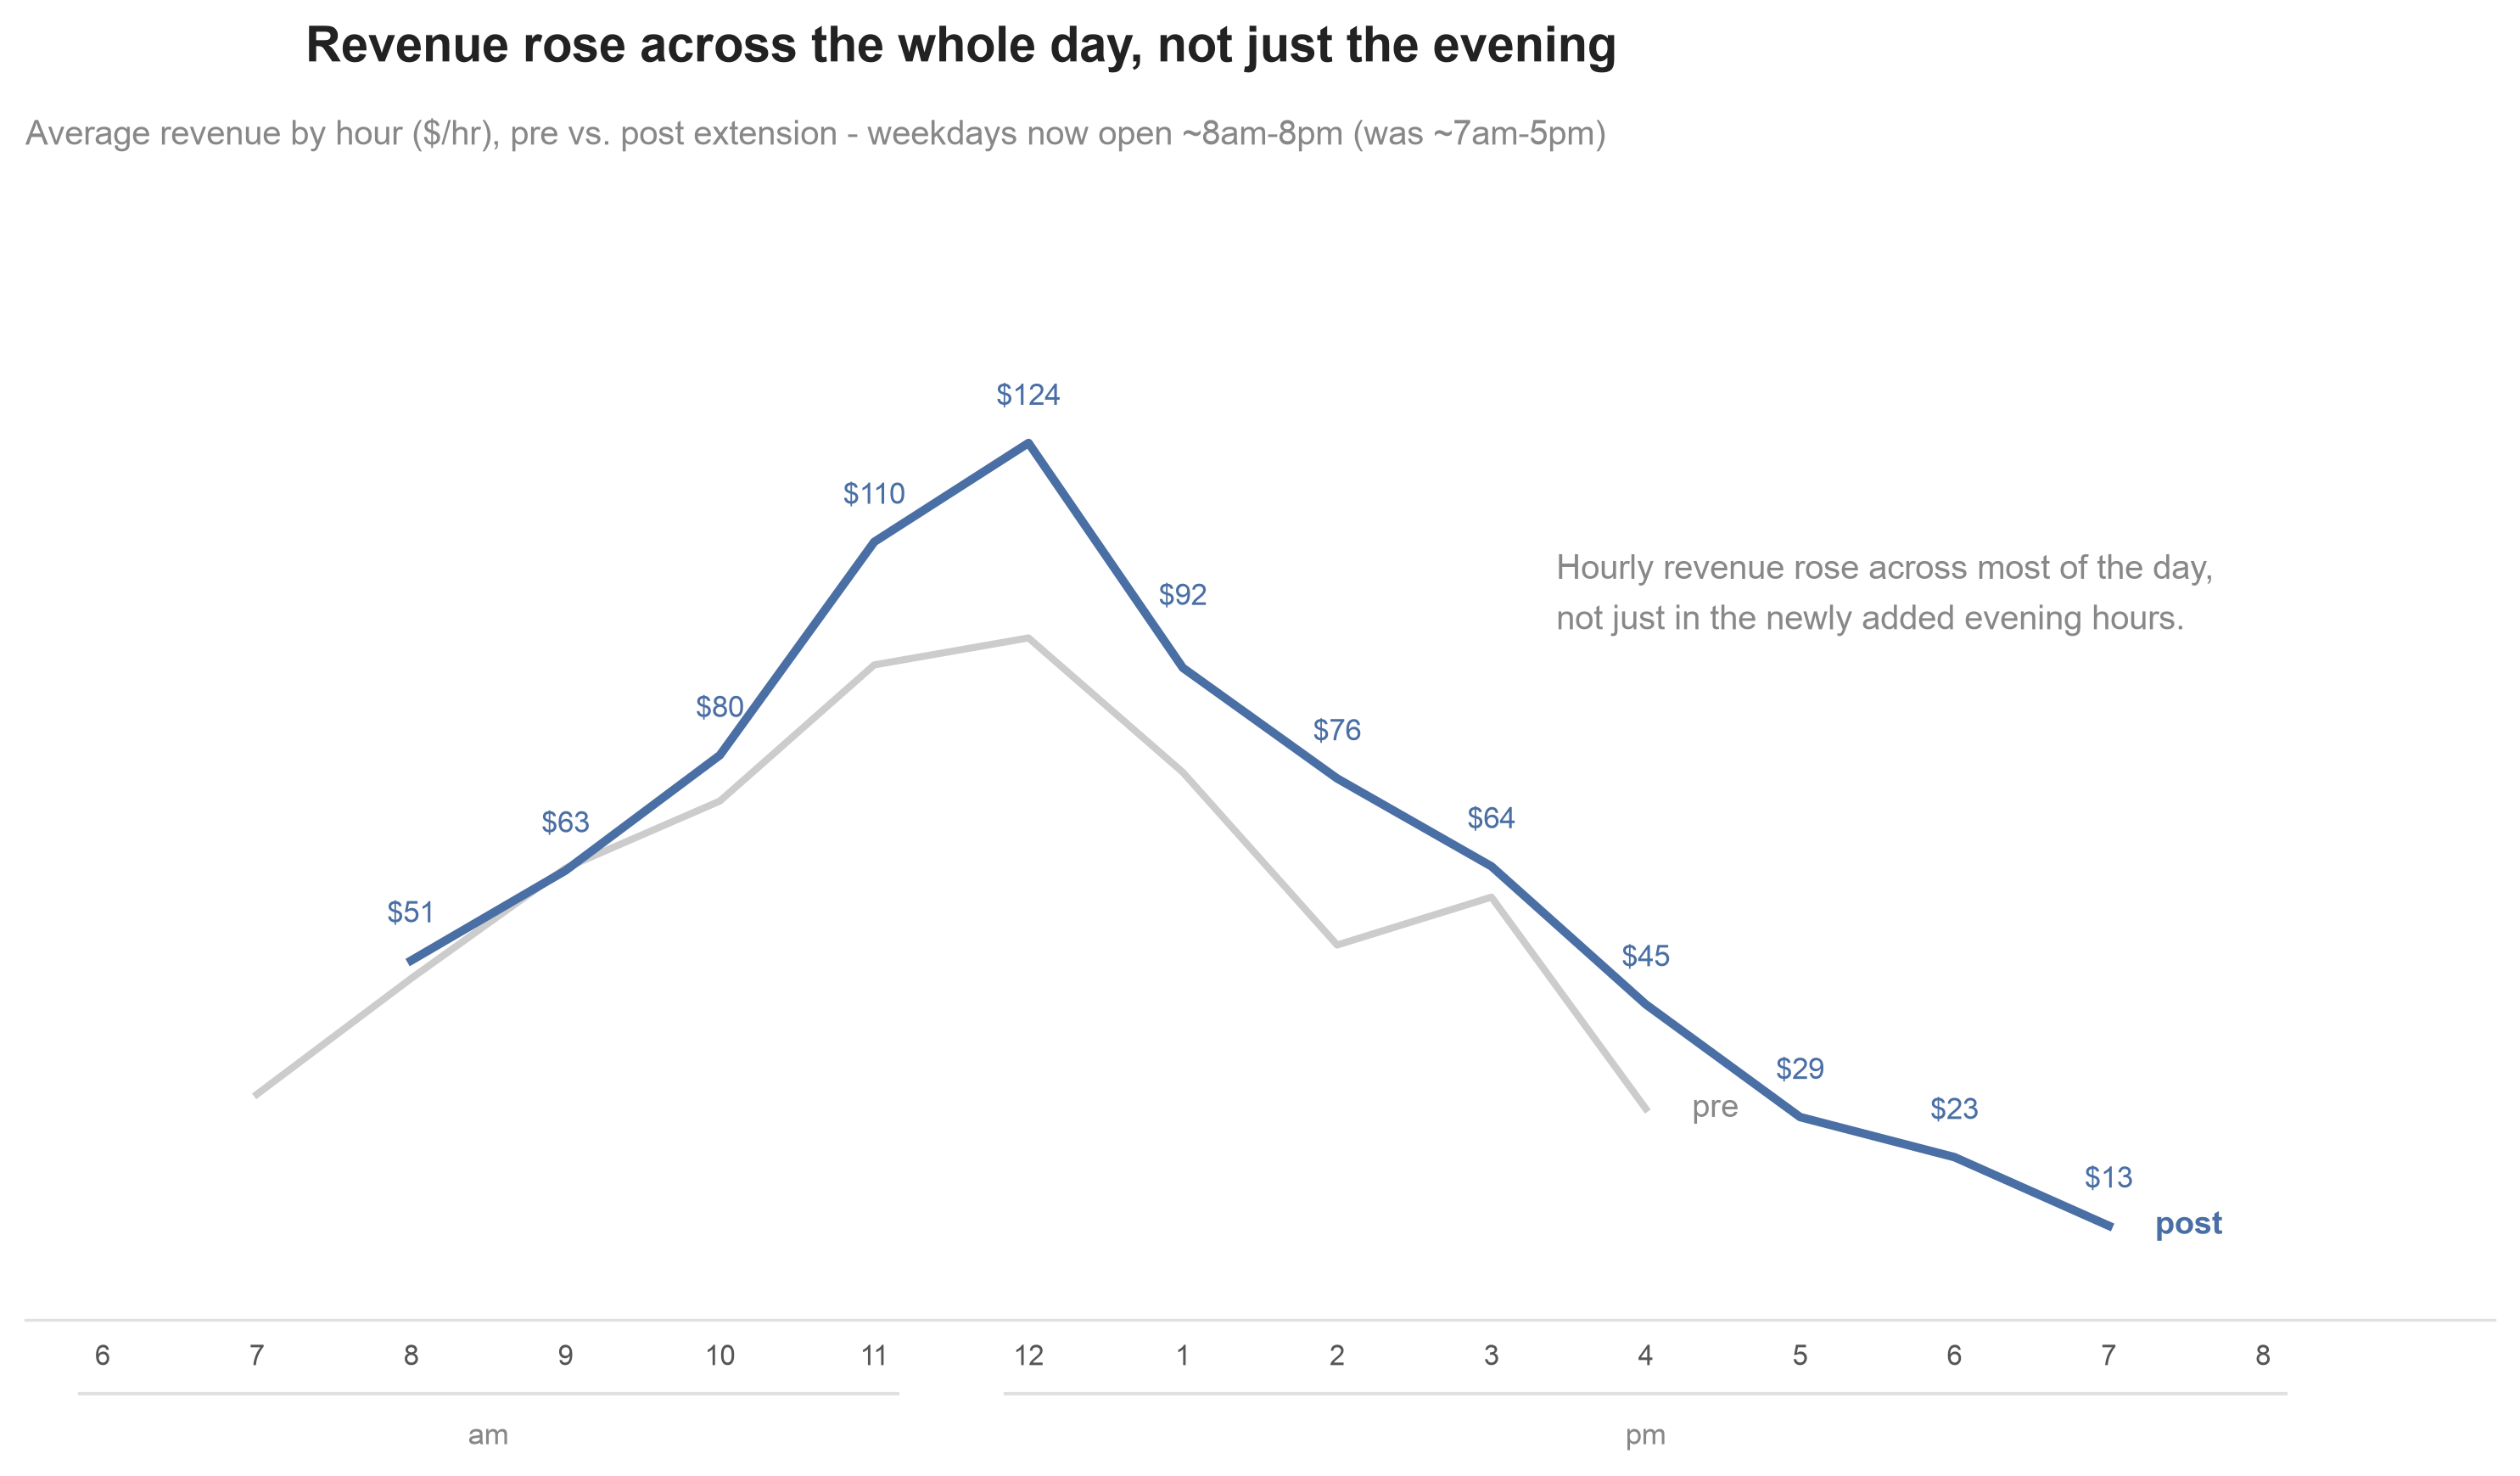

In [21]:
# CHART 2 — Hourly revenue, pre vs post extension (Act 2: the central question)

hours = list(all_hours)
hour_labels = [str(h if h <= 12 else h - 12) for h in hours]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(hours, hourly_revenue_mean_pre.values, color=GREY_LINE, lw=2, zorder=2)
ax.plot(hours, hourly_revenue_mean_post.values, color=BLUE, lw=2.4, zorder=3)

pre_valid = hourly_revenue_mean_pre.dropna()
post_valid = hourly_revenue_mean_post.dropna()
ax.text(pre_valid.index[-1] + 0.3, pre_valid.iloc[-1], 'pre', va='center', ha='left', fontsize=9, color=MUTED)
ax.text(post_valid.index[-1] + 0.3, post_valid.iloc[-1], 'post', va='center', ha='left', fontsize=9, color=BLUE, fontweight='bold')

peak_hour = hourly_revenue_mean_post.idxmax()

# Every post-line hour labeled, including the peak, all in the same style
# (same label style/positioning as the evening-hour callouts in the next
# chart; the point right after the peak sits on the steepest part of the
# drop, so it gets a little extra clearance to keep the line from cutting
# through the text)
for h, v in post_valid.items():
    gap = 16 if h == peak_hour + 1 else 9
    ax.annotate(f'${v:,.0f}', xy=(h, v), textcoords='offset points', xytext=(0, gap),
                ha='center', va='bottom', fontsize=8.5, color=BLUE)

note = 'Hourly revenue rose across most of the day,\nnot just in the newly added evening hours.'
ax.text(0.62, 0.68, note, transform=ax.transAxes, ha='left', va='top', fontsize=9.5, color=MUTED, linespacing=1.6)

fig.suptitle('Revenue rose across the whole day, not just the evening', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour ($/hr), pre vs. post extension - weekdays now open ~8am-8pm (was ~7am-5pm)',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, hourly_revenue_mean_post.max() * 1.3)
ax.set_xlim(hours[0] - 0.5, hours[-1] + 1.5)
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours[0], 11), ('pm', 12, hours[-1])])
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', labelleft=False, left=False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()


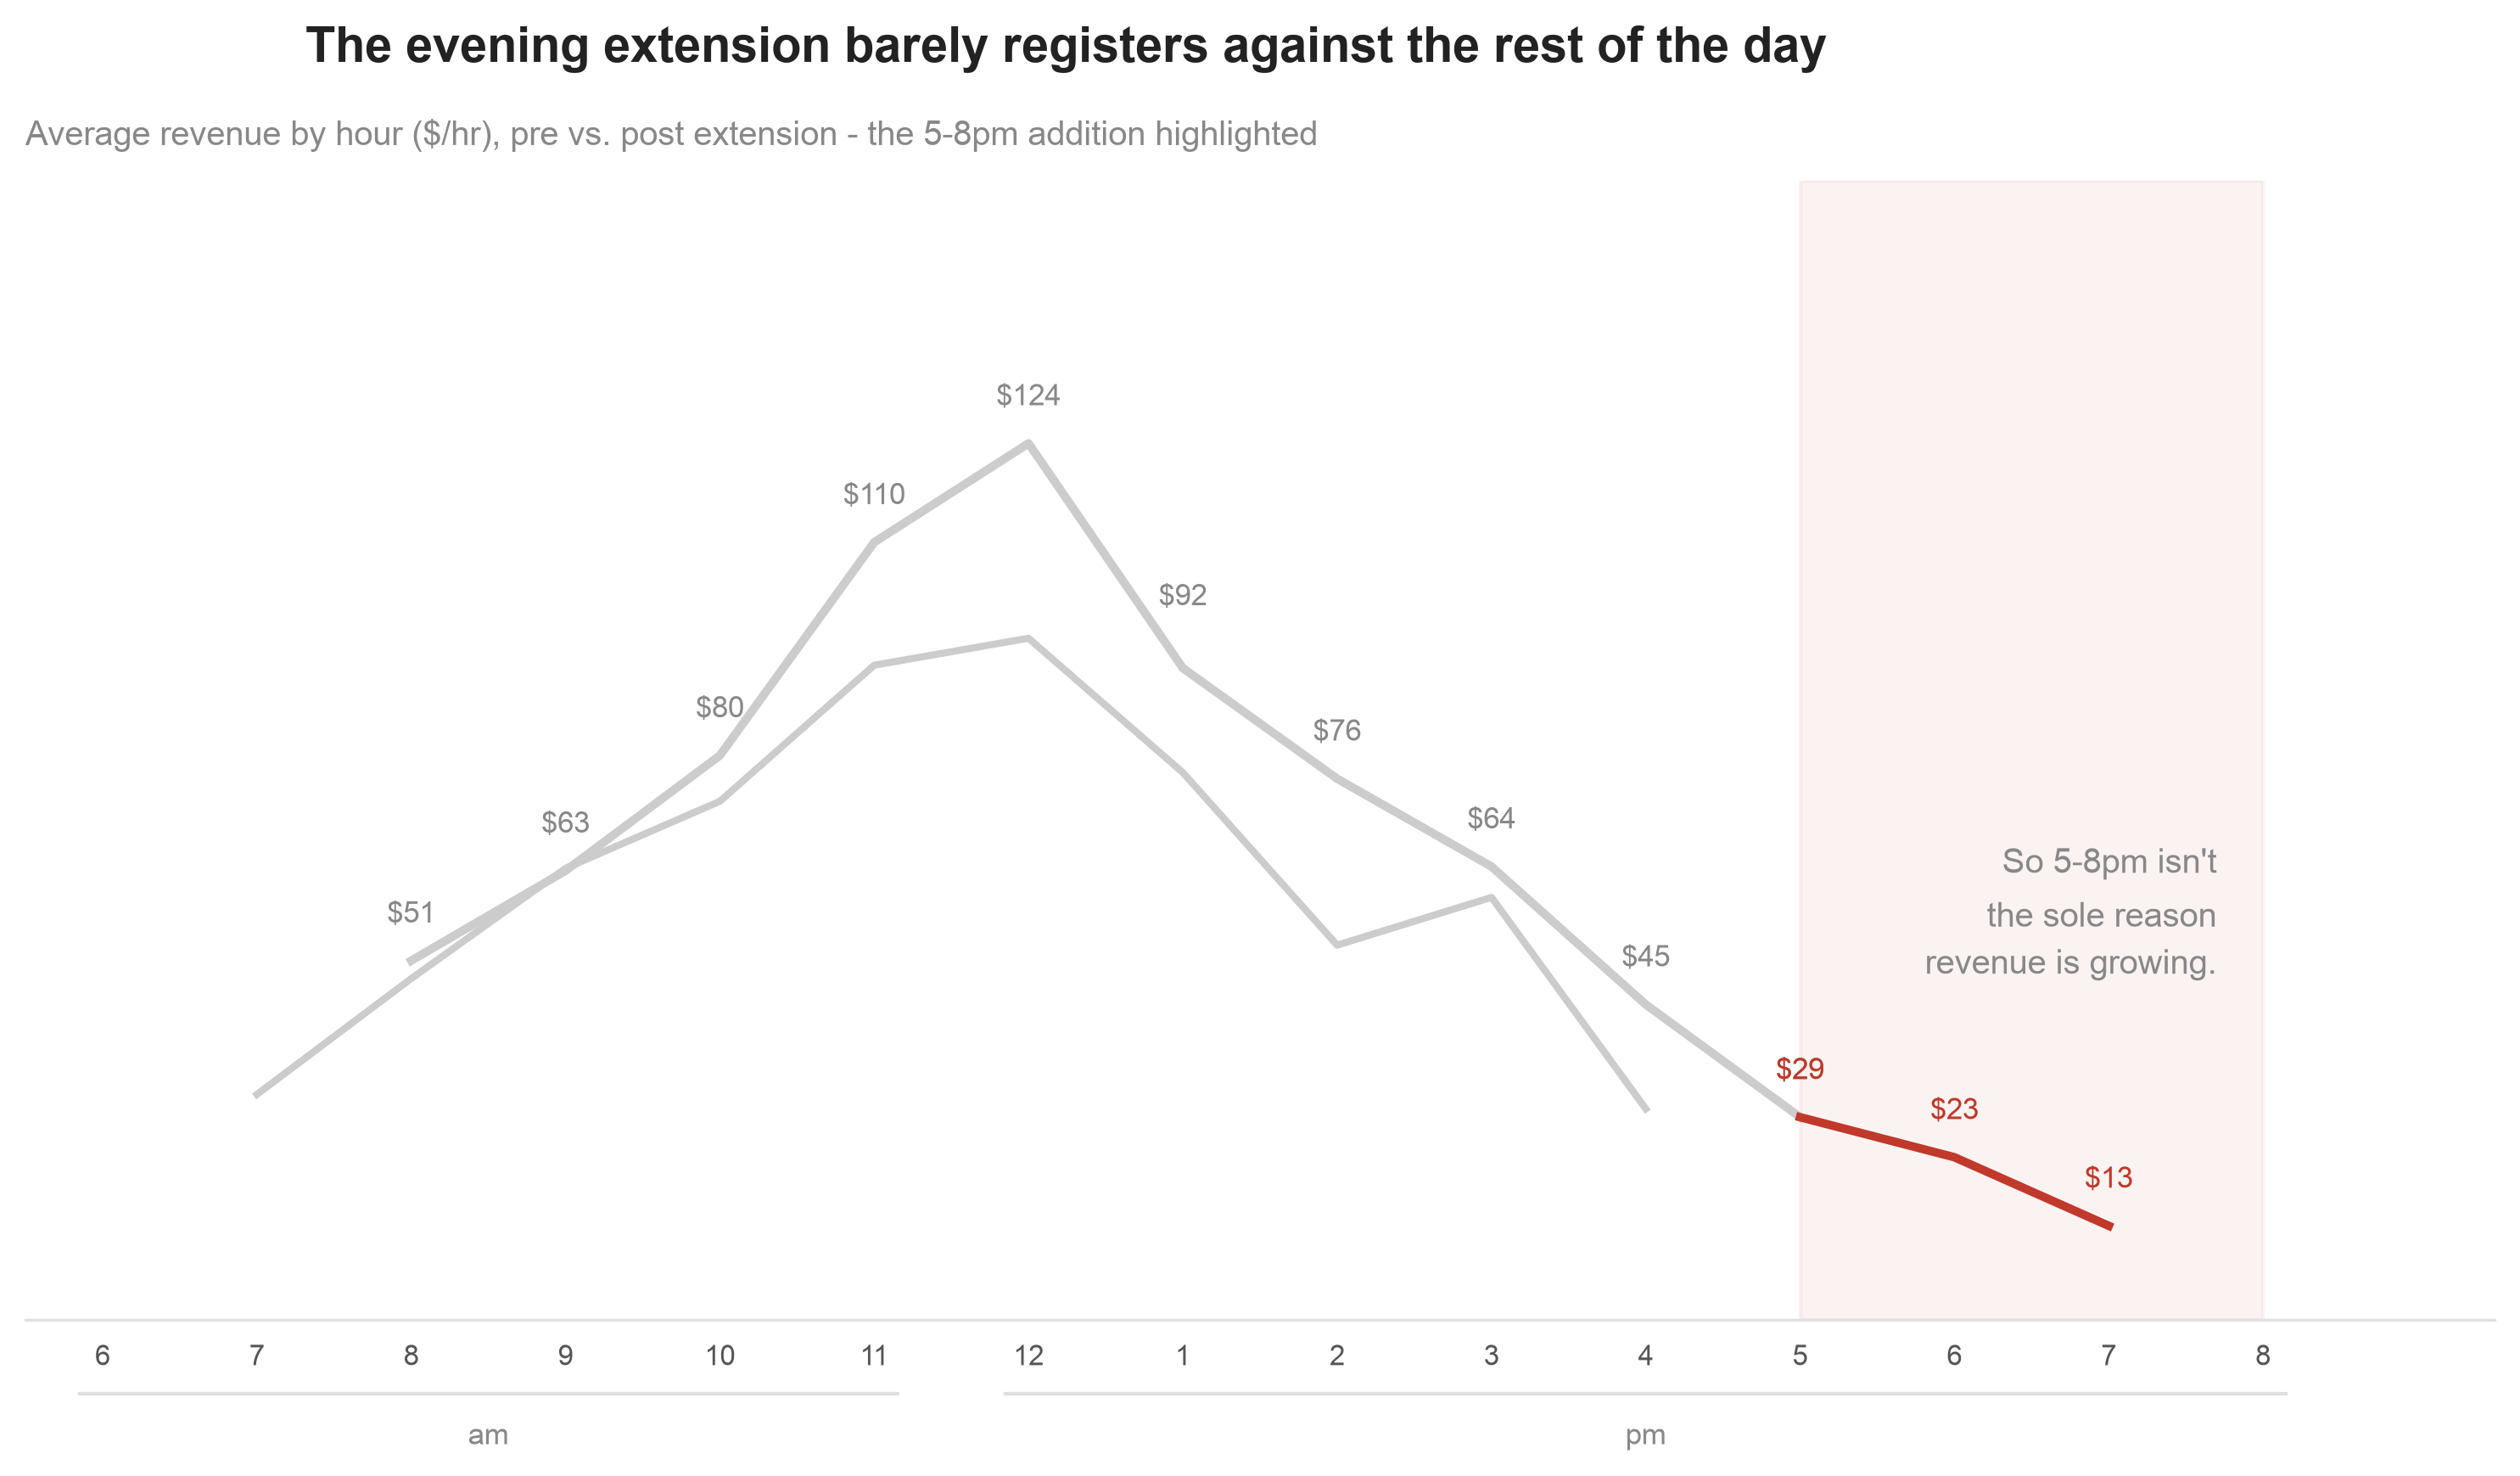

In [22]:
# CHART 2b — Hourly revenue, pre vs post, with the 5-8pm extension emphasized

fig, ax = plt.subplots(figsize=(10, 6))

core_hours = [h for h in hours if h <= 17]
tail_hours = [h for h in hours if h >= 17]

ax.plot(hours, hourly_revenue_mean_pre.values, color=GREY_LINE, lw=2, zorder=2)
ax.plot(core_hours, hourly_revenue_mean_post.loc[core_hours].values, color=GREY_LINE, lw=2.4, zorder=2)
ax.plot(tail_hours, hourly_revenue_mean_post.loc[tail_hours].values, color=RED, lw=2.4, zorder=3)

ax.axvspan(17, 20, color=RED, alpha=0.06, zorder=1)

# Label the full post-extension line in grey (including the peak, same
# style as every other hour) so the red 5-8pm labels read as emphasis
# against the full picture rather than the only numbers on the chart.
for h, v in hourly_revenue_mean_post.loc[core_hours].dropna().items():
    gap = 16 if h == peak_hour + 1 else 9
    ax.annotate(f'${v:,.0f}', xy=(h, v), textcoords='offset points', xytext=(0, gap),
                ha='center', va='bottom', fontsize=8.5, color=MUTED)

# Call out how thin the new evening hours actually are
for h in [17, 18, 19]:
    v = hourly_revenue_mean_post[h]
    ax.annotate(f'${v:,.0f}', xy=(h, v), textcoords='offset points', xytext=(0, 9),
                ha='center', va='bottom', fontsize=8.5, color=RED)

note = "So 5-8pm isn't\nthe sole reason\nrevenue is growing."
ax.text(19.7, 68, note, ha='right', va='top', fontsize=9.5, color=MUTED, linespacing=1.6)

fig.suptitle('The evening extension barely registers against the rest of the day', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour ($/hr), pre vs. post extension - the 5-8pm addition highlighted',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, hourly_revenue_mean_post.max() * 1.3)
ax.set_xlim(hours[0] - 0.5, hours[-1] + 1.5)
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours[0], 11), ('pm', 12, hours[-1])])
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', labelleft=False, left=False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()


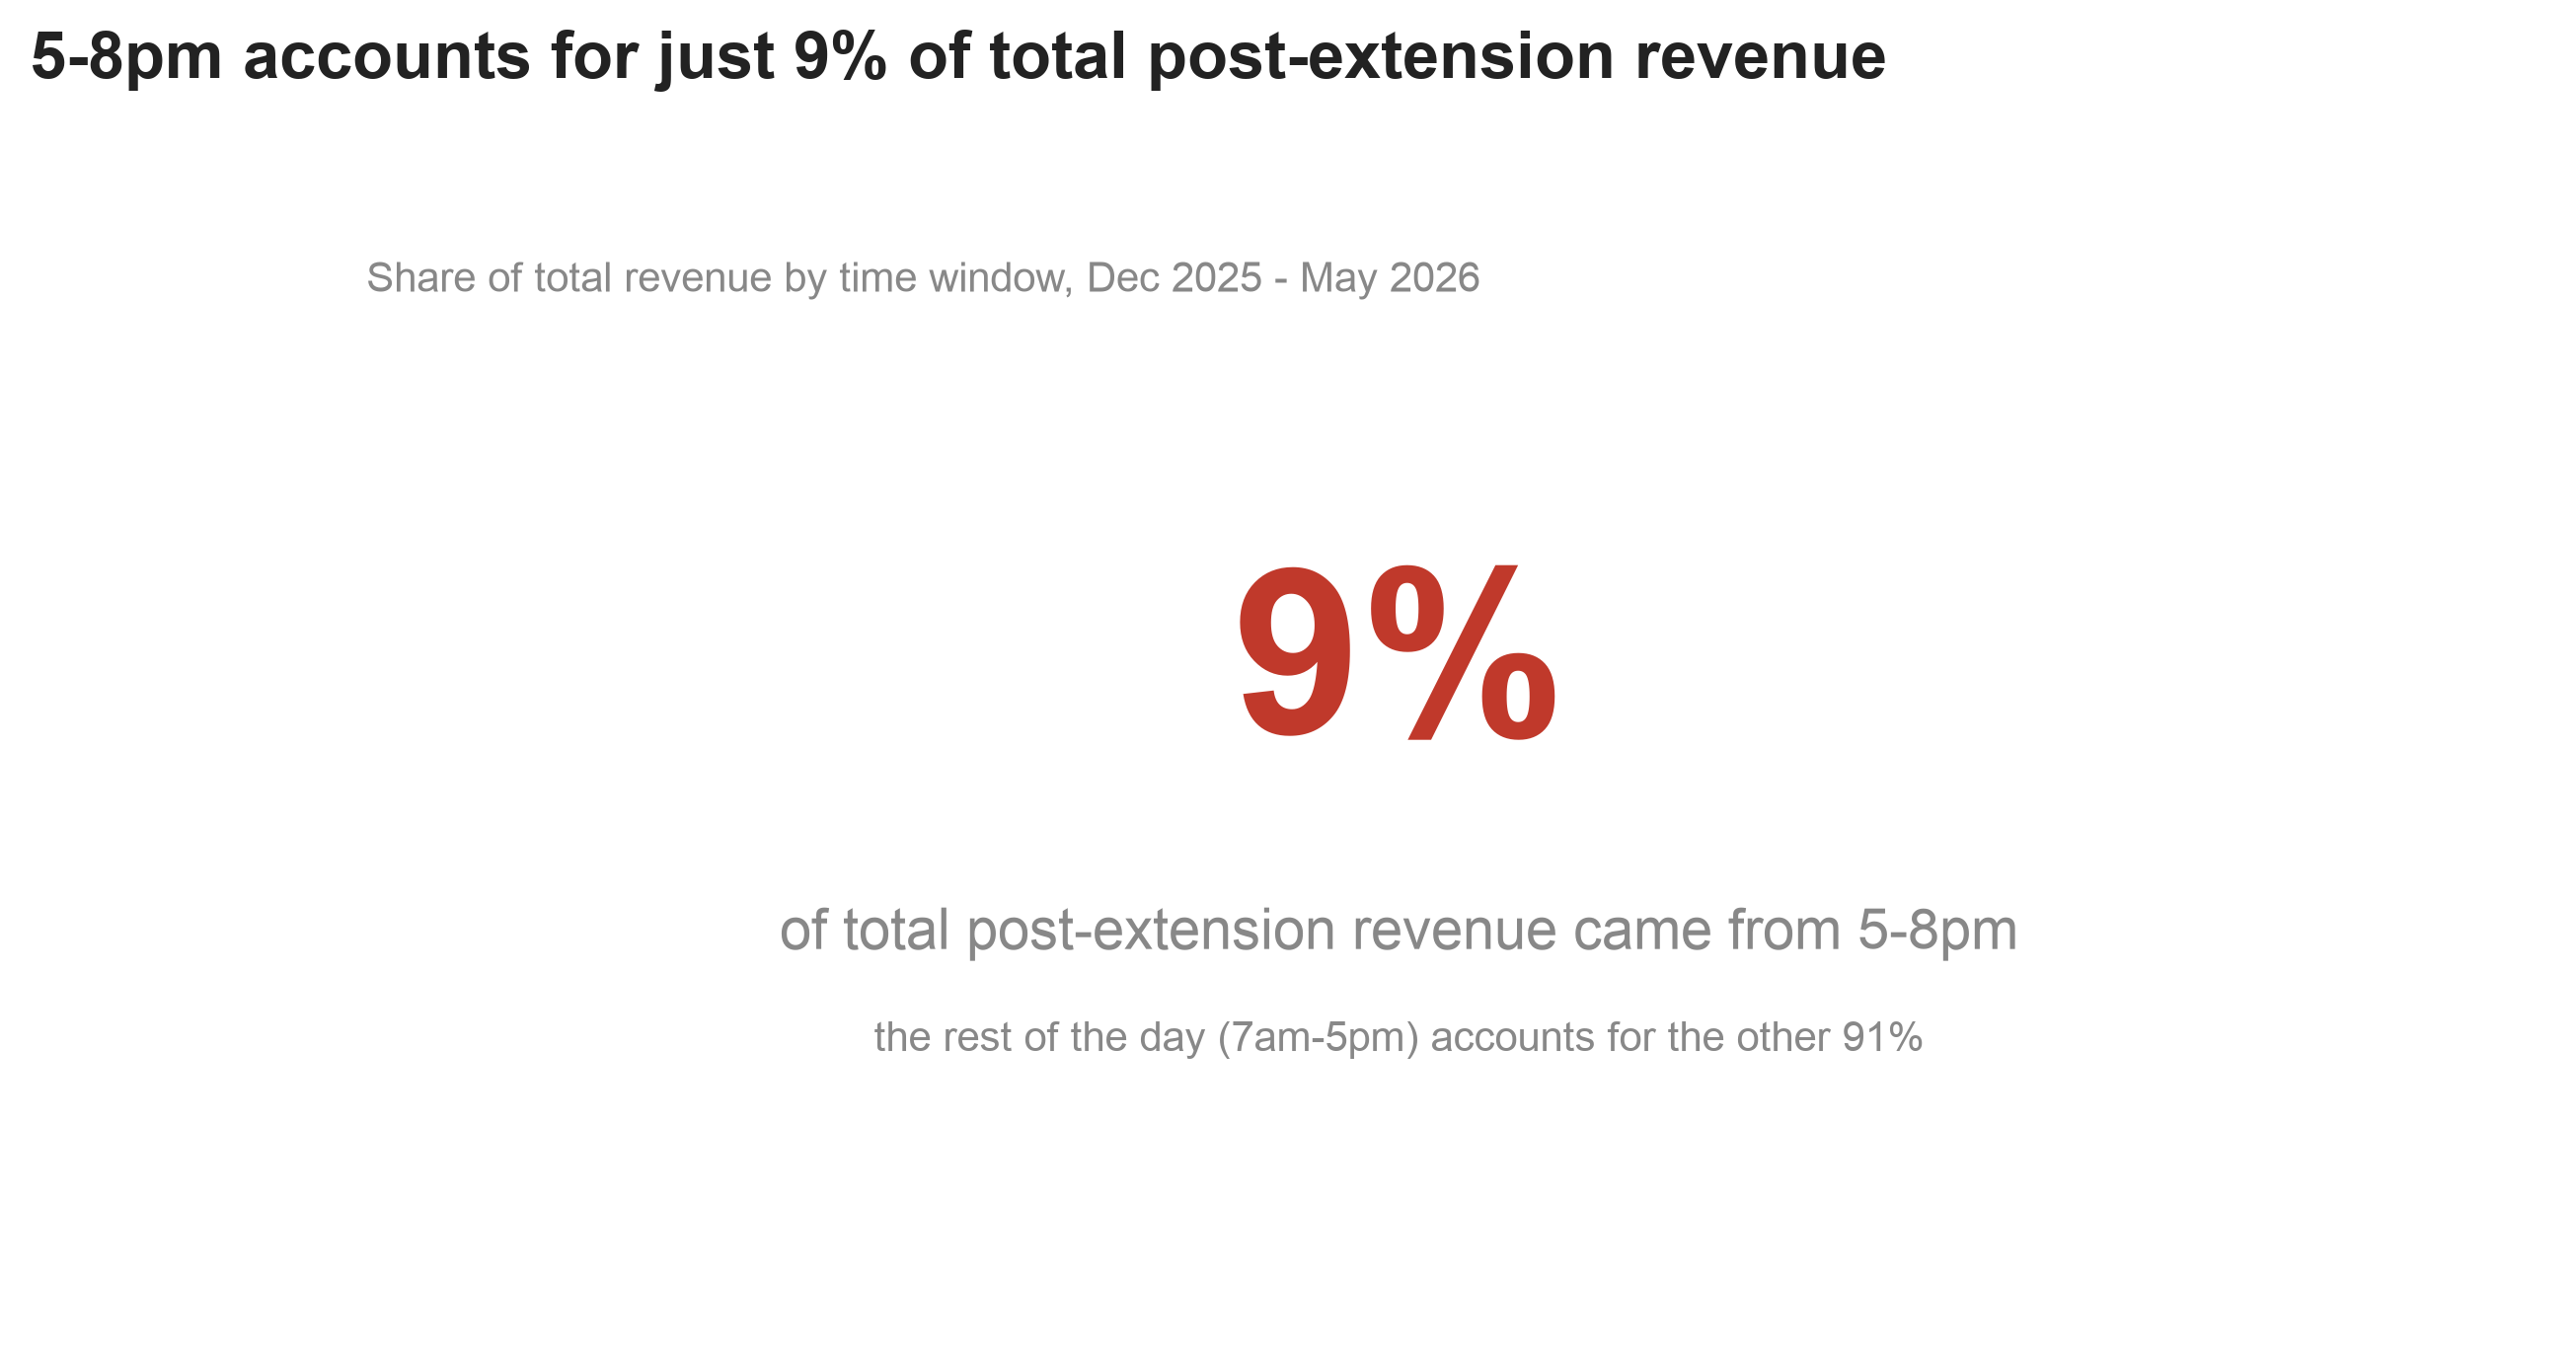

In [23]:
# CHART 2c — 5-8pm share of total post-extension revenue, big-number diagram

post_hour = post['order_date'].dt.hour
evening_rev = post.loc[post_hour.isin([17, 18, 19]), 'revenue'].sum()
total_post_rev = post['revenue'].sum()
evening_share = evening_rev / total_post_rev * 100
rest_share = 100 - evening_share

fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

ax.text(0.5, 0.66, f'{evening_share:.0f}%', fontsize=56, fontweight='bold', color=RED, ha='center', va='top')
ax.text(0.5, 0.36, 'of total post-extension revenue came from 5-8pm', fontsize=14, color=MUTED, ha='center', va='top')
ax.text(0.5, 0.26, f'the rest of the day (7am-5pm) accounts for the other {rest_share:.0f}%',
        fontsize=10, color=MUTED, ha='center', va='top')

fig.suptitle(f'5-8pm accounts for just {evening_share:.0f}% of total post-extension revenue', x=0.05, ha='left', y=0.98,
             fontsize=16, fontweight='bold', color=INK)
ax.text(0.05, 0.9, 'Share of total revenue by time window, Dec 2025 - May 2026', fontsize=10, color=MUTED)

save_chart(fig)
plt.show()


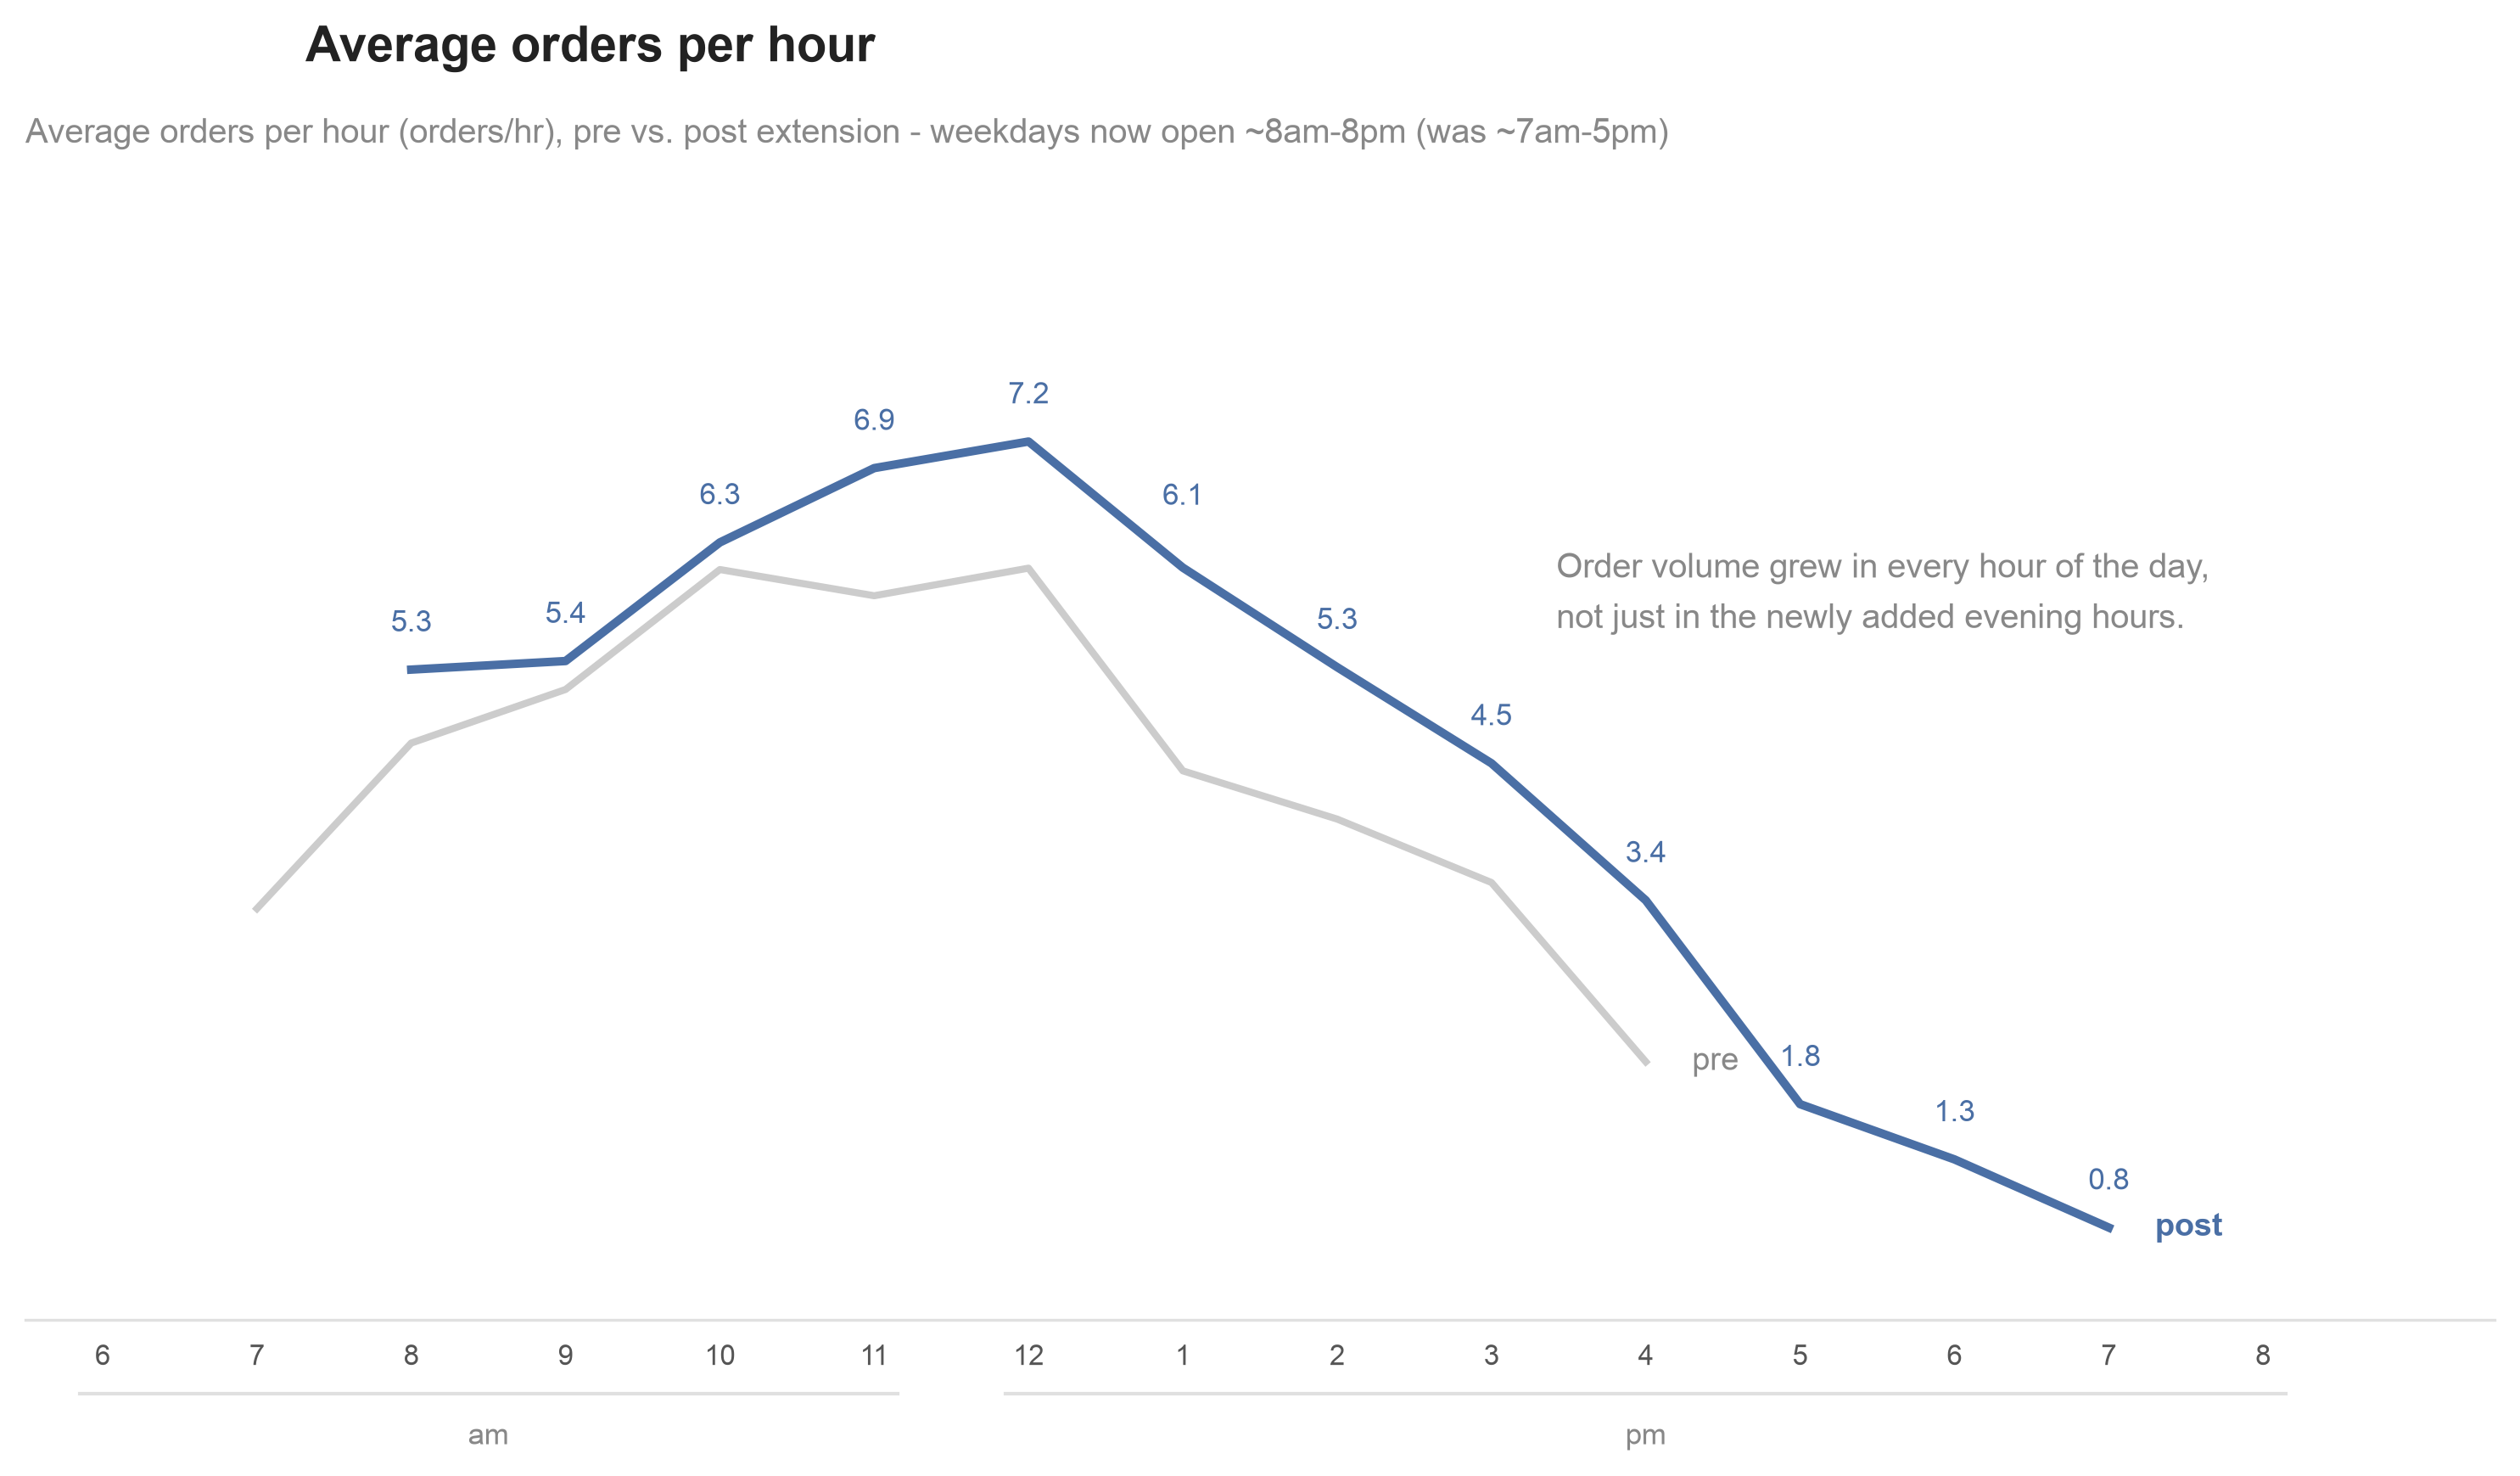

In [24]:
# CHART 3 — Average orders per hour, pre vs post extension

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(hours, hourly_txn_count_mean_pre.values, color=GREY_LINE, lw=2, zorder=2)
ax.plot(hours, hourly_txn_count_mean_post.values, color=BLUE, lw=2.4, zorder=3)

pre_valid = hourly_txn_count_mean_pre.dropna()
post_valid = hourly_txn_count_mean_post.dropna()
ax.text(pre_valid.index[-1] + 0.3, pre_valid.iloc[-1], 'pre', va='center', ha='left', fontsize=9, color=MUTED)
ax.text(post_valid.index[-1] + 0.3, post_valid.iloc[-1], 'post', va='center', ha='left', fontsize=9, color=BLUE, fontweight='bold')

txn_peak_hour = hourly_txn_count_mean_post.idxmax()

# Every post-line hour labeled, including the peak, all in the same style
# -- same style/positioning as the revenue chart
for h, v in post_valid.items():
    gap = 16 if h == txn_peak_hour + 1 else 9
    ax.annotate(f'{v:.1f}', xy=(h, v), textcoords='offset points', xytext=(0, gap),
                ha='center', va='bottom', fontsize=8.5, color=BLUE)

note = 'Order volume grew in every hour of the day,\nnot just in the newly added evening hours.'
ax.text(0.62, 0.68, note, transform=ax.transAxes, ha='left', va='top', fontsize=9.5, color=MUTED, linespacing=1.6)

fig.suptitle('Average orders per hour', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average orders per hour (orders/hr), pre vs. post extension - weekdays now open ~8am-8pm (was ~7am-5pm)',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, hourly_txn_count_mean_post.max() * 1.3)
ax.set_xlim(hours[0] - 0.5, hours[-1] + 1.5)
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours[0], 11), ('pm', 12, hours[-1])])
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', labelleft=False, left=False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()


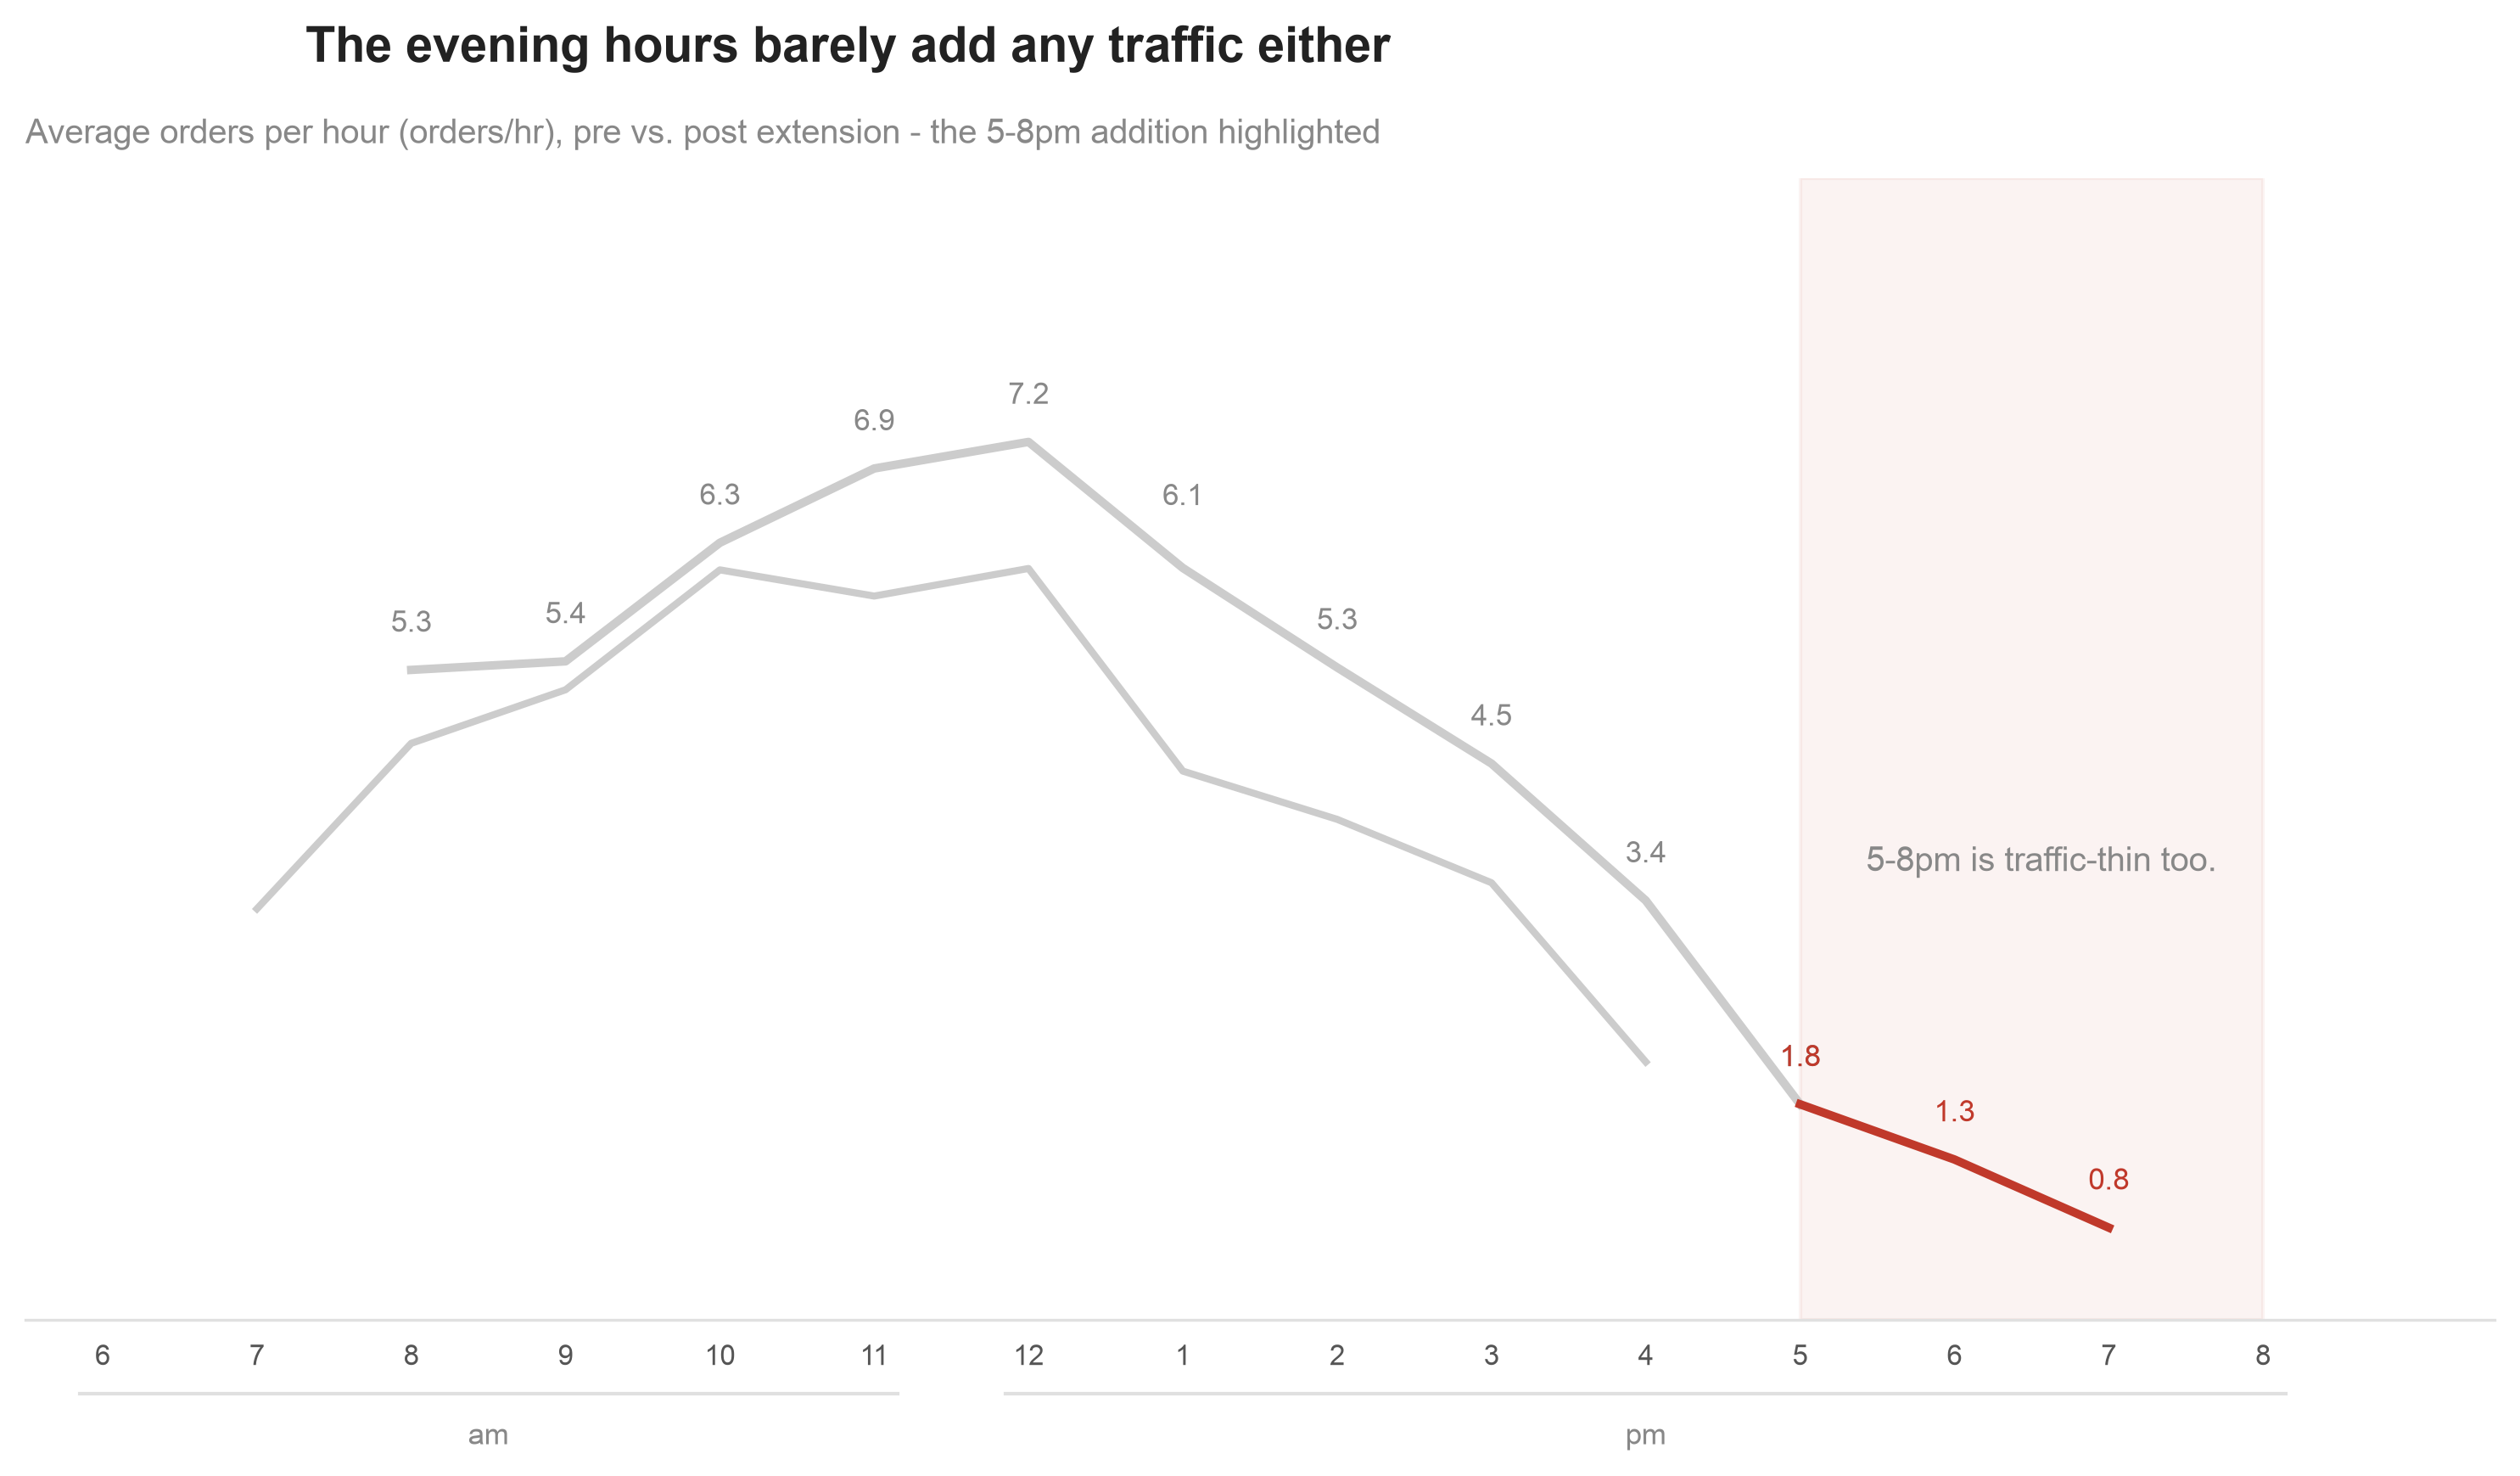

In [25]:
# CHART 3b — Average orders per hour, pre vs post, with the 5-8pm extension emphasized

fig, ax = plt.subplots(figsize=(10, 6))

txn_core_hours = [h for h in hours if h <= 17]
txn_tail_hours = [h for h in hours if h >= 17]

ax.plot(hours, hourly_txn_count_mean_pre.values, color=GREY_LINE, lw=2, zorder=2)
ax.plot(txn_core_hours, hourly_txn_count_mean_post.loc[txn_core_hours].values, color=GREY_LINE, lw=2.4, zorder=2)
ax.plot(txn_tail_hours, hourly_txn_count_mean_post.loc[txn_tail_hours].values, color=RED, lw=2.4, zorder=3)

ax.axvspan(17, 20, color=RED, alpha=0.06, zorder=1)

# Label the full post-extension line in grey (including the peak, same
# style as every other hour) so the red 5-8pm labels read as emphasis
# against the full picture rather than the only numbers on the chart.
for h, v in hourly_txn_count_mean_post.loc[txn_core_hours].dropna().items():
    gap = 16 if h == txn_peak_hour + 1 else 9
    ax.annotate(f'{v:.1f}', xy=(h, v), textcoords='offset points', xytext=(0, gap),
                ha='center', va='bottom', fontsize=8.5, color=MUTED)

# Call out how thin the new evening hours actually are
for h in [17, 18, 19]:
    v = hourly_txn_count_mean_post[h]
    ax.annotate(f'{v:.1f}', xy=(h, v), textcoords='offset points', xytext=(0, 9),
                ha='center', va='bottom', fontsize=8.5, color=RED)

note = "5-8pm is traffic-thin too."
ax.text(19.7, hourly_txn_count_mean_post.max() * 0.55, note, ha='right', va='top', fontsize=9.5, color=MUTED, linespacing=1.6)

fig.suptitle('The evening hours barely add any traffic either', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average orders per hour (orders/hr), pre vs. post extension - the 5-8pm addition highlighted',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, hourly_txn_count_mean_post.max() * 1.3)
ax.set_xlim(hours[0] - 0.5, hours[-1] + 1.5)
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours[0], 11), ('pm', 12, hours[-1])])
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', labelleft=False, left=False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout(rect=[0, 0.02, 1, 1])
save_chart(fig)
plt.show()


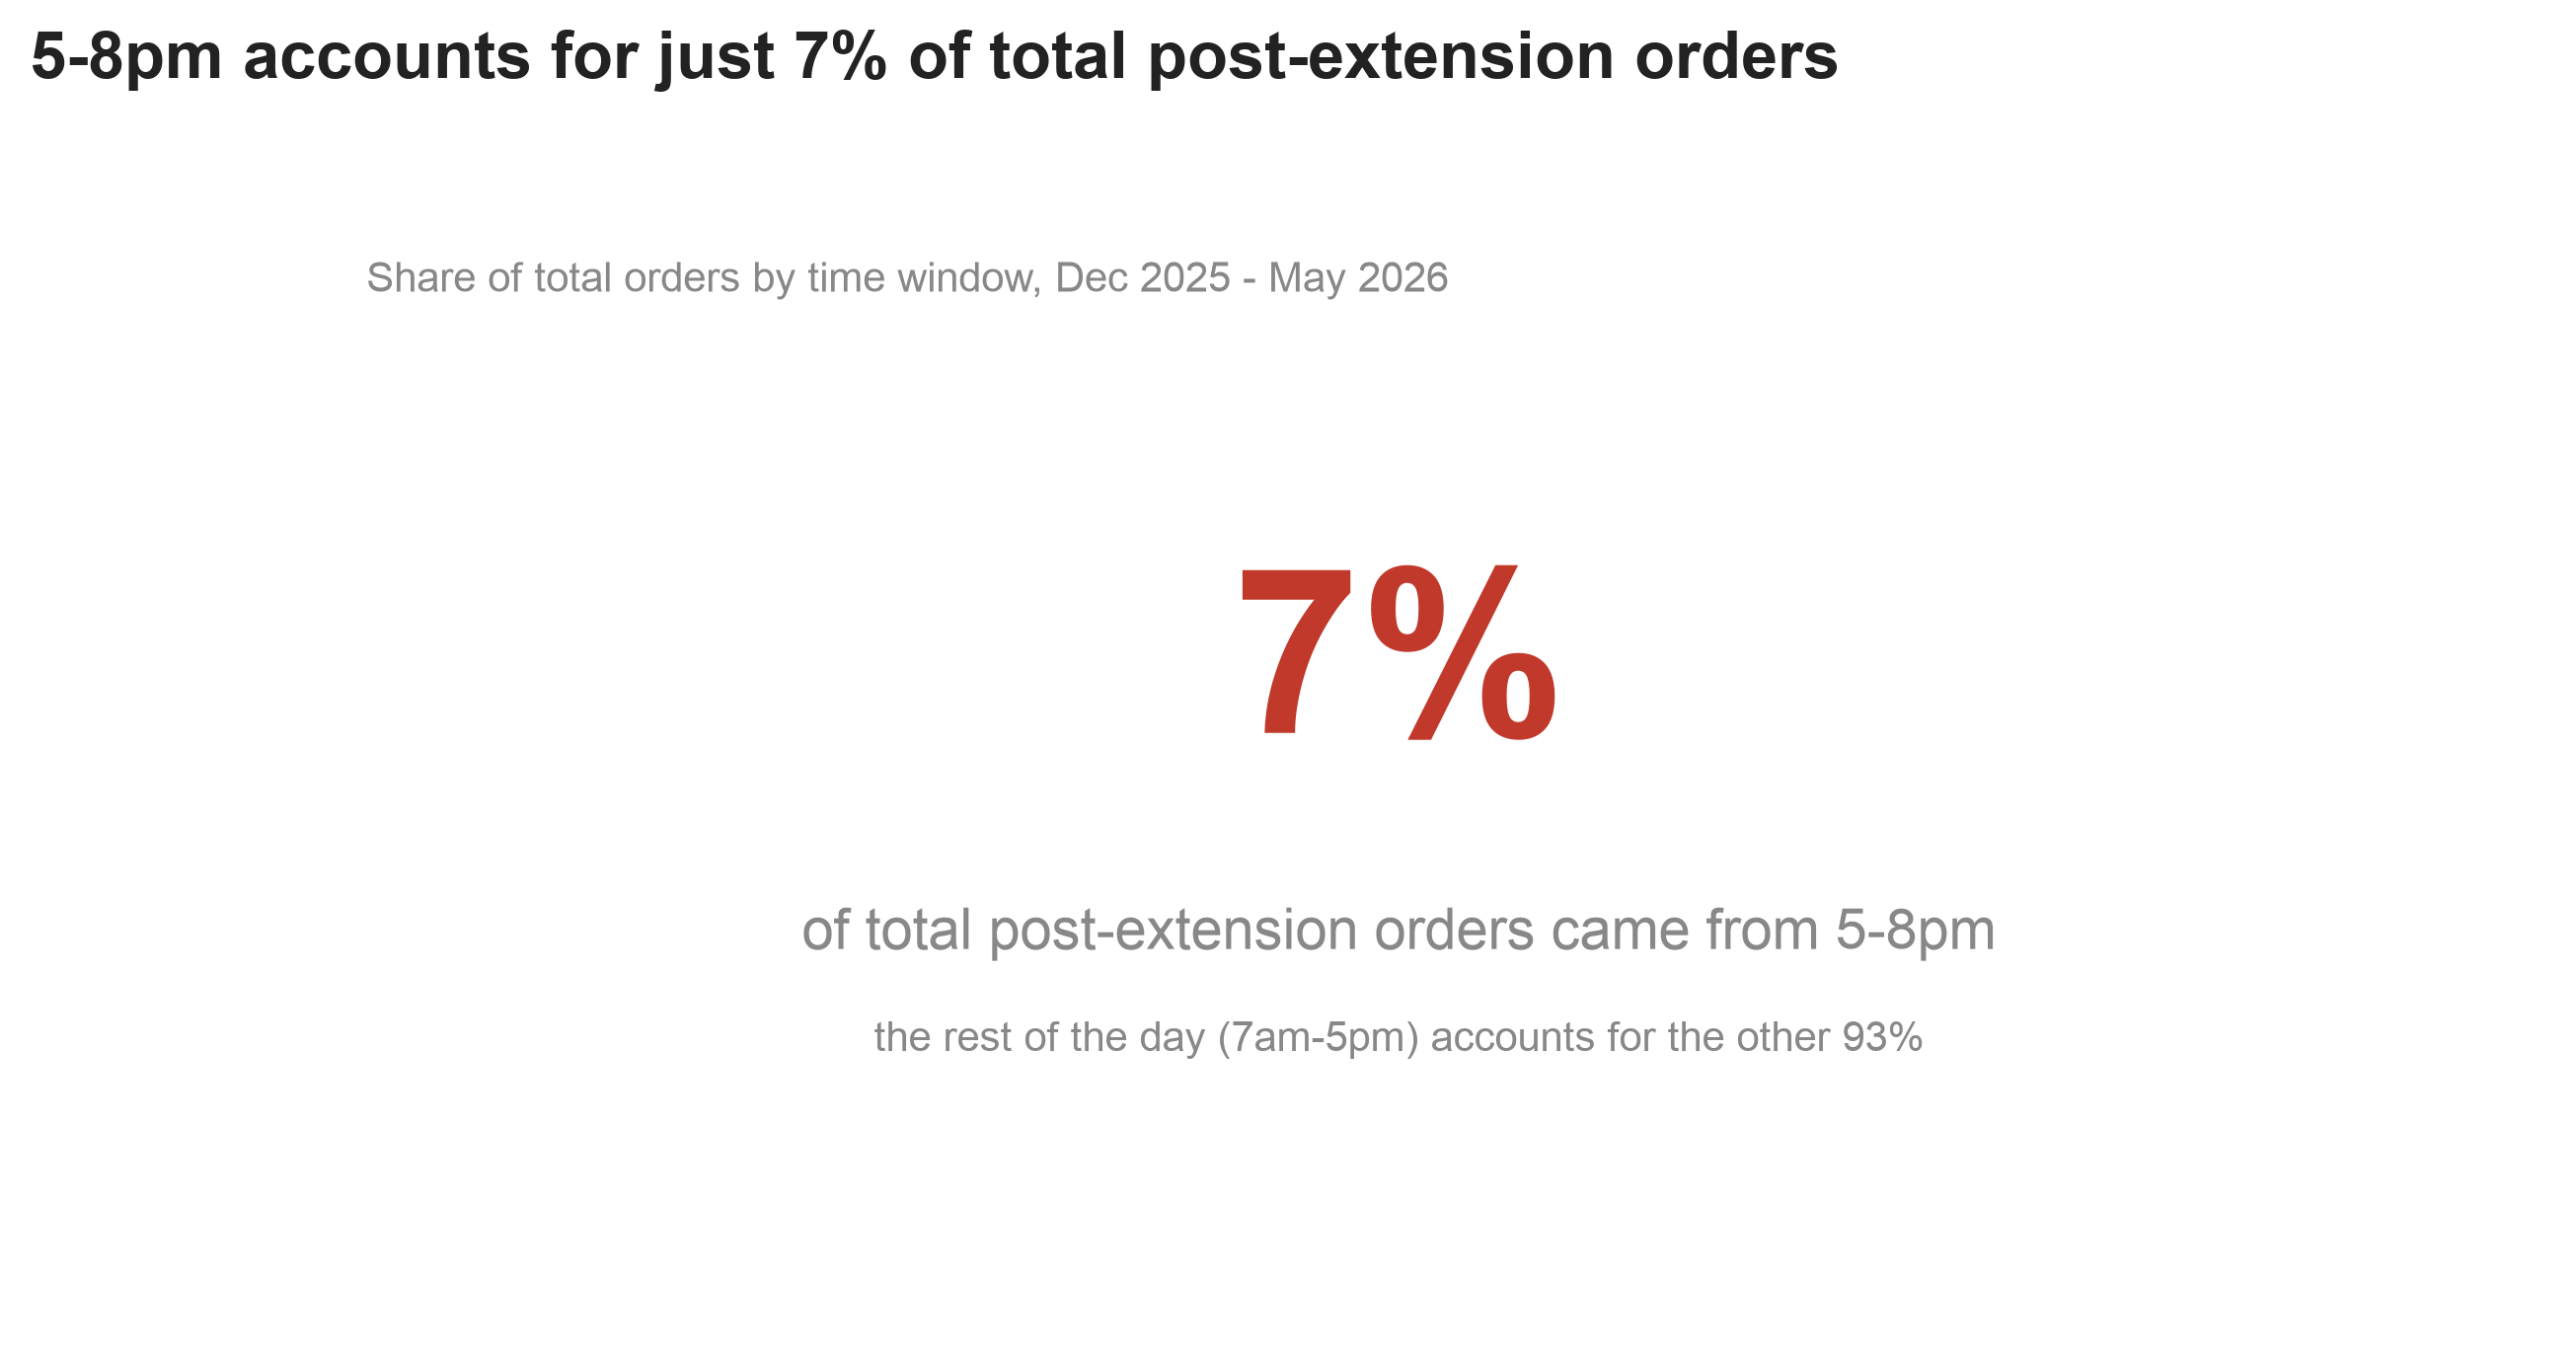

In [26]:
# CHART 3c — 5-8pm share of total post-extension orders, big-number diagram

evening_order_count = len(post.loc[post_hour.isin([17, 18, 19])])
total_post_orders = len(post)
evening_order_share = evening_order_count / total_post_orders * 100
rest_order_share = 100 - evening_order_share

fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

ax.text(0.5, 0.66, f'{evening_order_share:.0f}%', fontsize=56, fontweight='bold', color=RED, ha='center', va='top')
ax.text(0.5, 0.36, 'of total post-extension orders came from 5-8pm', fontsize=14, color=MUTED, ha='center', va='top')
ax.text(0.5, 0.26, f'the rest of the day (7am-5pm) accounts for the other {rest_order_share:.0f}%',
        fontsize=10, color=MUTED, ha='center', va='top')

fig.suptitle(f'5-8pm accounts for just {evening_order_share:.0f}% of total post-extension orders', x=0.05, ha='left', y=0.98,
             fontsize=16, fontweight='bold', color=INK)
ax.text(0.05, 0.9, 'Share of total orders by time window, Dec 2025 - May 2026', fontsize=10, color=MUTED)

save_chart(fig)
plt.show()


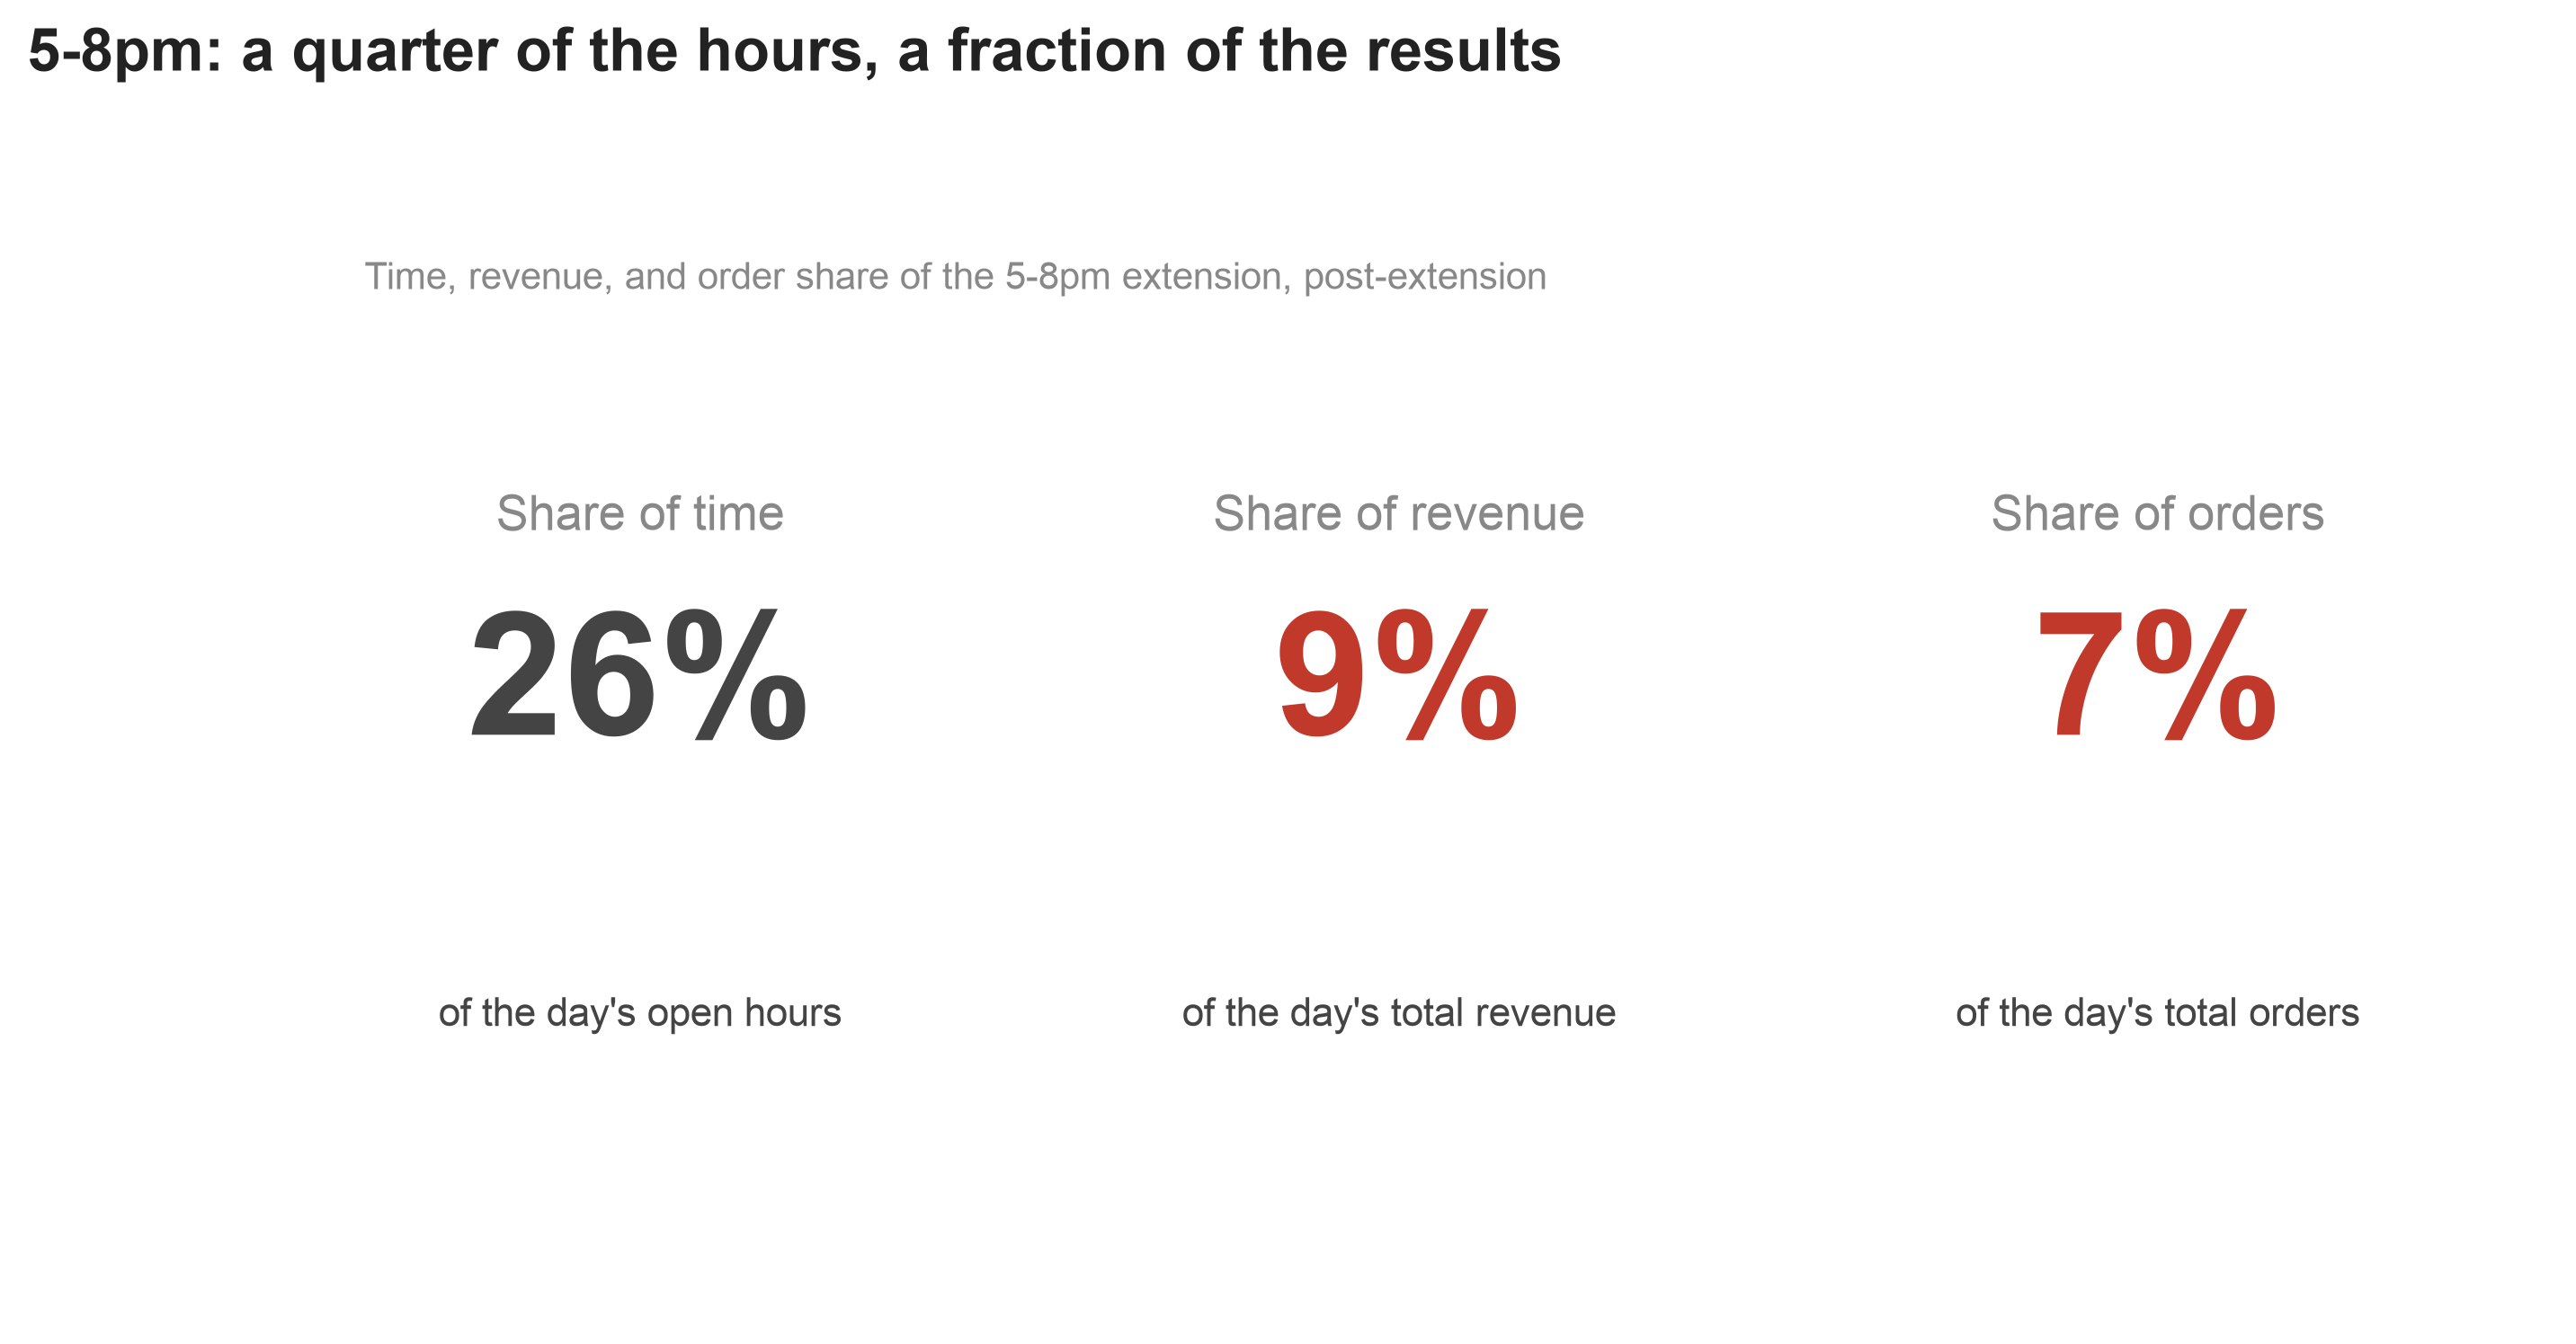

In [27]:
# CHART — Time, revenue, and order share of the 5-8pm extension: quick summary card

evening_hour_slots = hourly_daily_revenue_post[[17, 18, 19]].notna().sum().sum()
total_open_hour_slots = hourly_daily_revenue_post.notna().sum().sum()
time_share = evening_hour_slots / total_open_hour_slots * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axis('off')

cards = [
    (0.17, 'Share of time', f'{time_share:.0f}%', "of the day's open hours", INK_SOFT),
    (0.5, 'Share of revenue', f'{evening_share:.0f}%', "of the day's total revenue", RED),
    (0.83, 'Share of orders', f'{evening_order_share:.0f}%', "of the day's total orders", RED),
]

for x, label, big, sub, color in cards:
    ax.text(x, 0.68, label, fontsize=13, color=MUTED, ha='center', va='bottom')
    ax.text(x, 0.62, big, fontsize=46, fontweight='bold', color=color, ha='center', va='top')
    ax.text(x, 0.28, sub, fontsize=10.5, color=INK_SOFT, ha='center', va='top')

fig.suptitle('5-8pm: a quarter of the hours, a fraction of the results', x=0.05, ha='left', y=0.98,
             fontsize=16, fontweight='bold', color=INK)
ax.text(0.05, 0.9, 'Time, revenue, and order share of the 5-8pm extension, post-extension', fontsize=10, color=MUTED)

save_chart(fig)
plt.show()


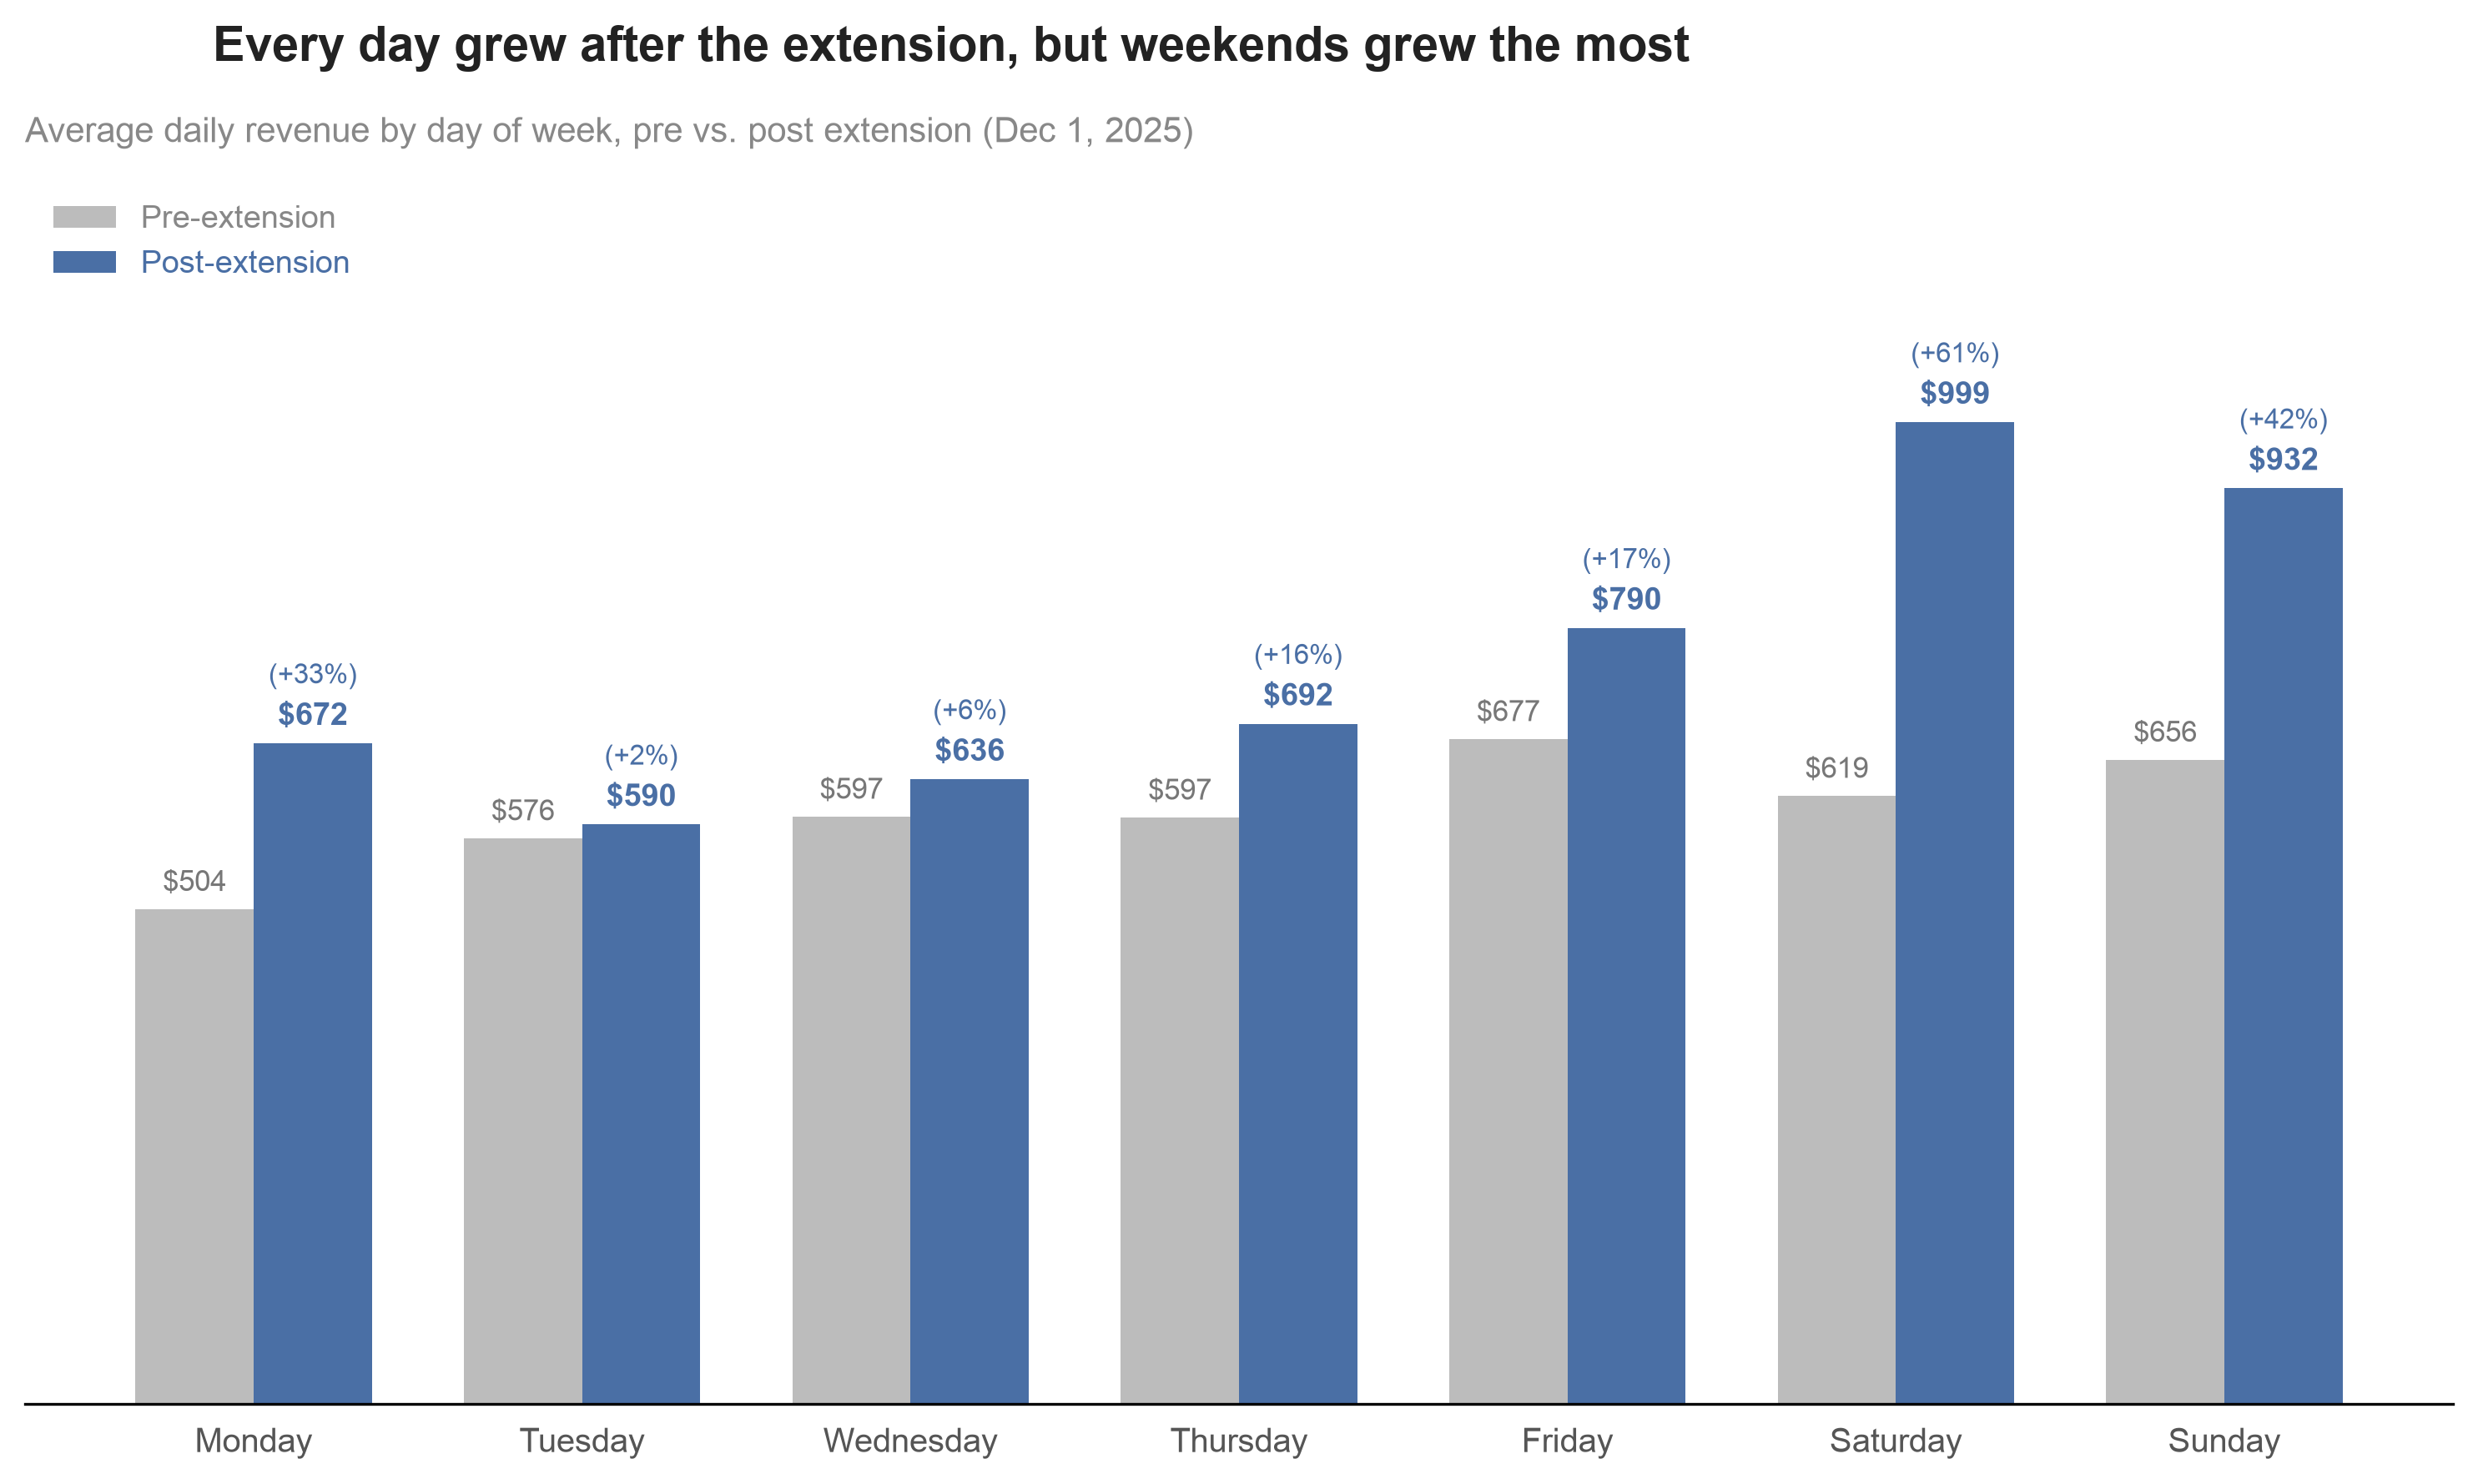

In [28]:
# CHART — Average daily revenue by day of week, pre vs. post extension

x = np.arange(len(days))
width = 0.36
pre_vals = day_of_week_revenue_mean_pre.reindex(days).values
post_vals = day_of_week_revenue_mean_post.reindex(days).values

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, pre_vals, width, color=GREY_BAR, label='Pre-extension', zorder=2)
ax.bar(x + width/2, post_vals, width, color=BLUE, label='Post-extension', zorder=2)
ax.set_ylim(0, max(pre_vals.max(), post_vals.max()) * 1.25)

for xi, (pv, qv) in enumerate(zip(pre_vals, post_vals)):
    ax.text(xi - width/2, pv + 12, f'${pv:,.0f}', ha='center', va='bottom', fontsize=8.5, color='#777777')
    pct = (qv/pv - 1) * 100
    ax.text(xi + width/2, qv + 12, f'${qv:,.0f}', ha='center', va='bottom', fontsize=9, color=BLUE, fontweight='bold')
    ax.text(xi + width/2, qv + 55, f'({pct:+.0f}%)', ha='center', va='bottom', fontsize=8, color=BLUE)

ax.set_xticks(x)
ax.set_xticklabels(days, fontsize=9.5, color=TICK)

fig.suptitle('Every day grew after the extension, but weekends grew the most', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average daily revenue by day of week, pre vs. post extension (Dec 1, 2025)',
              loc='left', fontsize=10, color=MUTED, pad=10)

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.legend(loc='upper left', frameon=False, fontsize=9, labelcolor=[MUTED, BLUE])

plt.tight_layout()
save_chart(fig)
plt.show()

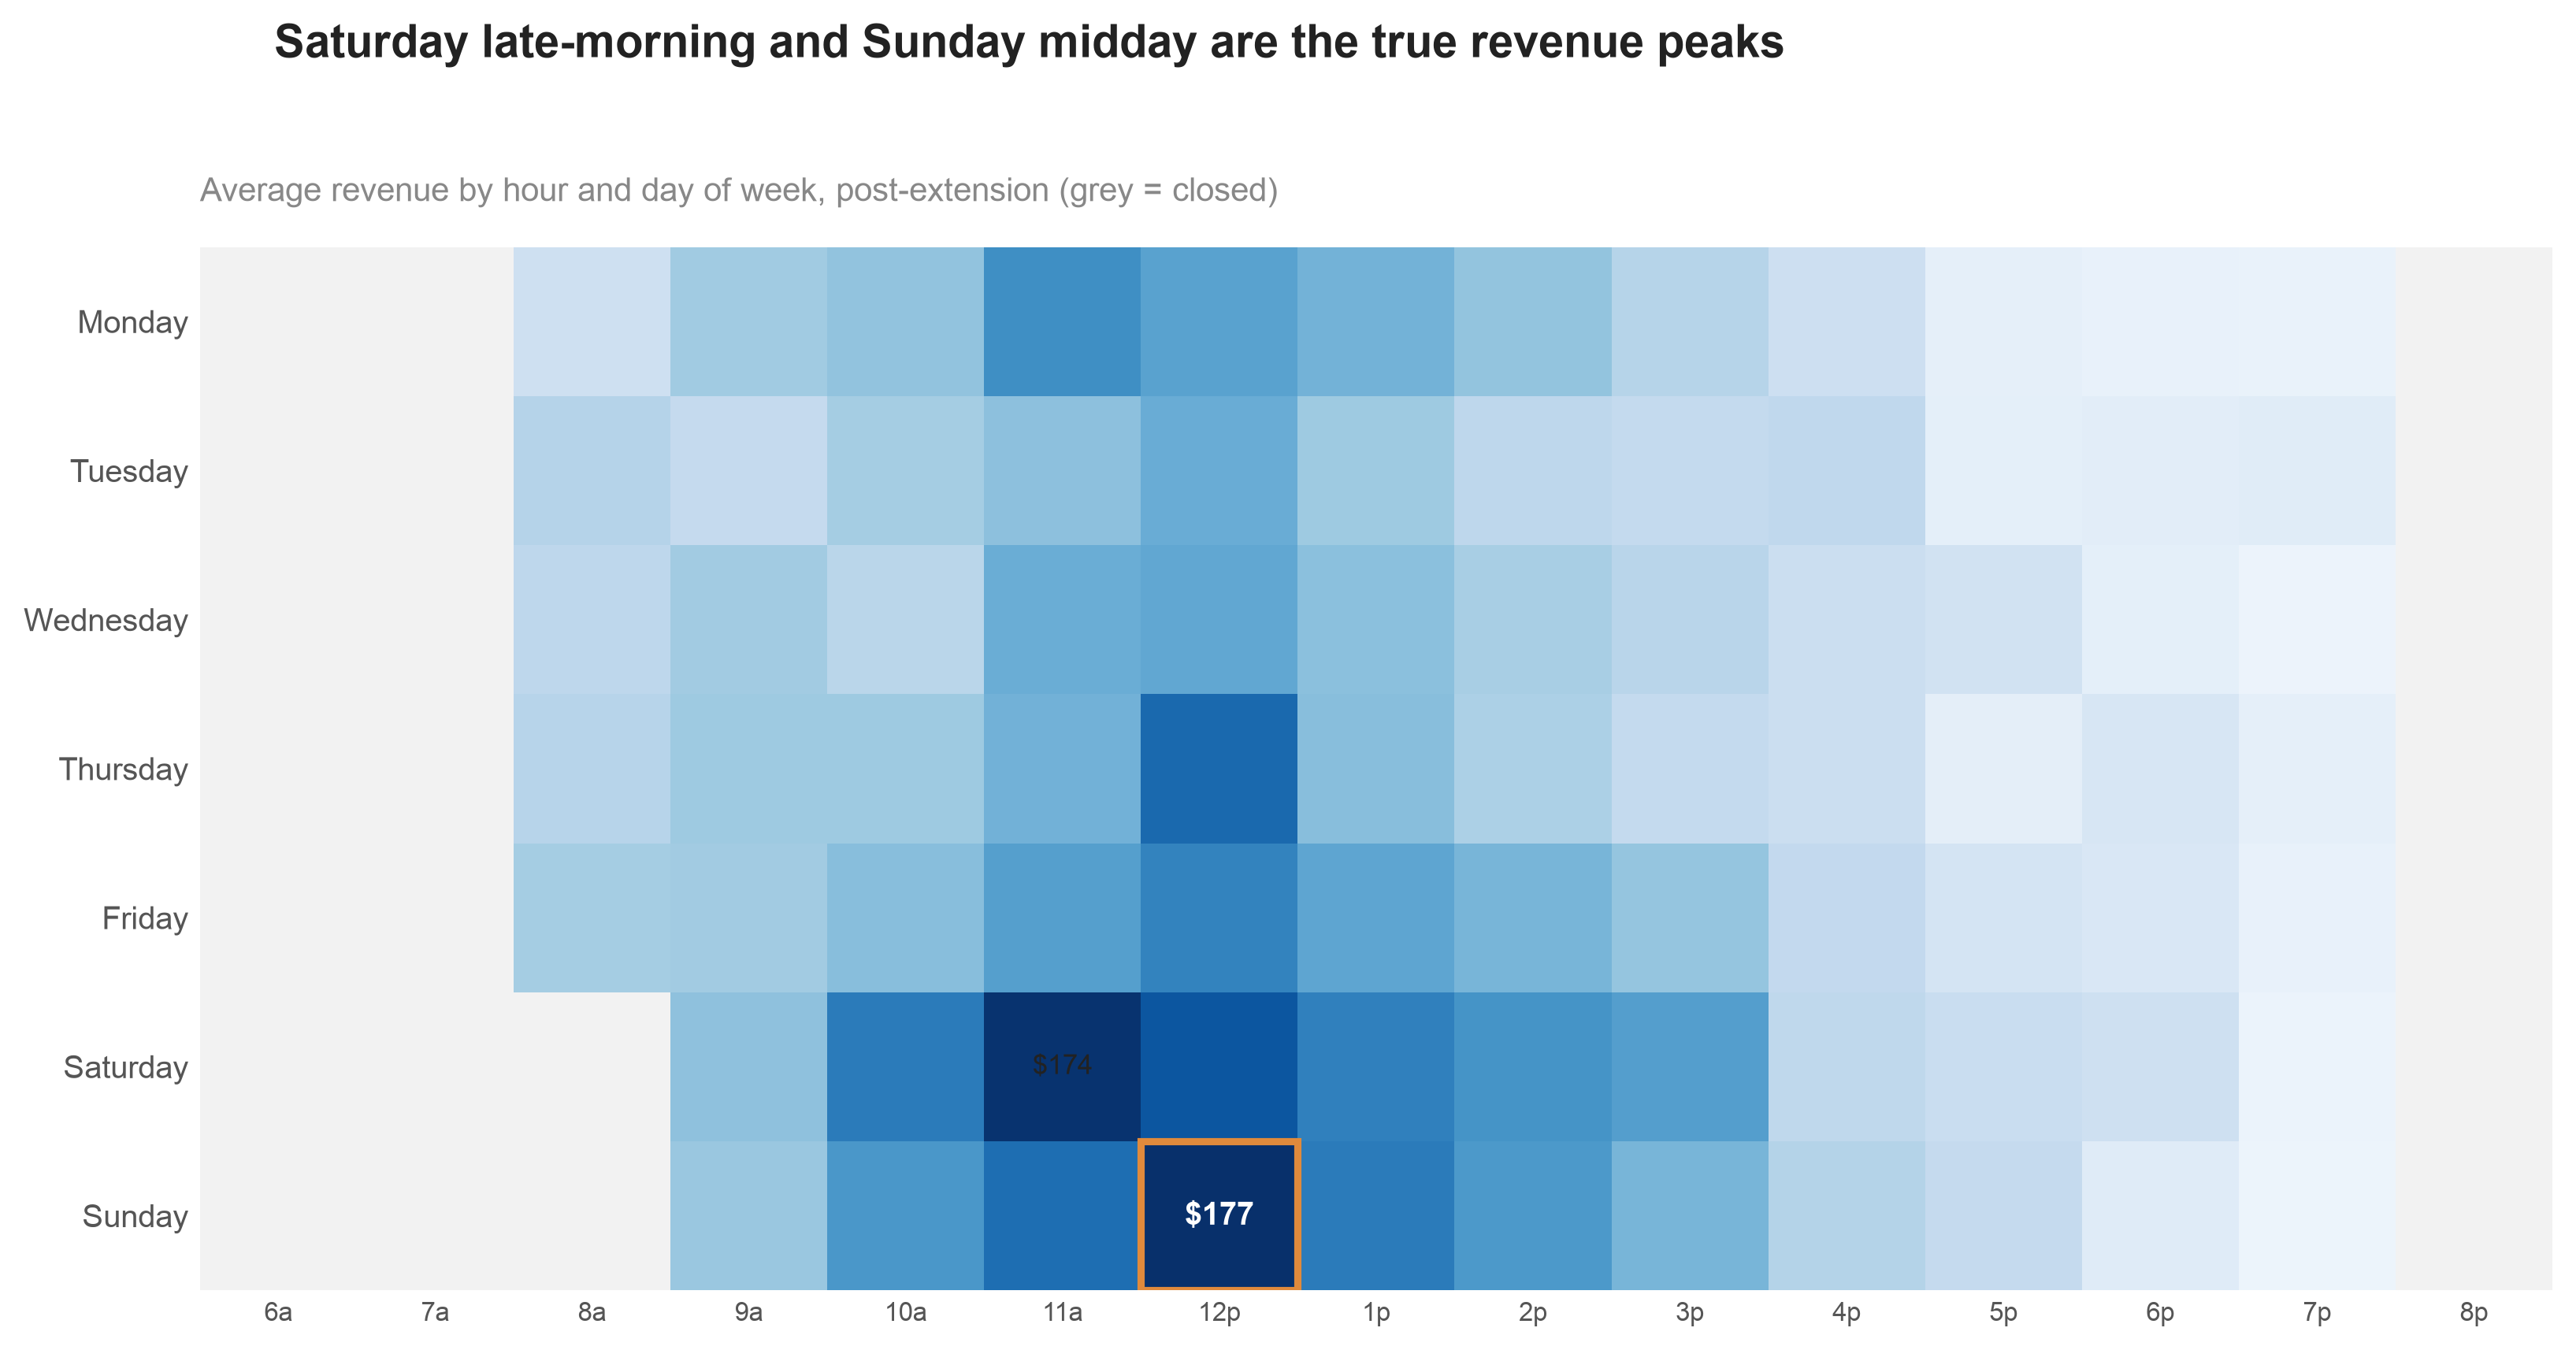

In [29]:
# CHART 5 — Hour x day-of-week heatmap, post-extension (Act 2 cont: the true peak)

matrix = hourly_dow_revenue_post.loc[days]
hour_cols = list(matrix.columns)
hour_labels2 = [f'{h if h <= 12 else h - 12}{"a" if h < 12 else "p"}' for h in hour_cols]

fig, ax = plt.subplots(figsize=(11, 5.5))
cmap = plt.cm.Blues.copy()
cmap.set_bad('#f2f2f2')
im = ax.imshow(matrix.values, aspect='auto', cmap=cmap, vmin=0)

ax.set_xticks(range(len(hour_cols)))
ax.set_xticklabels(hour_labels2, fontsize=8, color=TICK)
ax.set_yticks(range(len(days)))
ax.set_yticklabels(days, fontsize=9.5, color=TICK)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)

# NaN-safe peak finding -- push NaN cells to the end instead of letting
# argsort treat them as "largest" once reversed to descending order.
flat = matrix.values.flatten()
order_idx = np.argsort(np.where(np.isnan(flat), -np.inf, flat))[::-1]

r, c = divmod(order_idx[0], matrix.shape[1])
ax.text(c, r, f'${matrix.values[r, c]:,.0f}', ha='center', va='center', fontsize=9.5, color='white', fontweight='bold')
ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor=ORANGE, lw=2.2))

r2, c2 = divmod(order_idx[1], matrix.shape[1])
ax.text(c2, r2, f'${matrix.values[r2, c2]:,.0f}', ha='center', va='center', fontsize=8.5, color=INK)

fig.suptitle('Saturday late-morning and Sunday midday are the true revenue peaks', x=0.11, ha='left', y=1.03,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour and day of week, post-extension (grey = closed)', loc='left', fontsize=10, color=MUTED, pad=14)

plt.tight_layout()
save_chart(fig)
plt.show()

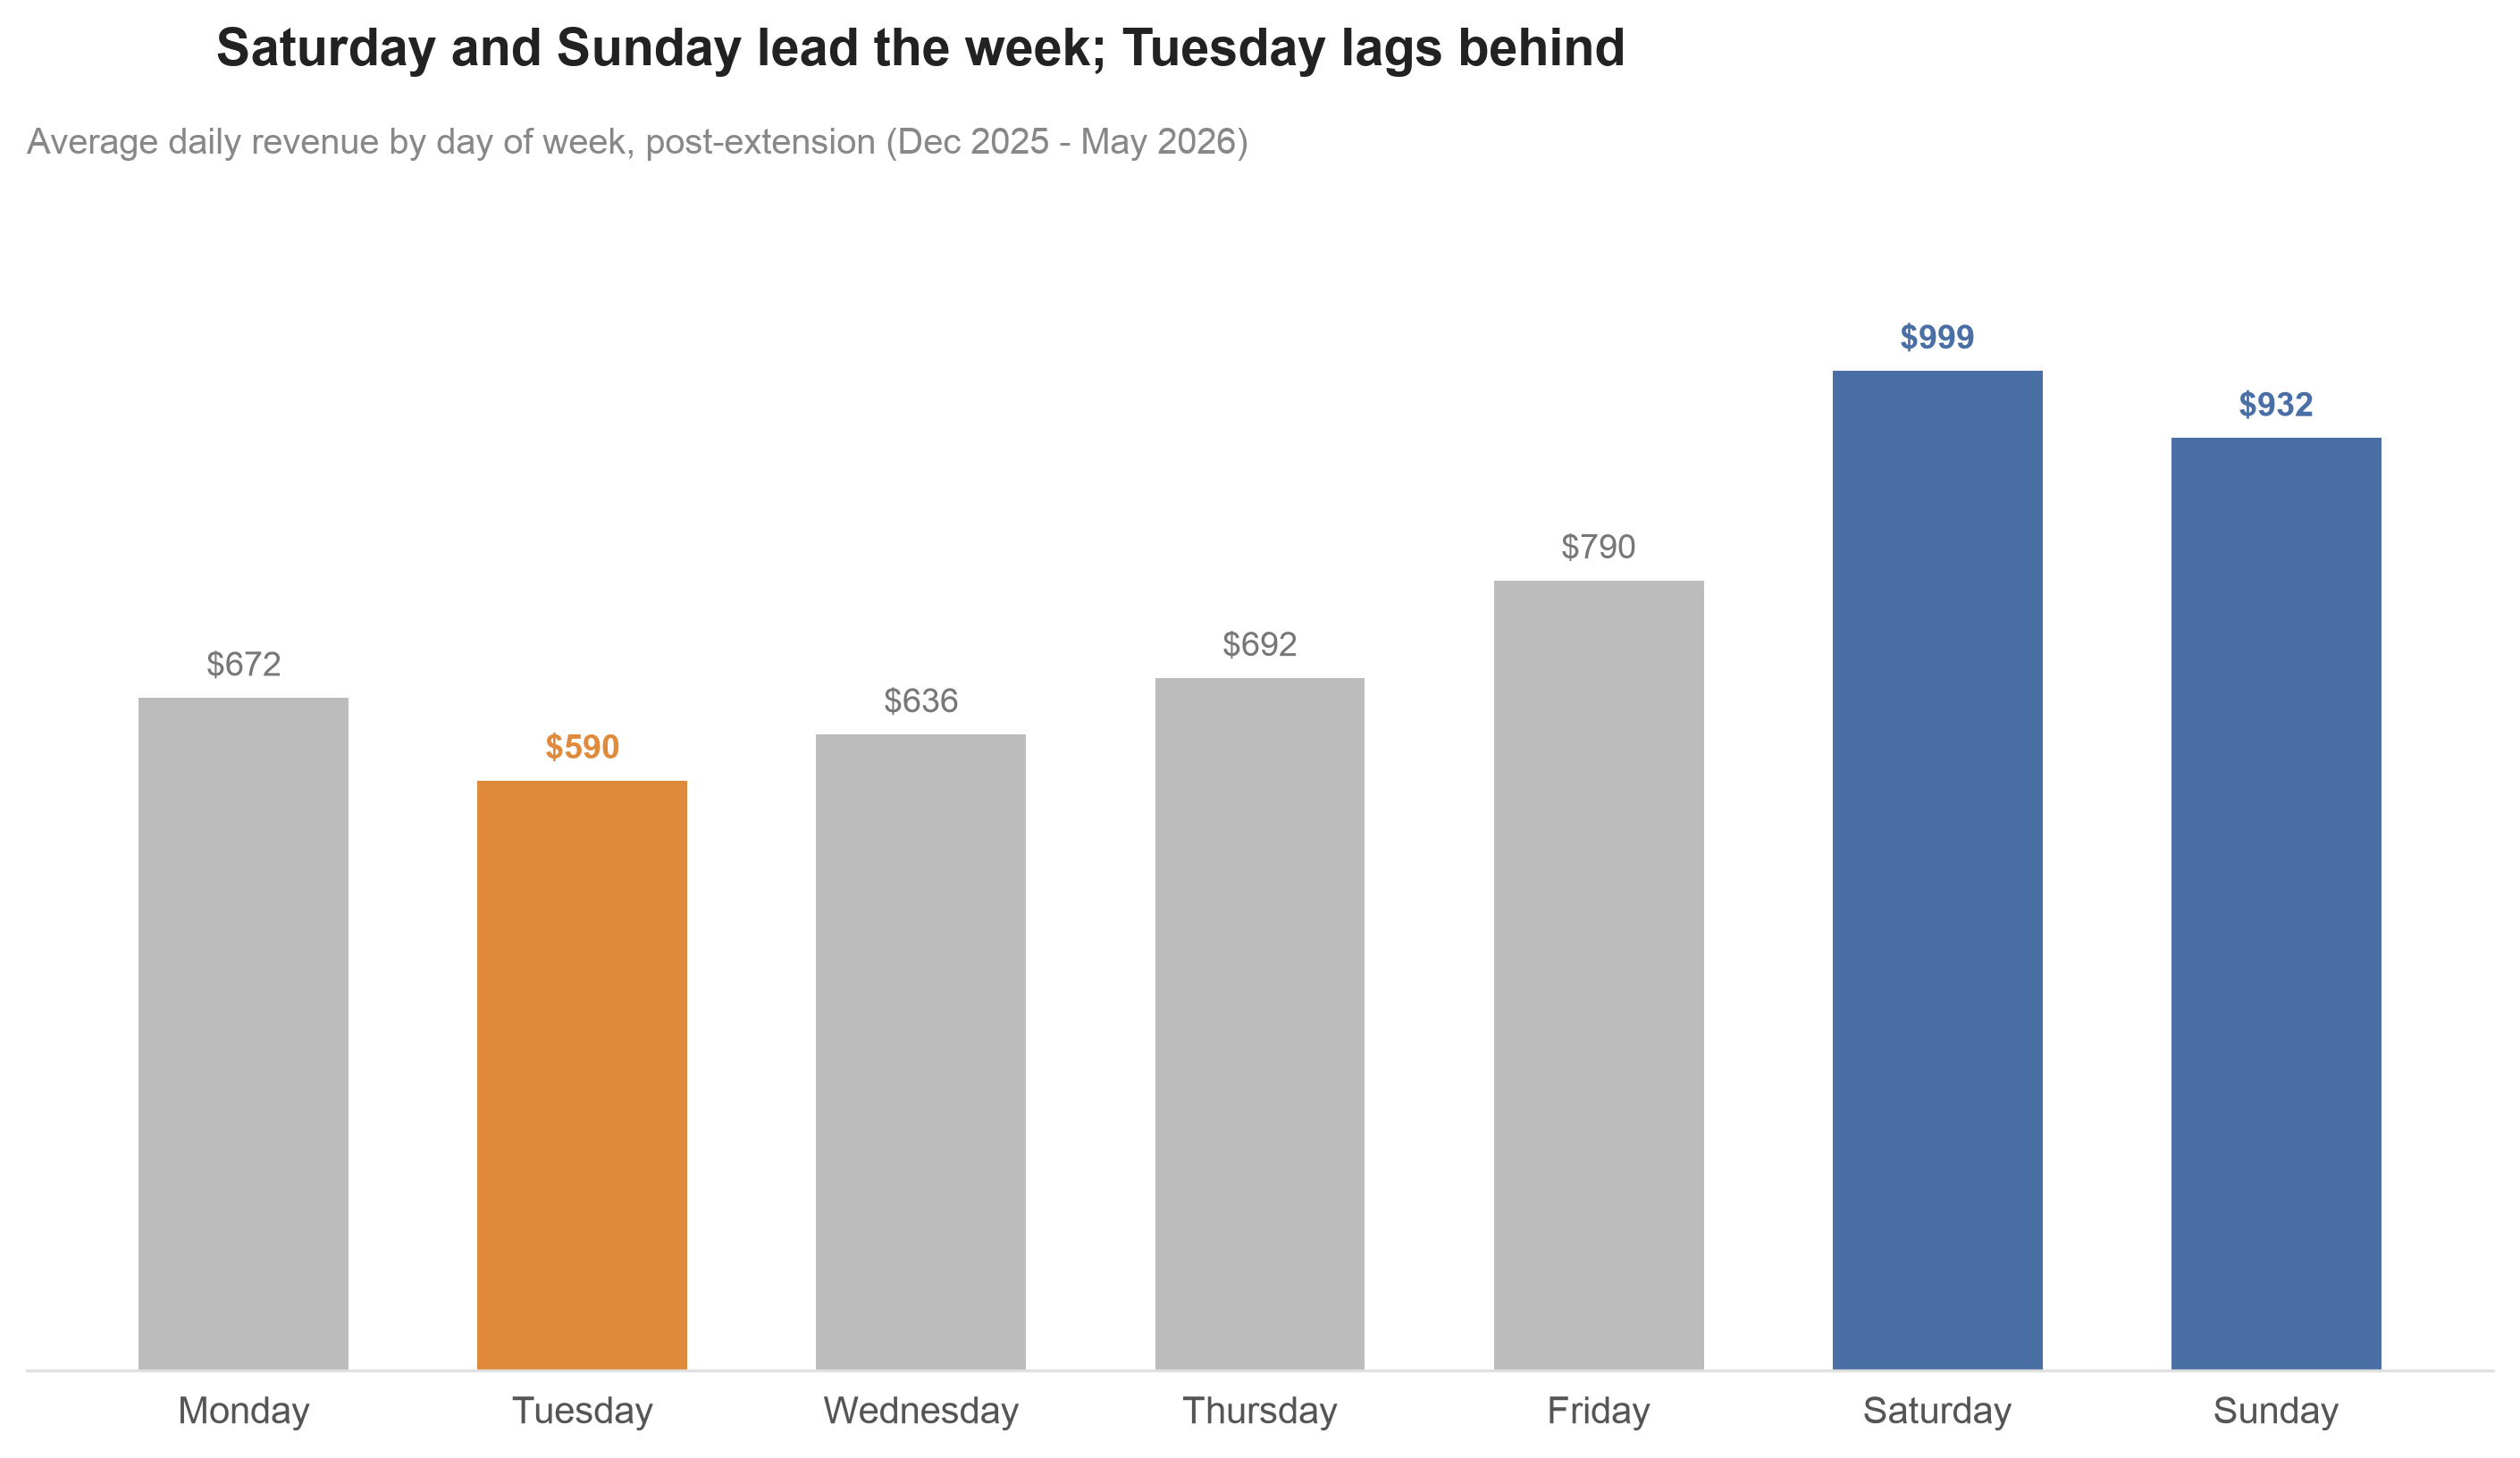

In [30]:
# CHART — Day-of-week revenue (post-extension), best and worst days highlighted

s = day_of_week_revenue_mean_post.reindex(days)
HIGH_DAYS = {'Saturday', 'Sunday'}
LOW_DAYS = {'Tuesday'}


def bar_color(d):
    if d in HIGH_DAYS:
        return BLUE
    if d in LOW_DAYS:
        return ORANGE
    return GREY_BAR


colors = [bar_color(d) for d in s.index]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.bar(s.index, s.values, color=colors, width=0.62, zorder=2)
ax.set_ylim(0, s.max() * 1.18)

for d, v in s.items():
    if d in HIGH_DAYS:
        label_color, weight = BLUE, 'bold'
    elif d in LOW_DAYS:
        label_color, weight = ORANGE, 'bold'
    else:
        label_color, weight = '#777777', 'normal'
    ax.text(d, v + s.max() * 0.015, f'${v:,.0f}', ha='center', va='bottom', fontsize=9,
            color=label_color, fontweight=weight)

fig.suptitle('Saturday and Sunday lead the week; Tuesday lags behind', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average daily revenue by day of week, post-extension (Dec 2025 - May 2026)',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
for lbl in ax.get_xticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()


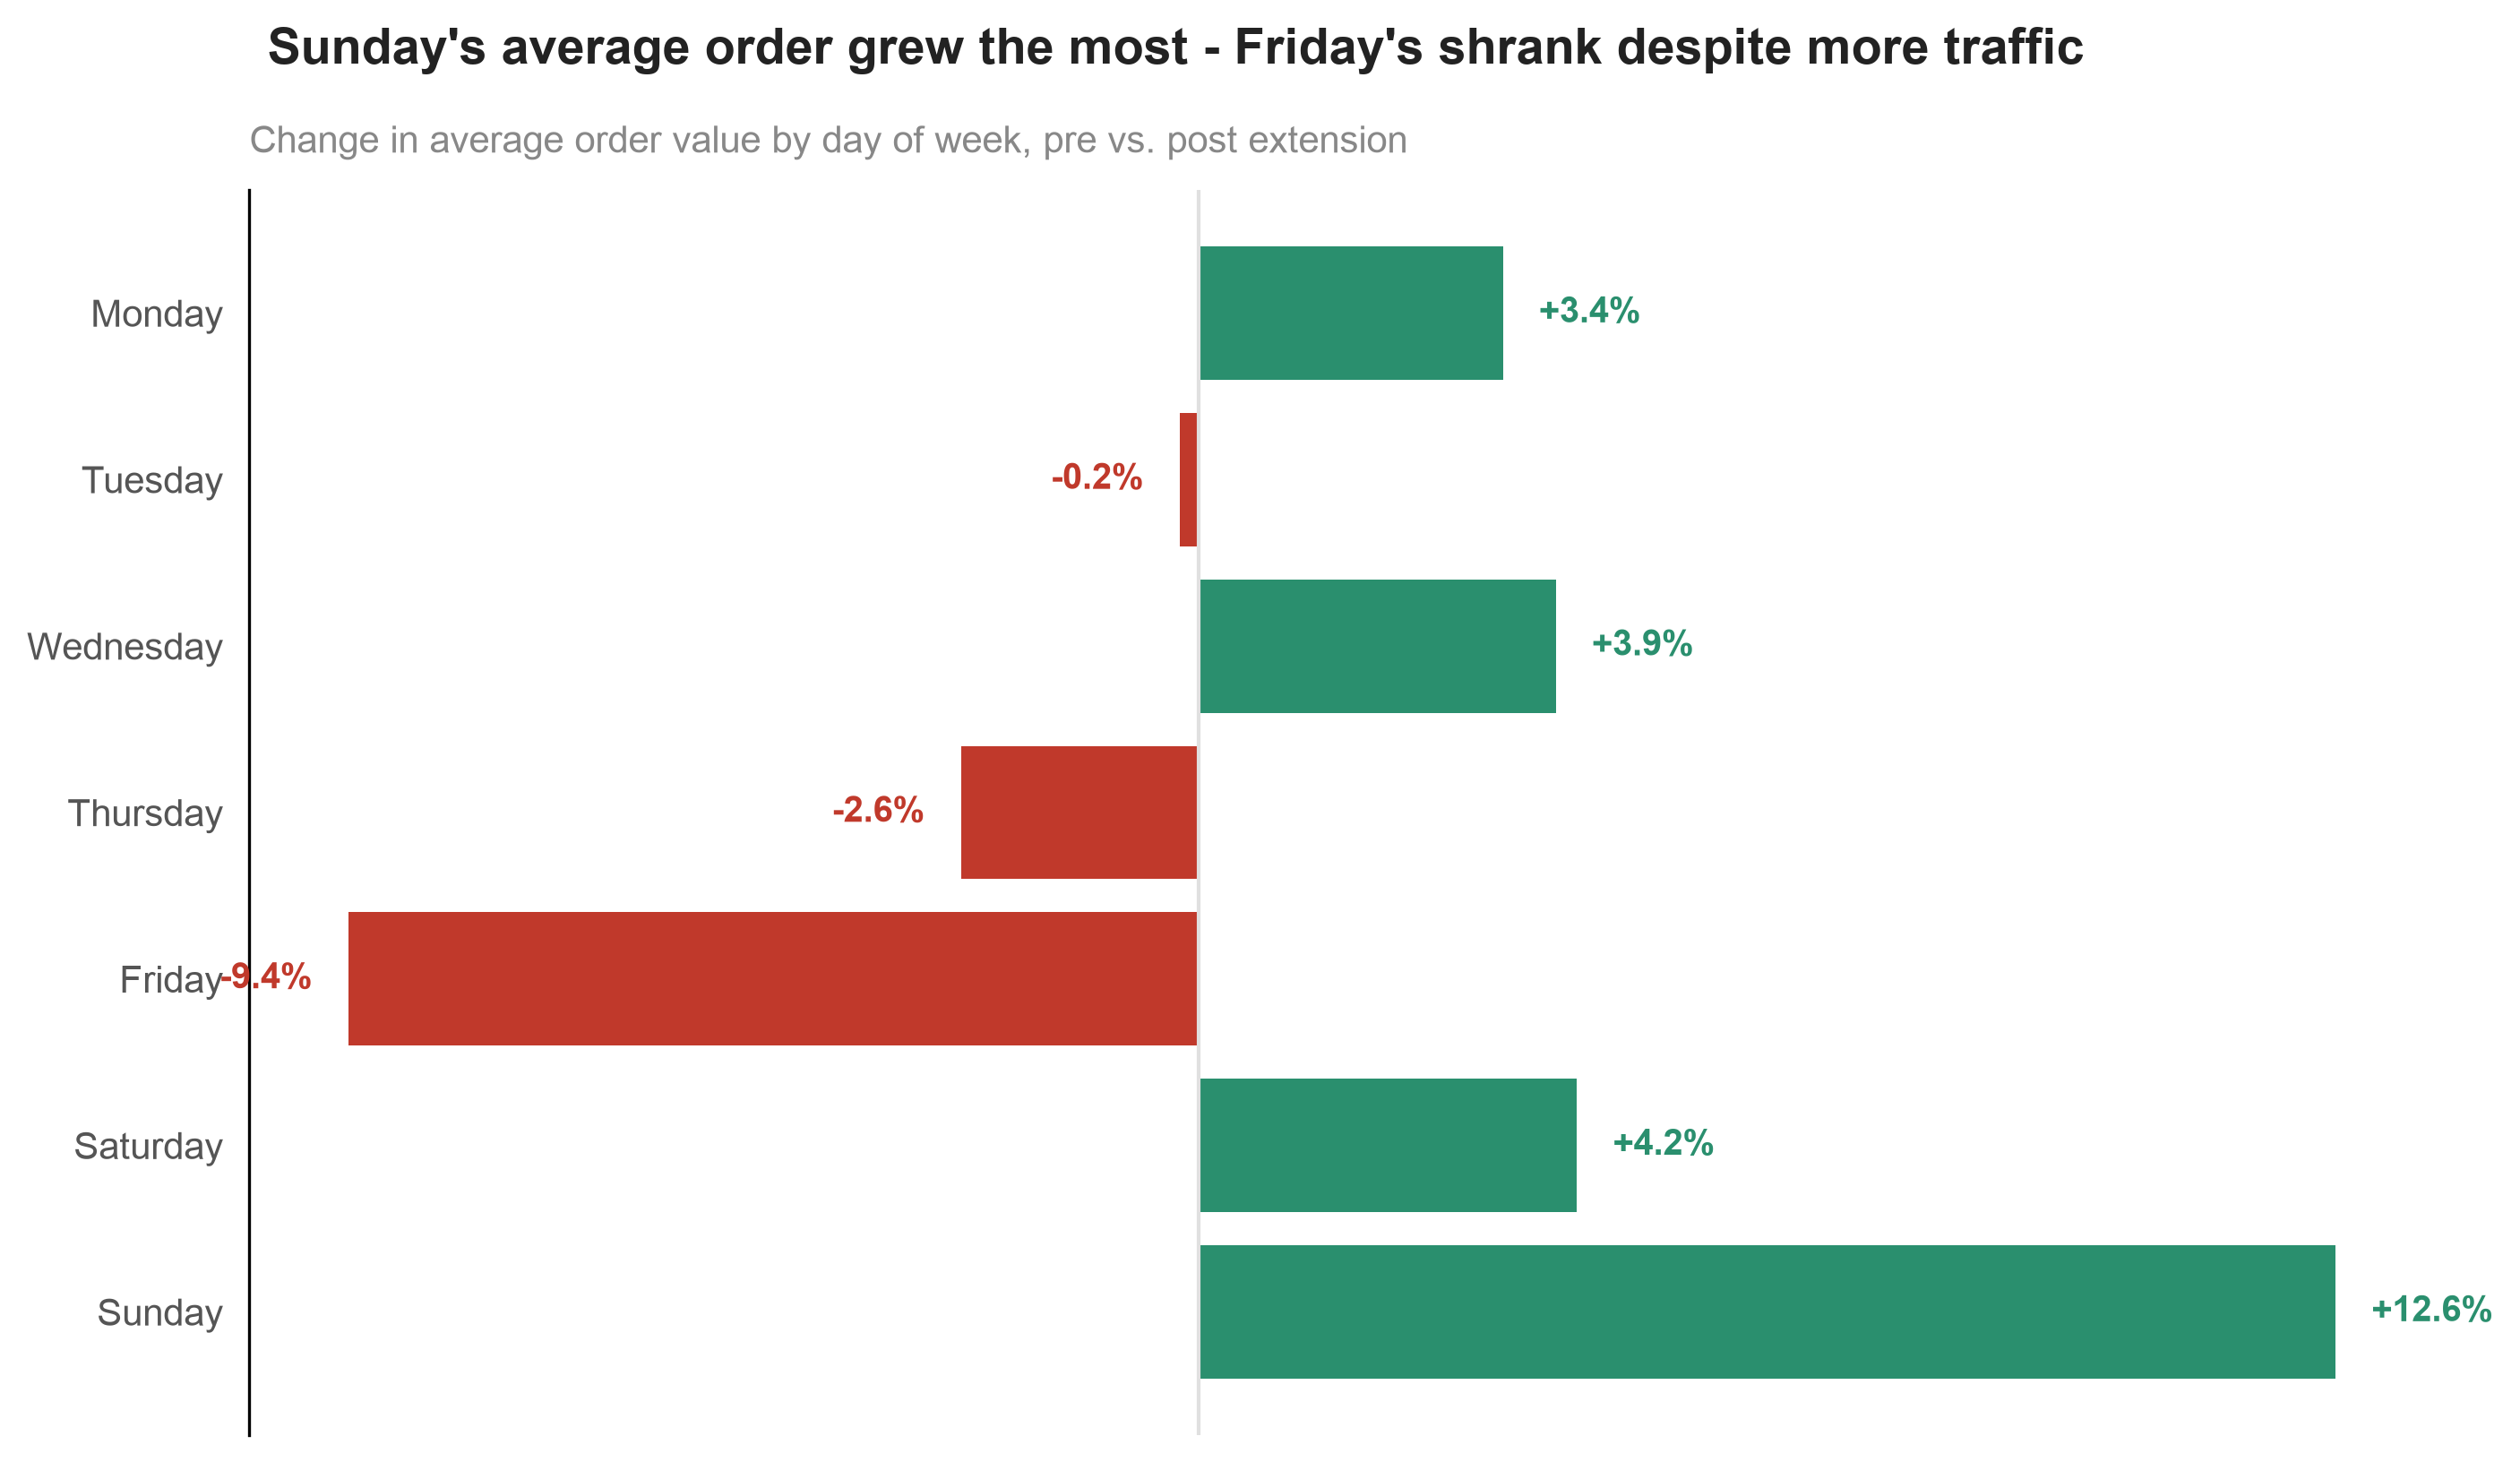

In [31]:
# CHART 6 — Change in day-of-week AOV, pre vs post (Act 2 cont: Sunday up, Friday down)

pct_change = ((day_of_week_aov_post / day_of_week_aov_pre - 1) * 100).reindex(days)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(pct_change.index[::-1], pct_change.values[::-1],
        color=[GREEN if v >= 0 else RED for v in pct_change.values[::-1]])

for y, v in enumerate(pct_change.values[::-1]):
    ax.text(v + (0.4 if v >= 0 else -0.4), y, f'{v:+.1f}%', va='center',
            ha='left' if v >= 0 else 'right', fontsize=9.5,
            color=GREEN if v >= 0 else RED, fontweight='bold')

ax.axvline(0, color=AXIS, lw=1)
fig.suptitle("Sunday's average order grew the most - Friday's shrank despite more traffic", x=0.11, ha='left', y=0.98,
             fontsize=13.5, fontweight='bold', color=INK)
ax.set_title('Change in average order value by day of week, pre vs. post extension', loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()

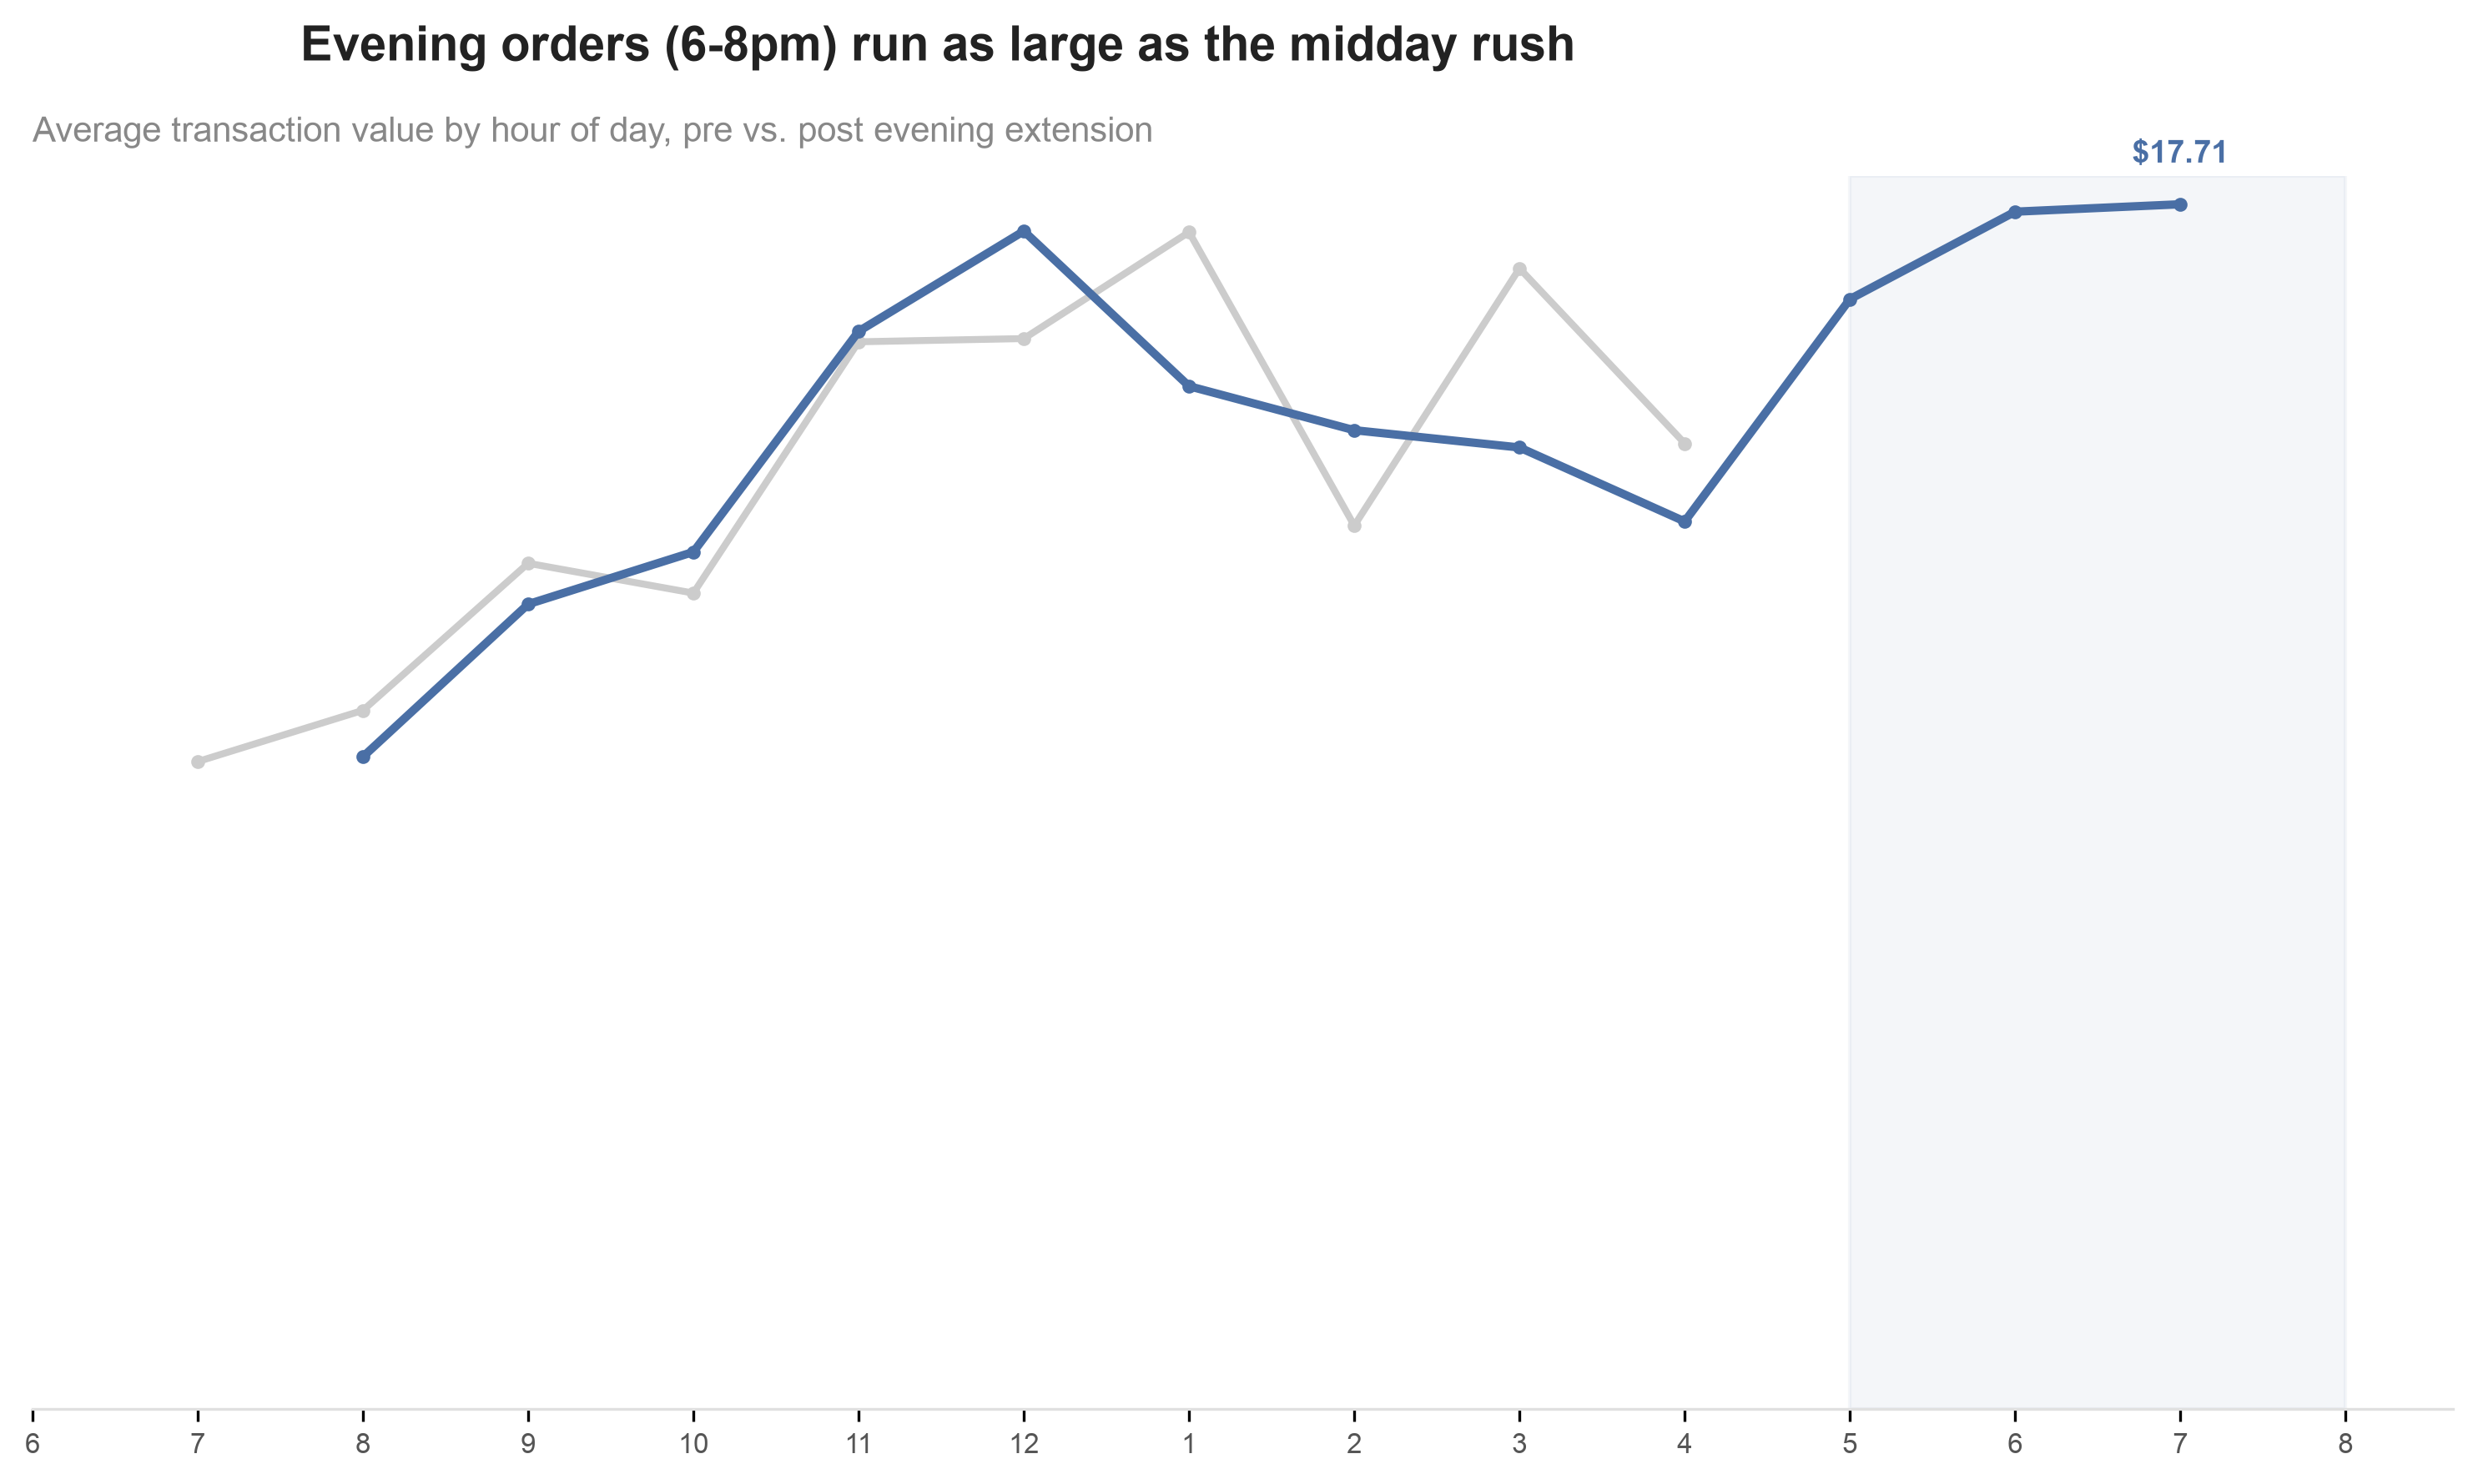

In [32]:
# CHART 7 — Hourly AOV, pre vs post (evening orders run as large as the midday rush)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(hours, hourly_aov_pre.values, color=GREY_LINE, lw=2, zorder=2, marker='o', markersize=3)
ax.plot(hours, hourly_aov_post.values, color=BLUE, lw=2.4, zorder=3, marker='o', markersize=3)

ax.axvspan(17, 20, color=BLUE, alpha=0.06, zorder=1)

v19 = hourly_aov_post[19]
ax.annotate(f'${v19:.2f}', xy=(19, v19), xytext=(0, 12), textcoords='offset points',
            ha='center', fontsize=9, color=BLUE, fontweight='bold')

fig.suptitle('Evening orders (6-8pm) run as large as the midday rush', x=0.125, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average transaction value by hour of day, pre vs. post evening extension', loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_ylim(bottom=0)
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, fontsize=8, color=TICK)
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', labelleft=False, left=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout()
save_chart(fig)
plt.show()

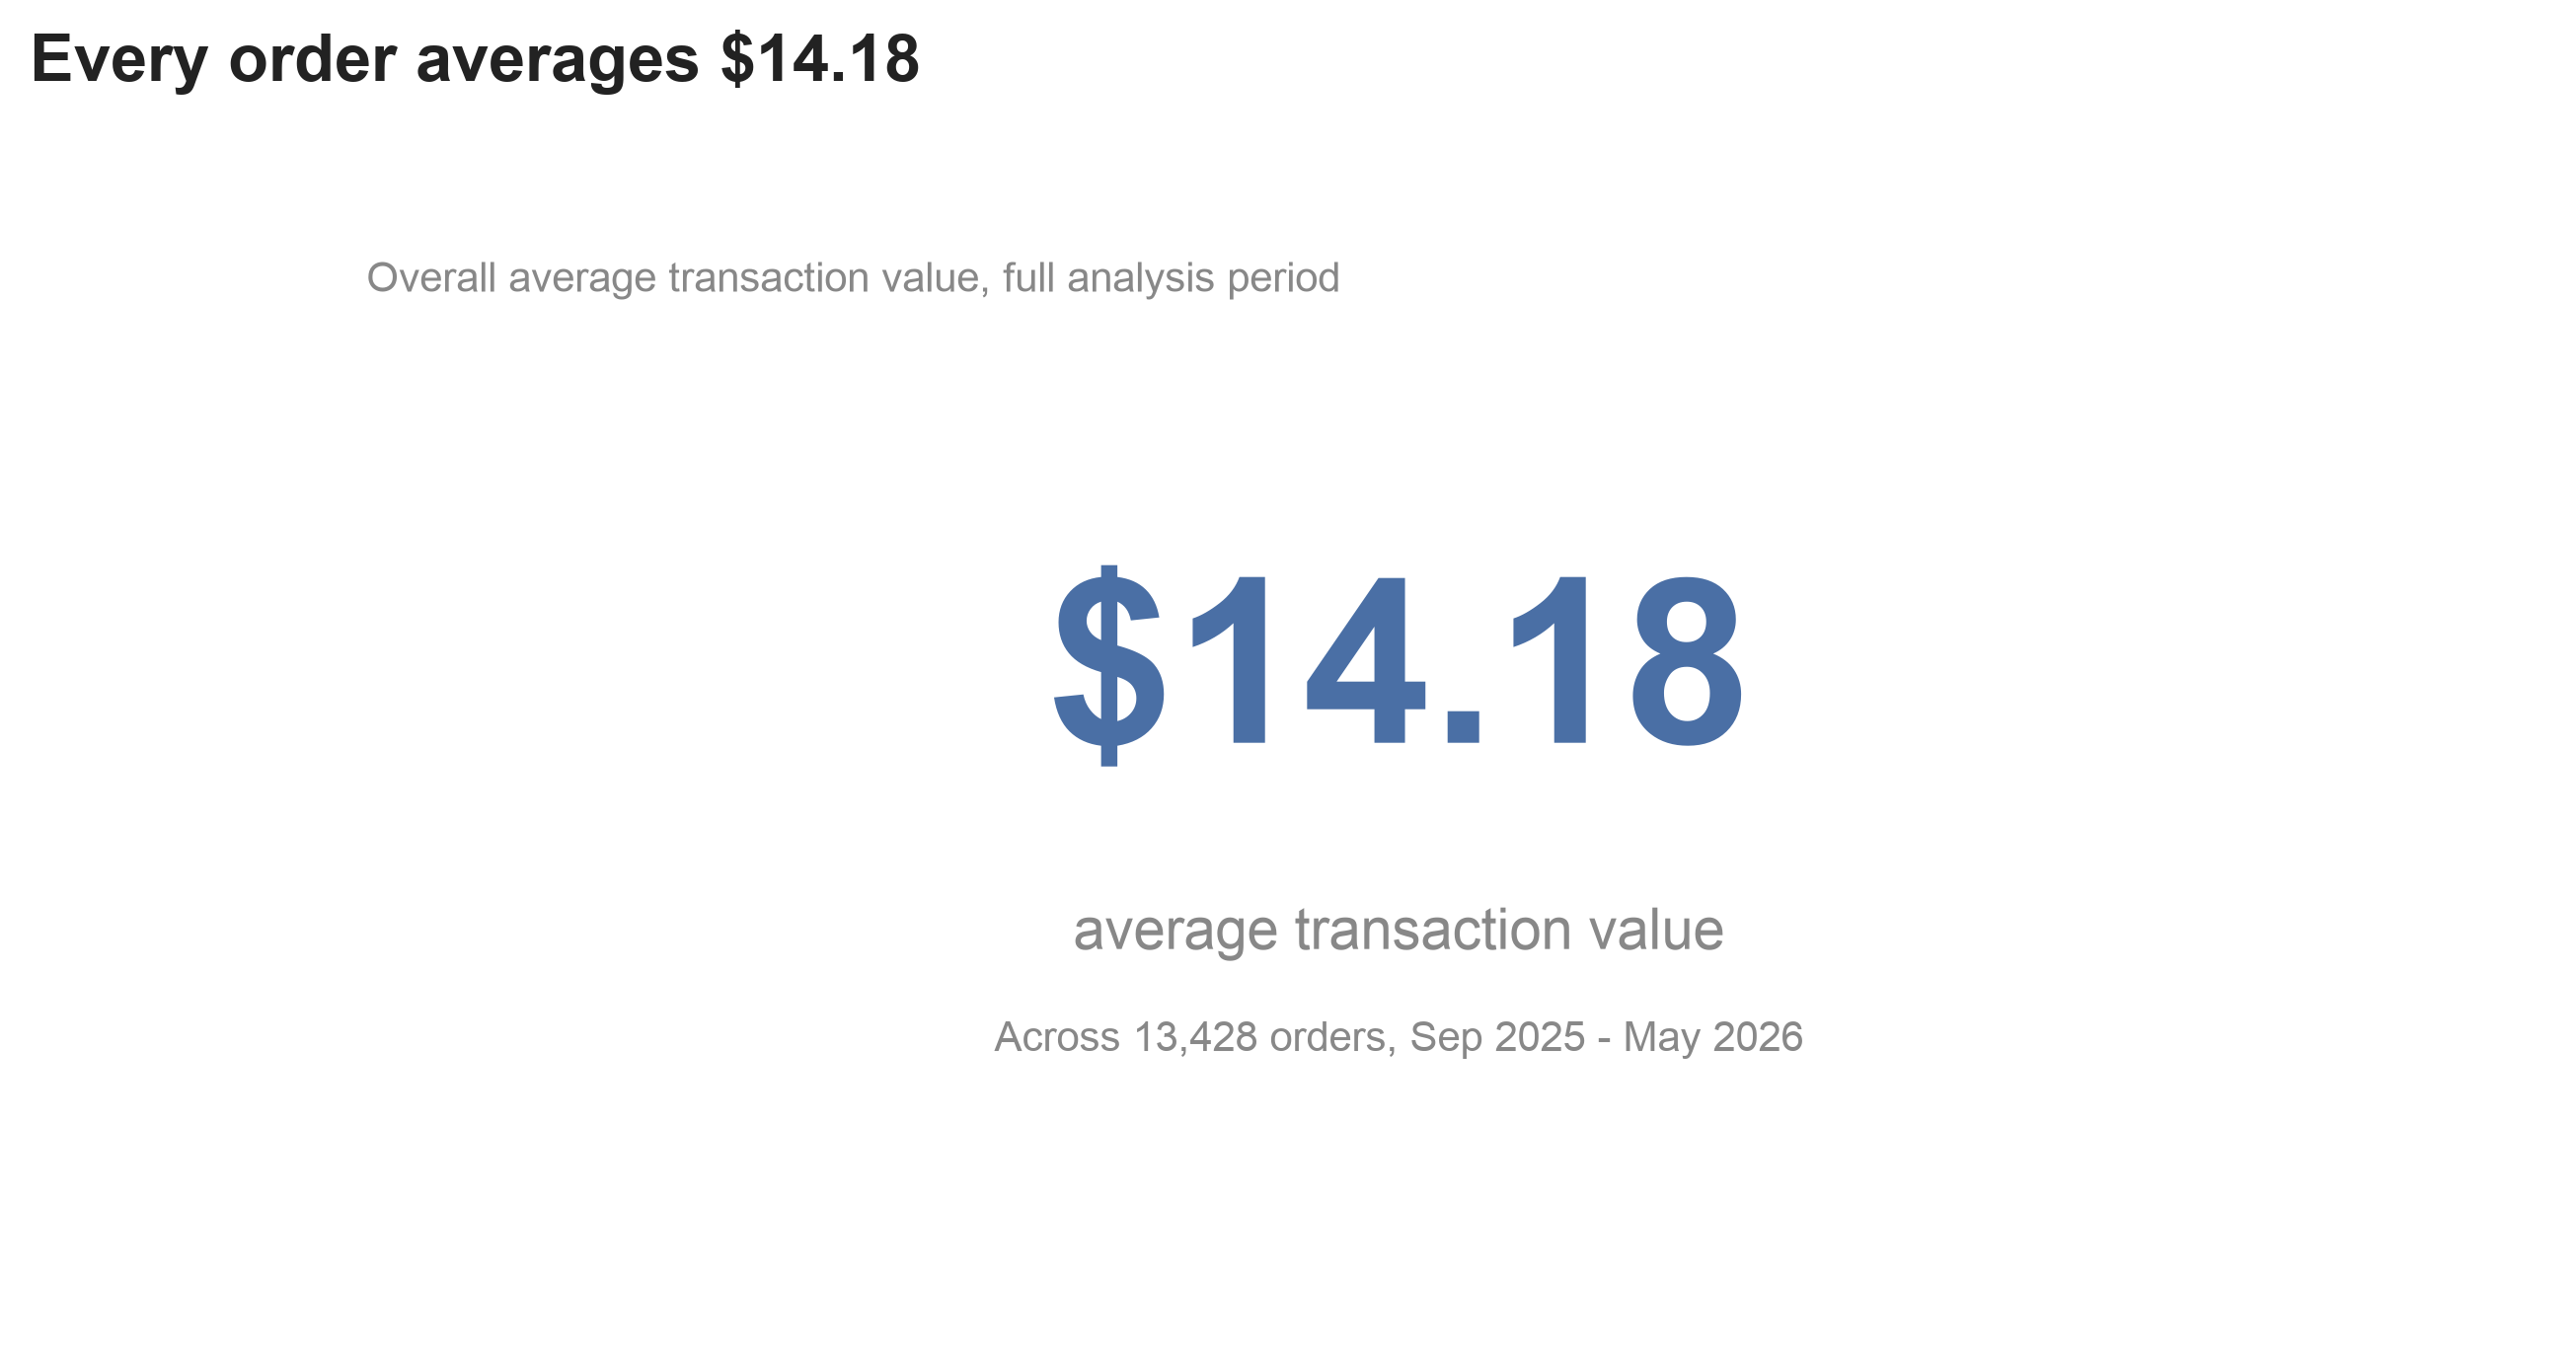

In [33]:
# CHART — Average transaction value (all-time), big-number opener for Part 2

fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

ax.text(0.5, 0.66, f'${aov_unfiltered:,.2f}', fontsize=56, fontweight='bold', color=BLUE, ha='center', va='top')
ax.text(0.5, 0.36, 'average transaction value', fontsize=14, color=MUTED, ha='center', va='top')
ax.text(0.5, 0.26, f'Across {len(orders):,} orders, Sep 2025 - May 2026', fontsize=10, color=MUTED, ha='center', va='top')

fig.suptitle(f'Every order averages ${aov_unfiltered:,.2f}', x=0.05, ha='left', y=0.98,
             fontsize=16, fontweight='bold', color=INK)
ax.text(0.05, 0.9, 'Overall average transaction value, full analysis period', fontsize=10, color=MUTED)

save_chart(fig)
plt.show()


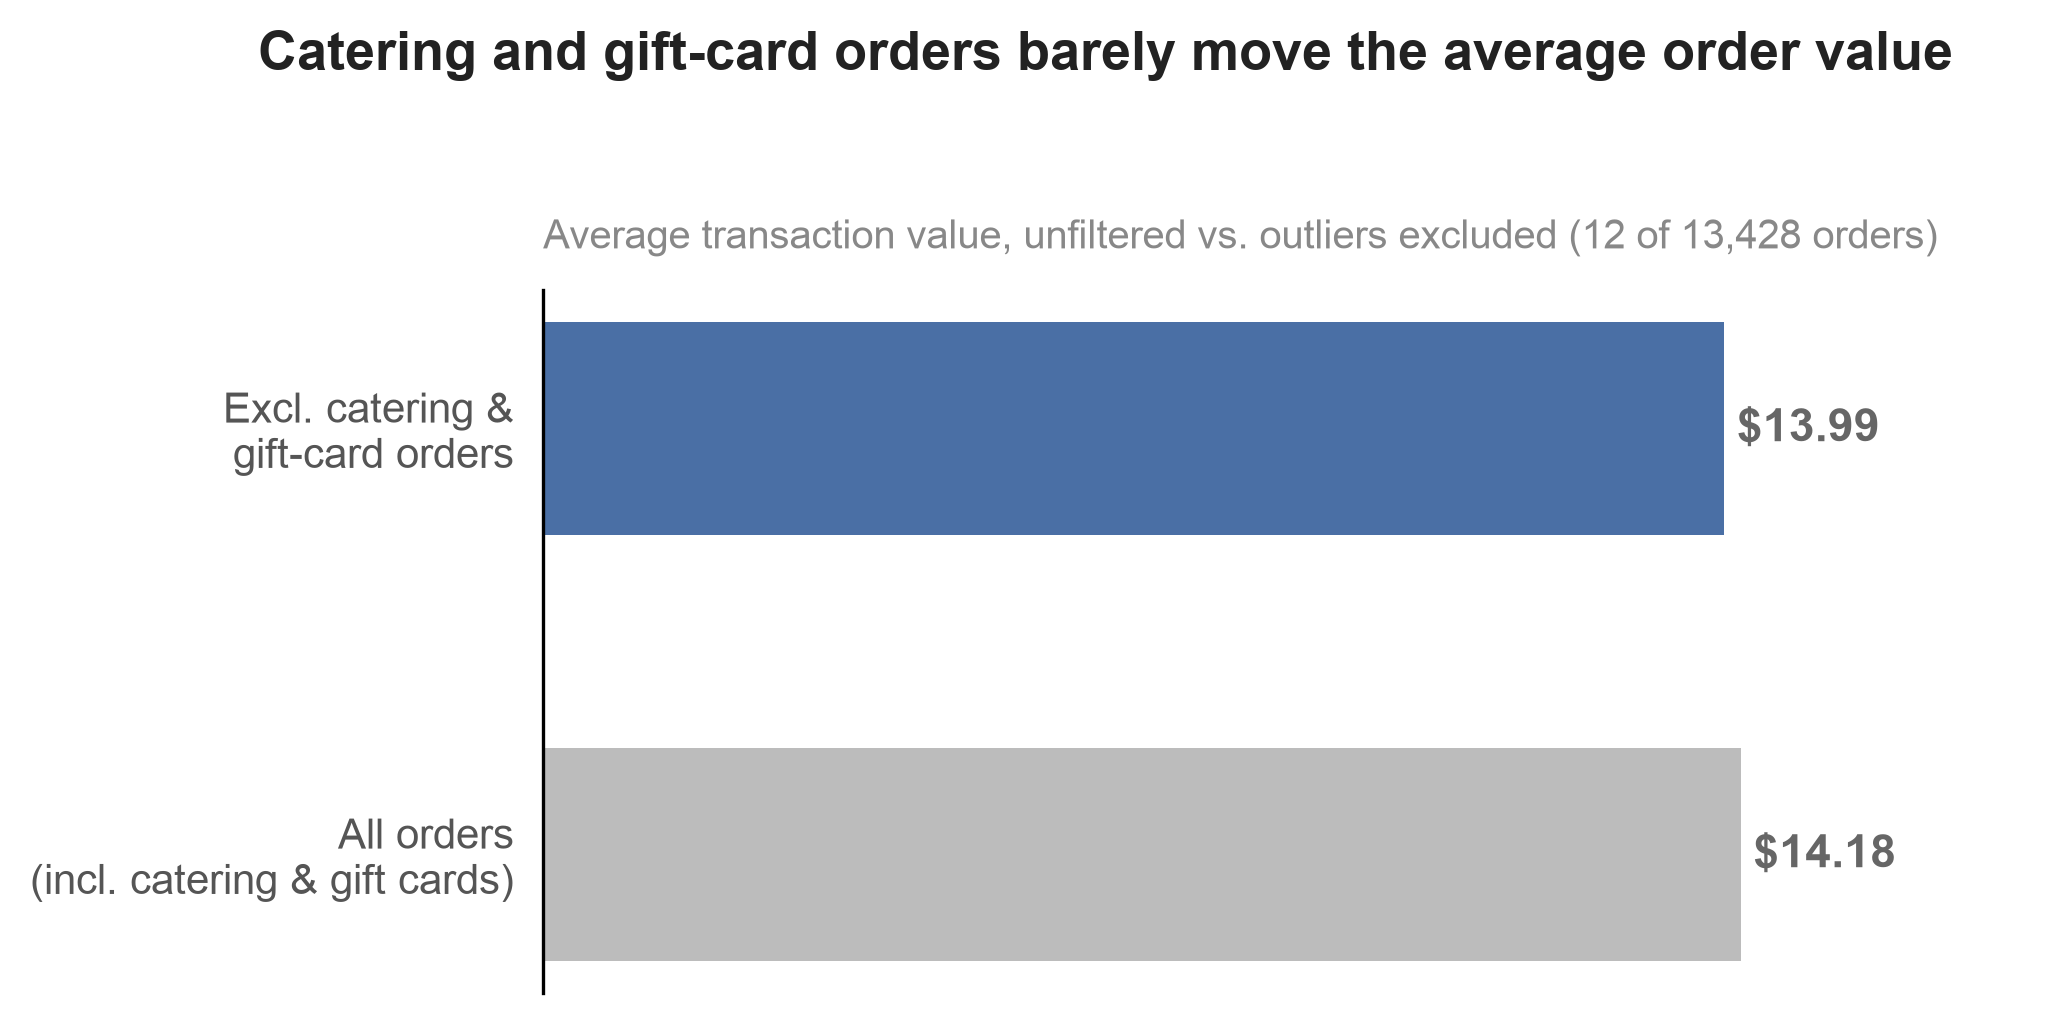

In [34]:
# CHART 8 — Overall AOV, unfiltered vs catering/gift-card excluded (Q5 headline)

labels = ['All orders\n(incl. catering & gift cards)', 'Excl. catering &\ngift-card orders']
vals2 = [aov_unfiltered, aov_excl_outliers]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(labels, vals2, color=[GREY_BAR, BLUE], height=0.5)
for y, v in enumerate(vals2):
    ax.text(v + 0.15, y, f'${v:.2f}', va='center', fontsize=11, color=LABEL, fontweight='bold')

ax.set_xlim(0, max(vals2) * 1.25)
fig.suptitle('Catering and gift-card orders barely move the average order value', x=0.13, ha='left', y=1.05,
             fontsize=13, fontweight='bold', color=INK)
ax.set_title('Average transaction value, unfiltered vs. outliers excluded (12 of 13,428 orders)', loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()

In [35]:
items_df = pd.read_csv('data/items_summary.csv')
mods_df = pd.read_csv('data/item_modifiers.csv')

print(items_df.shape, mods_df.shape)
print(items_df['gross_sales'].sum())


(363, 14) (952, 5)
186164.53999999998


In [36]:
# Flag non-menu / non-catalogue rows so they don't pollute item rankings, without deleting their revenue
NON_MENU_CATEGORIES = {'No Print', 'TO GO?'}

items_df['is_real_menu_item'] = (
    ~items_df['category'].isin(NON_MENU_CATEGORIES)
    & (items_df['name'] != 'Custom Item')
)

print('flagged as non-menu / custom-entry rows:', (~items_df['is_real_menu_item']).sum(), '/', len(items_df))
print(items_df.loc[~items_df['is_real_menu_item'], 'gross_sales'].sum(), 'in excluded revenue (still present in items_df, just flagged)')
print()
print('Uncategorized category still needs a manual look -- known real items misfiled in there:')
print(items_df[(items_df['category'] == 'Uncategorized') & (items_df['name'].isin(['Croissanwich', 'Cinnamon Maple Latte - Large']))])
print()
print('COGS tracking coverage:')
print('  never tracked ("-"):', (items_df['cogs_raw'] == '-').sum())
print('  explicit $0.00:', (items_df['cogs_raw'] == '$0.00').sum())
print('  actual nonzero cost on file:', (items_df['cogs'].fillna(0) > 0).sum())

flagged as non-menu / custom-entry rows: 46 / 363
4631.53 in excluded revenue (still present in items_df, just flagged)

Uncategorized category still needs a manual look -- known real items misfiled in there:
          category                          name  gross_sales  net_sales  \
172  Uncategorized                  Croissanwich        381.5      374.7   
177  Uncategorized  Cinnamon Maple Latte - Large        203.4      196.9   

     sold  refunded  discounts  refunds  pct_net_sales  avg_item_size  \
172  47.0       0.0       -6.8      0.0           0.21           7.97   
177  30.0       0.0       -6.5      0.0           0.11           6.56   

    cogs_raw  cogs gross_profit_raw  gross_profit  is_real_menu_item  
172    $0.00   0.0          $374.70         374.7               True  
177    $0.00   0.0          $196.90         196.9               True  

COGS tracking coverage:
  never tracked ("-"): 179
  explicit $0.00: 173
  actual nonzero cost on file: 11


In [37]:
# Reconciliation against the file's own reported header totals
FILE_REPORTED = {
    'gross_sales': 186164.54,
    'net_sales': 181227.67,
    'cogs': 2382.50,
    'gross_profit': 133254.29,
}

print('gross_sales  parsed vs reported:', round(items_df['gross_sales'].sum(), 2), 'vs', FILE_REPORTED['gross_sales'])
print('net_sales    parsed vs reported:', round(items_df['net_sales'].sum(), 2), 'vs', FILE_REPORTED['net_sales'])
print('cogs         parsed vs reported:', round(items_df['cogs'].fillna(0).sum(), 2), 'vs', FILE_REPORTED['cogs'])
print('gross_profit parsed vs reported:', round(items_df['gross_profit'].fillna(0).sum(), 2), 'vs', FILE_REPORTED['gross_profit'])
print()

# Cross-check against orders-level revenue -- NOT expected to match exactly:
# this file reports gross sales (item-level, pre-refund-netting), orders['revenue']
# is net of refunds at the order level. Comparing to understand the gap, not to force equality.
print('orders revenue (net of refunds, Open orders dropped):', round(orders['revenue'].sum(), 2))
print('items file gross sales:', round(items_df['gross_sales'].sum(), 2))
print('difference:', round(orders['revenue'].sum() - items_df['gross_sales'].sum(), 2))

gross_sales  parsed vs reported: 186164.54 vs 186164.54
net_sales    parsed vs reported: 181227.68 vs 181227.67
cogs         parsed vs reported: 2382.5 vs 2382.5
gross_profit parsed vs reported: 133254.29 vs 133254.29

orders revenue (net of refunds, Open orders dropped): 190421.27
items file gross sales: 186164.54
difference: 4256.73


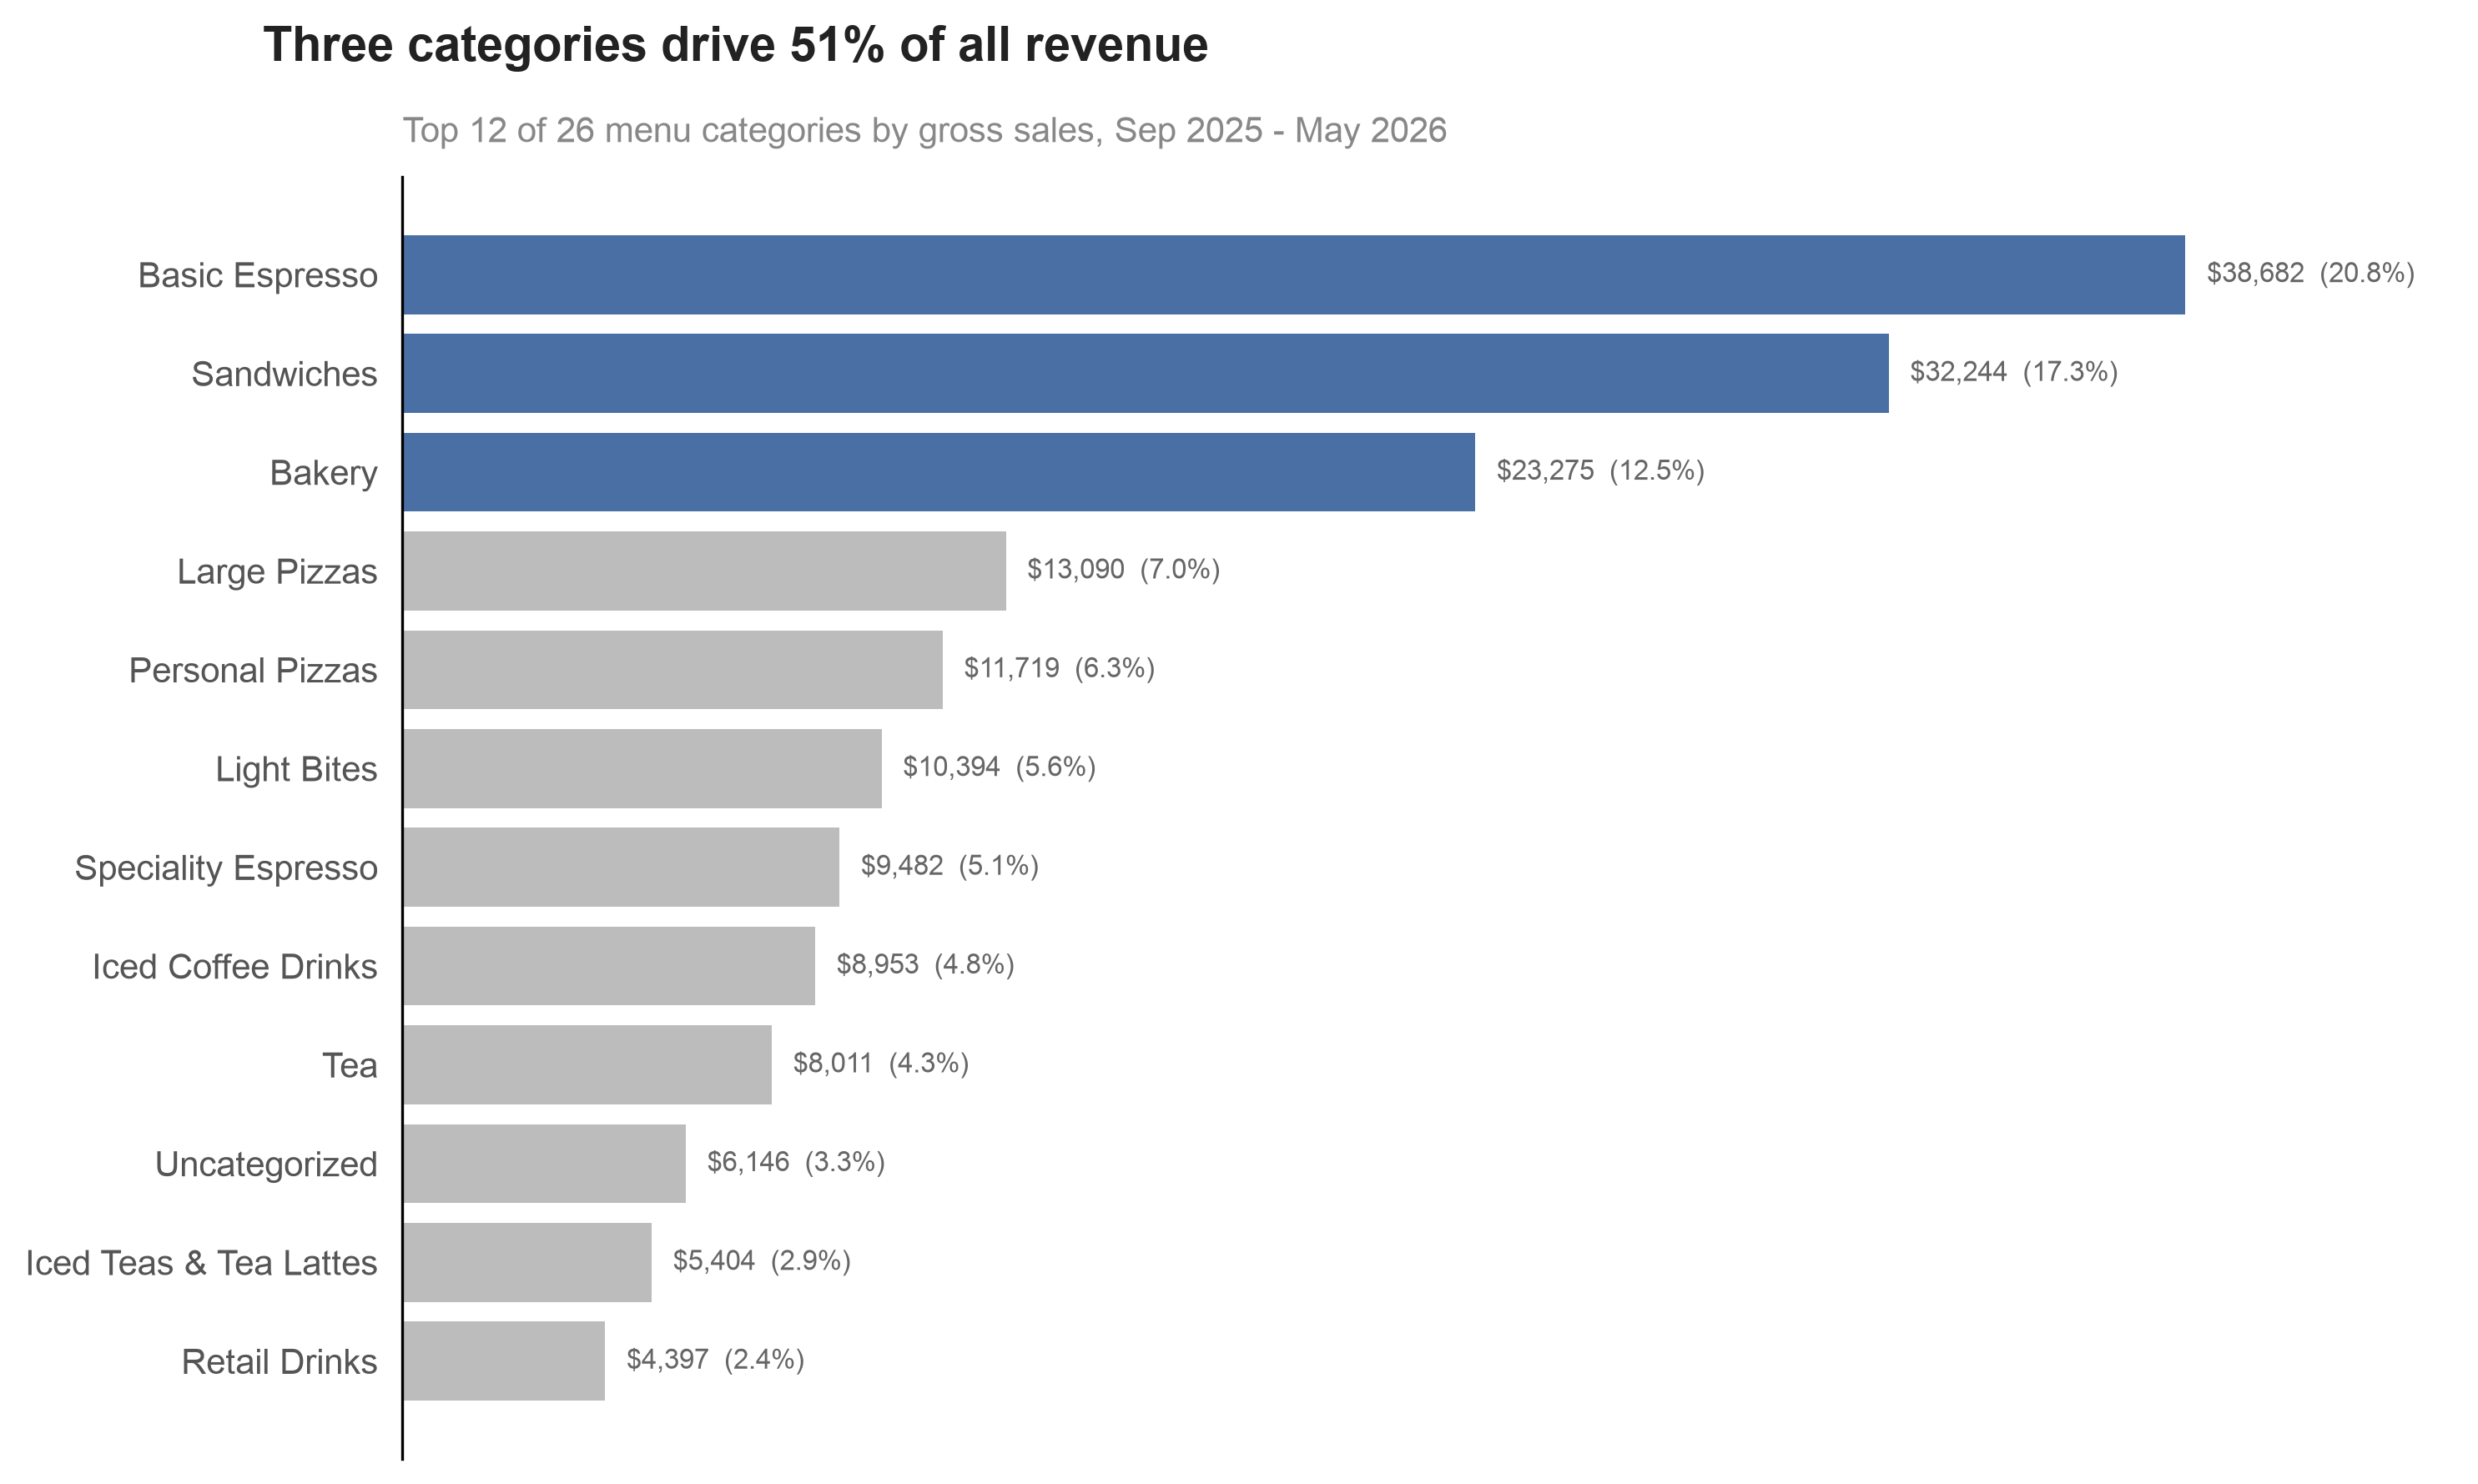

In [38]:
# CHART — Category (item type) ranking by revenue

N = 12
cat_revenue_full = (
    items_df[~items_df['category'].isin(NON_MENU_CATEGORIES)]
    .groupby('category')['gross_sales']
    .sum()
)

top3 = cat_revenue_full.sort_values(ascending=False).head(3)
top3_share = top3.sum() / cat_revenue_full.sum() * 100
cat_revenue = cat_revenue_full.sort_values(ascending=False).head(N).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = [BLUE if cat in top3.index else GREY_BAR for cat in cat_revenue.index]
ax.barh(cat_revenue.index, cat_revenue.values, color=colors)

cat_total = cat_revenue_full.sum()

for y, (cat, v) in enumerate(cat_revenue.items()):
    pct = v / cat_total * 100
    ax.text(v + cat_revenue.max() * 0.012, y, f'${v:,.0f}  ({pct:.1f}%)', va='center', fontsize=8, color=LABEL)

fig.suptitle(f'Three categories drive {top3_share:.0f}% of all revenue', x=0.11, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title(f'Top {N} of {cat_revenue_full.shape[0]} menu categories by gross sales, Sep 2025 - May 2026',
             loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_xlim(0, cat_revenue.max() * 1.15)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()


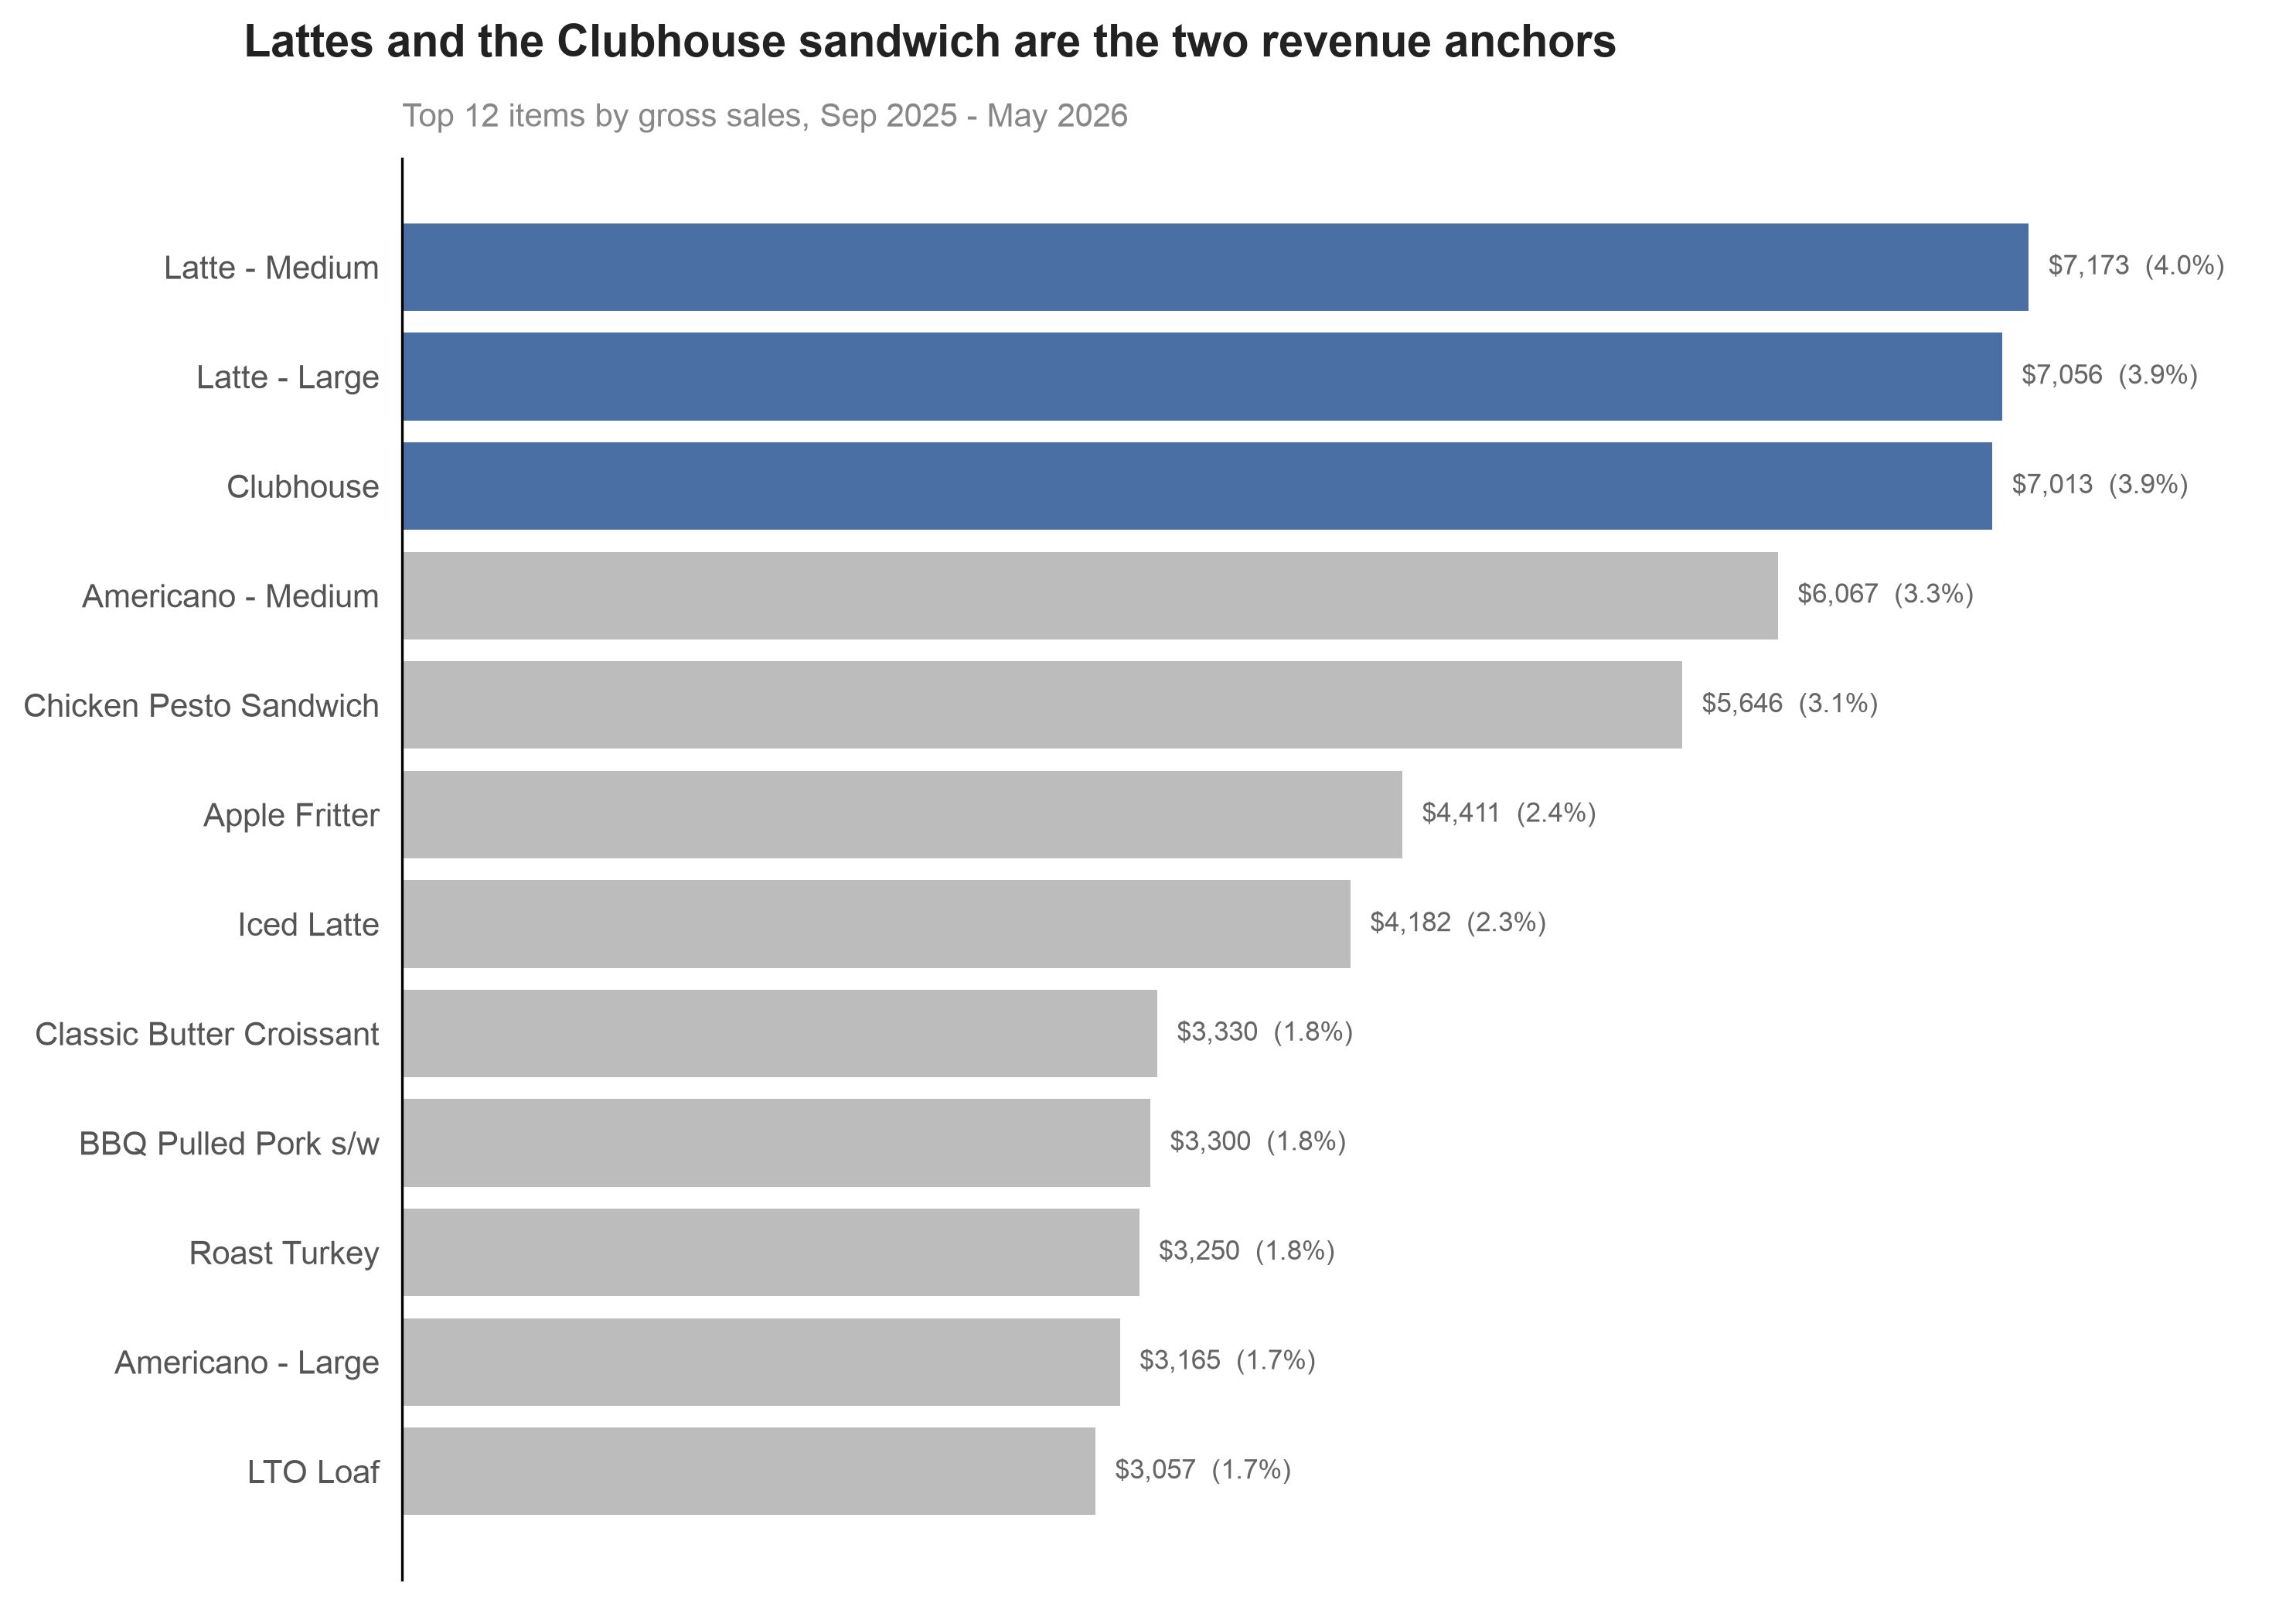

In [39]:
# CHART — Top 12 items by revenue

items_filtered = items_df[~items_df['category'].isin(NON_MENU_CATEGORIES) & (items_df['name'] != 'Custom Item')]
items_total = items_filtered['gross_sales'].sum()
top_items = items_filtered.nlargest(12, 'gross_sales').sort_values('gross_sales')

colors = [BLUE if i >= len(top_items) - 3 else GREY_BAR for i in range(len(top_items))]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_items['name'], top_items['gross_sales'], color=colors)

for y, (n, v) in enumerate(zip(top_items['name'], top_items['gross_sales'])):
    pct = v / items_total * 100
    ax.text(v + top_items['gross_sales'].max() * 0.012, y, f'${v:,.0f}  ({pct:.1f}%)', va='center', fontsize=8.5, color=LABEL)

fig.suptitle('Lattes and the Clubhouse sandwich are the two revenue anchors', x=0.11, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Top 12 items by gross sales, Sep 2025 - May 2026', loc='left', fontsize=10, color=MUTED, pad=10)
ax.set_xlim(0, top_items['gross_sales'].max() * 1.15)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()

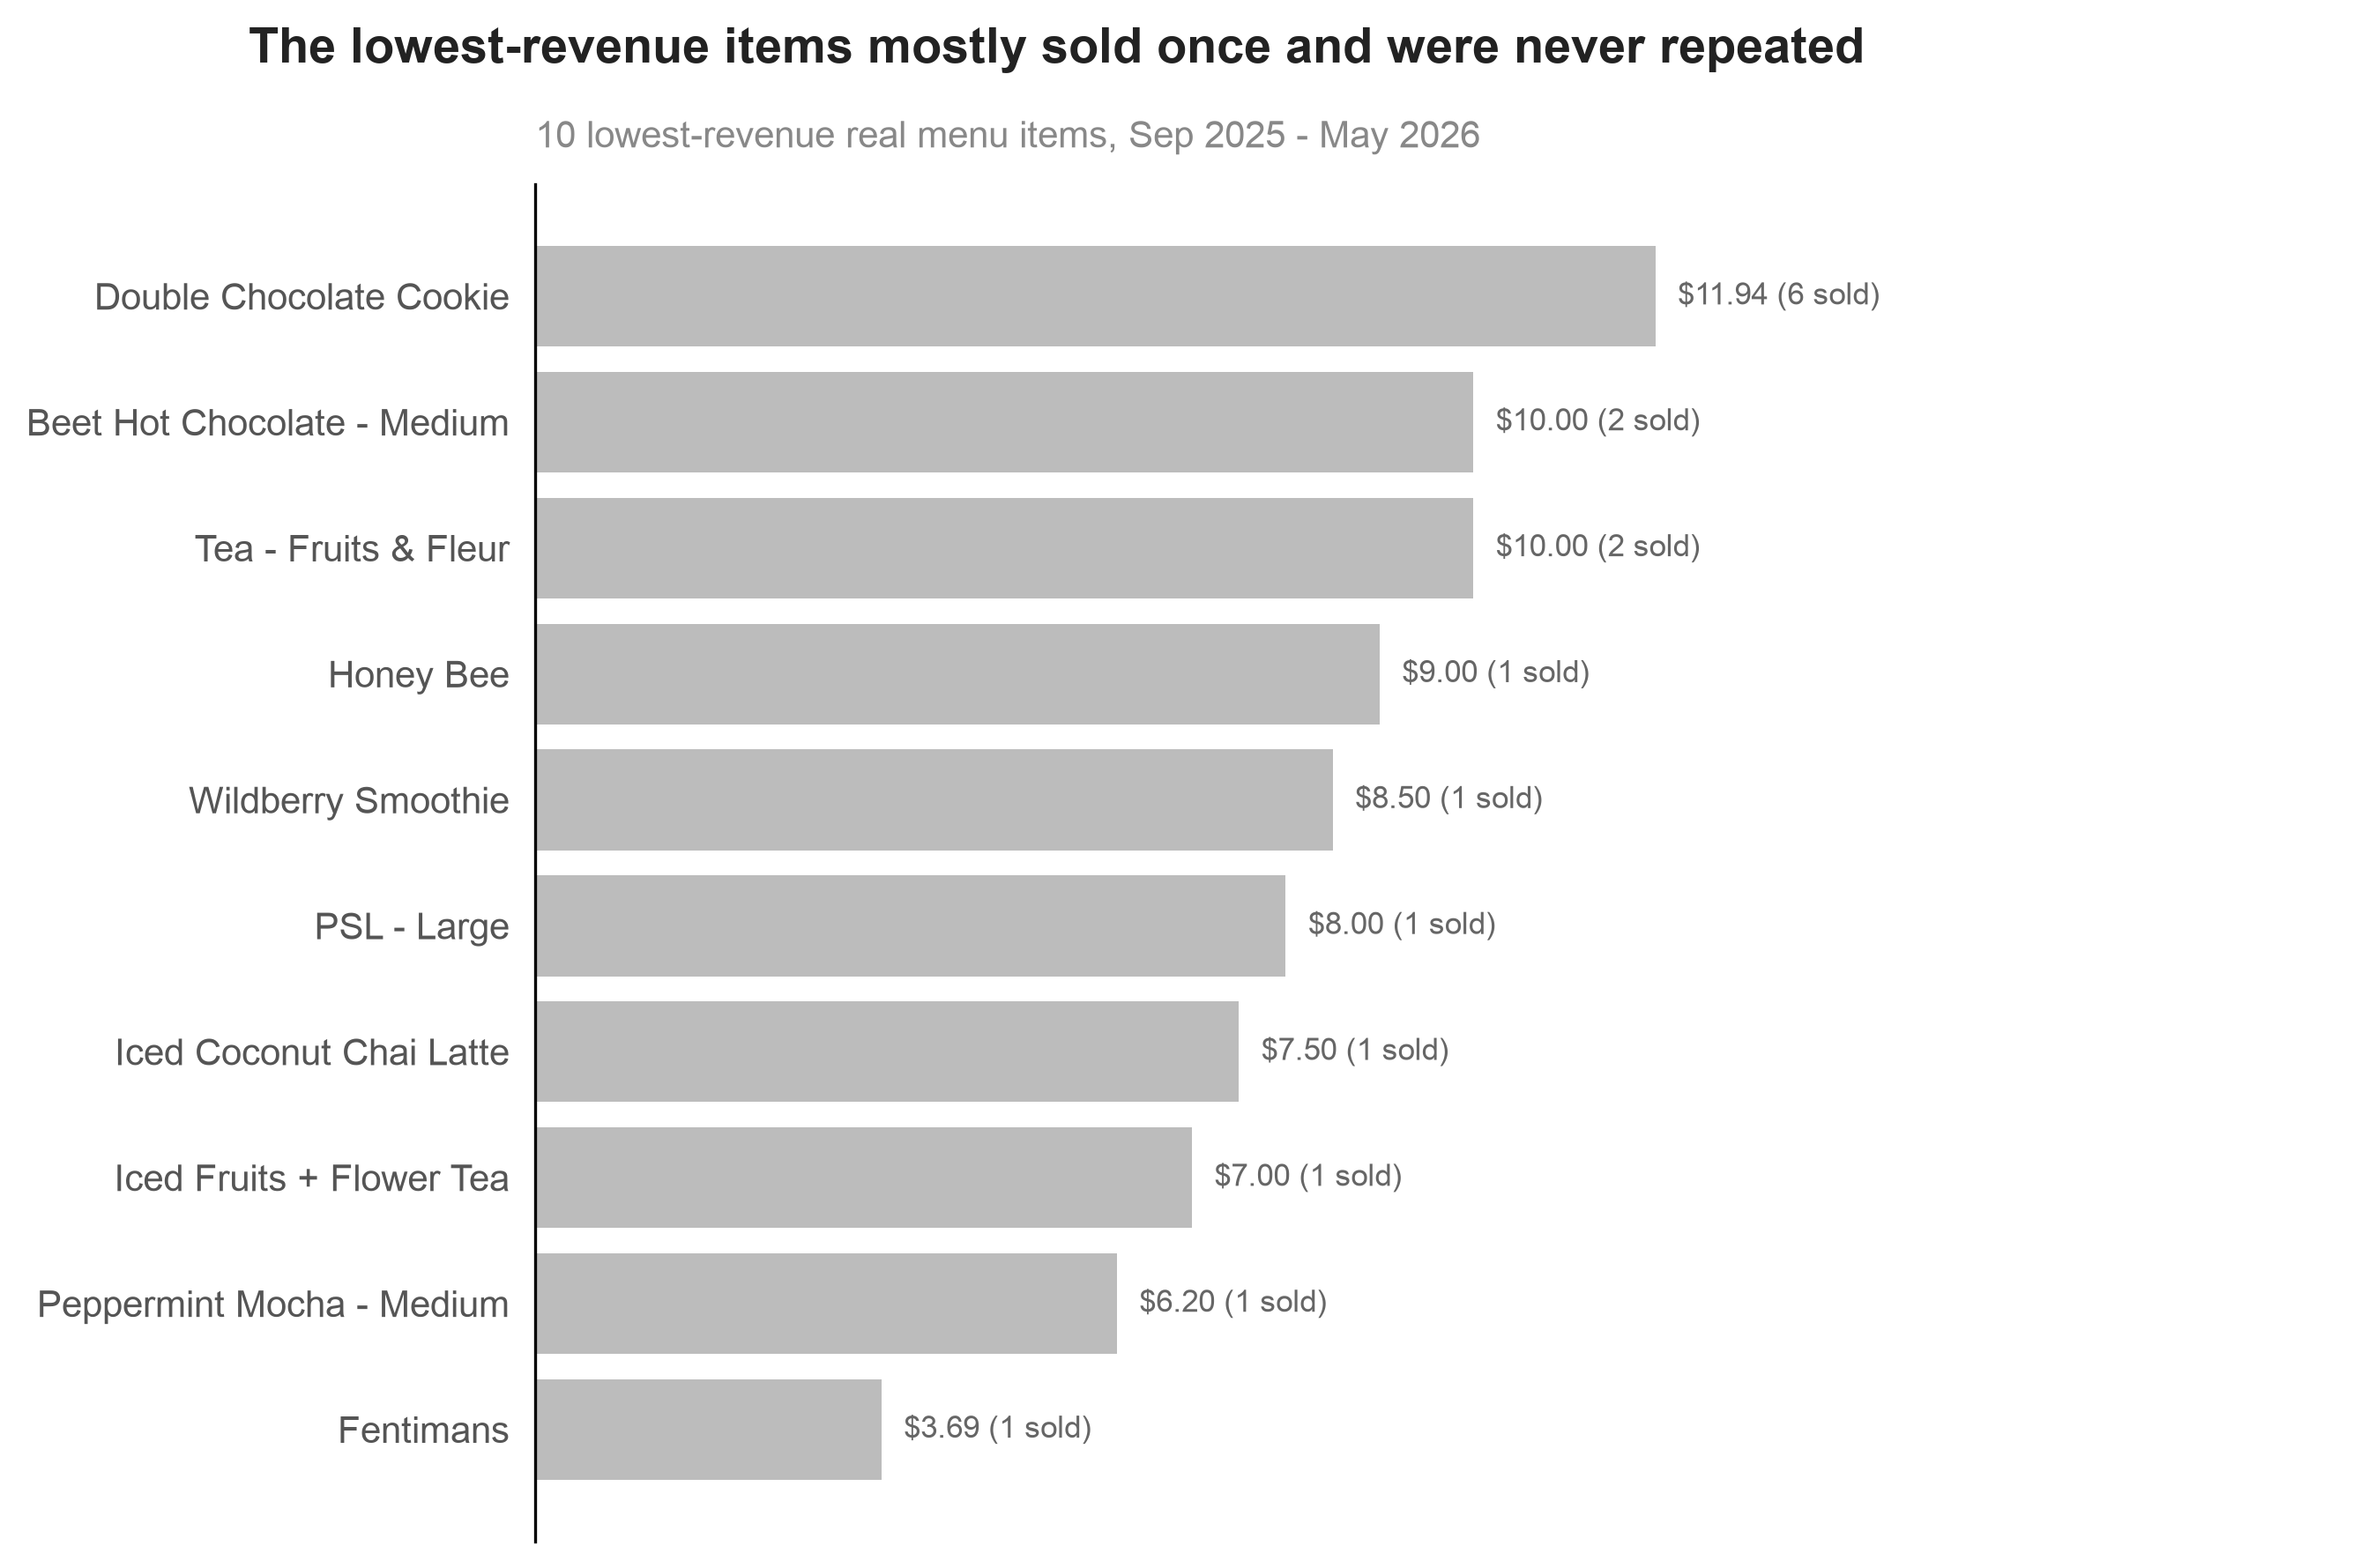

In [40]:
# CHART — Bottom items by revenue (one-off / rarely-ordered items)

EXCL_BOTTOM = NON_MENU_CATEGORIES | {'Uncategorized', 'Misc.'}
bottom_items = (
    items_df[~items_df['category'].isin(EXCL_BOTTOM) & (items_df['name'] != 'Custom Item') & (items_df['gross_sales'] > 0)]
    .nsmallest(10, 'gross_sales')
    .sort_values('gross_sales')
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(bottom_items['name'], bottom_items['gross_sales'], color=GREY_BAR)

for y, (n, v, s) in enumerate(zip(bottom_items['name'], bottom_items['gross_sales'], bottom_items['sold'])):
    ax.text(v + bottom_items['gross_sales'].max() * 0.02, y, f'${v:.2f} ({int(s)} sold)', va='center', fontsize=8.5, color=LABEL)

fig.suptitle('The lowest-revenue items mostly sold once and were never repeated', x=0.11, ha='left', y=0.98,
             fontsize=13.5, fontweight='bold', color=INK)
ax.set_title('10 lowest-revenue real menu items, Sep 2025 - May 2026', loc='left', fontsize=10, color=MUTED, pad=10)
ax.set_xlim(0, bottom_items['gross_sales'].max() * 1.6)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()

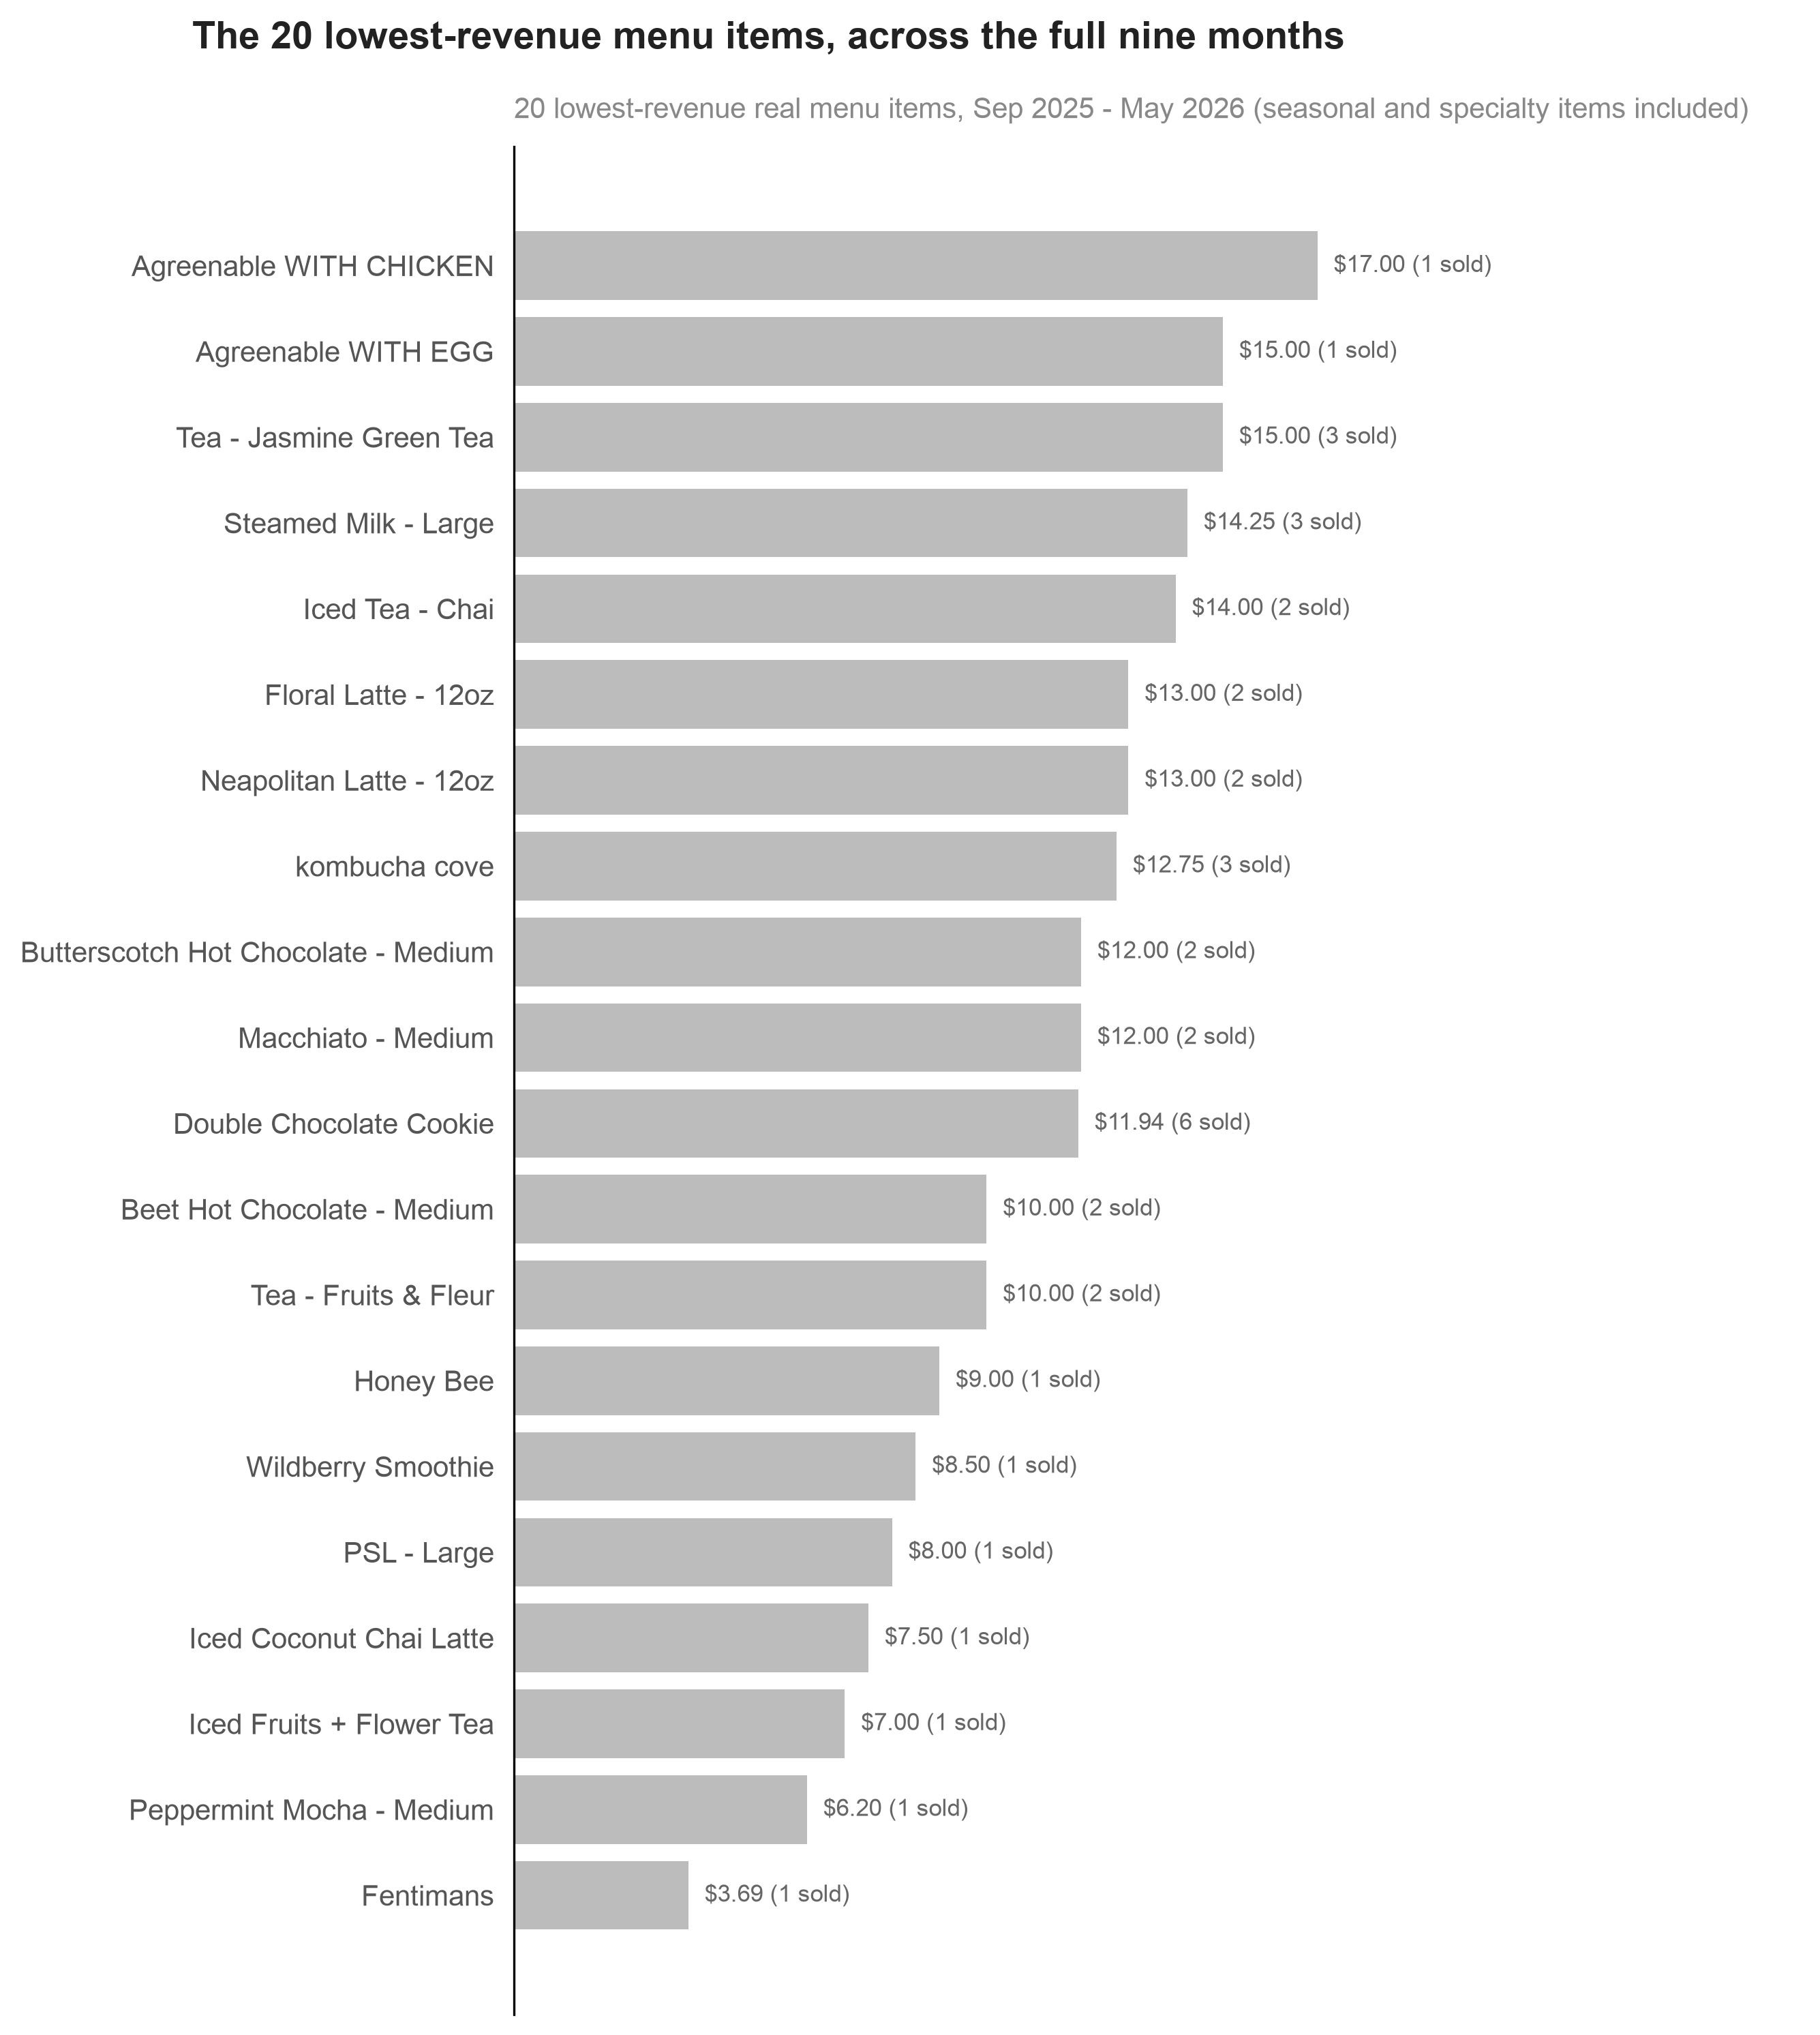

In [41]:
# CHART -- Bottom 20 items by revenue, full history, no seasonal filtering

EXCL_BOTTOM = NON_MENU_CATEGORIES | {'Uncategorized', 'Misc.'}
bottom_items_long = (
    items_df[~items_df['category'].isin(EXCL_BOTTOM) & (items_df['name'] != 'Custom Item') & (items_df['gross_sales'] > 0)]
    .nsmallest(20, 'gross_sales')
    .sort_values('gross_sales')
)

fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(bottom_items_long['name'], bottom_items_long['gross_sales'], color=GREY_BAR)

for y, (n, v, s) in enumerate(zip(bottom_items_long['name'], bottom_items_long['gross_sales'], bottom_items_long['sold'])):
    ax.text(v + bottom_items_long['gross_sales'].max() * 0.02, y, f'${v:.2f} ({int(s)} sold)',
            va='center', fontsize=8.5, color=LABEL)

fig.suptitle('The 20 lowest-revenue menu items, across the full nine months', x=0.11, ha='left', y=0.99,
             fontsize=13.5, fontweight='bold', color=INK)
ax.set_title('20 lowest-revenue real menu items, Sep 2025 - May 2026 (seasonal and specialty items included)',
             loc='left', fontsize=10, color=MUTED, pad=10)
ax.set_xlim(0, bottom_items_long['gross_sales'].max() * 1.6)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()


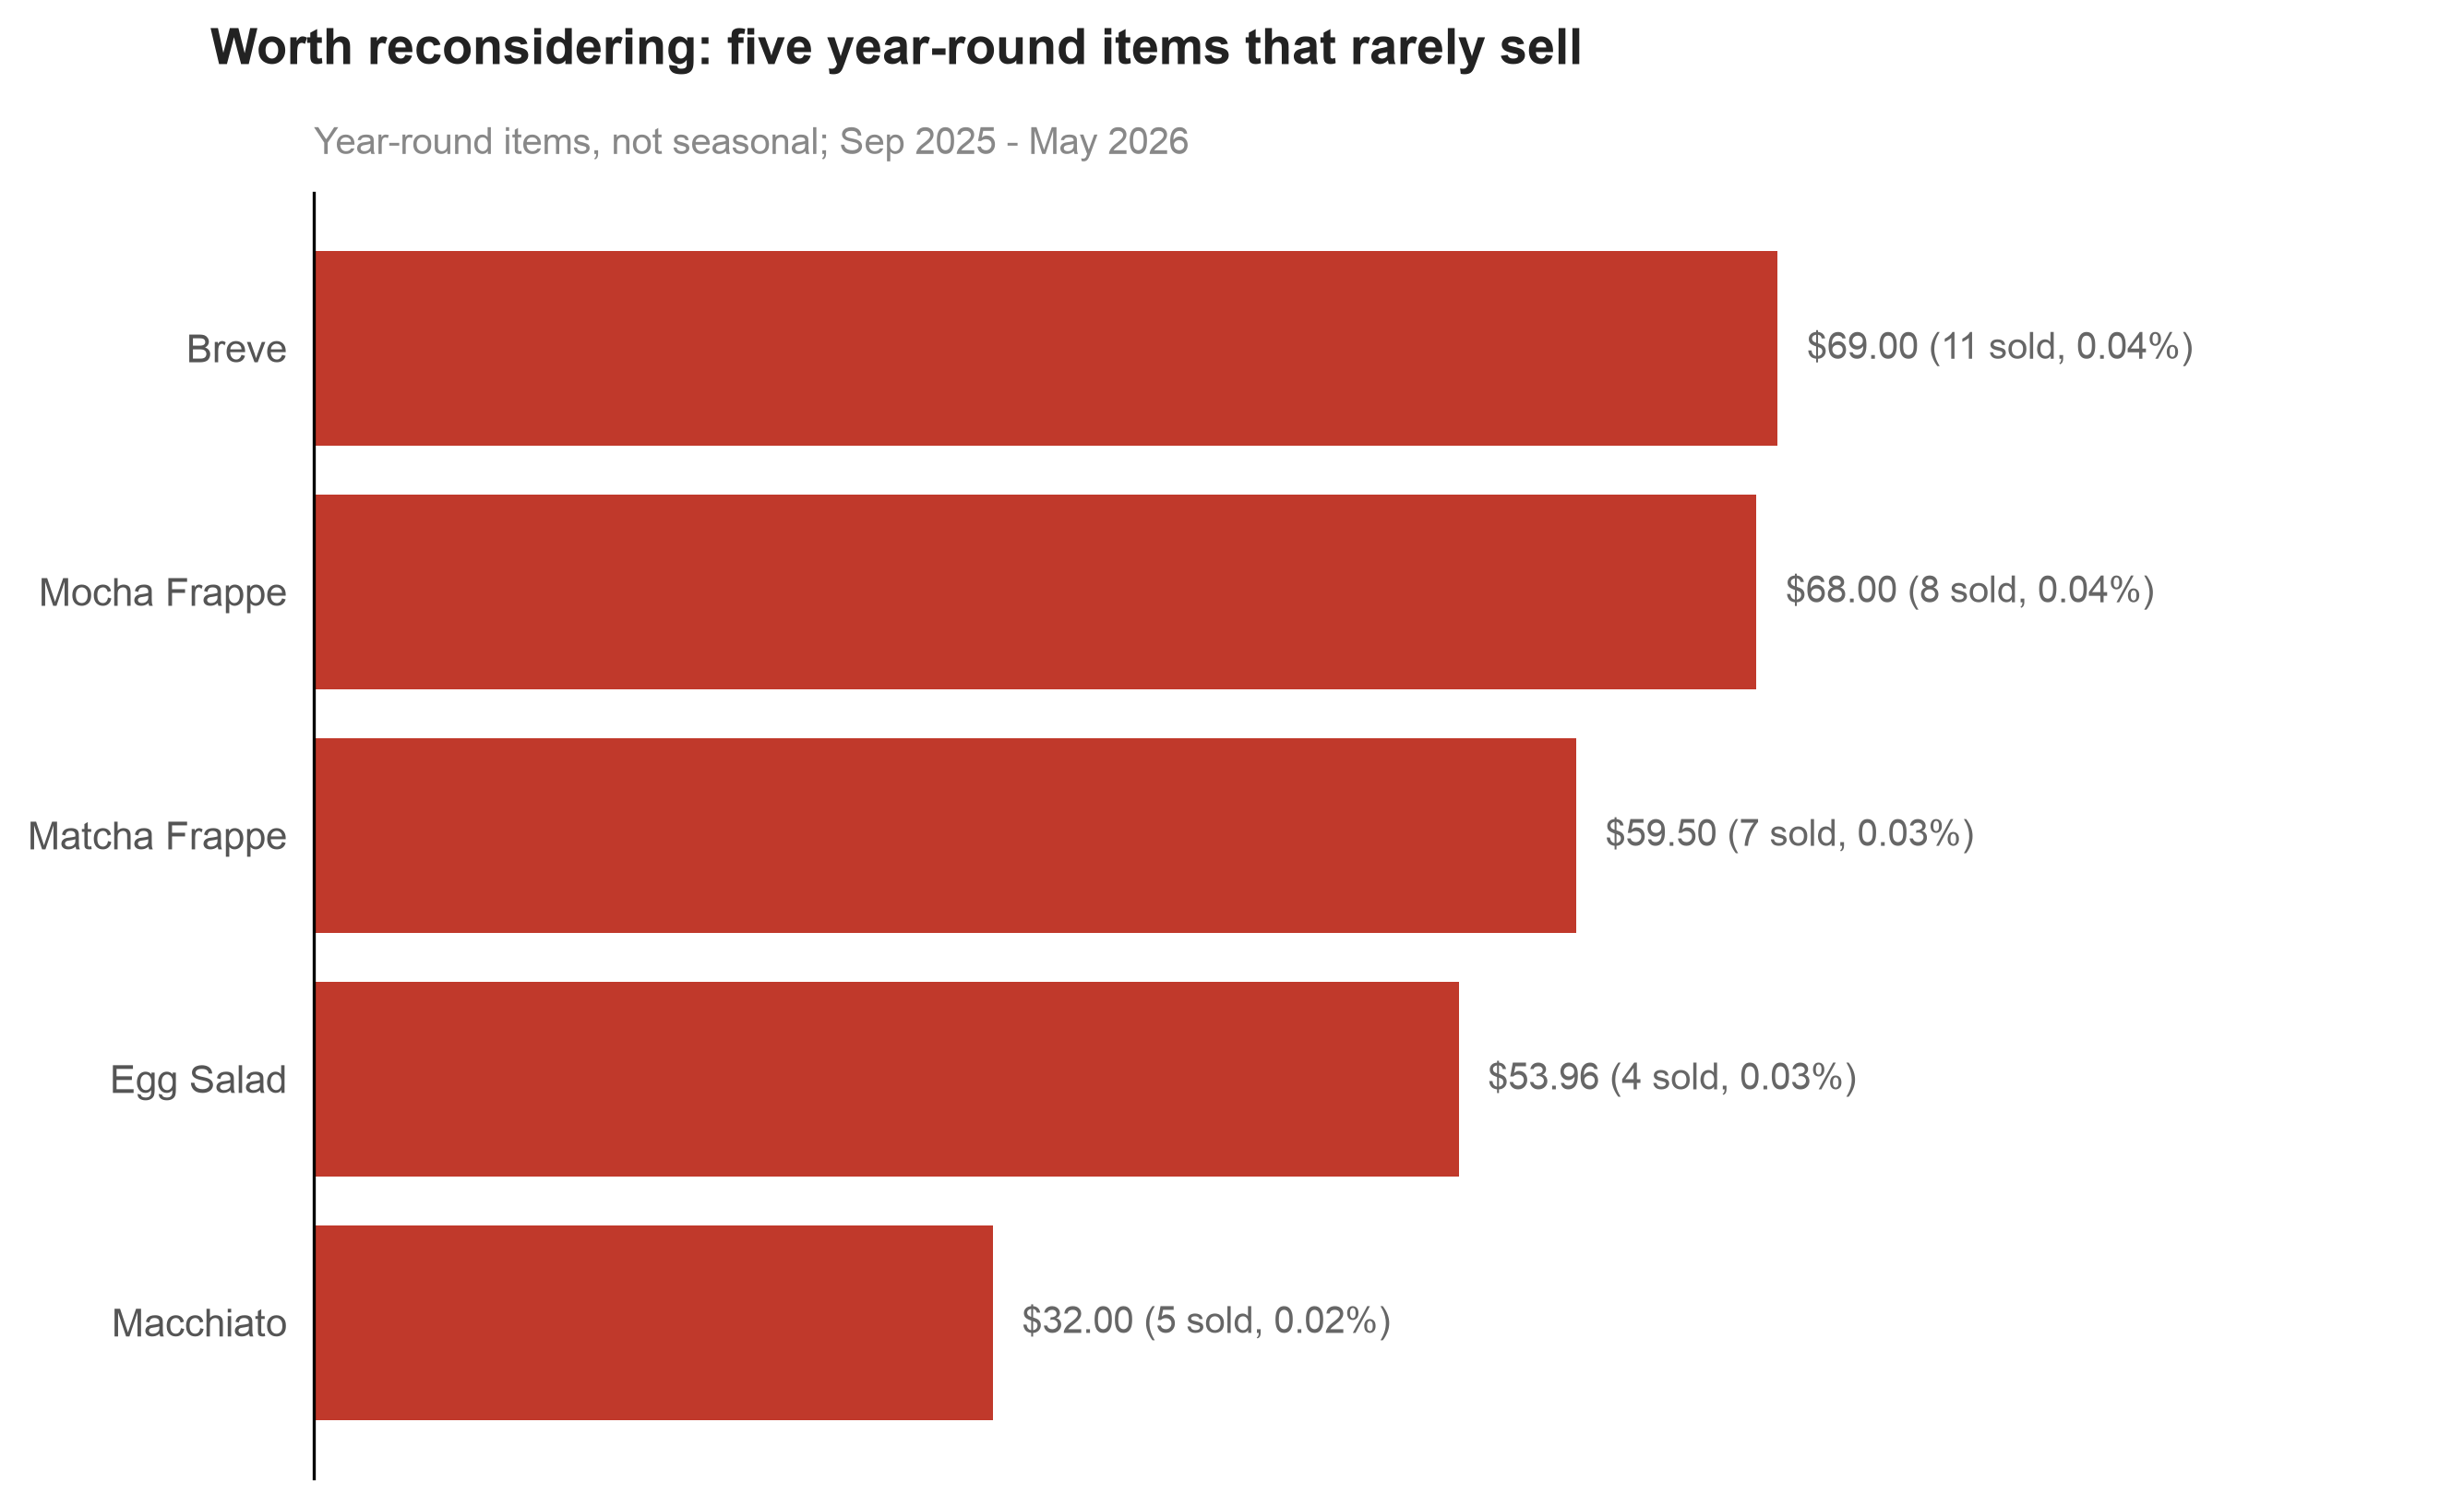

In [42]:
# CHART -- Confirmed year-round items that still barely sell
# Cross-checked against the cafe's actual printed menu and chalkboard photos --
# Macchiato, Breve, Egg Salad, Matcha Frappe, and Mocha Frappe are definitely
# offered all year, not seasonal specials, comp drinks, or discontinued
# items, so their low sales reflect real demand rather than a menu-timing
# artifact. Other low-sellers found in the same pass (a few pizza variants,
# "Dirty Chai Latte") don't appear on the current menu/chalkboard by name --
# not included here since whether they're still offered needs confirming
# with the owner first. Two more ("Porto Melt WITH PULLED PORK", "Chicken Pesto
# WITH AVOCADO") are specific add-on combos of sandwiches that ARE on the
# menu -- excluded as bars since a low count on one preset combo doesn't
# mean the sandwich itself underperforms, just that combo-SKU may be rare.

CONFIRMED_UNDERPERFORMERS = {
    'Macchiato': ['Macchiato - Medium', 'Macchiato - Large'],
    'Breve': ['Breve - Medium', 'Breve - Large'],
    'Egg Salad': ['Egg Salad'],
    'Matcha Frappe': ['Matcha Frappe'],
    'Mocha Frappe': ['Mocha Frappe'],
}

rows = []
for label, names in CONFIRMED_UNDERPERFORMERS.items():
    sub = items_df[items_df['name'].isin(names)]
    rows.append({'name': label, 'sold': sub['sold'].sum(), 'gross_sales': sub['gross_sales'].sum()})
confirmed = pd.DataFrame(rows).sort_values('gross_sales')

items_total = items_df[~items_df['category'].isin(NON_MENU_CATEGORIES) & (items_df['name'] != 'Custom Item')]['gross_sales'].sum()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(confirmed['name'], confirmed['gross_sales'], color=RED)

for y, (n, sold, v) in enumerate(zip(confirmed['name'], confirmed['sold'], confirmed['gross_sales'])):
    pct = v / items_total * 100
    ax.text(v + confirmed['gross_sales'].max() * 0.02, y, f'${v:.2f} ({int(sold)} sold, {pct:.2f}%)',
            va='center', fontsize=9.5, color=LABEL)

fig.suptitle("Worth reconsidering: five year-round items that rarely sell",
             x=0.09, ha='left', y=0.98, fontsize=13, fontweight='bold', color=INK)
ax.set_title('Year-round items, not seasonal; Sep 2025 - May 2026',
             loc='left', fontsize=9.5, color=MUTED, pad=10)
ax.set_xlim(0, confirmed['gross_sales'].max() * 1.45)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)


plt.tight_layout()
save_chart(fig)
plt.show()


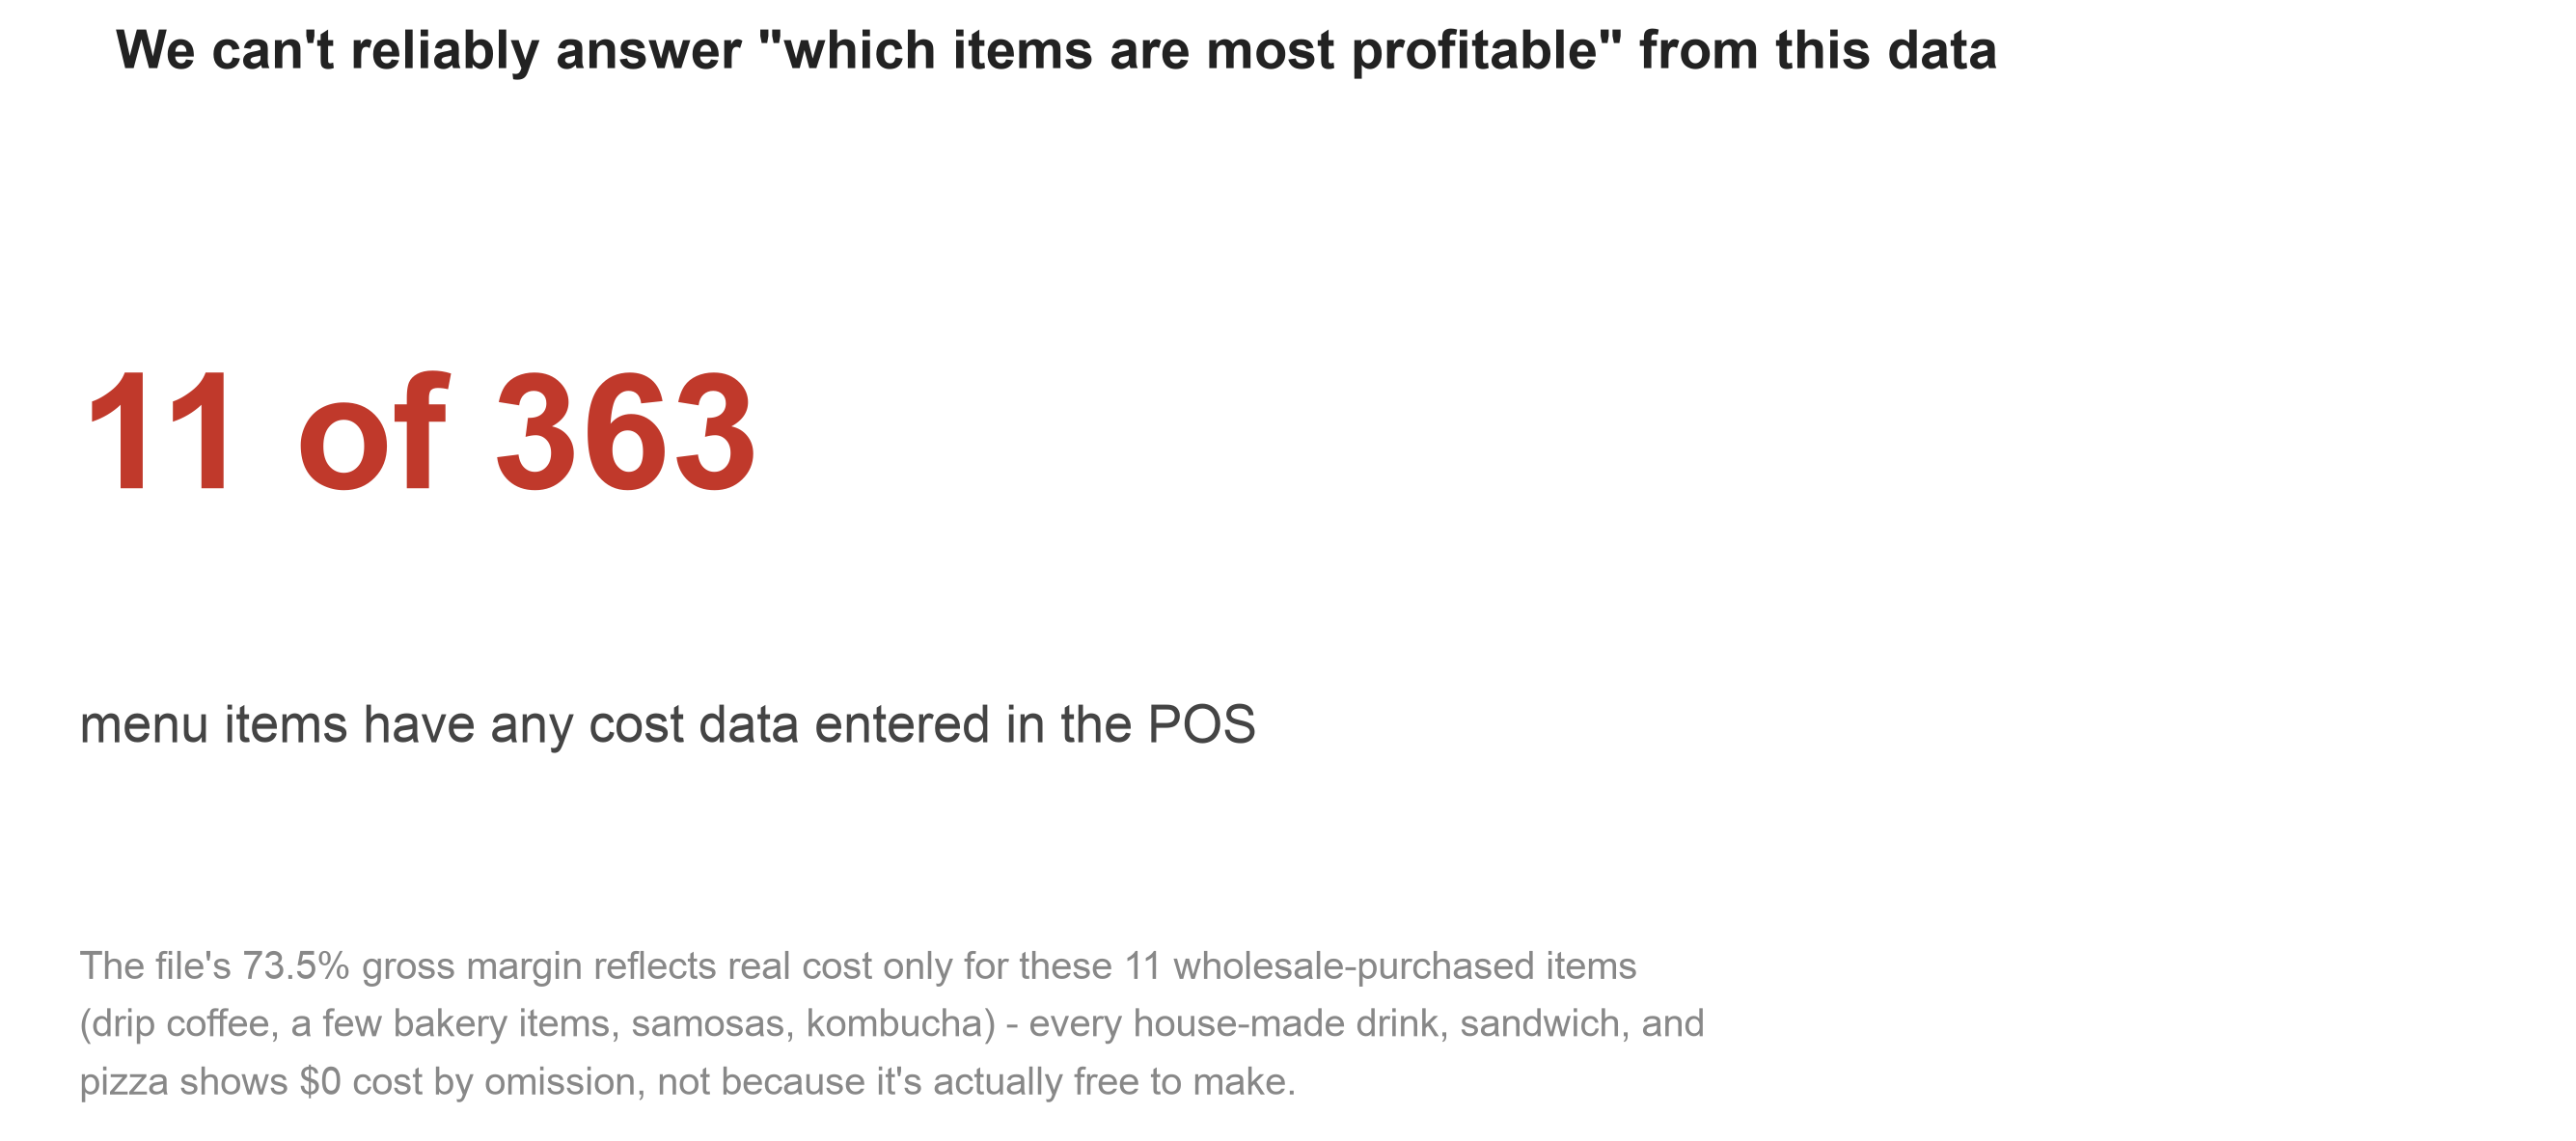

In [43]:
# CHART — Margin data caveat (text callout, not a real chart -- the point IS that we can't chart this)

tracked = (items_df['cogs'].fillna(0) > 0).sum()
total_items = len(items_df)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axis('off')

ax.text(0.02, 0.72, f'{tracked} of {total_items}', transform=ax.transAxes, fontsize=40,
        fontweight='bold', color=RED, ha='left', va='center')
ax.text(0.02, 0.40, 'menu items have any cost data entered in the POS', transform=ax.transAxes,
        fontsize=13, color=INK_SOFT, ha='left', va='center')
ax.text(0.02, 0.16,
        "The file's 73.5% gross margin reflects real cost only for these 11 wholesale-purchased items\n"
        "(drip coffee, a few bakery items, samosas, kombucha) - every house-made drink, sandwich, and\n"
        "pizza shows $0 cost by omission, not because it's actually free to make.",
        transform=ax.transAxes, fontsize=9.5, color=MUTED, ha='left', va='top', linespacing=1.6)

fig.suptitle("We can't reliably answer \"which items are most profitable\" from this data", x=0.05, ha='left', y=1.03,
             fontsize=13.5, fontweight='bold', color=INK)
plt.tight_layout()
save_chart(fig)
plt.show()

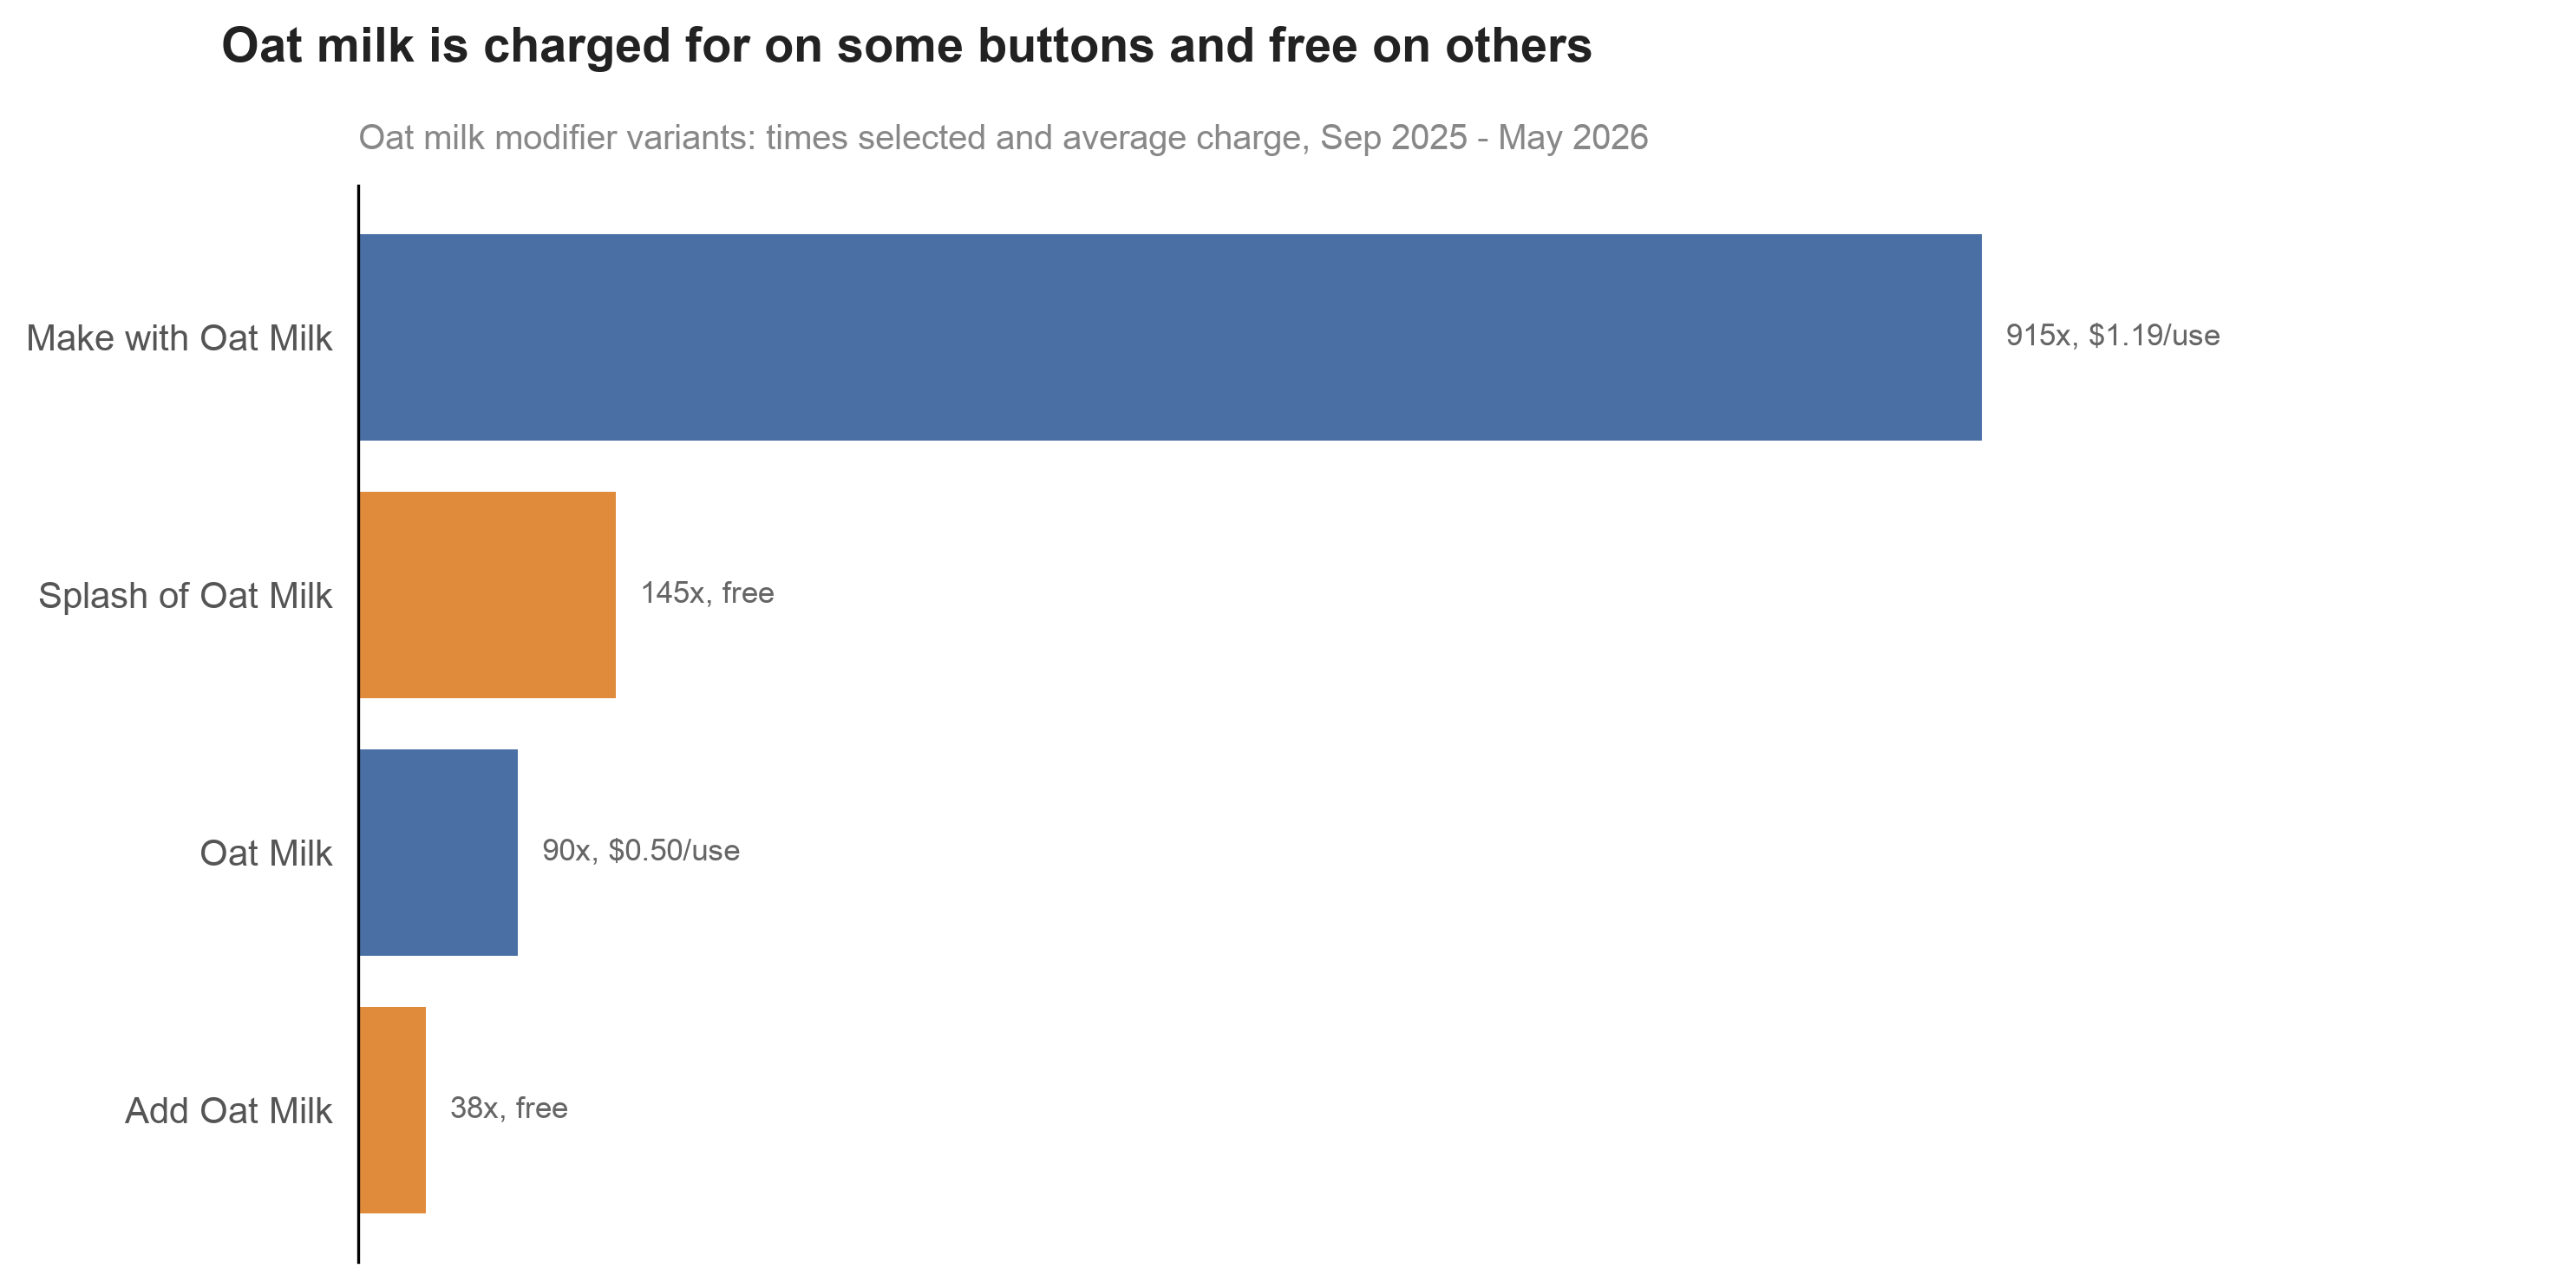

In [44]:
# CHART — Oat milk is priced inconsistently across modifier buttons

oat = mods_df[mods_df['modifier_name'].str.contains('oat milk', case=False, na=False)].copy()
oat_roll = oat.groupby('modifier_name').agg(times_selected=('modifier_sold', 'sum'), revenue=('modifier_amount', 'sum'))
oat_roll['avg_charge'] = oat_roll['revenue'] / oat_roll['times_selected']
oat_roll = oat_roll.sort_values('times_selected', ascending=True)

colors = [ORANGE if v == 0 else BLUE for v in oat_roll['avg_charge']]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(oat_roll.index, oat_roll['times_selected'], color=colors)

for y, (name, row) in enumerate(oat_roll.iterrows()):
    charge_label = f"${row['avg_charge']:.2f}/use" if row['avg_charge'] > 0 else 'free'
    ax.text(row['times_selected'] + oat_roll['times_selected'].max() * 0.015, y,
            f"{int(row['times_selected'])}x, {charge_label}", va='center', fontsize=8.5, color=LABEL)

fig.suptitle('Oat milk is charged for on some buttons and free on others', x=0.09, ha='left', y=0.98,
             fontsize=13.5, fontweight='bold', color=INK)
ax.set_title('Oat milk modifier variants: times selected and average charge, Sep 2025 - May 2026',
             loc='left', fontsize=9.5, color=MUTED, pad=10)
ax.set_xlim(0, oat_roll['times_selected'].max() * 1.35)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()

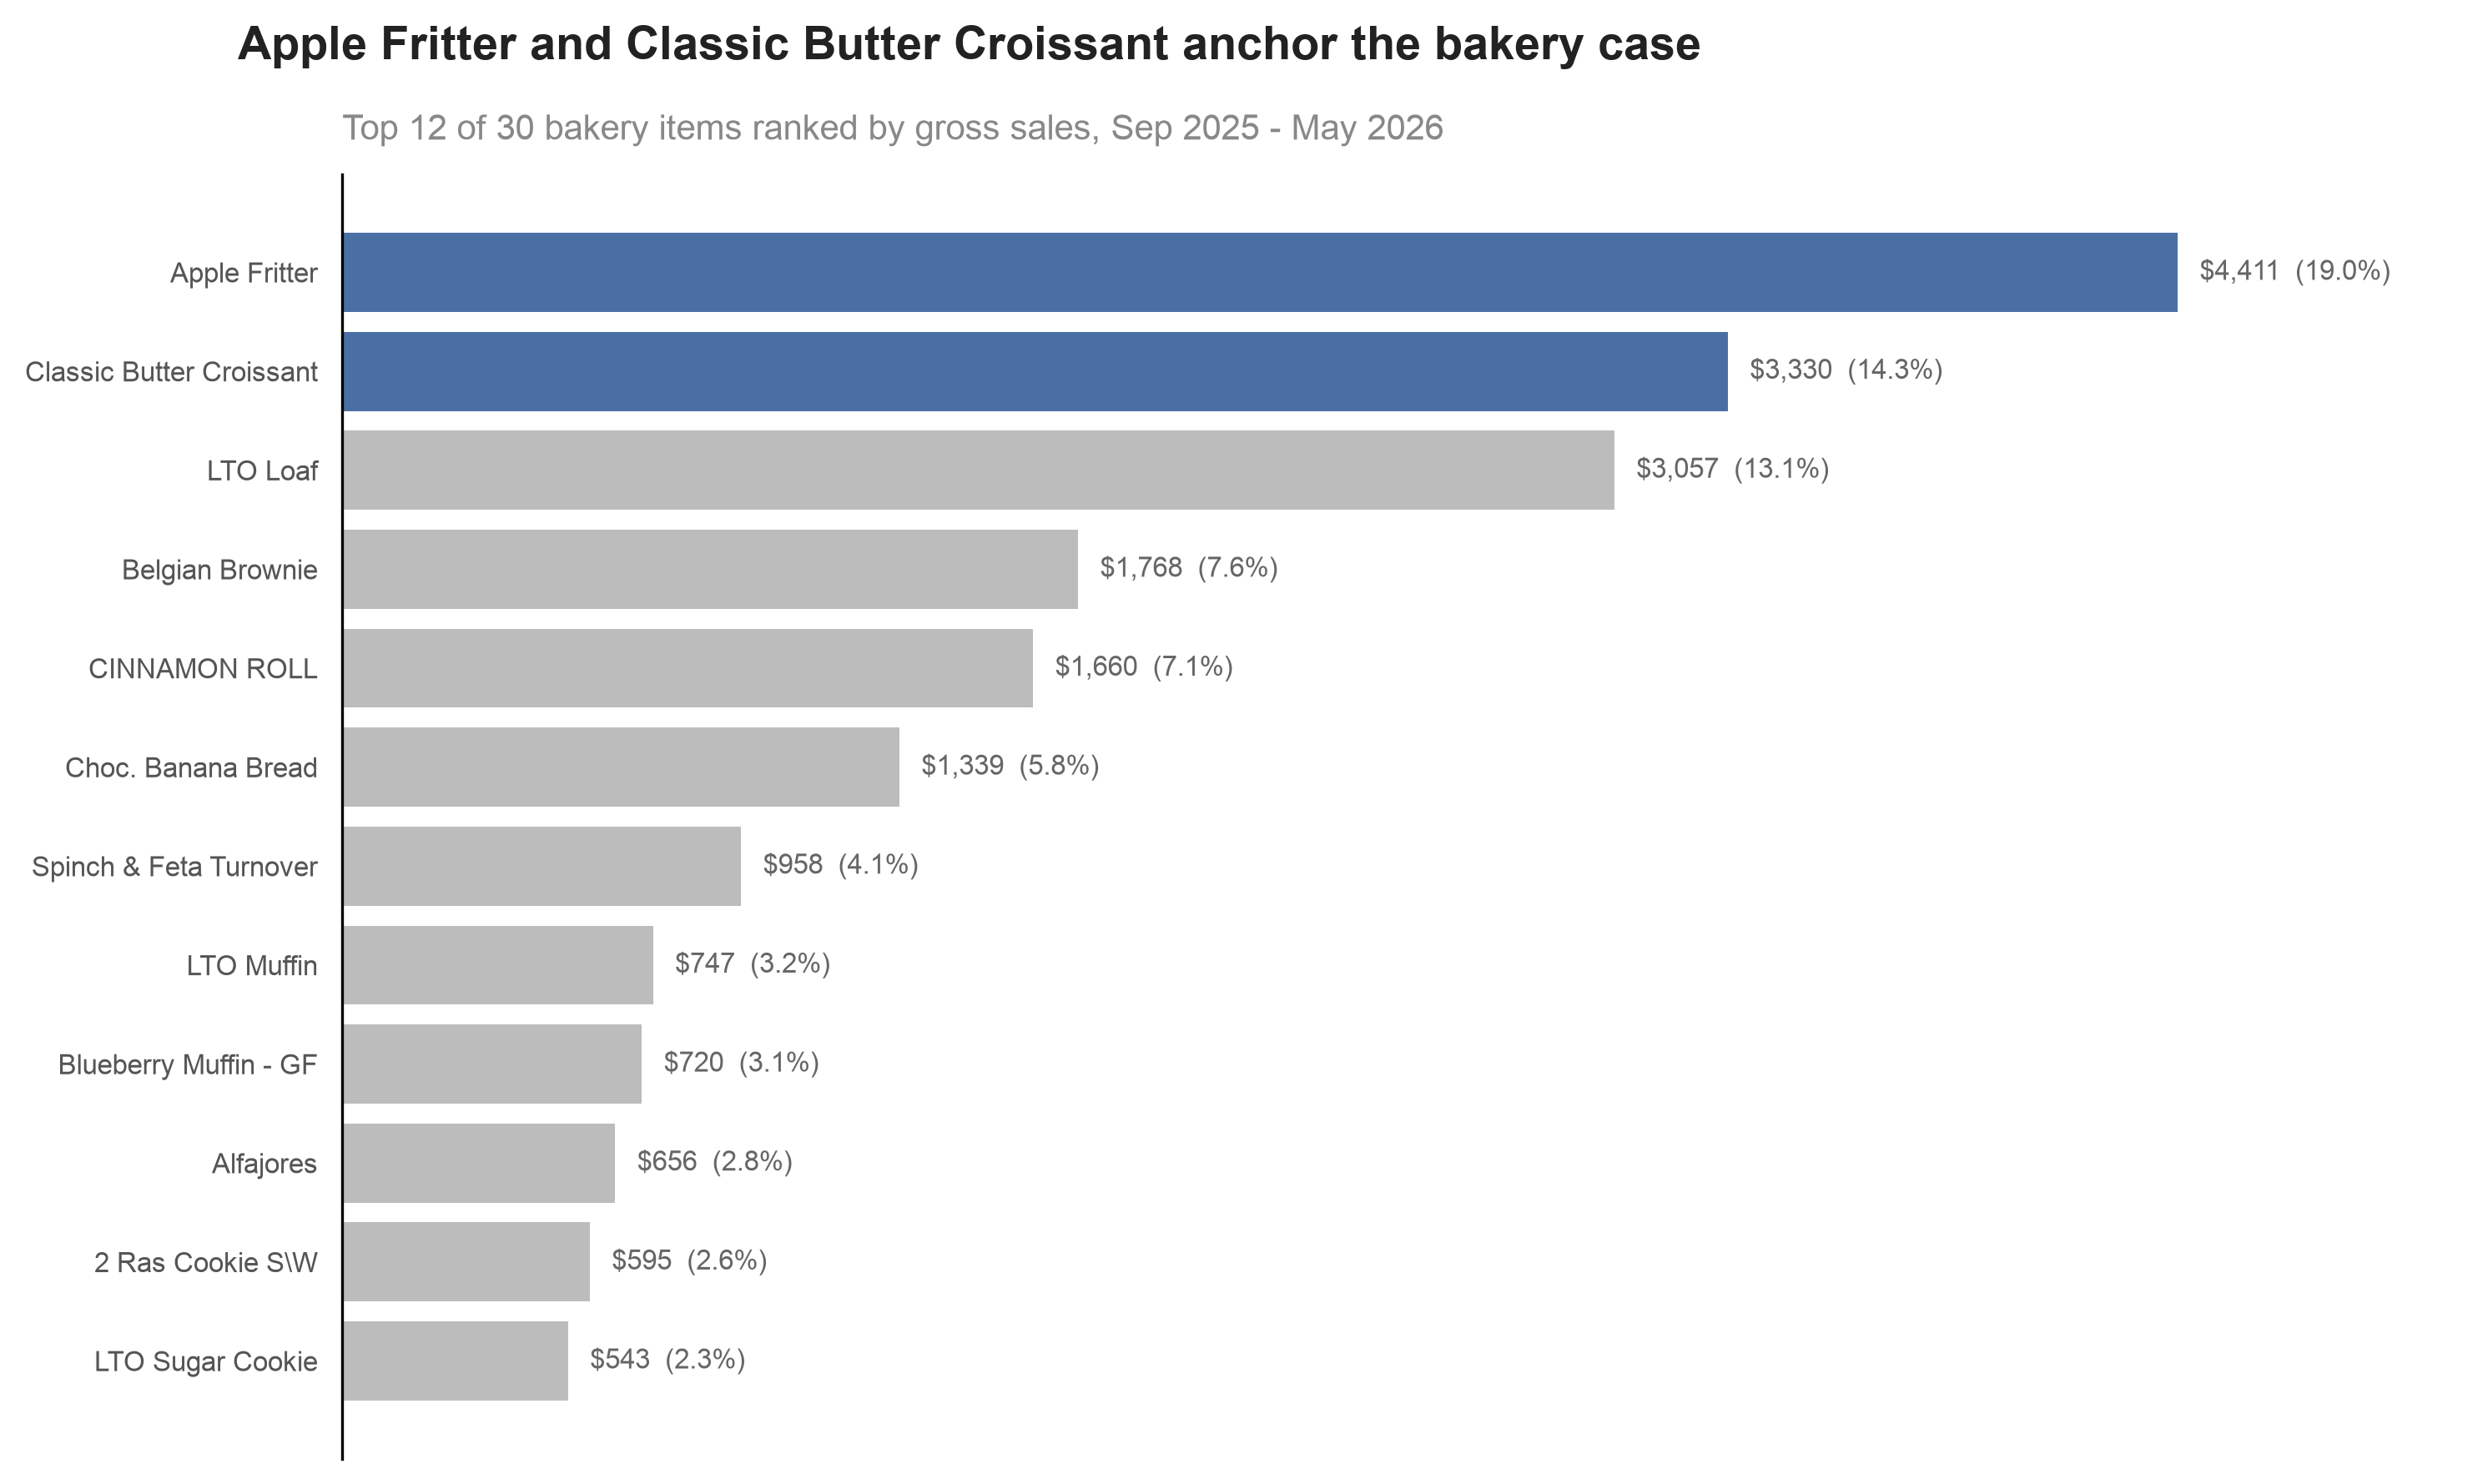

In [45]:
# CHART — Bakery item performance (rotating items)

N = 12
bakery_full = items_df[items_df['category'] == 'Bakery']
bakery_total = bakery_full['gross_sales'].sum()
top2_bakery = bakery_full.nlargest(2, 'gross_sales')['name']
bakery = bakery_full.nlargest(N, 'gross_sales').sort_values('gross_sales', ascending=True)

colors = [BLUE if n in top2_bakery.values else GREY_BAR for n in bakery['name']]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(bakery['name'], bakery['gross_sales'], color=colors)

for y, (n, v) in enumerate(zip(bakery['name'], bakery['gross_sales'])):
    pct = v / bakery_total * 100
    ax.text(v + bakery['gross_sales'].max() * 0.012, y, f'${v:,.0f}  ({pct:.1f}%)', va='center', fontsize=8, color=LABEL)

fig.suptitle('Apple Fritter and Classic Butter Croissant anchor the bakery case', x=0.1, ha='left', y=0.98,
             fontsize=13.5, fontweight='bold', color=INK)
ax.set_title(f'Top {N} of {bakery_full.shape[0]} bakery items ranked by gross sales, Sep 2025 - May 2026',
             loc='left', fontsize=10, color=MUTED, pad=10)
ax.set_xlim(0, bakery['gross_sales'].max() * 1.15)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
    lbl.set_fontsize(8)
plt.tight_layout()
save_chart(fig)
plt.show()


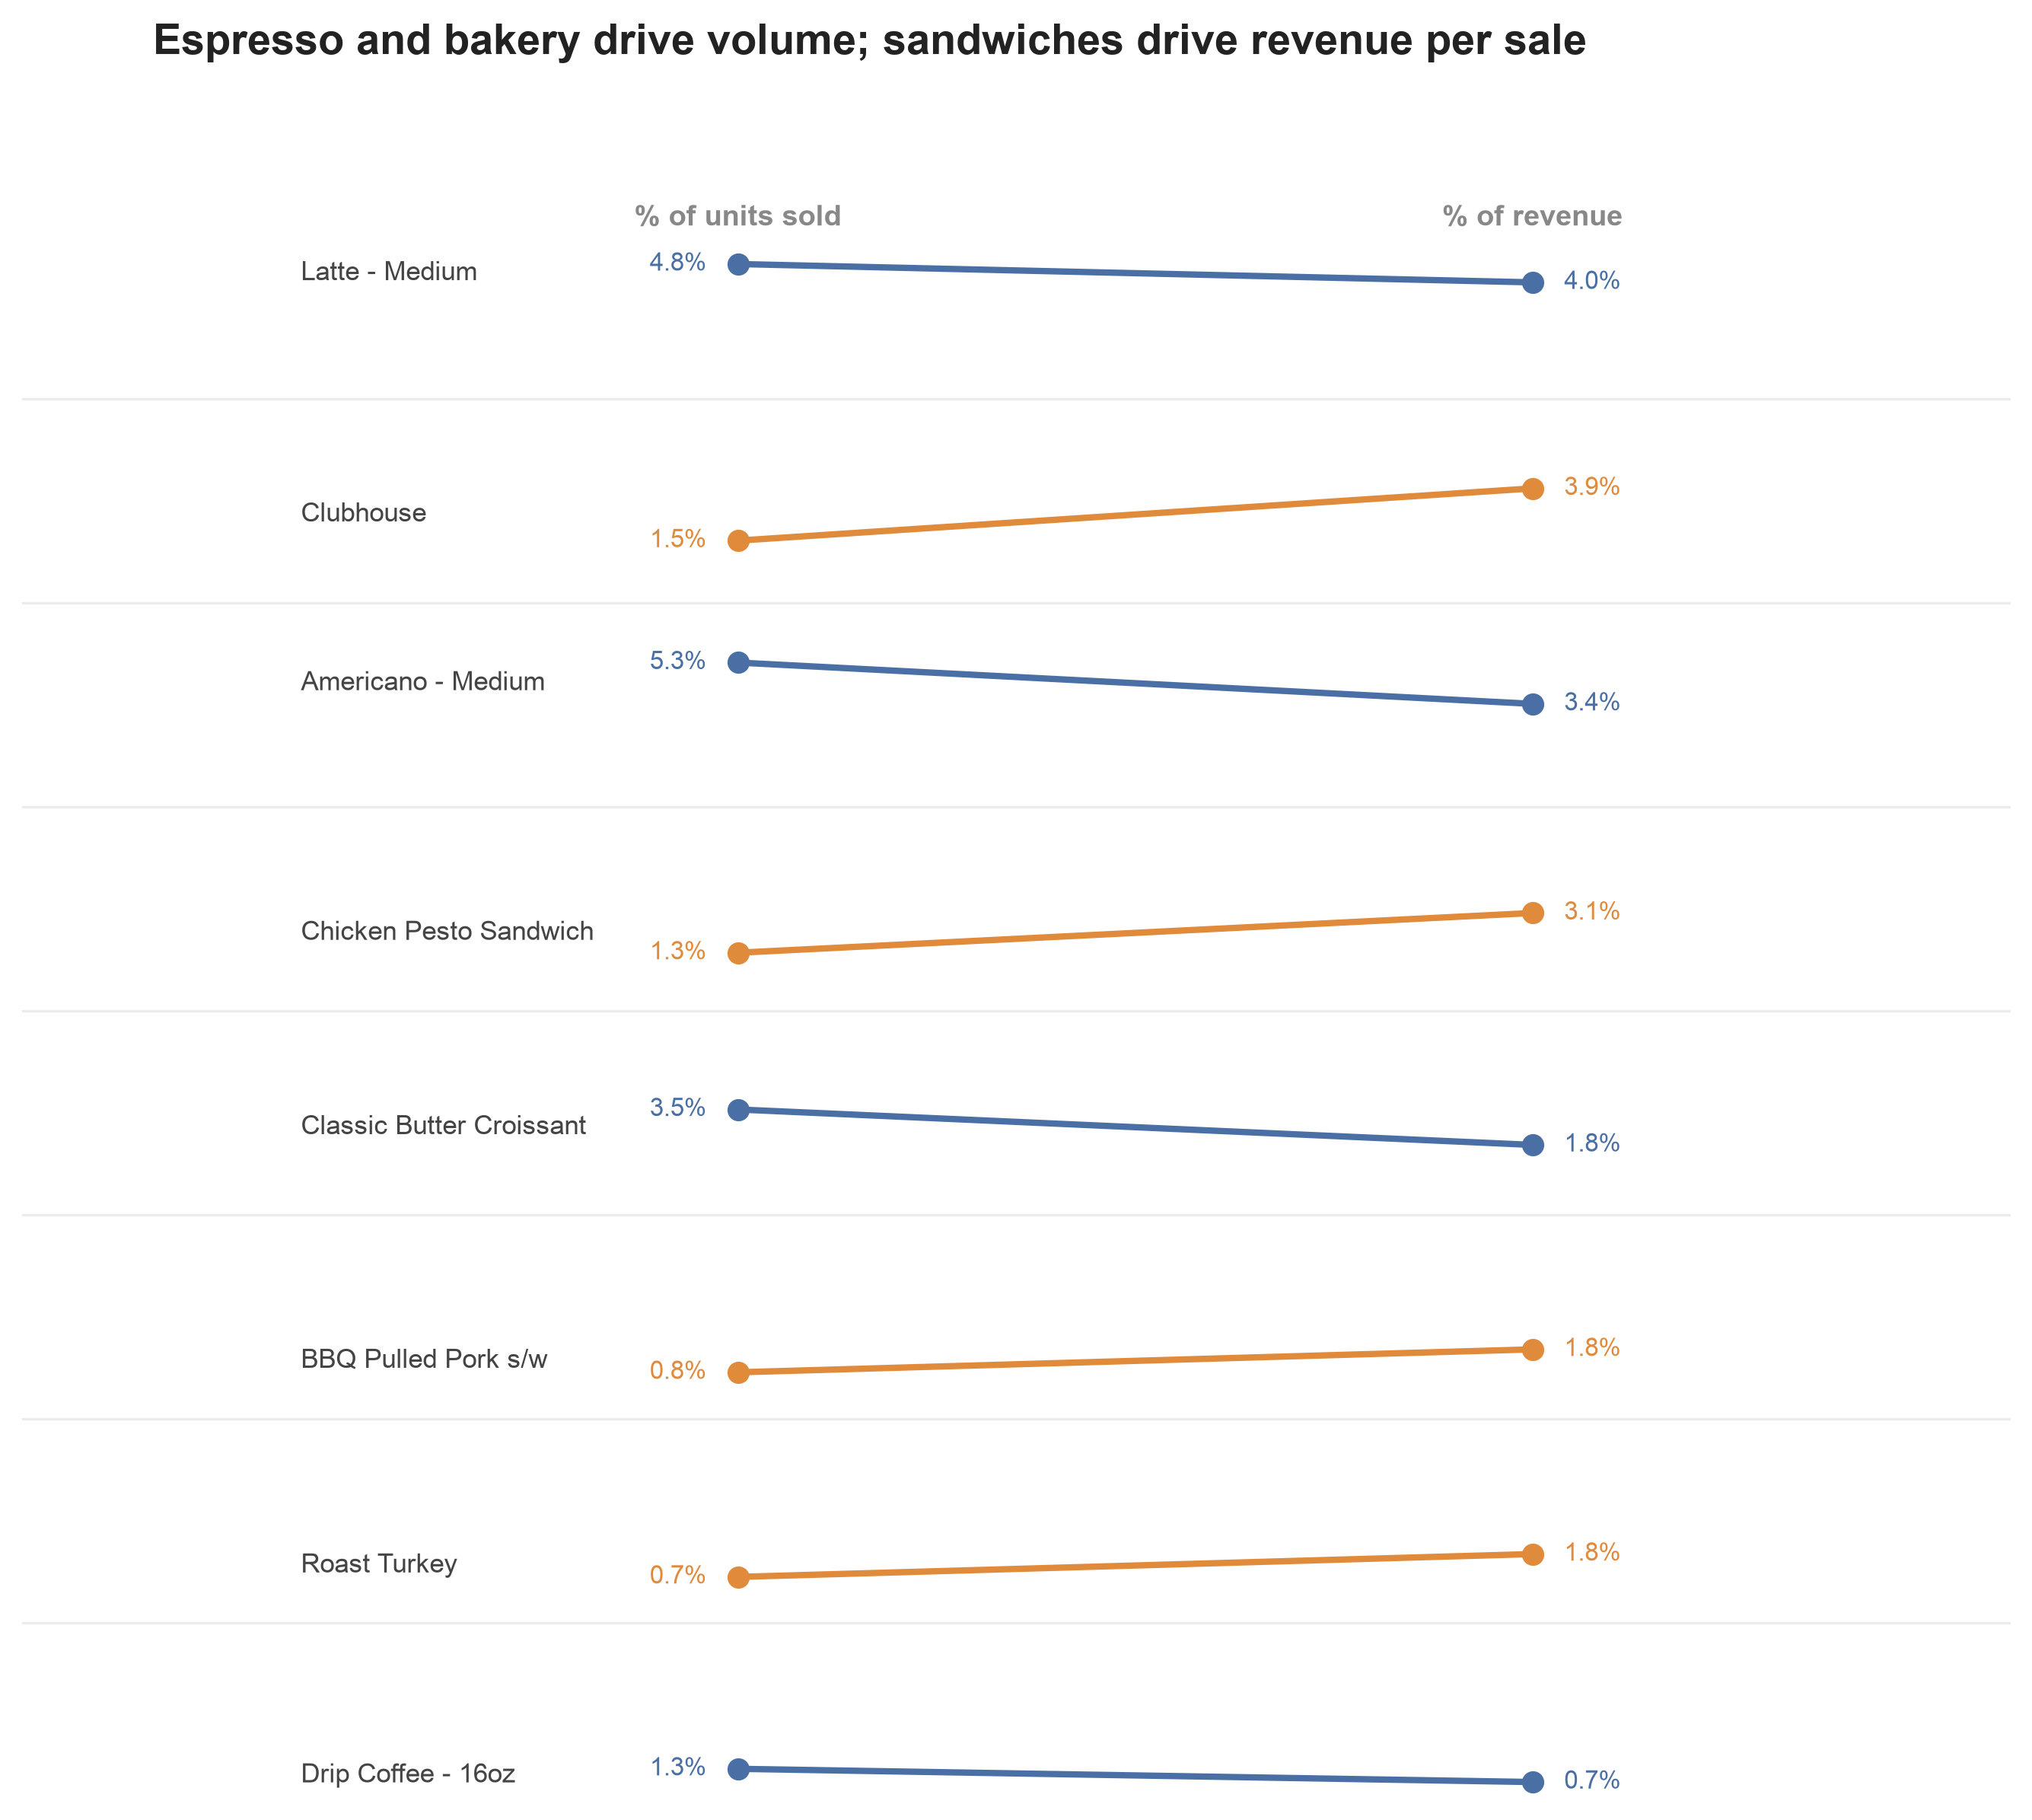

In [46]:
# CHART — Units sold vs revenue share diverge for some items

EXCL_DIVERGE = NON_MENU_CATEGORIES | {'Uncategorized'}
real_items = items_df[
    ~items_df['category'].isin(EXCL_DIVERGE) & (items_df['name'] != 'Custom Item') & (items_df['sold'] > 0)
].copy()
real_items['pct_rev'] = real_items['gross_sales'] / real_items['gross_sales'].sum() * 100
real_items['pct_units'] = real_items['sold'] / real_items['sold'].sum() * 100

focus_items = ['Americano - Medium', 'Latte - Medium', 'Classic Butter Croissant', 'Drip Coffee - 16oz',
               'Clubhouse', 'Chicken Pesto Sandwich', 'BBQ Pulled Pork s/w', 'Roast Turkey']
mix = real_items.set_index('name').loc[focus_items, ['pct_units', 'pct_rev']]
mix.columns = ['Units', 'Revenue']

order = mix.sort_values('Revenue', ascending=False).index
n = len(order)
ymax = max(mix['Units'].max(), mix['Revenue'].max()) * 1.2
VOLUME_DRIVERS = {'Americano - Medium', 'Latte - Medium', 'Classic Butter Croissant', 'Drip Coffee - 16oz'}

fig, axes = plt.subplots(n, 1, figsize=(9, 1.0 * n), sharex=True, sharey=True)
for i, (ax, item) in enumerate(zip(axes, order)):
    u, r = mix.loc[item, 'Units'], mix.loc[item, 'Revenue']
    c = BLUE if item in VOLUME_DRIVERS else ORANGE
    ax.plot([0, 1], [u, r], color=c, marker='o', markersize=6, lw=2)
    ax.text(-0.04, u, f'{u:.1f}%', ha='right', va='center', fontsize=8, color=c)
    ax.text(1.04, r, f'{r:.1f}%', ha='left', va='center', fontsize=8, color=c)
    ax.text(-0.55, (u + r) / 2, item, ha='left', va='center', fontsize=8.5, color=INK_SOFT)
    ax.set_xlim(-0.9, 1.6)
    ax.set_ylim(0, ymax)
    ax.axis('off')
    if i < n - 1:
        ax.plot([0, 1], [-0.22, -0.22], transform=ax.transAxes, color='#ececec', lw=0.8, clip_on=False)

axes[0].text(0, ymax, '% of units sold', ha='center', va='bottom', fontsize=9, fontweight='bold', color=MUTED)
axes[0].text(1, ymax, '% of revenue', ha='center', va='bottom', fontsize=9, fontweight='bold', color=MUTED)

fig.suptitle('Espresso and bakery drive volume; sandwiches drive revenue per sale', x=0.08, ha='left', y=0.99,
             fontsize=13.5, fontweight='bold', color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_chart(fig)
plt.show()

                         Units    Revenue
category                                 
Basic Espresso       30.143720  22.432858
Sandwiches            8.306603  18.699081
Bakery               23.770048  13.497938
Large Pizzas          2.020412   7.591056
Personal Pizzas       2.657780   6.796112
Light Bites           4.932306   6.027780
Speciality Espresso   5.707144   5.498775
Iced Coffee Drinks    5.852947   5.192050
Tea                   5.690481   4.645785


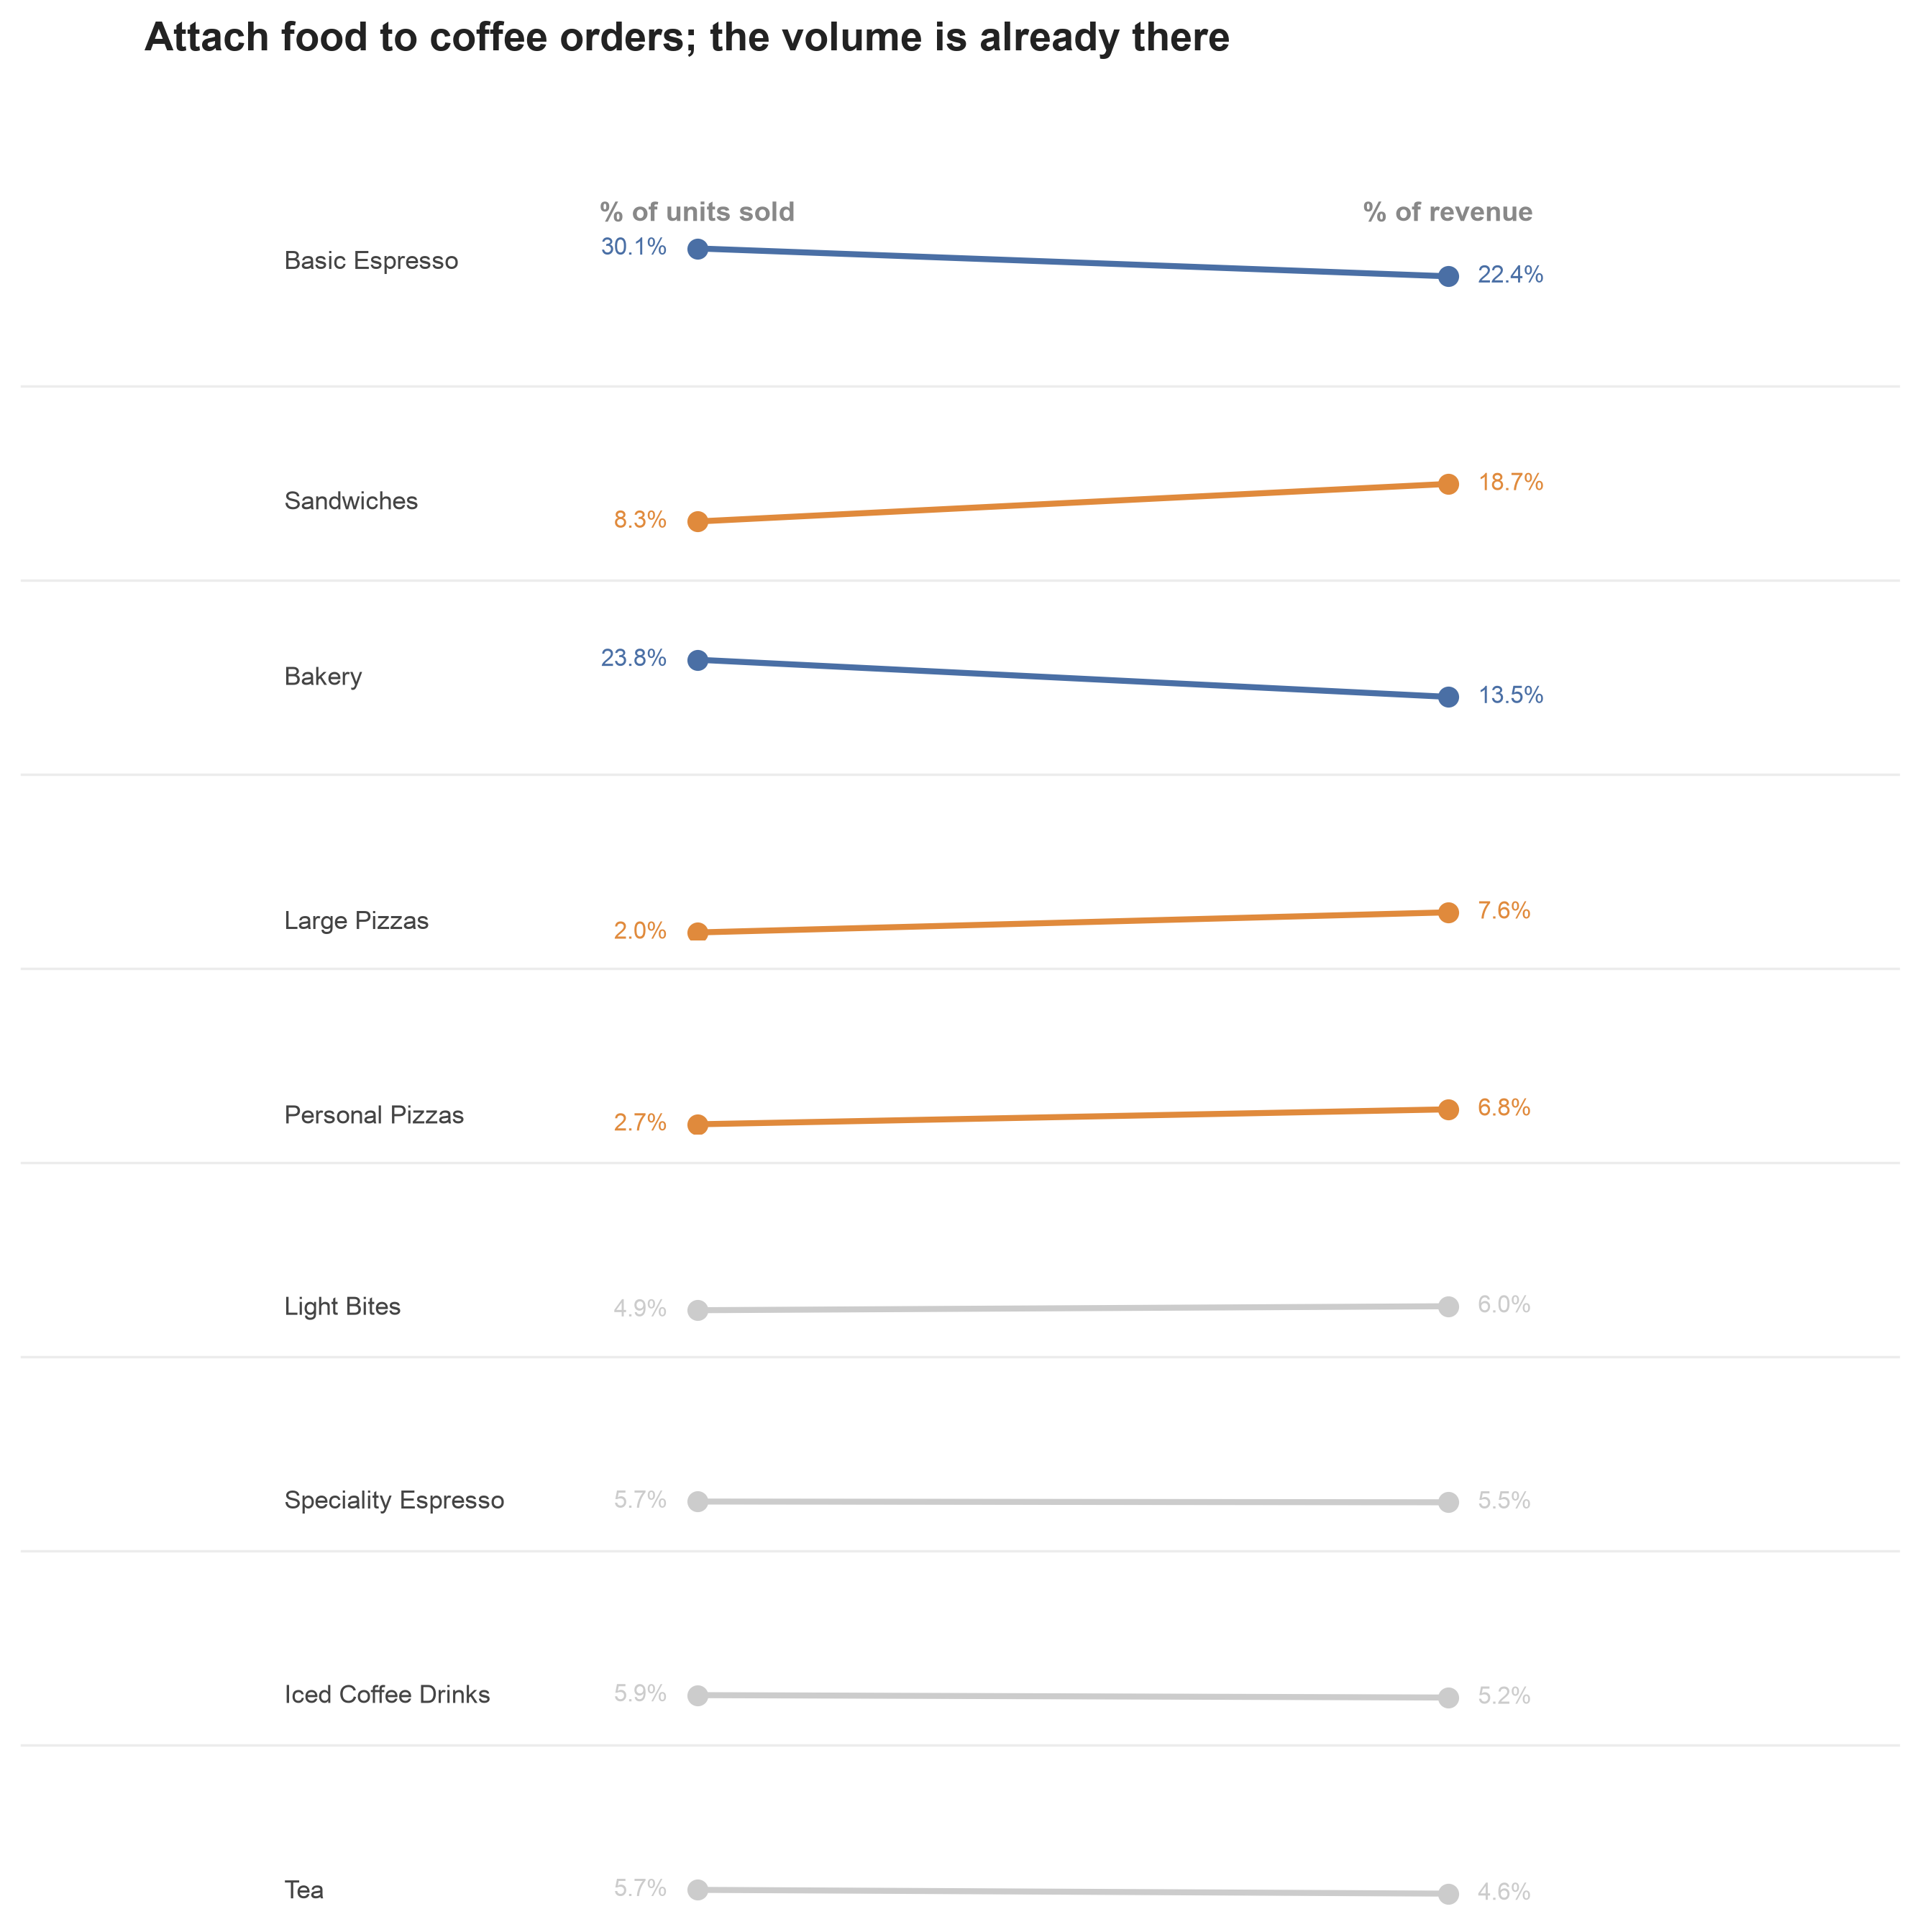

In [47]:
# CHART -- Category-level: units sold vs revenue share diverge

EXCL_DIVERGE_CAT = NON_MENU_CATEGORIES | {'Uncategorized', 'Retail Drinks', 'Retail Items', 'Merch Retail', 'Barista Comp Drinks'}
cat_items = items_df[
    ~items_df['category'].isin(EXCL_DIVERGE_CAT) & (items_df['name'] != 'Custom Item') & (items_df['sold'] > 0)
].copy()

cat_agg = cat_items.groupby('category').agg(sold=('sold', 'sum'), gross_sales=('gross_sales', 'sum'))
cat_agg['pct_units'] = cat_agg['sold'] / cat_items['sold'].sum() * 100
cat_agg['pct_rev'] = cat_agg['gross_sales'] / cat_items['gross_sales'].sum() * 100

N = 9
top_categories = cat_agg.sort_values('gross_sales', ascending=False).head(N)
mix = top_categories[['pct_units', 'pct_rev']]
mix.columns = ['Units', 'Revenue']
print(mix)

order = mix.sort_values('Revenue', ascending=False).index
n = len(order)
ymax = max(mix['Units'].max(), mix['Revenue'].max()) * 1.2

VOLUME_DRIVER_CATS = {'Basic Espresso', 'Bakery'}
REVENUE_DRIVER_CATS = {'Sandwiches', 'Large Pizzas', 'Personal Pizzas'}

fig, axes = plt.subplots(n, 1, figsize=(9, 1.0 * n), sharex=True, sharey=True)
for i, (ax, cat) in enumerate(zip(axes, order)):
    u, r = mix.loc[cat, 'Units'], mix.loc[cat, 'Revenue']
    if cat in VOLUME_DRIVER_CATS:
        c = BLUE
    elif cat in REVENUE_DRIVER_CATS:
        c = ORANGE
    else:
        c = GREY_LINE
    ax.plot([0, 1], [u, r], color=c, marker='o', markersize=6, lw=2)
    ax.text(-0.04, u, f'{u:.1f}%', ha='right', va='center', fontsize=8, color=c)
    ax.text(1.04, r, f'{r:.1f}%', ha='left', va='center', fontsize=8, color=c)
    ax.text(-0.55, (u + r) / 2, cat, ha='left', va='center', fontsize=8.5, color=INK_SOFT)
    ax.set_xlim(-0.9, 1.6)
    ax.set_ylim(0, ymax)
    ax.axis('off')
    if i < n - 1:
        ax.plot([0, 1], [-0.22, -0.22], transform=ax.transAxes, color='#ececec', lw=0.8, clip_on=False)

axes[0].text(0, ymax, '% of units sold', ha='center', va='bottom', fontsize=9, fontweight='bold', color=MUTED)
axes[0].text(1, ymax, '% of revenue', ha='center', va='bottom', fontsize=9, fontweight='bold', color=MUTED)

fig.suptitle('Attach food to coffee orders; the volume is already there', x=0.08, ha='left', y=0.99,
             fontsize=13.5, fontweight='bold', color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_chart(fig)
plt.show()


In [48]:
# Channel analysis setup -- order_type is the real channel field.
print(orders['order_type'].value_counts(dropna=False))
print()

nan_type = orders[orders['order_type'].isna()]
print('order_type is NaN for', len(nan_type), 'rows;', nan_type['is_catering'].sum(), 'of them are catering orders')


order_type
To Go              9744
Dine In            3547
In-store Pickup     106
NaN                  31
Name: count, dtype: int64

order_type is NaN for 31 rows; 7 of them are catering orders


**Channel finding:** in the raw export, an `order_number` value of "ECOMM ORDER" turned out NOT to be a customer-facing online-ordering channel. Only 3 rows had it (a large catering order, a $50 gift voucher sale and a $25 gift card sale), and it appears to mark orders created manually outside the normal POS flow. That column is not part of the published data. `order_type` (Dine In / To Go / In-store Pickup) is the only trustworthy channel field. The 31 rows with no `order_type` are mostly the catering orders (7, all identifiable from notes) plus 24 genuinely unlabeled rows, grouped below as "Unspecified / manual entry" rather than guessed at.


                              revenue  orders_n  pct_orders    pct_rev
channel                                                               
To Go                       121497.65      9744   72.564790  63.804663
Dine In                      63264.89      3547   26.414954  33.223647
Unspecified / manual entry    3388.44        31    0.230861   1.779444
In-store Pickup               2270.29       106    0.789395   1.192246


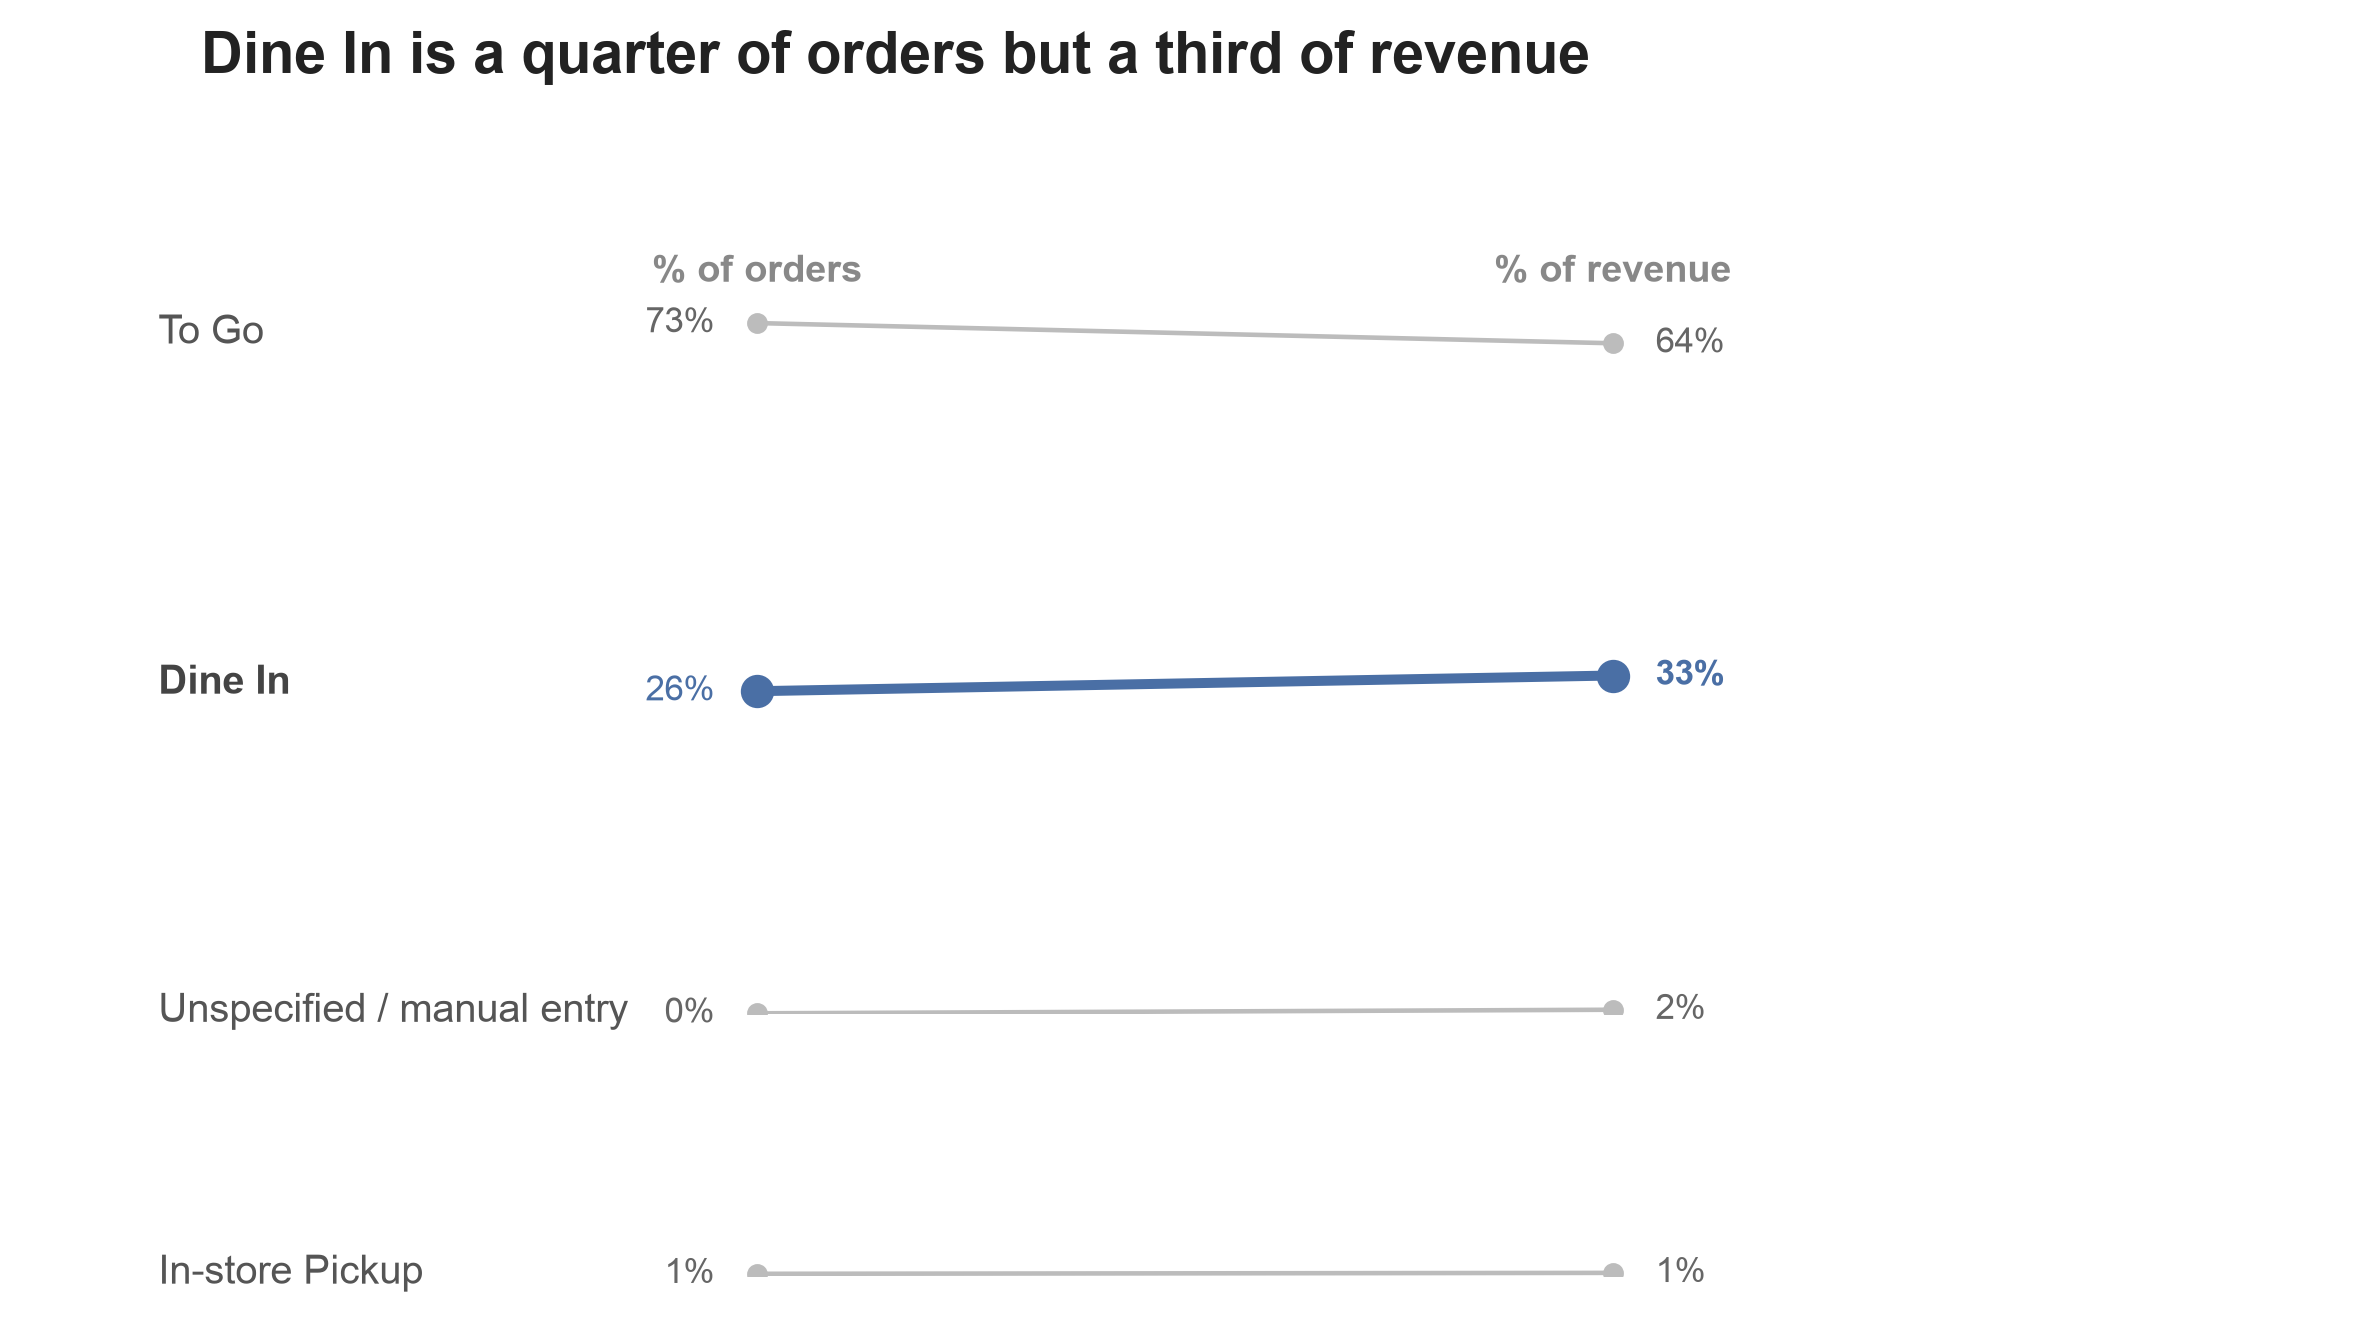

In [49]:
# CHART — Channel share: Dine In punches above its weight on revenue

orders['channel'] = orders['order_type'].fillna('Unspecified / manual entry')
chan = orders.groupby('channel').agg(revenue=('revenue', 'sum'), orders_n=('revenue', 'size'))
chan['pct_orders'] = chan['orders_n'] / chan['orders_n'].sum() * 100
chan['pct_rev'] = chan['revenue'] / chan['revenue'].sum() * 100
chan = chan.sort_values('pct_rev', ascending=False)

print(chan)

FOCUS_CHANNEL = 'Dine In'
n = len(chan)
ymax = max(chan['pct_orders'].max(), chan['pct_rev'].max()) * 1.2

fig, axes = plt.subplots(n, 1, figsize=(8, 1.1 * n), sharex=True, sharey=True)
for i, (ax, ch) in enumerate(zip(axes, chan.index)):
    u, r = chan.loc[ch, 'pct_orders'], chan.loc[ch, 'pct_rev']
    focus = ch == FOCUS_CHANNEL
    c = BLUE if focus else GREY_BAR
    ax.plot([0, 1], [u, r], color=c, marker='o', markersize=7 if focus else 4, lw=2.4 if focus else 1.1)
    ax.text(-0.05, u, f'{u:.0f}%', ha='right', va='center', fontsize=8.5, color=c if focus else LABEL)
    ax.text(1.05, r, f'{r:.0f}%', ha='left', va='center', fontsize=8.5,
            color=c if focus else LABEL, fontweight='bold' if focus else 'normal')
    ax.text(-0.7, (u + r) / 2, ch, ha='left', va='center', fontsize=9.5,
            color=INK_SOFT if focus else TICK, fontweight='bold' if focus else 'normal')
    ax.set_xlim(-0.85, 1.85)
    ax.set_ylim(0, ymax)
    ax.axis('off')

axes[0].text(0, ymax, '% of orders', ha='center', va='bottom', fontsize=9, fontweight='bold', color=MUTED)
axes[0].text(1, ymax, '% of revenue', ha='center', va='bottom', fontsize=9, fontweight='bold', color=MUTED)

fig.suptitle('Dine In is a quarter of orders but a third of revenue', x=0.09, ha='left', y=0.99,
             fontsize=14, fontweight='bold', color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.93])
save_chart(fig)
plt.show()

In [50]:
# Additional pattern -- the recurring municipal-office catering client

city_hall = orders[orders['is_repeat_client_catering']].sort_values('order_date')
print(city_hall[['order_date', 'revenue']])
print()
print('total revenue:', city_hall['revenue'].sum())
print('% of total revenue:', city_hall['revenue'].sum() / orders['revenue'].sum() * 100)
print('order count:', len(city_hall))
print('span:', city_hall['order_date'].min(), 'to', city_hall['order_date'].max())

               order_date  revenue
1057  2025-09-26 09:00:00   353.33
2539  2025-10-30 15:00:00   353.33
6150  2026-01-24 11:00:00   416.10
7809  2026-02-26 12:00:00   380.94
10158 2026-04-10 15:00:00   396.17
11668 2026-05-04 11:00:00   437.48

total revenue: 2337.3500000000004
% of total revenue: 1.2274626673795423
order count: 6
span: 2025-09-26 09:00:00 to 2026-05-04 11:00:00


## Phase 4 — Combined Insights (honest scope check)

**What's genuinely NOT possible with these two files, and why:** `revenue-items-sale.csv` is a single 9-month *aggregate* per item — no date, no order ID, no per-transaction link back to `orders`. `orders` has no line-item detail — we know an order happened and for how much, not *what* was in it. There is no shared key between the two files. That means questions like "do evening hours sell a different item mix than daytime" or "do bakery items overperform on weekends" **cannot be answered from this data** — not a matter of more analysis effort, the join key doesn't exist. Worth saying this directly to the owner rather than forcing a shaky answer.

**What IS possible — aggregate-level cross-checks, already done above:**
- Revenue reconciliation: `orders['revenue'].sum()` ($190,421) vs. items file gross sales ($186,165) — a ~2.3% gap, consistent with gross-vs-net/discount-timing differences between the two POS reports, not a data-loss red flag.
- A rough magnitude check on catering: `orders`-side catering-flagged revenue is $2,713 (7 orders, note-identified); the items file's "Custom Item" bucket (manually-priced one-off entries) totals $4,632 across 43 rows. These are **not the same set** — Custom Item includes other one-off manual prices beyond catering — so this is a plausibility check only ("catering-sized manual entries do show up on both sides, in the right ballpark"), not a confirmed row-level match. Don't present this as more precise than it is.

**Bottom line:** the two datasets triangulate well at the total-revenue level (Question 4/5 numbers are mutually consistent), but genuine "combined" item-behavior insights aren't available from this data. If that cross-tab (item × time) is something the owner wants going forward, it would need a POS export with line-item detail per order — worth mentioning as a data-collection recommendation, not just an analysis gap.

## One-sentence recommendation per question (Phase 4 deliverable)

1. **Menu items** — Protect the core anchors (Lattes, the Clubhouse, Apple Fritter, Classic Butter Croissant), and fix the oat-milk modifier pricing inconsistency — ~1,188 selections charged inconsistently across 6 near-duplicate buttons is a concrete, low-effort revenue leak worth closing in the POS setup.

2. **Peak hours** — Staff explicitly for Saturday 11am-1pm and Sunday 12-1pm, the two actual highest-revenue windows of the week, not just "weekends" in the abstract.

3. **Evening extension** - 5-8pm is about 26% of open hours but only 9% of revenue and 7% of orders, and the growth was already under way before the extension. Consider closing earlier by weekday (5pm Mon/Tue/Thu, 6pm Wed/Sun, 7pm Fri/Sat). Closing early saves real payroll mainly on Friday and Saturday, since owners cover most of the last hour on other days.

4. **Revenue trend** — Revenue is up 82% since September; the acceleration from December onward coincides with the evening extension, so don't credit the extension alone for growth that's also organic under new ownership — and don't panic if a future month dips the way December did (holiday closures, not a warning sign).

5. **Average order value** — $14.18 overall ($13.99 excluding catering/gift cards); Sunday's average order is both growing fastest (+12.6%) and among the largest, while Friday's is shrinking (-9.4%) despite more traffic — worth a closer look at what's different about the Friday order mix.

6. **Additional pattern** — Formalize the repeat municipal-office catering relationship: 6 orders over 9 months, growing 24% in size, ~$2,337 total — worth a standing arrangement or light outreach to comparable local offices, since it's a proven, repeatable relationship rather than a one-off.

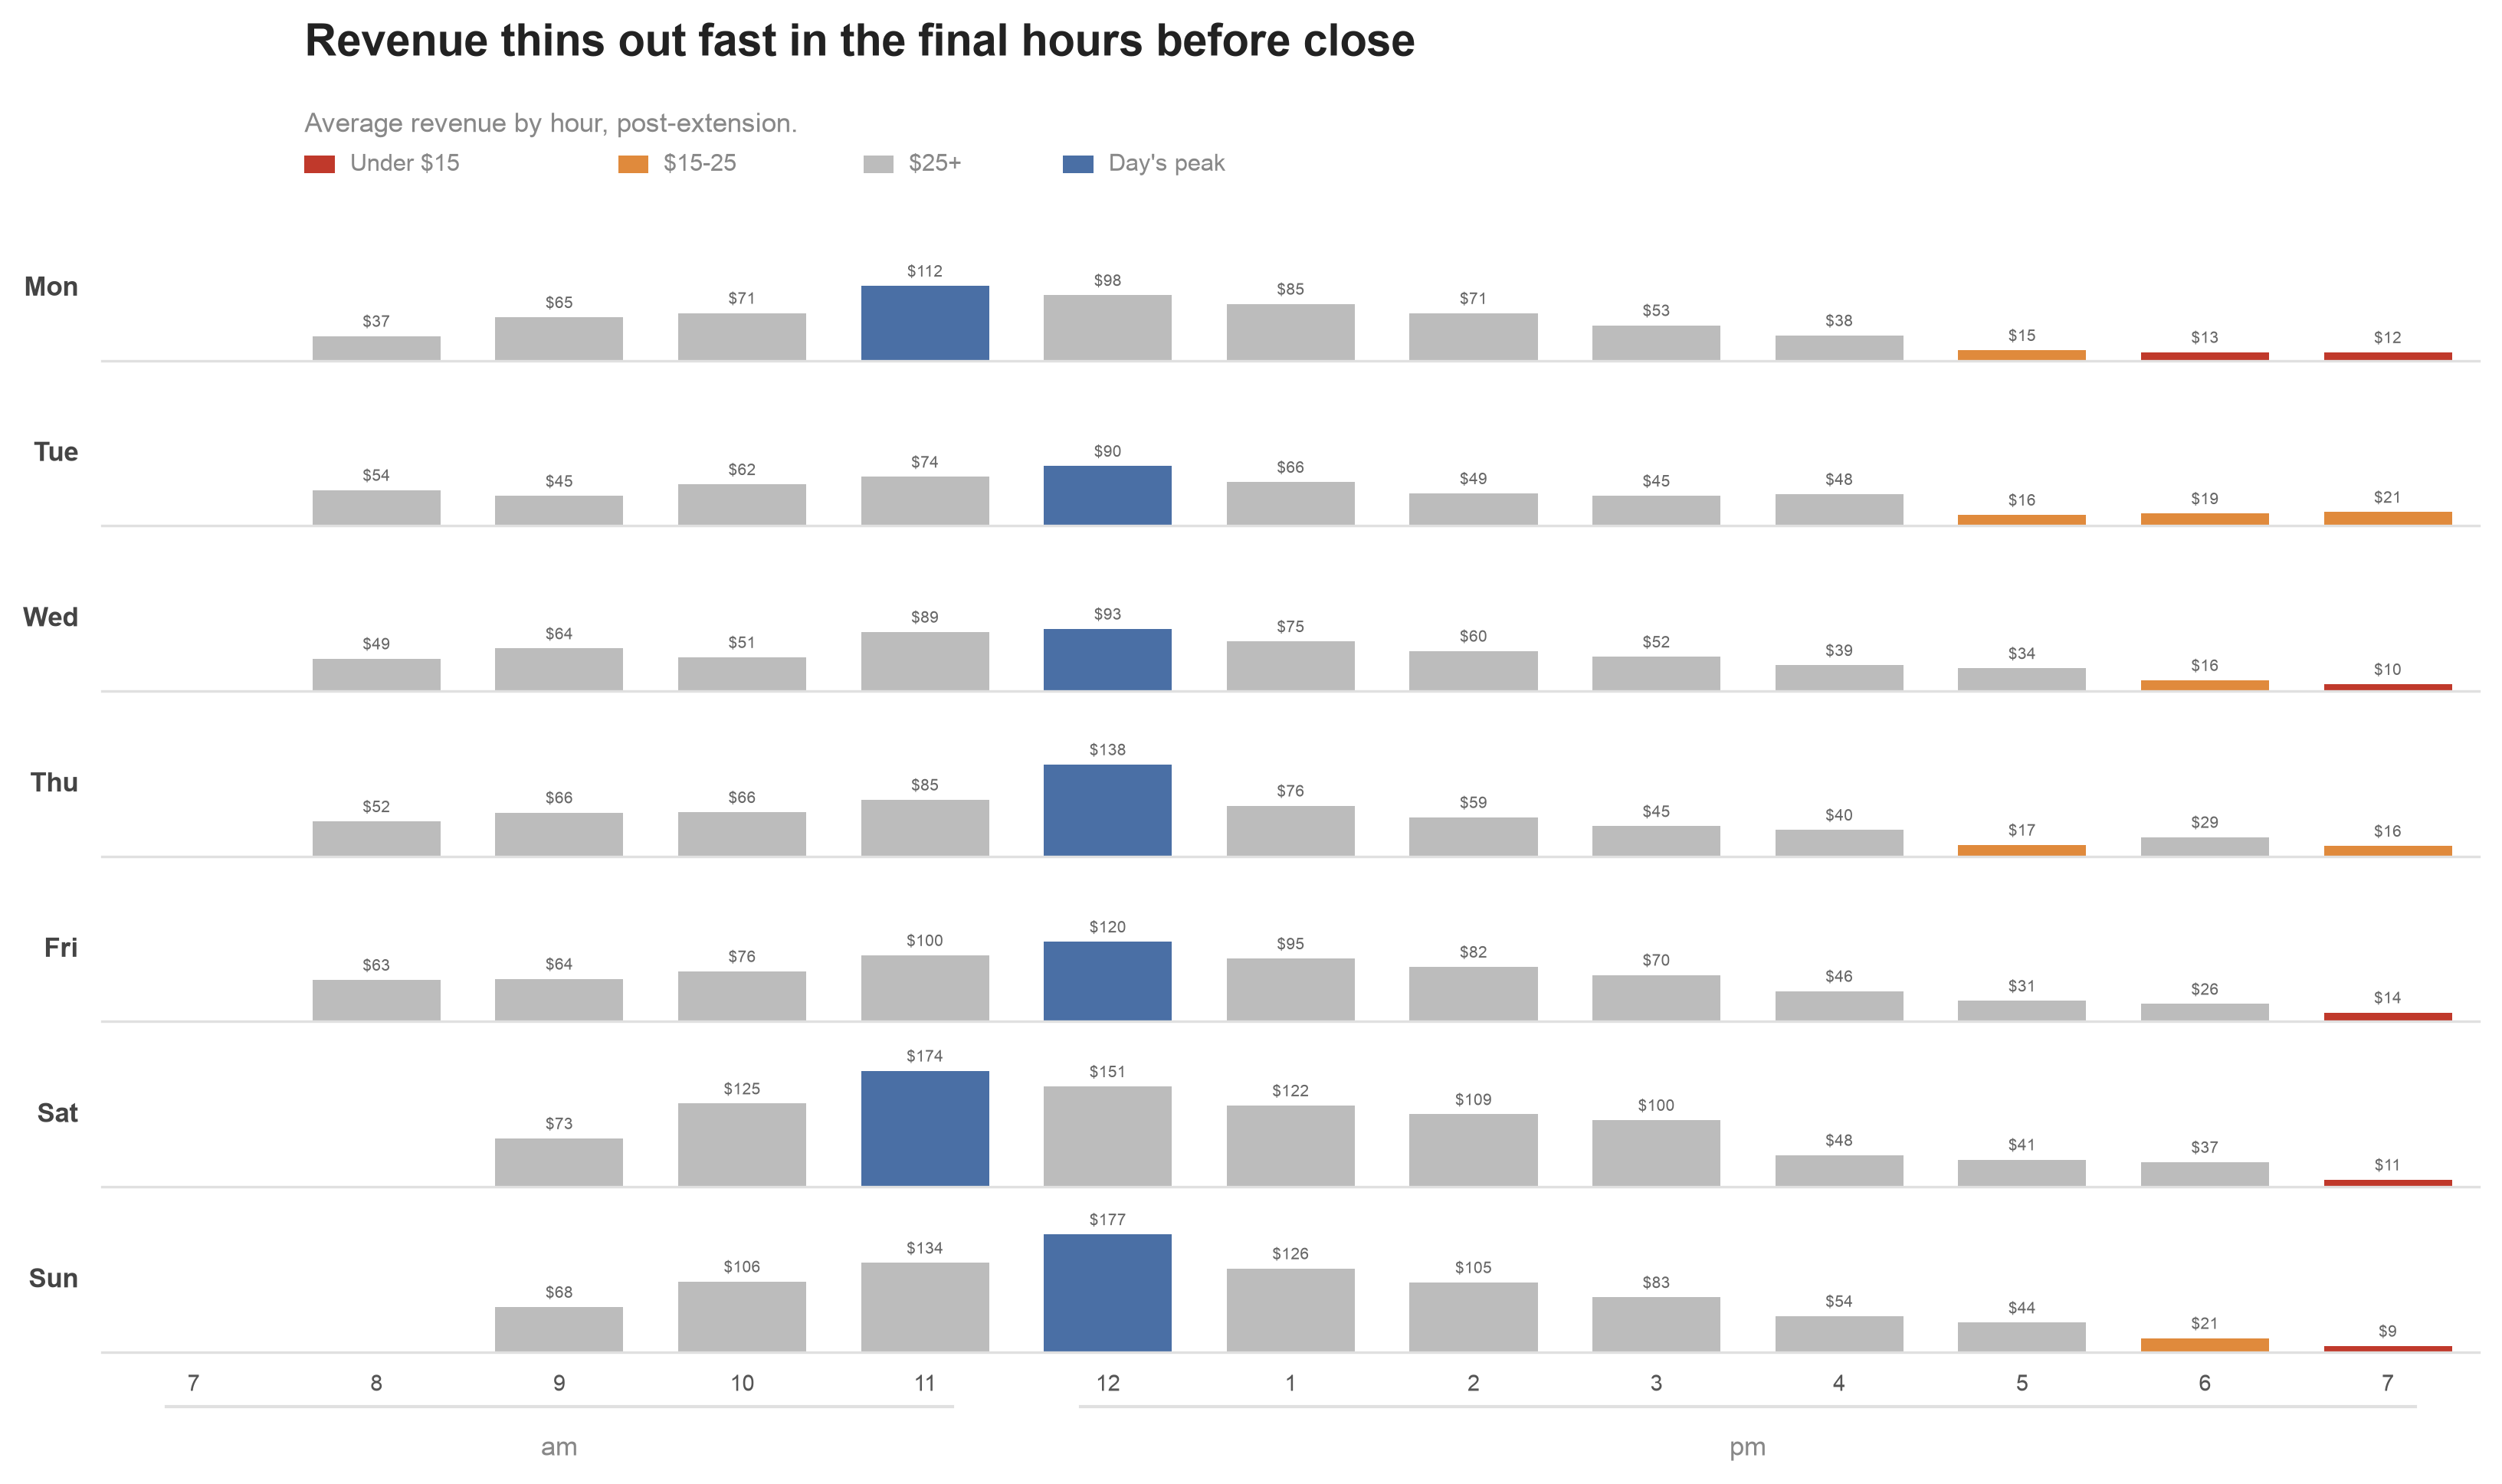

In [51]:
# CHART — Hour-by-hour revenue, faceted by day of week (post-extension): which hours are worth a second look?

def tier_color(v):
    if v < 15:
        return RED
    elif v < 25:
        return ORANGE
    return GREY_BAR


fig, axes = plt.subplots(7, 1, figsize=(11, 6.5), sharex=True)

day_max = hourly_dow_revenue_post.max().max()

for ax, day in zip(axes, days):
    row = hourly_dow_revenue_post.loc[day].dropna()
    open_hours = row.index.tolist()

    colors = [tier_color(v) for v in row.values]
    peak_idx = int(row.values.argmax())
    colors[peak_idx] = BLUE

    ax.bar(open_hours, row.values, color=colors, width=0.7, zorder=2)
    ax.set_ylim(0, day_max * 1.22)
    ax.set_xlim(6.5, 19.5)

    for h, v in row.items():
        ax.text(h, v + day_max * 0.05, f"${v:.0f}", ha="center", va="bottom", fontsize=5, color=LABEL)

    ax.text(-0.01, 0.5, day[:3], transform=ax.transAxes, ha="right", va="center",
            fontsize=8.5, color=INK_SOFT, fontweight="bold")
    ax.set_yticks([])
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(bottom=False)

all_hours_list = list(range(7, 20))
hour_labels = [str(h if h <= 12 else h - 12) for h in all_hours_list]
axes[-1].set_xticks(all_hours_list)
axes[-1].set_xticklabels(hour_labels, fontsize=7, color=TICK)

# axes[-1] is one of 7 stacked rows, so it's much shorter than the single
# full-height axes add_year_axis_groups was tuned for -- the default
# axes-fraction offsets land right on top of the tick numbers here, so this
# draws the same am/pm bracket with offsets scaled for this axes' height.
for label, x0, x1 in [('am', all_hours_list[0], 11), ('pm', 12, all_hours_list[-1])]:
    xm = (x0 + x1) / 2
    axes[-1].plot([x0 - 0.15, x1 + 0.15], [-0.38, -0.38], transform=axes[-1].get_xaxis_transform(),
                  color=AXIS, lw=1, clip_on=False)
    axes[-1].text(xm, -0.58, label, transform=axes[-1].get_xaxis_transform(), ha='center', va='top',
                  fontsize=8.5, color=MUTED)

fig.suptitle("Revenue thins out fast in the final hours before close", x=0.13, ha="left", y=1.06,
             fontsize=14, fontweight="bold", color=INK)
subtitle = "Average revenue by hour, post-extension."
fig.text(0.13, 1.0, subtitle, fontsize=8.5, color=MUTED, va="top")

legend_y = 0.965
legend_items = [(RED, 'Under $15'), (ORANGE, '$15-25'), (GREY_BAR, '$25+'), (BLUE, "Day's peak")]
lx = 0.13
for c, lbl in legend_items:
    fig.patches.append(plt.Rectangle((lx, legend_y - 0.006), 0.012, 0.012, transform=fig.transFigure,
                                      facecolor=c, edgecolor='none'))
    fig.text(lx + 0.018, legend_y, lbl, fontsize=7.5, color=MUTED, va='center')
    lx += 0.018 + 0.009 * len(lbl) + 0.025

plt.subplots_adjust(hspace=0.15, top=0.93, bottom=0.17, left=0.05, right=0.99)
save_chart(fig)
plt.show()


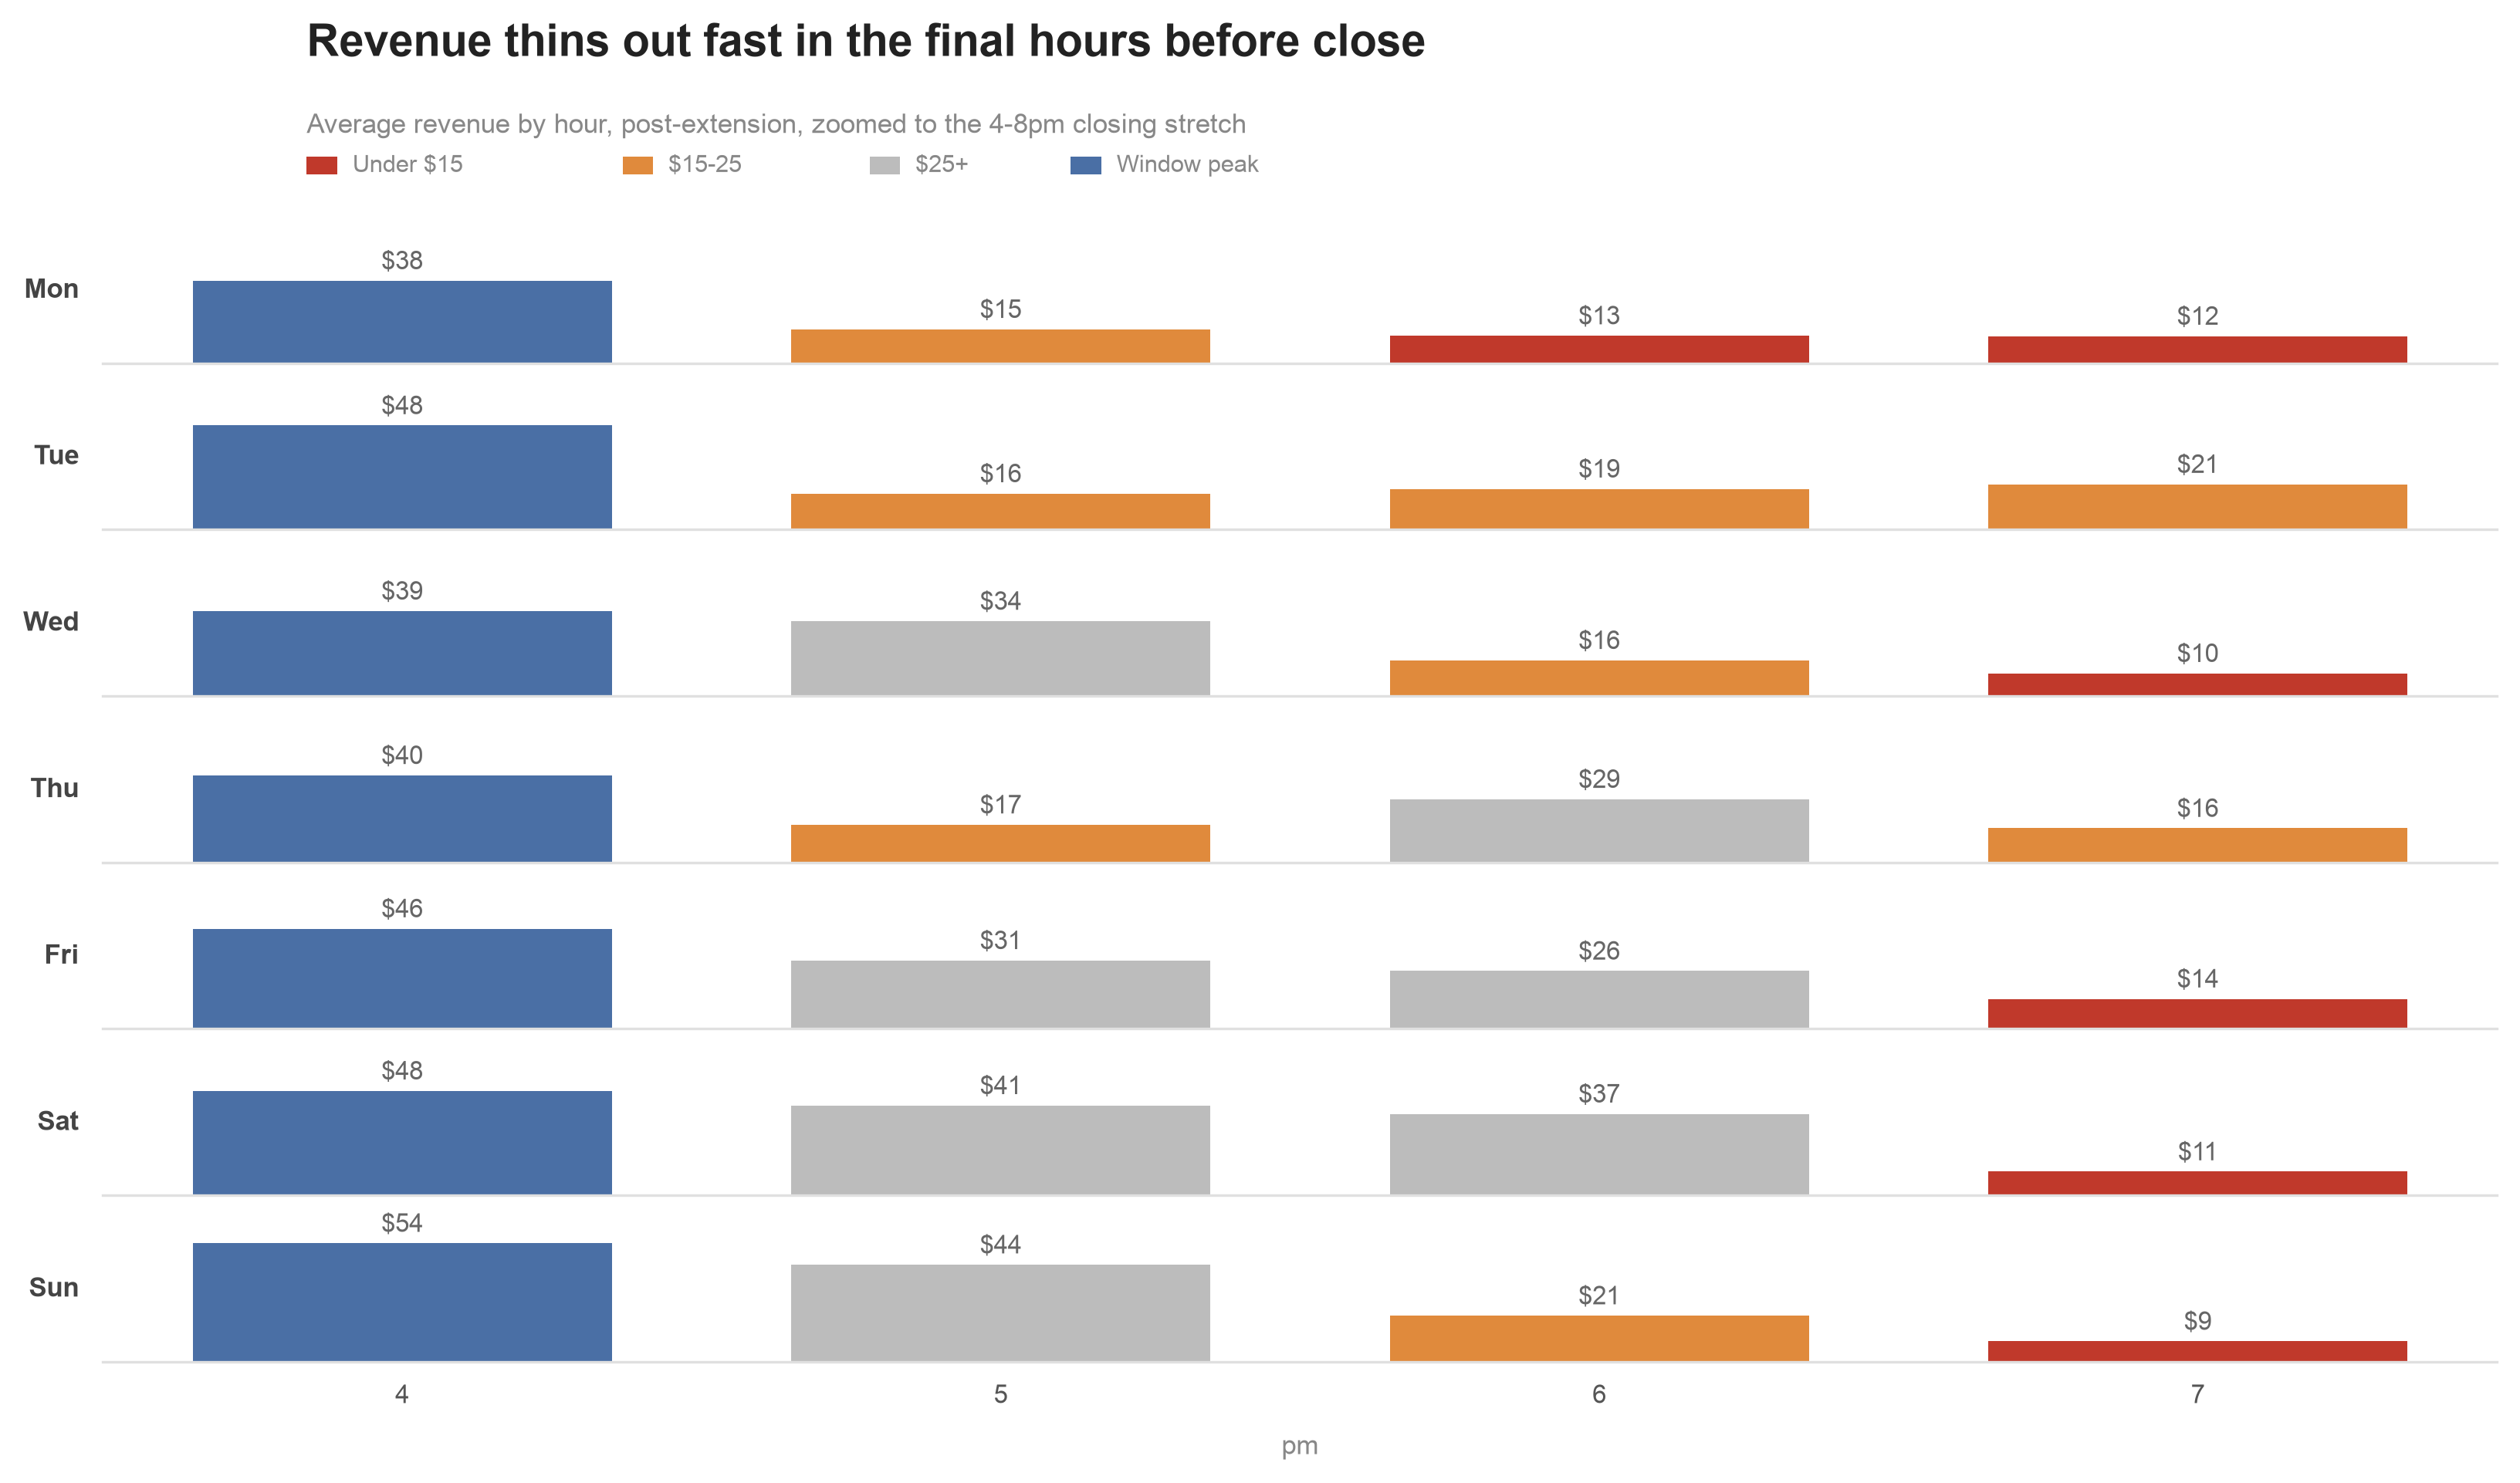

In [52]:
# CHART — Hour-by-hour revenue, faceted by day of week (post-extension): zoomed to 4-8pm

def tier_color(v):
    if v < 15:
        return RED
    elif v < 25:
        return ORANGE
    return GREY_BAR

ZOOM_HOURS = [16, 17, 18, 19]  # 4pm-8pm

fig, axes = plt.subplots(7, 1, figsize=(11, 6.5), sharex=True)

zoom_data = hourly_dow_revenue_post[ZOOM_HOURS]
day_max = zoom_data.max().max()

for ax, day in zip(axes, days):
    row = zoom_data.loc[day].dropna()
    open_hours = row.index.tolist()

    colors = [tier_color(v) for v in row.values]
    peak_idx = int(row.values.argmax())
    colors[peak_idx] = BLUE

    ax.bar(open_hours, row.values, color=colors, width=0.7, zorder=2)
    ax.set_ylim(0, day_max * 1.22)
    ax.set_xlim(15.5, 19.5)

    for h, v in row.items():
        ax.text(h, v + day_max * 0.05, f"${v:.0f}", ha="center", va="bottom", fontsize=8, color=LABEL)

    ax.text(-0.01, 0.5, day[:3], transform=ax.transAxes, ha="right", va="center",
            fontsize=8.5, color=INK_SOFT, fontweight="bold")
    ax.set_yticks([])
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(bottom=False)

axes[-1].set_xticks(ZOOM_HOURS)
axes[-1].set_xticklabels(['4', '5', '6', '7'], fontsize=8, color=TICK)
axes[-1].text(17.5, -0.5, 'pm', transform=axes[-1].get_xaxis_transform(), ha='center', va='top',
              fontsize=8.5, color=MUTED)

fig.suptitle("Revenue thins out fast in the final hours before close", x=0.13, ha="left", y=1.06,
             fontsize=14, fontweight="bold", color=INK)
subtitle = "Average revenue by hour, post-extension, zoomed to the 4-8pm closing stretch"
fig.text(0.13, 1.0, subtitle, fontsize=8.5, color=MUTED, va="top")

legend_y = 0.965
legend_items = [(RED, 'Under $15'), (ORANGE, '$15-25'), (GREY_BAR, '$25+'), (BLUE, "Window peak")]
lx = 0.13
for c, lbl in legend_items:
    fig.patches.append(plt.Rectangle((lx, legend_y - 0.006), 0.012, 0.012, transform=fig.transFigure,
                                      facecolor=c, edgecolor='none'))
    fig.text(lx + 0.018, legend_y, lbl, fontsize=7.5, color=MUTED, va='center')
    lx += 0.018 + 0.009 * len(lbl) + 0.025

plt.subplots_adjust(hspace=0.15, top=0.93, bottom=0.17, left=0.05, right=0.99)
save_chart(fig)
plt.show()


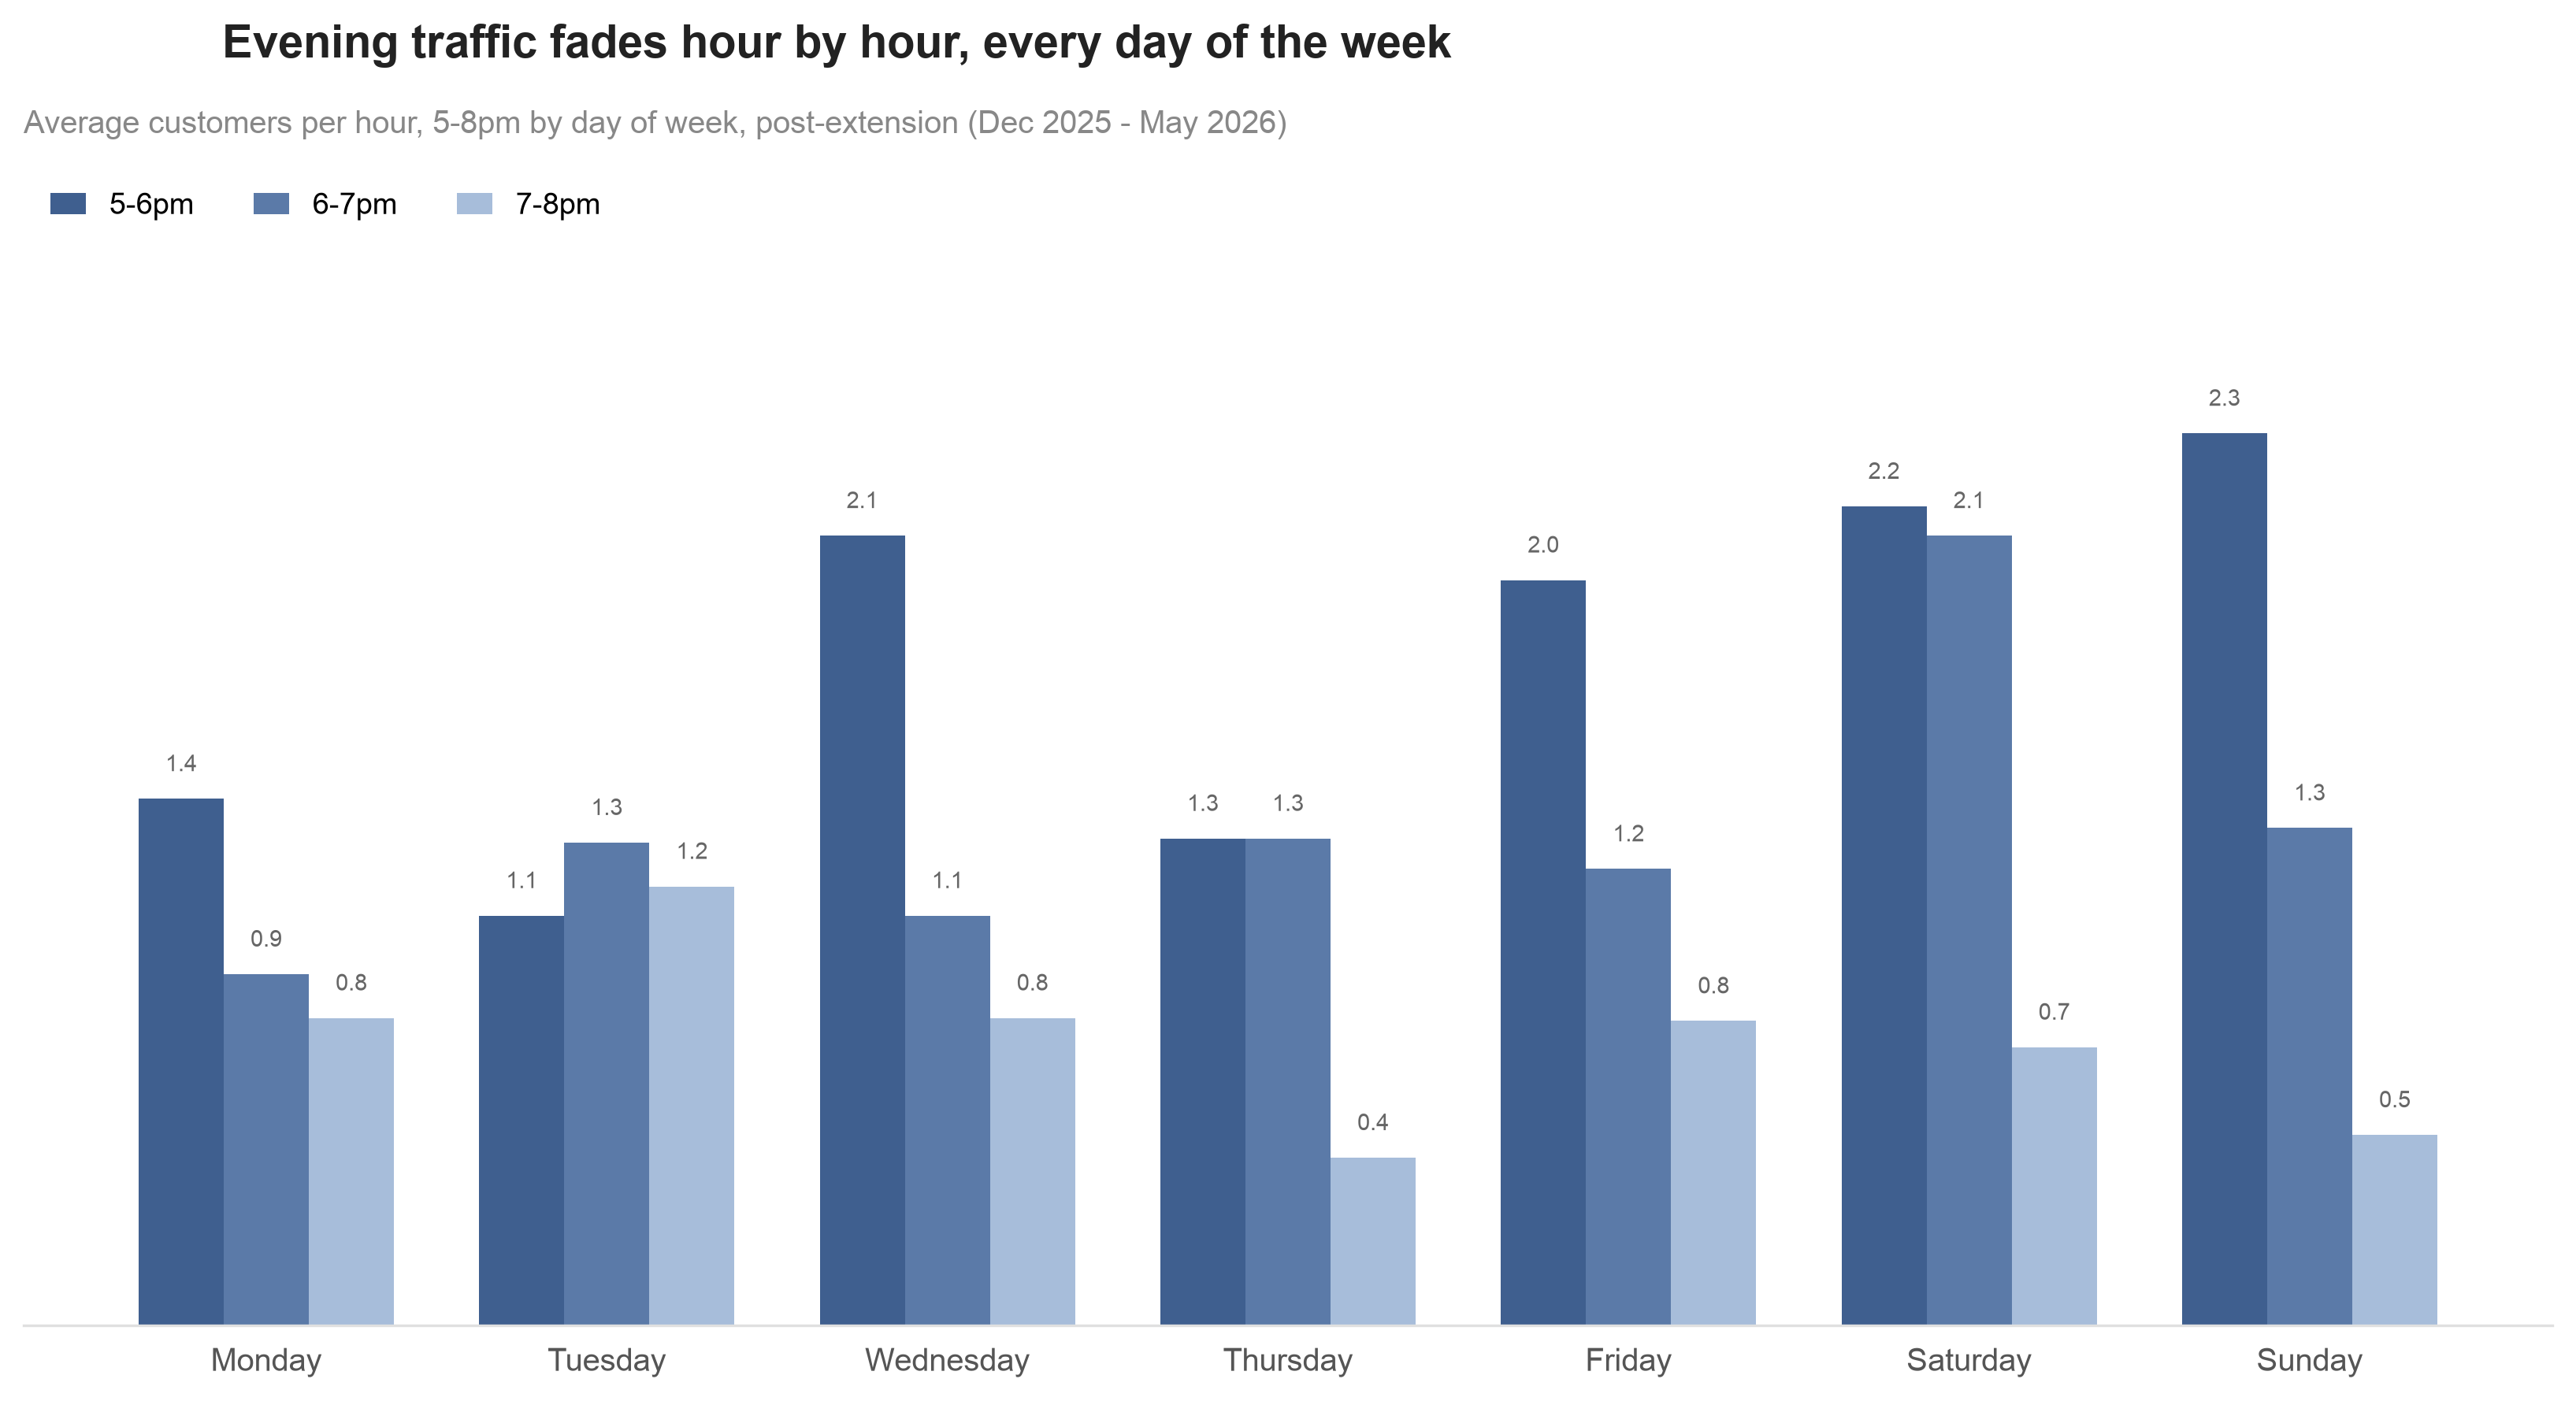

In [53]:
# CHART — Evening traffic by hour (5-8pm), all three hours, by day of week

hourly_dow_count_post = (
    hourly_daily_count_post
    .groupby(hourly_daily_count_post.index.day_name())
    .mean()
    .reindex(days)
    .reindex(columns=all_hours, fill_value=0)
)

evening_hours = [17, 18, 19]
evening_labels = ['5-6pm', '6-7pm', '7-8pm']
evening_colors = ['#3f5f8f', '#5b7aa8', '#a7bdda']

x = np.arange(len(days))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))
for i, (h, lbl, c) in enumerate(zip(evening_hours, evening_labels, evening_colors)):
    vals = hourly_dow_count_post[h].reindex(days).values
    offset = (i - 1) * width
    bars = ax.bar(x + offset, vals, width, color=c, zorder=2, label=lbl)
    for xi, v in zip(x, vals):
        ax.text(xi + offset, v + 0.06, f'{v:.1f}', ha='center', va='bottom', fontsize=7, color='#666666')

ax.legend(loc='upper left', frameon=False, fontsize=9, handlelength=1.2, ncol=3)

fig.suptitle('Evening traffic fades hour by hour, every day of the week', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average customers per hour, 5-8pm by day of week, post-extension (Dec 2025 - May 2026)',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, hourly_dow_count_post[evening_hours].values.max() * 1.3)
ax.set_xticks(x)
ax.set_xticklabels(days, fontsize=9.5, color=TICK)
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout()
save_chart(fig)
plt.show()


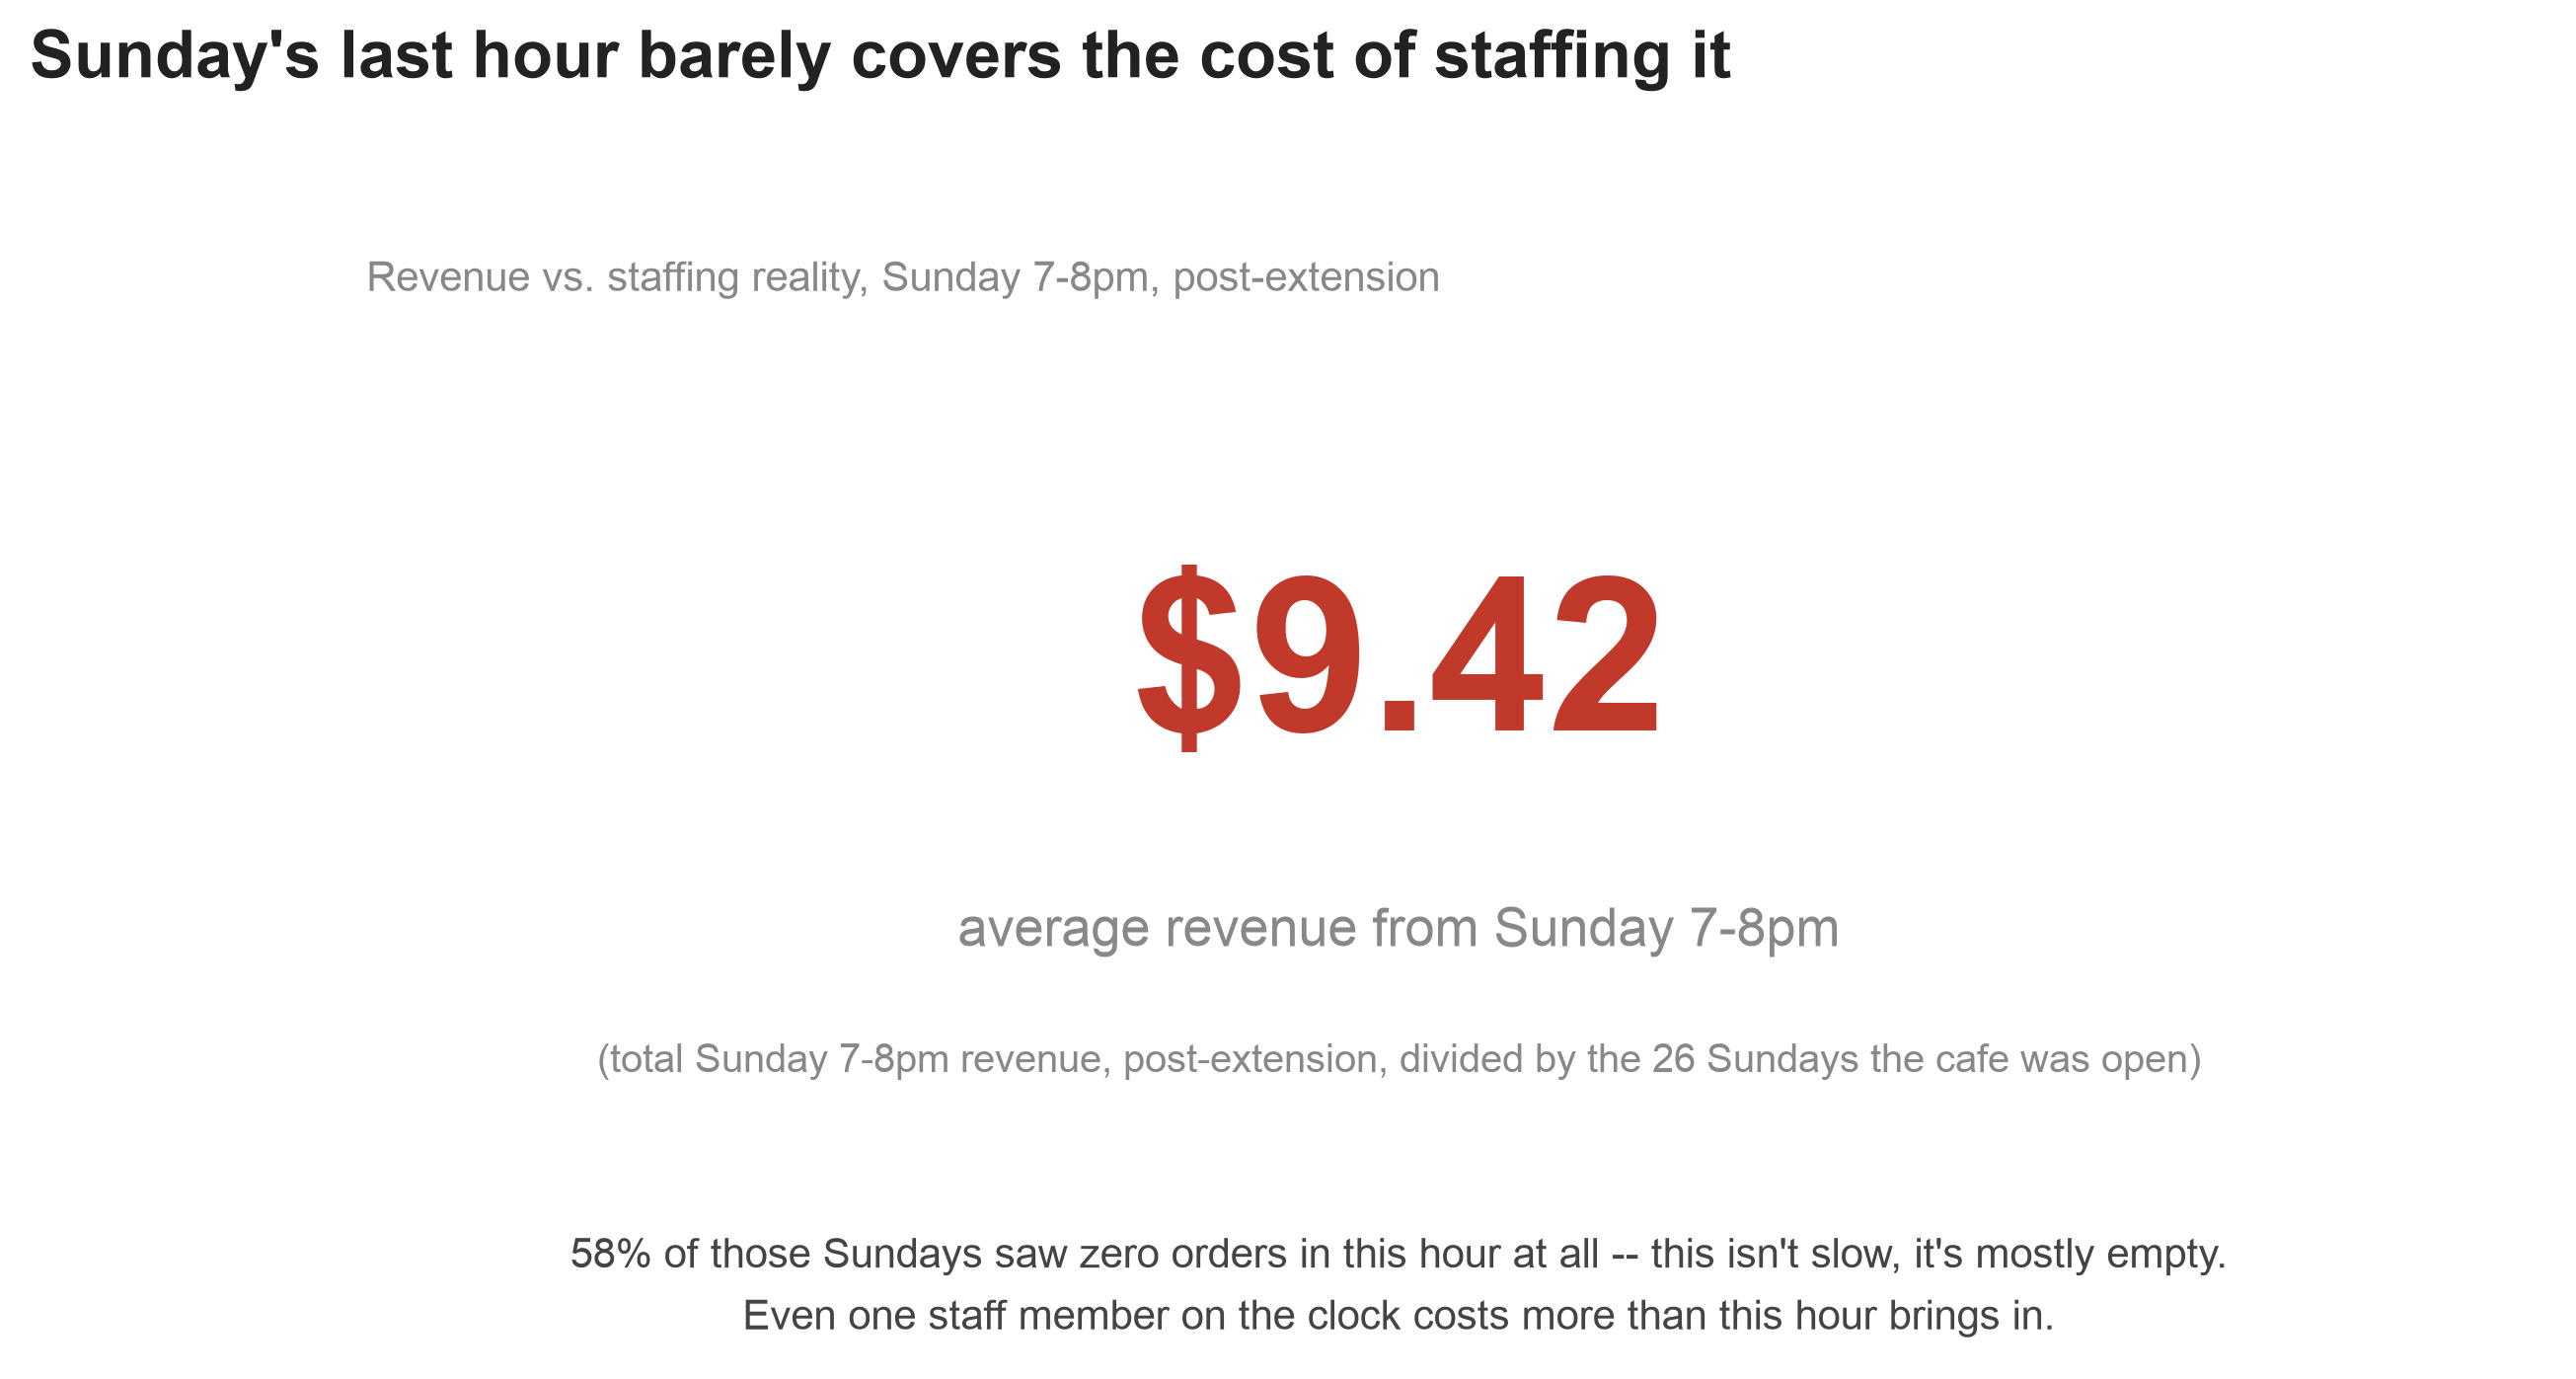

In [54]:
# CHART — Sunday 7-8pm big-number: revenue barely covers labor

sunday_78_avg = hourly_dow_revenue_post.loc['Sunday', 19]
sunday_78_zero_share = 15 / 26 * 100  # confirmed: 15 of 26 Sundays had zero orders in this window

fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

ax.text(0.5, 0.66, f'${sunday_78_avg:,.2f}', fontsize=52, fontweight='bold', color=RED, ha='center', va='top')
ax.text(0.5, 0.36, 'average revenue from Sunday 7-8pm', fontsize=13, color=MUTED, ha='center', va='top')
ax.text(0.5, 0.24, '(total Sunday 7-8pm revenue, post-extension, divided by the 26 Sundays the cafe was open)',
        fontsize=9.5, color=MUTED, ha='center', va='top')

note = (f'{sunday_78_zero_share:.0f}% of those Sundays saw zero orders in this hour at all -- '
        'this isn\'t slow, it\'s mostly empty.\nEven one staff member on the clock costs more than this hour brings in.')
ax.text(0.5, 0.08, note, fontsize=10, color=INK_SOFT, ha='center', va='top', linespacing=1.6)

fig.suptitle("Sunday's last hour barely covers the cost of staffing it", x=0.05, ha='left', y=0.98,
             fontsize=16, fontweight='bold', color=INK)
ax.text(0.05, 0.9, 'Revenue vs. staffing reality, Sunday 7-8pm, post-extension', fontsize=10, color=MUTED)

save_chart(fig)
plt.show()


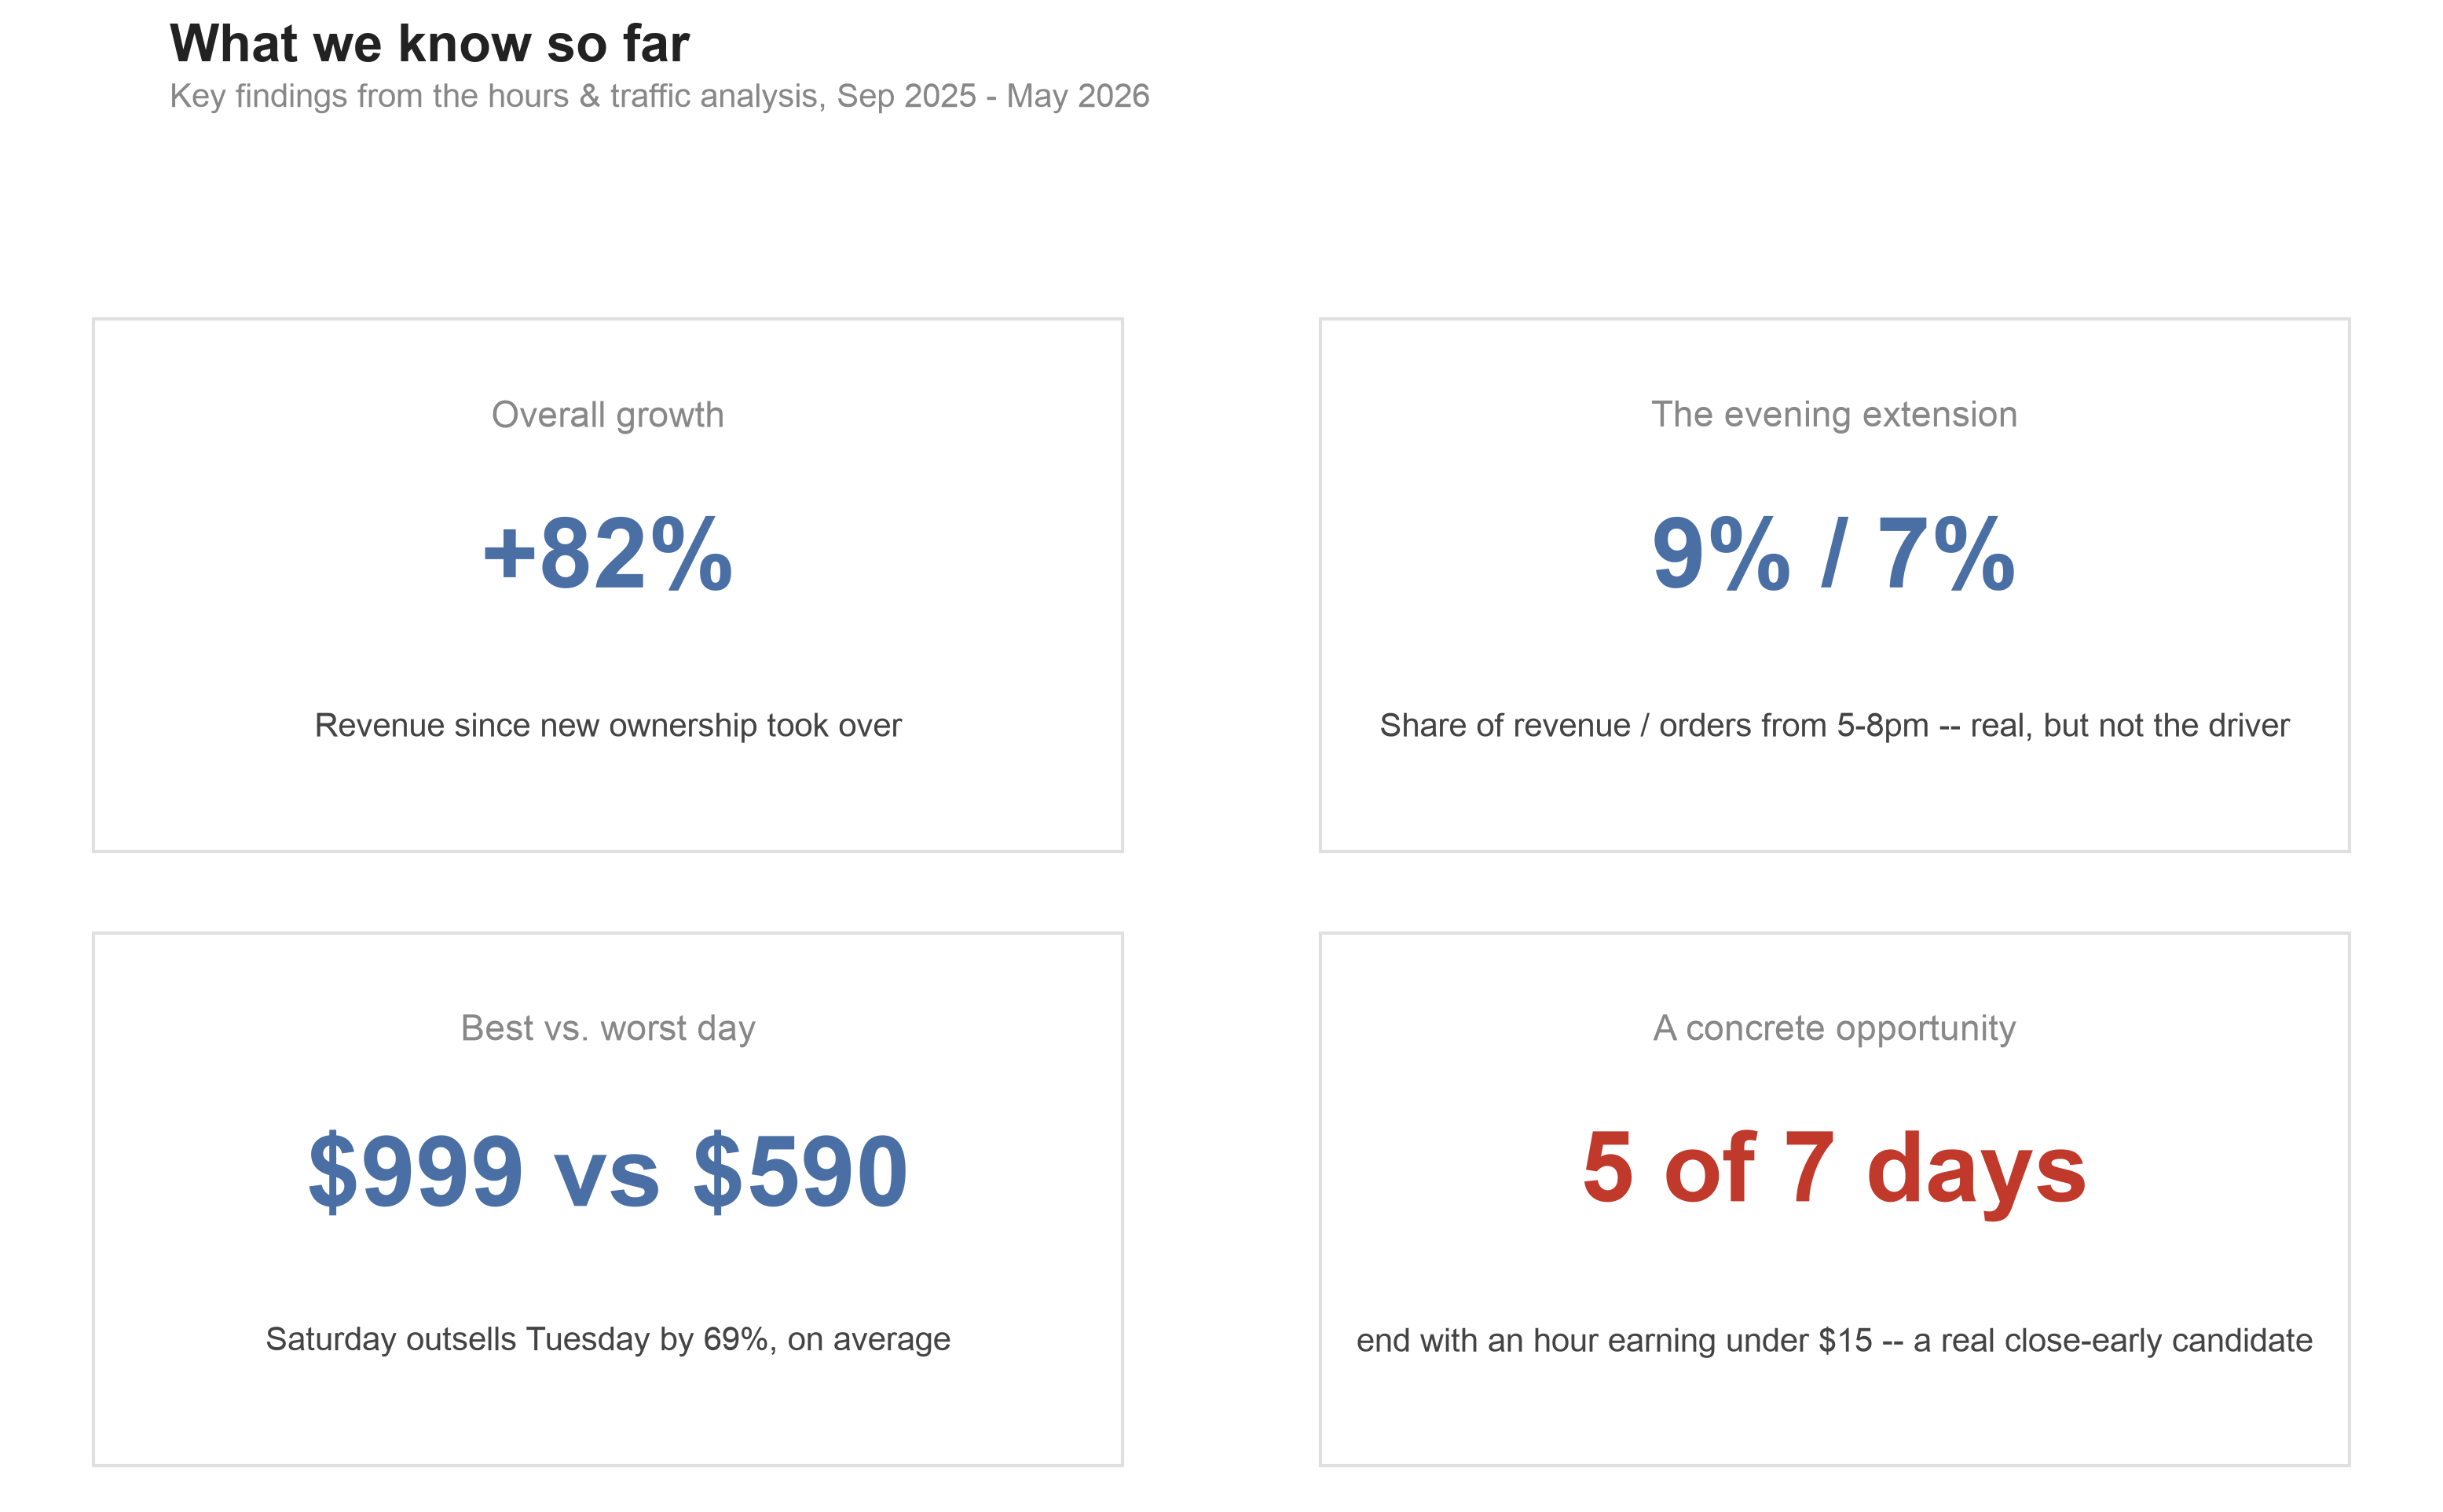

In [55]:
# CHART — Part 1 recap: key findings before moving into menu analysis

dow_revenue = day_of_week_revenue_mean_post.reindex(days)
sat_val = dow_revenue['Saturday']
tue_val = dow_revenue['Tuesday']
day_gap_pct = (sat_val / tue_val - 1) * 100

weak_close_days = 0
for day in days:
    row = hourly_dow_revenue_post.loc[day].dropna()
    if (row < 15).any():
        weak_close_days += 1

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))

cards = [
    (axes[0, 0], 'Overall growth', f'+{growth:.0f}%', 'Revenue since new ownership took over', BLUE),
    (axes[0, 1], 'The evening extension', f'{evening_share:.0f}% / {evening_order_share:.0f}%',
     "Share of revenue / orders from 5-8pm -- real, but not the driver", BLUE),
    (axes[1, 0], 'Best vs. worst day', f'\\${sat_val:,.0f} vs \\${tue_val:,.0f}',
     f'Saturday outsells Tuesday by {day_gap_pct:.0f}%, on average', BLUE),
    (axes[1, 1], 'A concrete opportunity', f'{weak_close_days} of 7 days',
     'end with an hour earning under $15 -- a real close-early candidate', RED),
]

for ax, label, big, sub, color in cards:
    ax.axis('off')
    ax.text(0.5, 0.82, label, fontsize=11, color=MUTED, ha='center', va='top')
    ax.text(0.5, 0.62, big, fontsize=30, fontweight='bold', color=color, ha='center', va='top')
    ax.text(0.5, 0.28, sub, fontsize=10, color=INK_SOFT, ha='center', va='top', wrap=True)
    ax.add_patch(plt.Rectangle((0.06, 0.04), 0.88, 0.92, transform=ax.transAxes,
                                fill=False, edgecolor=AXIS, lw=1))

fig.suptitle('What we know so far', x=0.09, ha='left', y=1.0,
             fontsize=16, fontweight='bold', color=INK)
fig.text(0.09, 0.945, 'Key findings from the hours & traffic analysis, Sep 2025 - May 2026', fontsize=10, color=MUTED)

plt.tight_layout(rect=[0.02, 0.02, 0.98, 0.9])
save_chart(fig)
plt.show()


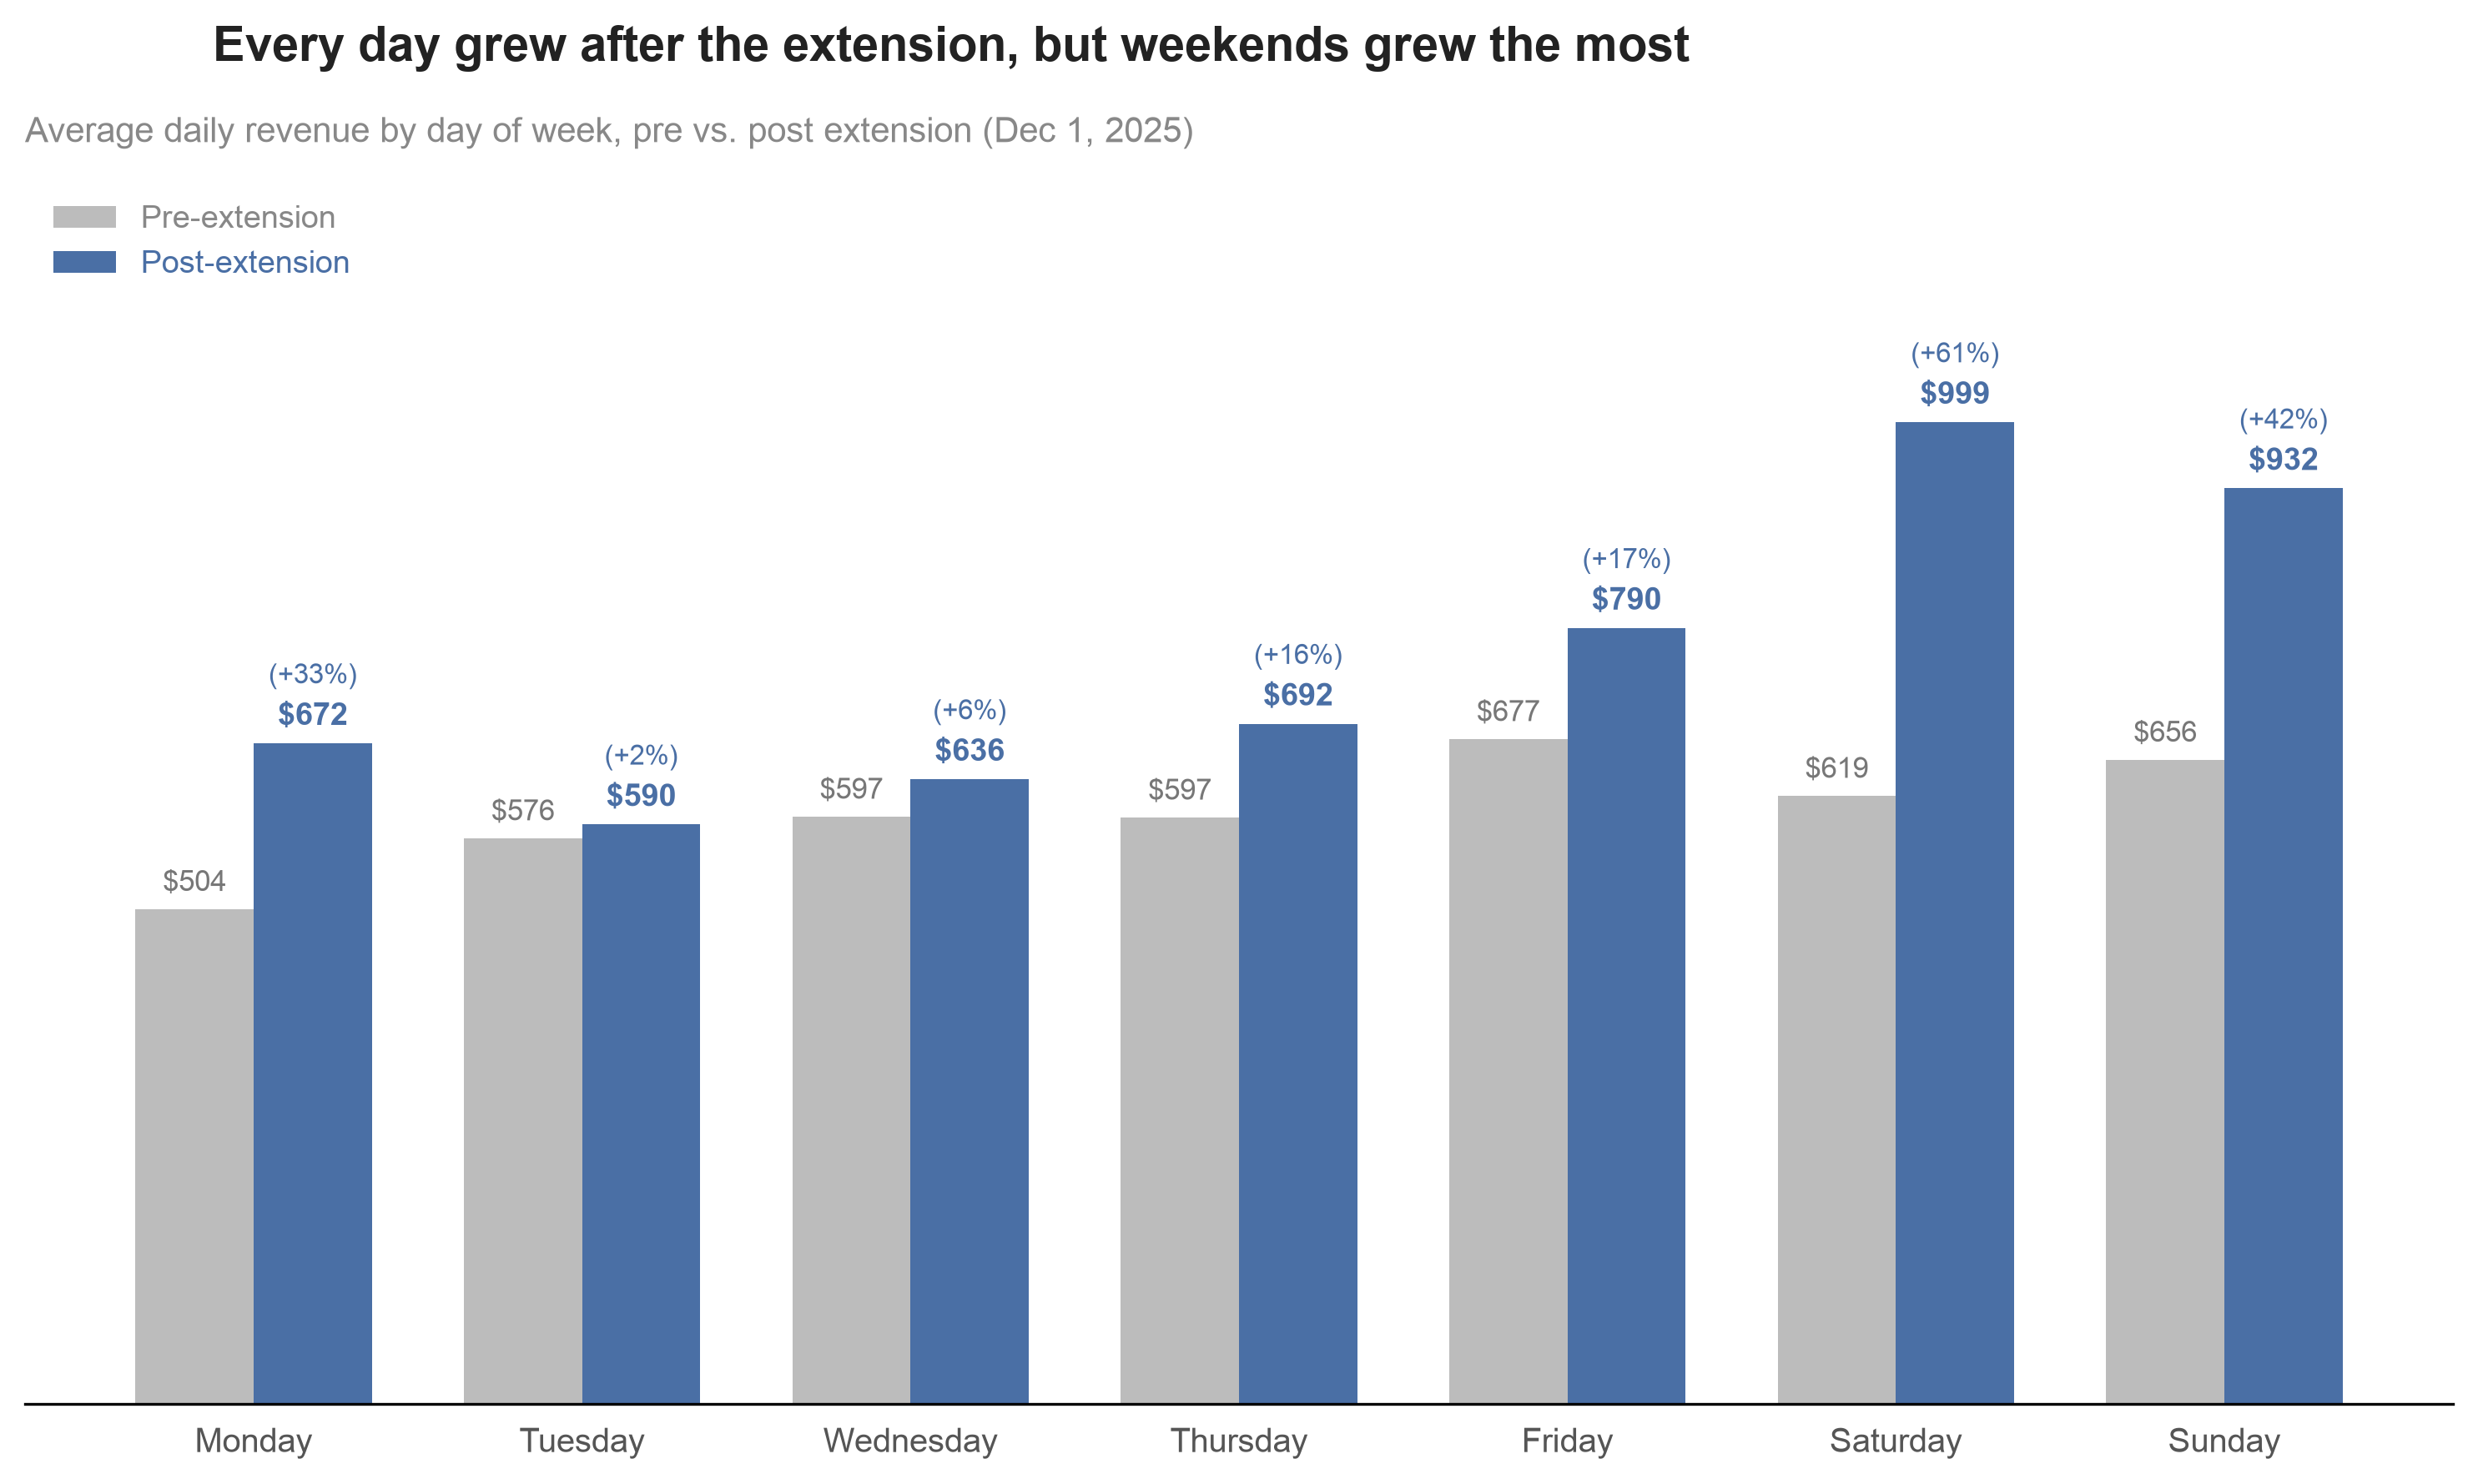

In [56]:
# CHART — Average daily revenue by day of week, pre vs. post extension

x = np.arange(len(days))
width = 0.36
pre_vals = day_of_week_revenue_mean_pre.reindex(days).values
post_vals = day_of_week_revenue_mean_post.reindex(days).values

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, pre_vals, width, color=GREY_BAR, label='Pre-extension', zorder=2)
ax.bar(x + width/2, post_vals, width, color=BLUE, label='Post-extension', zorder=2)
ax.set_ylim(0, max(pre_vals.max(), post_vals.max()) * 1.25)

for xi, (pv, qv) in enumerate(zip(pre_vals, post_vals)):
    ax.text(xi - width/2, pv + 12, f'${pv:,.0f}', ha='center', va='bottom', fontsize=8.5, color='#777777')
    pct = (qv/pv - 1) * 100
    ax.text(xi + width/2, qv + 12, f'${qv:,.0f}', ha='center', va='bottom', fontsize=9, color=BLUE, fontweight='bold')
    ax.text(xi + width/2, qv + 55, f'({pct:+.0f}%)', ha='center', va='bottom', fontsize=8, color=BLUE)

ax.set_xticks(x)
ax.set_xticklabels(days, fontsize=9.5, color=TICK)

fig.suptitle('Every day grew after the extension, but weekends grew the most', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average daily revenue by day of week, pre vs. post extension (Dec 1, 2025)',
              loc='left', fontsize=10, color=MUTED, pad=10)

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.legend(loc='upper left', frameon=False, fontsize=9, labelcolor=[MUTED, BLUE])

plt.tight_layout()
save_chart(fig)
plt.show()

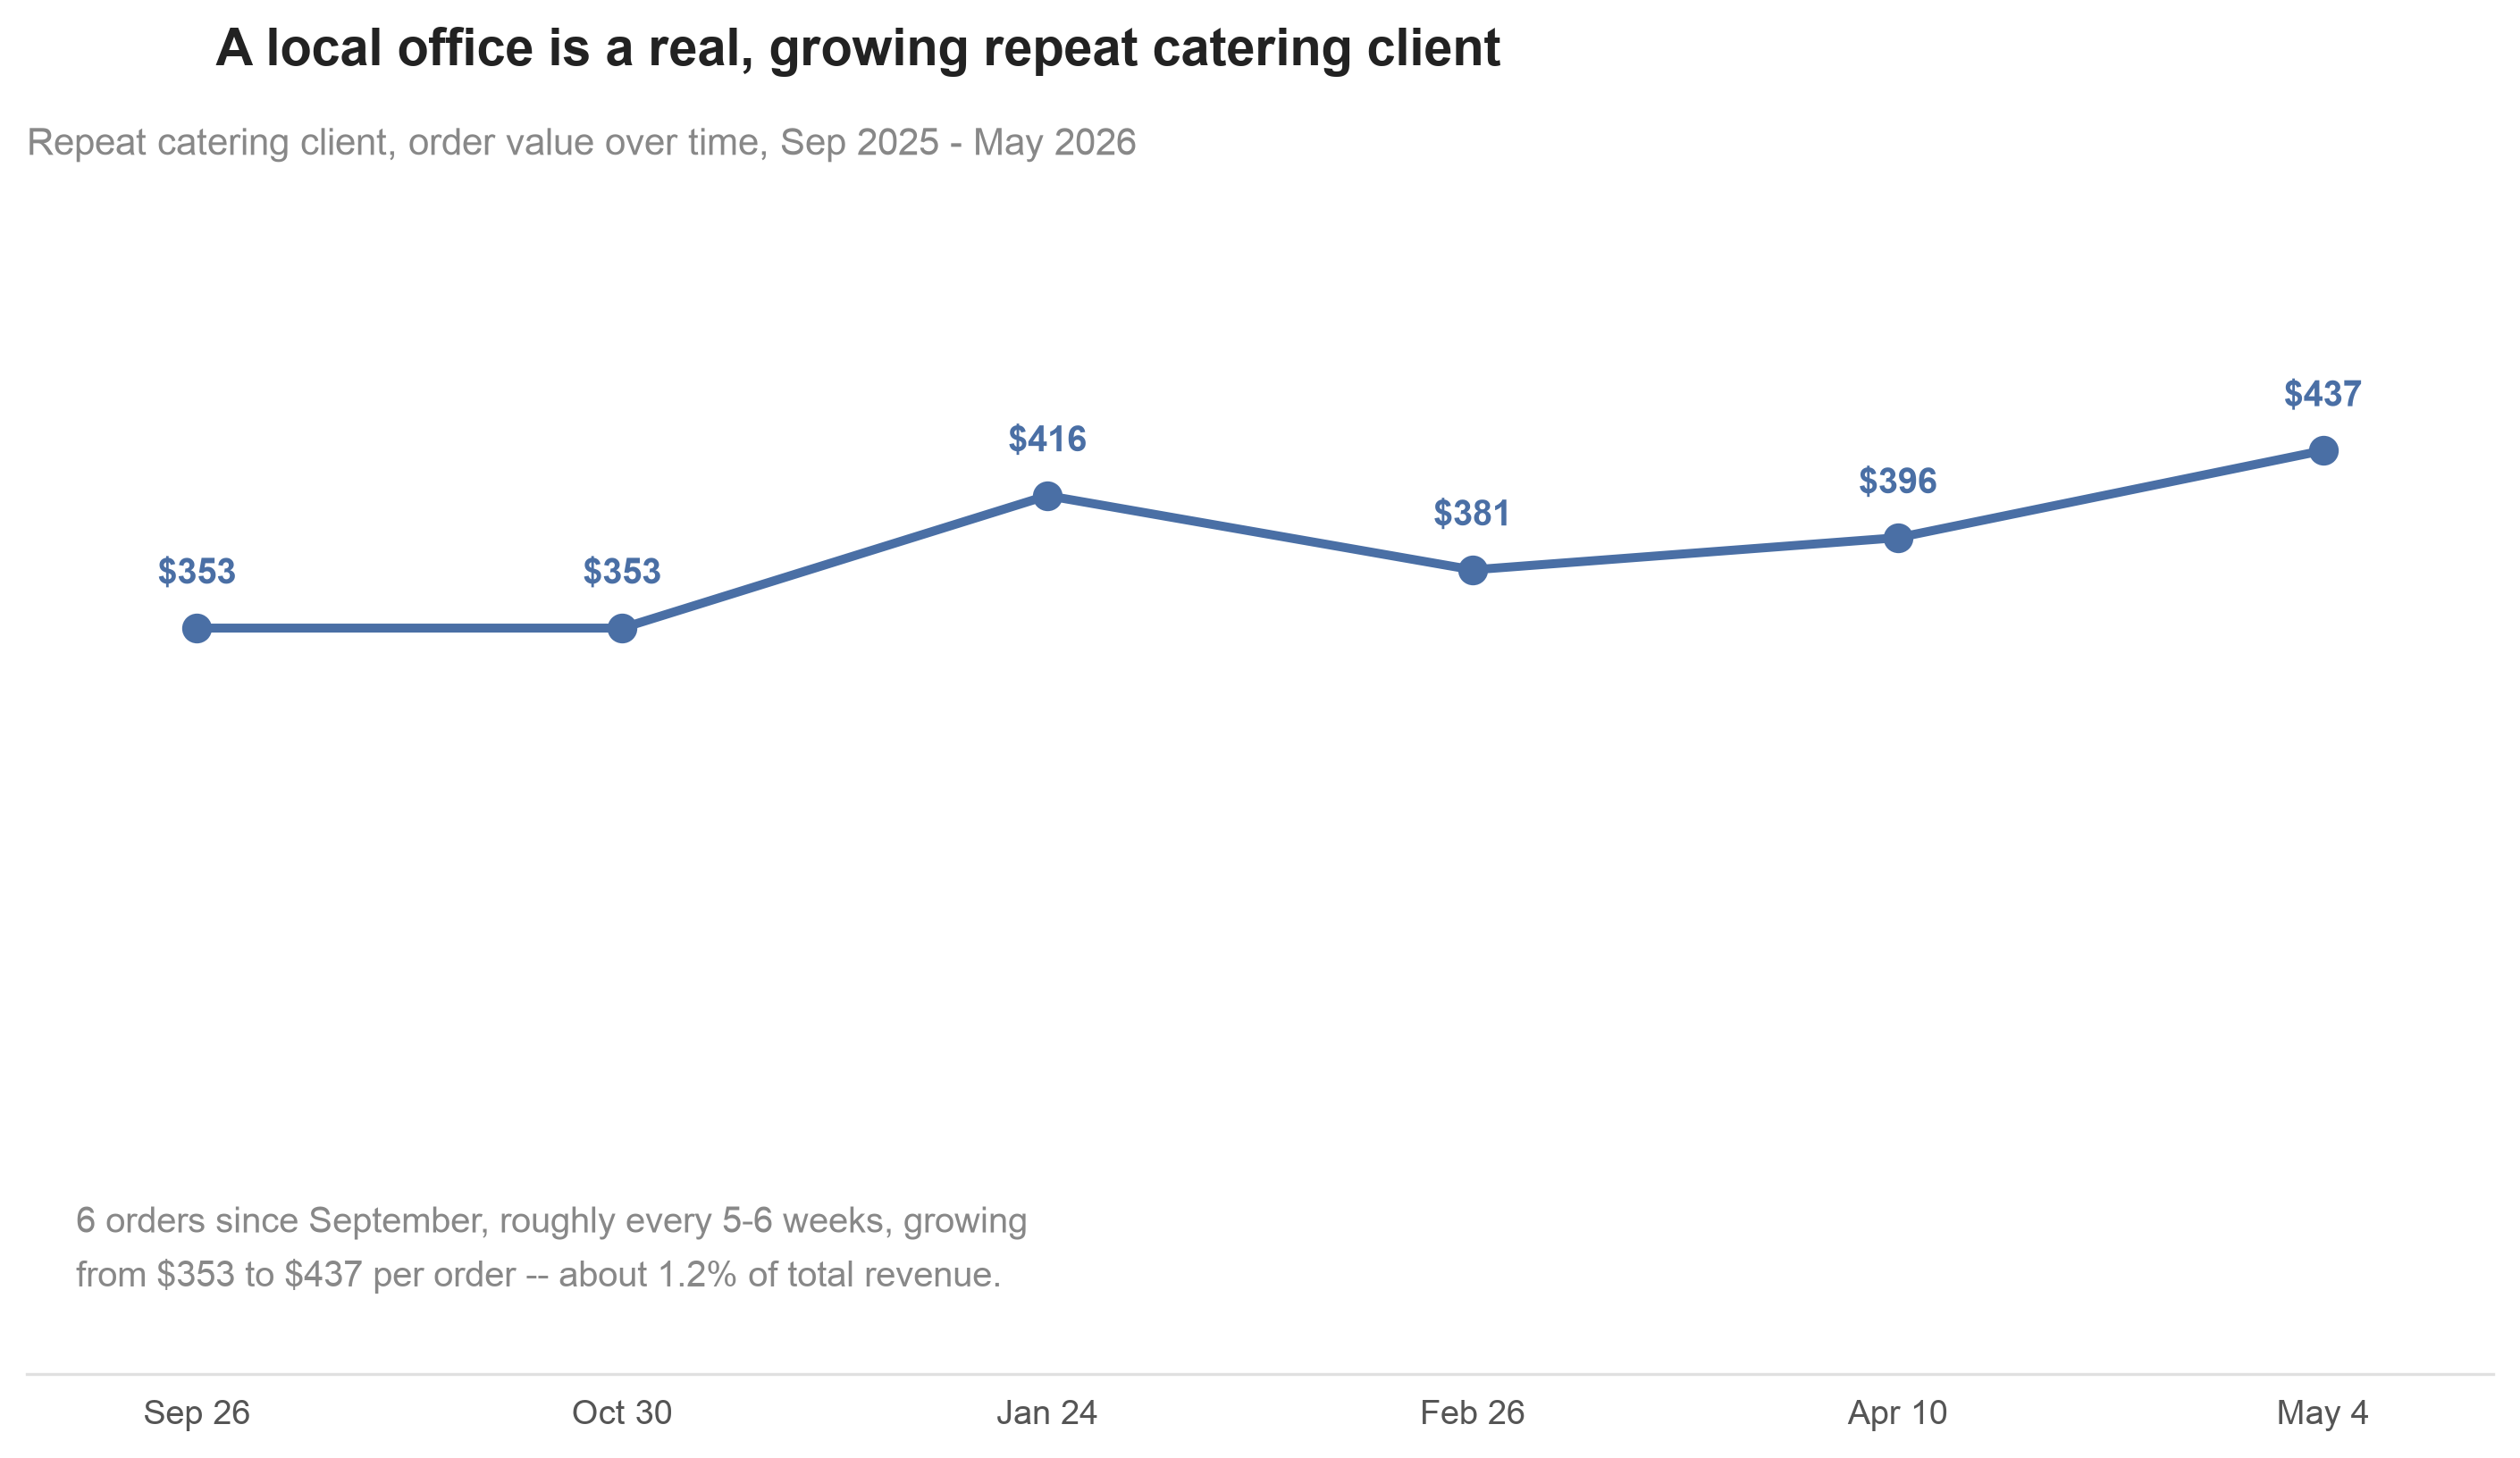

In [57]:
# CHART — Municipal-office recurring catering client, order value over time

city_hall = orders[orders['is_repeat_client_catering']].sort_values('order_date').reset_index(drop=True)
city_hall_share = city_hall['revenue'].sum() / orders['revenue'].sum() * 100

x = range(len(city_hall))
vals = city_hall['revenue'].values
date_labels = [d.strftime('%b %-d') for d in city_hall['order_date']]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(x, vals, color=BLUE, lw=2.4, marker='o', markersize=7, zorder=3)

for xi, v in zip(x, vals):
    ax.text(xi, v + max(vals) * 0.04, f'${v:,.0f}', ha='center', va='bottom', fontsize=9.5, color=BLUE, fontweight='bold')

ax.set_ylim(0, max(vals) * 1.28)
ax.set_xlim(-0.4, len(city_hall) - 0.6)
ax.set_xticks(list(x))
ax.set_xticklabels(date_labels, fontsize=9, color=TICK)

note = (f'{len(city_hall)} orders since September, roughly every 5-6 weeks, growing\n'
        f'from \\$353 to \\$437 per order -- about {city_hall_share:.1f}% of total revenue.')
ax.text(0.02, 0.06, note, transform=ax.transAxes, ha='left', va='bottom', fontsize=9.5, color=MUTED, linespacing=1.6)

fig.suptitle('A local office is a real, growing repeat catering client', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Repeat catering client, order value over time, Sep 2025 - May 2026', loc='left', fontsize=10, color=MUTED, pad=10)

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.tick_params(bottom=False)
ax.spines['bottom'].set_color(AXIS)
plt.tight_layout()
save_chart(fig)
plt.show()


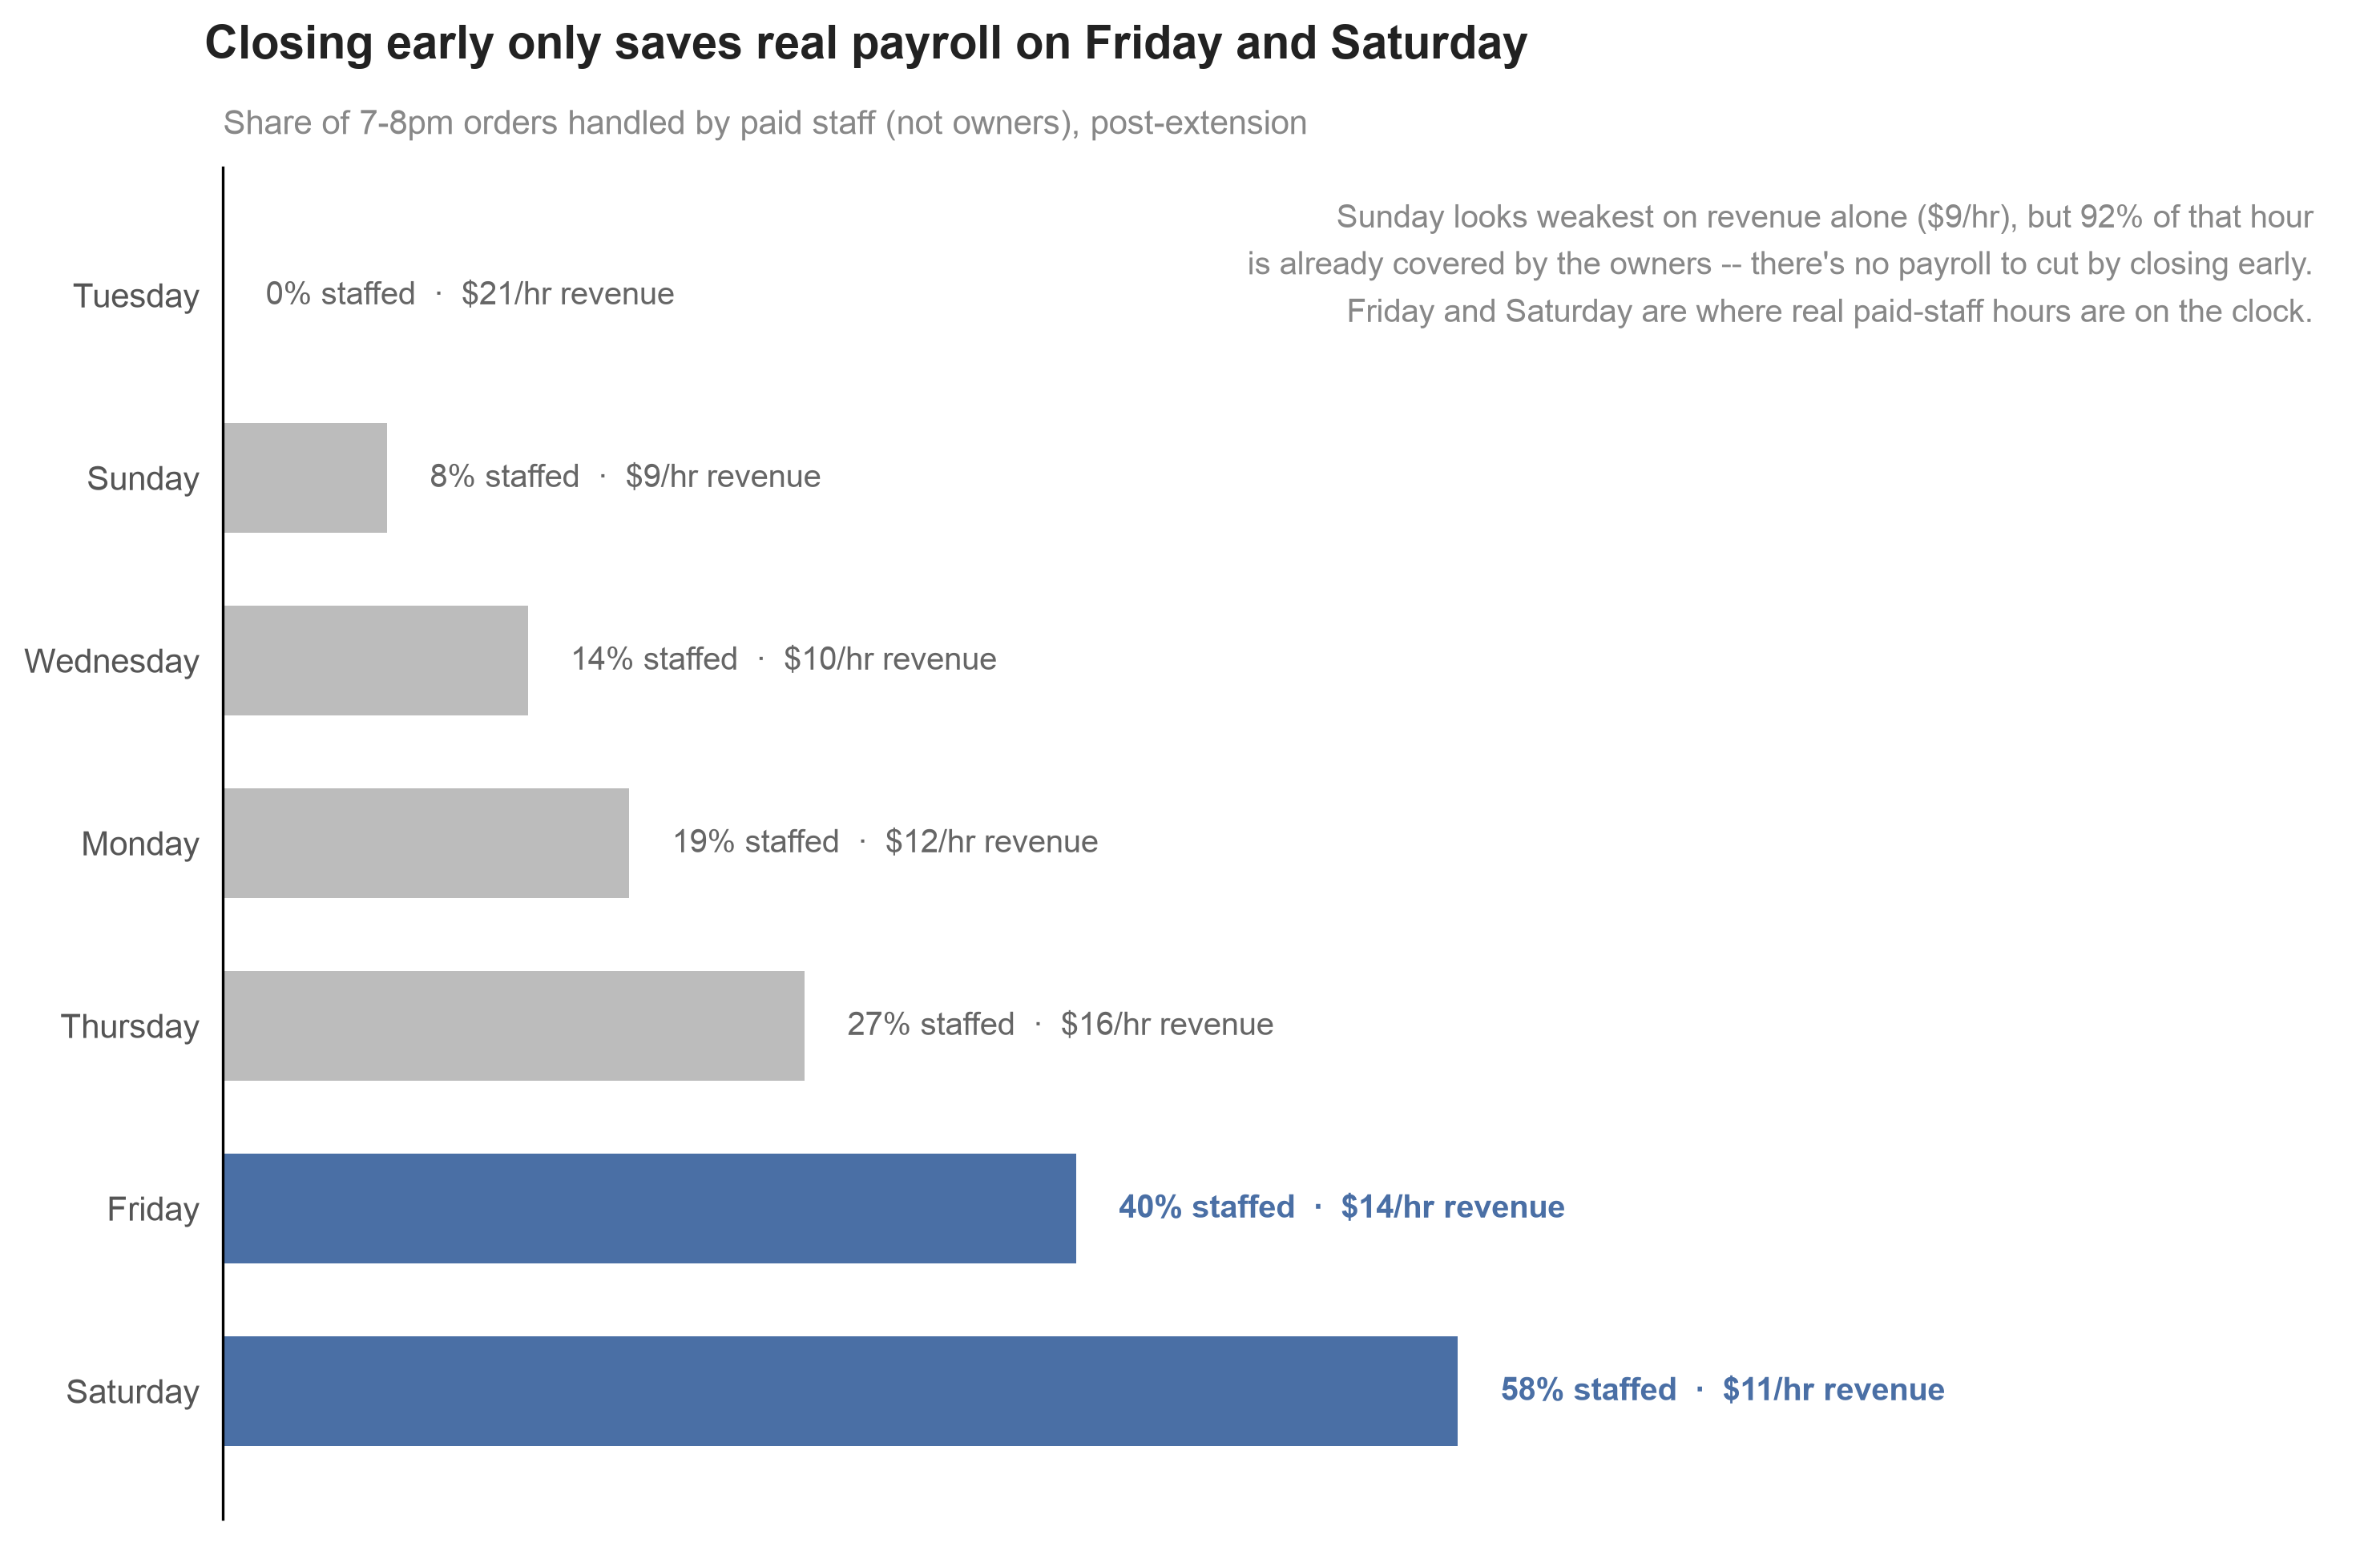

In [58]:
# CHART — Closing-hour staffing: which weak days actually have payroll to cut

closing_hour_orders = post[post['order_date'].dt.hour == 19].copy()
closing_hour_orders['is_owner'] = closing_hour_orders['rung_by_owner']
closing_hour_orders['dow'] = closing_hour_orders['order_date'].dt.day_name()

staff_pct = {}
for day in days:
    d = closing_hour_orders[closing_hour_orders['dow'] == day]
    staff_pct[day] = (~d['is_owner']).mean() * 100 if len(d) else 0.0
staff_pct = pd.Series(staff_pct).reindex(days)
closing_rev = hourly_dow_revenue_post[19].reindex(days)

REAL_OPPORTUNITY = {'Friday', 'Saturday'}
s_sorted = staff_pct.sort_values().iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = [BLUE if d in REAL_OPPORTUNITY else GREY_BAR for d in s_sorted.index]
ax.barh(s_sorted.index, s_sorted.values, color=colors, height=0.6, zorder=2)

for y, (d, v) in enumerate(s_sorted.items()):
    ext = d in REAL_OPPORTUNITY
    label = f'{v:.0f}% staffed  ·  ${closing_rev[d]:,.0f}/hr revenue'
    ax.text(v + 2, y, label, va='center', fontsize=9.5,
            color=(BLUE if ext else '#666666'), fontweight=('bold' if ext else 'normal'))

note = ("Sunday looks weakest on revenue alone ($9/hr), but 92% of that hour\n"
        "is already covered by the owners -- there's no payroll to cut by closing early.\n"
        "Friday and Saturday are where real paid-staff hours are on the clock.")
ax.text(0.98, 0.98, note, transform=ax.transAxes, ha='right', va='top', fontsize=9.5, color=MUTED, linespacing=1.6)

fig.suptitle('Closing early only saves real payroll on Friday and Saturday', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Share of 7-8pm orders handled by paid staff (not owners), post-extension', loc='left', fontsize=10, color=MUTED, pad=10)

ax.set_xlim(0, 100)
ax.set_ylim(-0.7, len(s_sorted) - 0.3)
ax.set_xticks([])
for sp in ['top', 'right', 'bottom']:
    ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
for lbl in ax.get_yticklabels():
    lbl.set_color(TICK)
plt.tight_layout()
save_chart(fig)
plt.show()


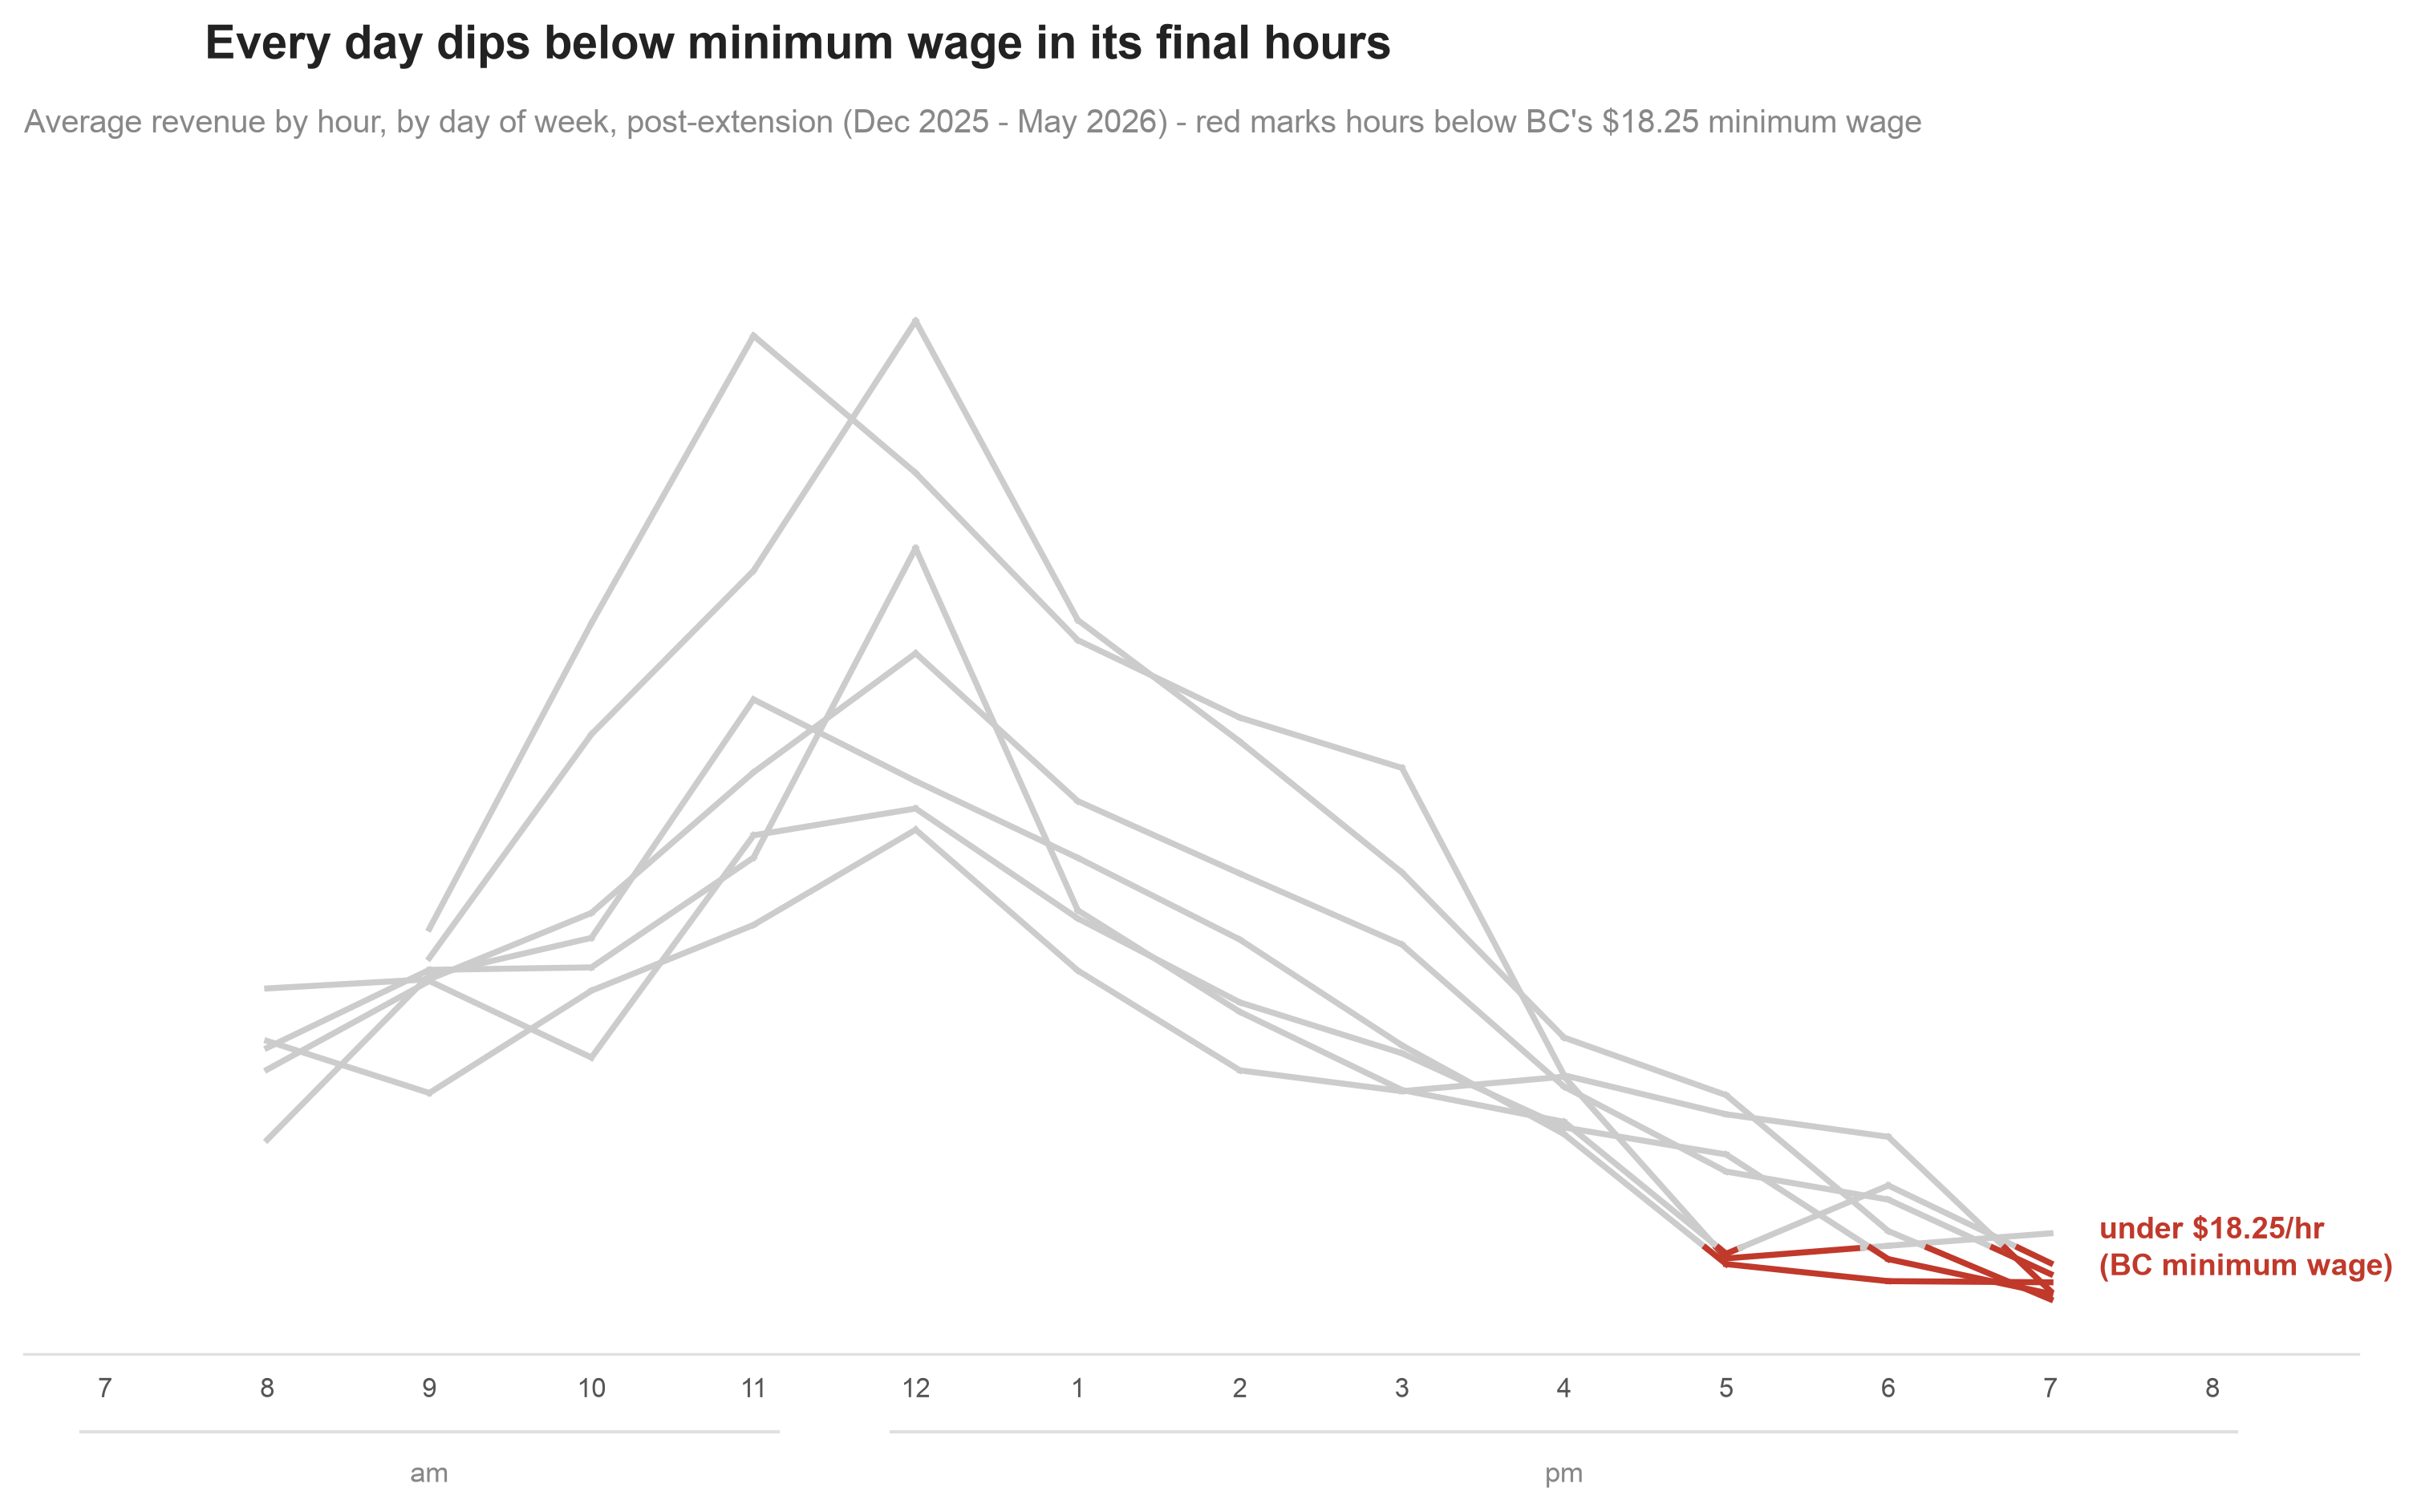

In [59]:
# CHART — Hourly revenue shape, every day of the week (base version, all grey)

fig, ax = plt.subplots(figsize=(10, 6.5))

DANGER_THRESHOLD = 18.25  # BC minimum wage -- below this, revenue can't even cover one employee's wage for the hour
for day in days:
    row = hourly_dow_revenue_post.loc[day].dropna()
    hrs, vals = row.index.tolist(), row.values
    for i in range(len(hrs) - 1):
        h1, h2 = hrs[i], hrs[i + 1]
        v1, v2 = vals[i], vals[i + 1]
        below1, below2 = v1 < DANGER_THRESHOLD, v2 < DANGER_THRESHOLD
        if below1 == below2:
            # whole segment on one side of the threshold -- no split needed
            ax.plot([h1, h2], [v1, v2], color=(RED if below1 else GREY_LINE), lw=1.8, zorder=2)
        else:
            # segment crosses $25 -- find the exact crossing point and split there
            x_cross = h1 + (h2 - h1) * (DANGER_THRESHOLD - v1) / (v2 - v1)
            first_color = RED if below1 else GREY_LINE
            second_color = RED if below2 else GREY_LINE
            ax.plot([h1, x_cross], [v1, DANGER_THRESHOLD], color=first_color, lw=1.8, zorder=2)
            ax.plot([x_cross, h2], [DANGER_THRESHOLD, v2], color=second_color, lw=1.8, zorder=2)

day_max = hourly_dow_revenue_post.max().max()
hours_list = list(range(7, 21))
hour_labels_local = [str(h if h <= 12 else h - 12) for h in hours_list]

last_data_hour = max(h for day in days for h, v in hourly_dow_revenue_post.loc[day].dropna().items())
ax.text(last_data_hour + 0.3, DANGER_THRESHOLD, 'under $18.25/hr\n(BC minimum wage)', ha='left', va='center',
        fontsize=9, color=RED, fontweight='bold', linespacing=1.4)

fig.suptitle('Every day dips below minimum wage in its final hours', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour, by day of week, post-extension (Dec 2025 - May 2026) - red marks hours below BC\'s $18.25 minimum wage',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, day_max * 1.15)
ax.set_xlim(hours_list[0] - 0.5, hours_list[-1] + 0.9)
ax.set_xticks(hours_list)
ax.set_xticklabels(hour_labels_local, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours_list[0], 11), ('pm', 12, hours_list[-1])])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.spines['bottom'].set_color(AXIS)
ax.tick_params(bottom=False, colors=TICK)
plt.subplots_adjust(left=0.015, right=0.985, top=0.8892, bottom=0.1294)
save_chart(fig, bbox=None)
plt.show()


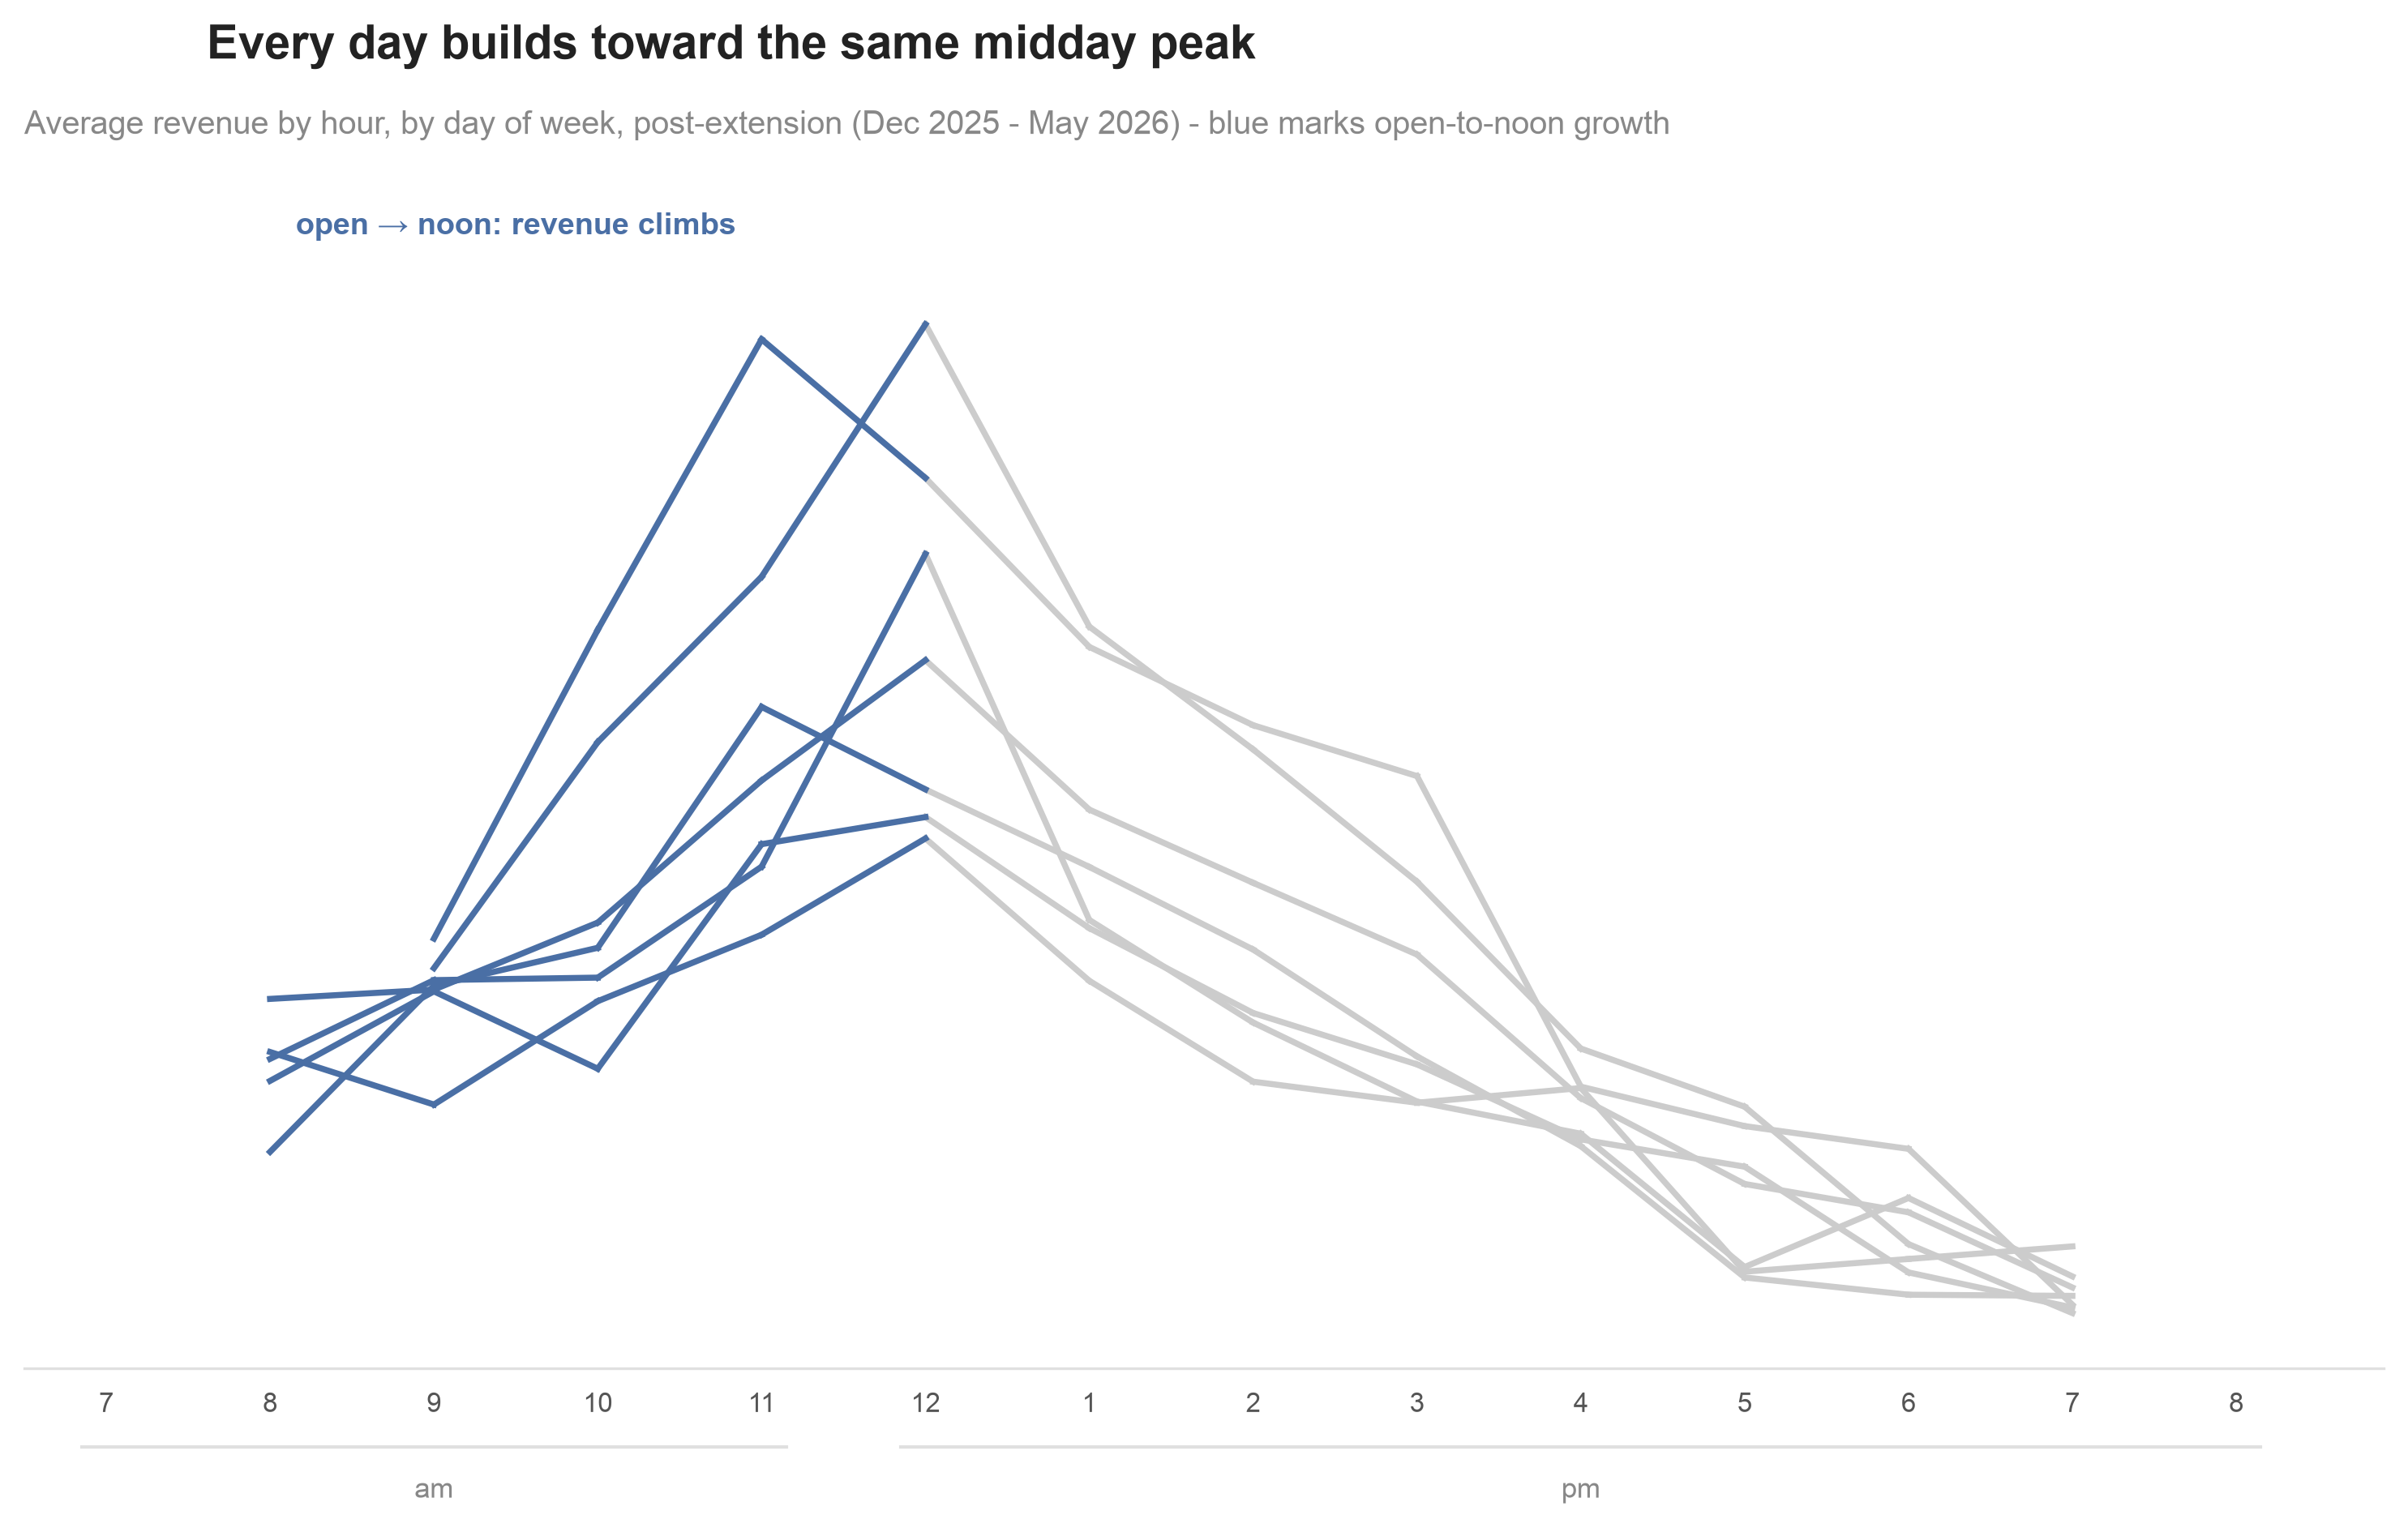

In [60]:
# CHART — Hourly revenue shape, open-to-noon highlighted (growth to the peak)

fig, ax = plt.subplots(figsize=(10, 6.5))

ZONE_START, ZONE_END = 7, 12  # open through the midday peak

for day in days:
    row = hourly_dow_revenue_post.loc[day].dropna()
    hrs, vals = row.index.tolist(), row.values
    for i in range(len(hrs) - 1):
        h1, h2 = hrs[i], hrs[i + 1]
        v1, v2 = vals[i], vals[i + 1]
        in_zone = h1 >= ZONE_START and h2 <= ZONE_END
        ax.plot([h1, h2], [v1, v2], color=(BLUE if in_zone else GREY_LINE),
                lw=1.8, zorder=(3 if in_zone else 2))

day_max = hourly_dow_revenue_post.max().max()
hours_list = list(range(7, 21))
hour_labels_local = [str(h if h <= 12 else h - 12) for h in hours_list]

ax.text((ZONE_START + ZONE_END) / 2, day_max * 1.08, 'open \u2192 noon: revenue climbs',
        ha='center', va='bottom', fontsize=9, color=BLUE, fontweight='bold')

fig.suptitle('Every day builds toward the same midday peak', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour, by day of week, post-extension (Dec 2025 - May 2026) - blue marks open-to-noon growth',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, day_max * 1.15)
ax.set_xlim(hours_list[0] - 0.5, hours_list[-1] + 0.9)
ax.set_xticks(hours_list)
ax.set_xticklabels(hour_labels_local, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours_list[0], 11), ('pm', 12, hours_list[-1])])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.spines['bottom'].set_color(AXIS)
ax.tick_params(bottom=False, colors=TICK)
plt.subplots_adjust(left=0.015, right=0.985, top=0.8892, bottom=0.1294)
save_chart(fig, bbox=None)
plt.show()


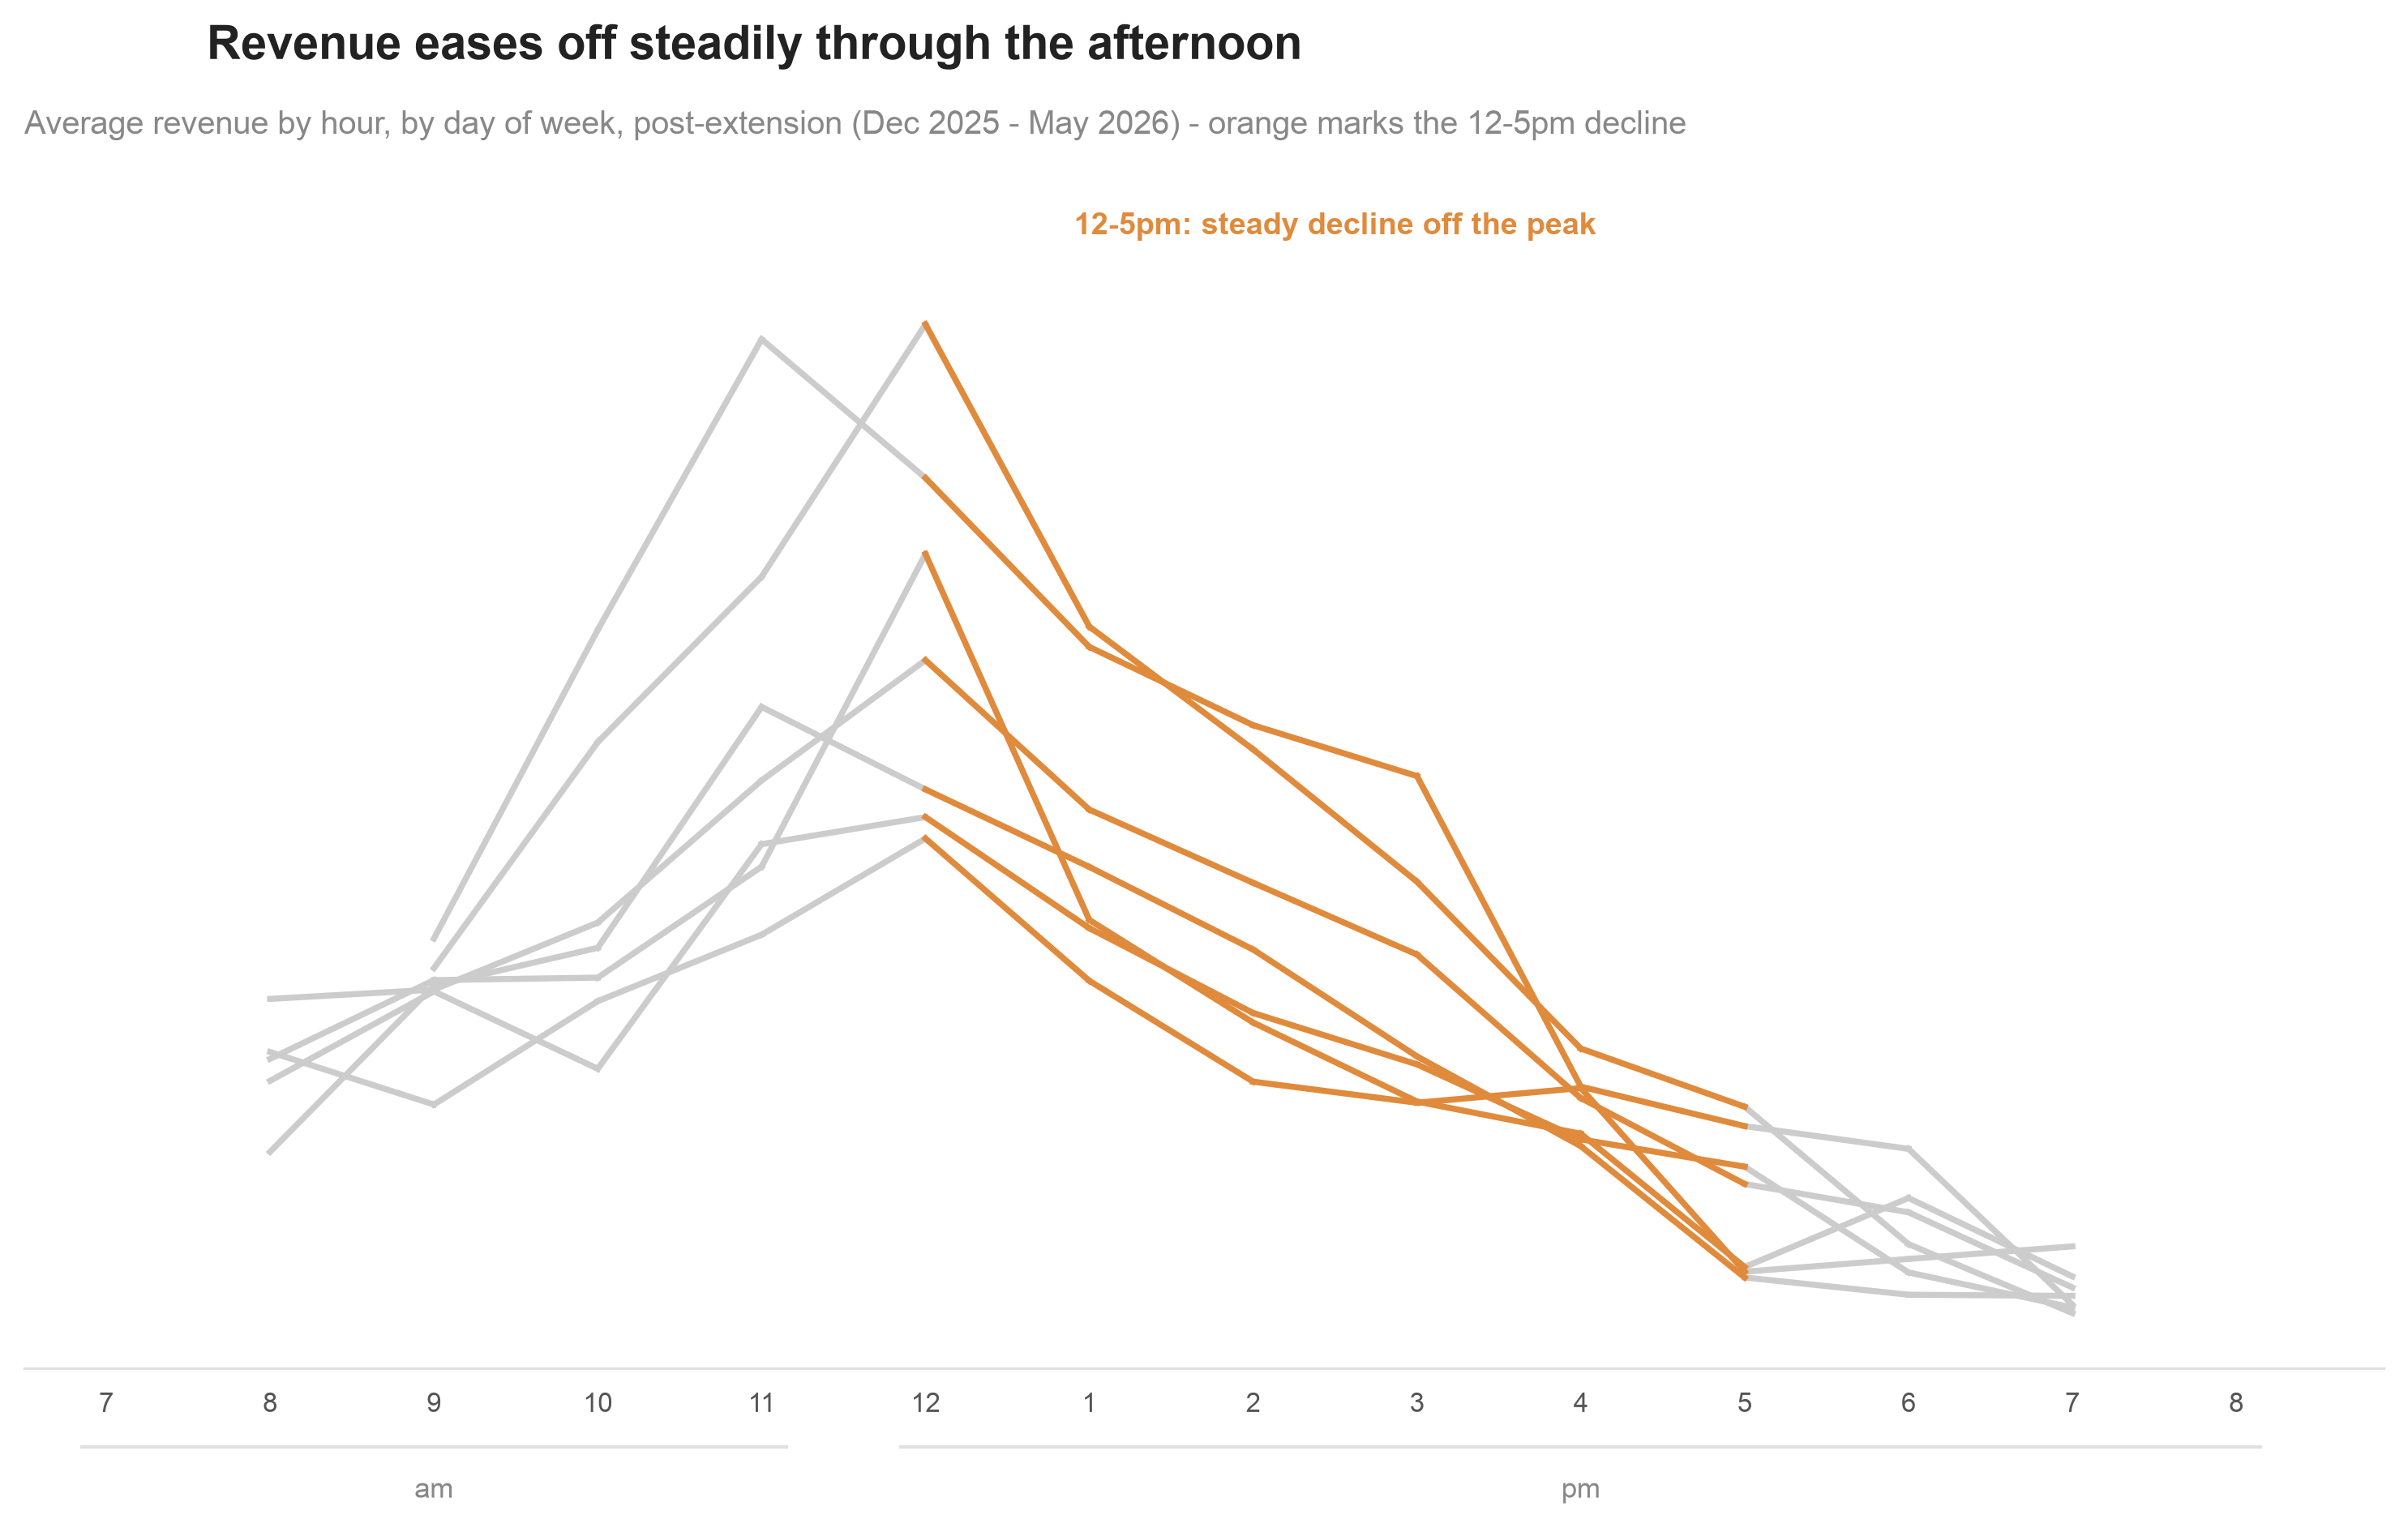

In [61]:
# CHART — Hourly revenue shape, noon-to-5pm highlighted (steady decline off the peak)

fig, ax = plt.subplots(figsize=(10, 6.5))

ZONE_START, ZONE_END = 12, 17  # noon peak through 5pm

for day in days:
    row = hourly_dow_revenue_post.loc[day].dropna()
    hrs, vals = row.index.tolist(), row.values
    for i in range(len(hrs) - 1):
        h1, h2 = hrs[i], hrs[i + 1]
        v1, v2 = vals[i], vals[i + 1]
        in_zone = h1 >= ZONE_START and h2 <= ZONE_END
        ax.plot([h1, h2], [v1, v2], color=(ORANGE if in_zone else GREY_LINE),
                lw=1.8, zorder=(3 if in_zone else 2))

day_max = hourly_dow_revenue_post.max().max()
hours_list = list(range(7, 21))
hour_labels_local = [str(h if h <= 12 else h - 12) for h in hours_list]

ax.text((ZONE_START + ZONE_END) / 2, day_max * 1.08, '12-5pm: steady decline off the peak',
        ha='center', va='bottom', fontsize=9, color=ORANGE, fontweight='bold')

fig.suptitle('Revenue eases off steadily through the afternoon', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour, by day of week, post-extension (Dec 2025 - May 2026) - orange marks the 12-5pm decline',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, day_max * 1.15)
ax.set_xlim(hours_list[0] - 0.5, hours_list[-1] + 0.9)
ax.set_xticks(hours_list)
ax.set_xticklabels(hour_labels_local, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours_list[0], 11), ('pm', 12, hours_list[-1])])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.spines['bottom'].set_color(AXIS)
ax.tick_params(bottom=False, colors=TICK)
plt.subplots_adjust(left=0.015, right=0.985, top=0.8892, bottom=0.1294)
save_chart(fig, bbox=None)
plt.show()


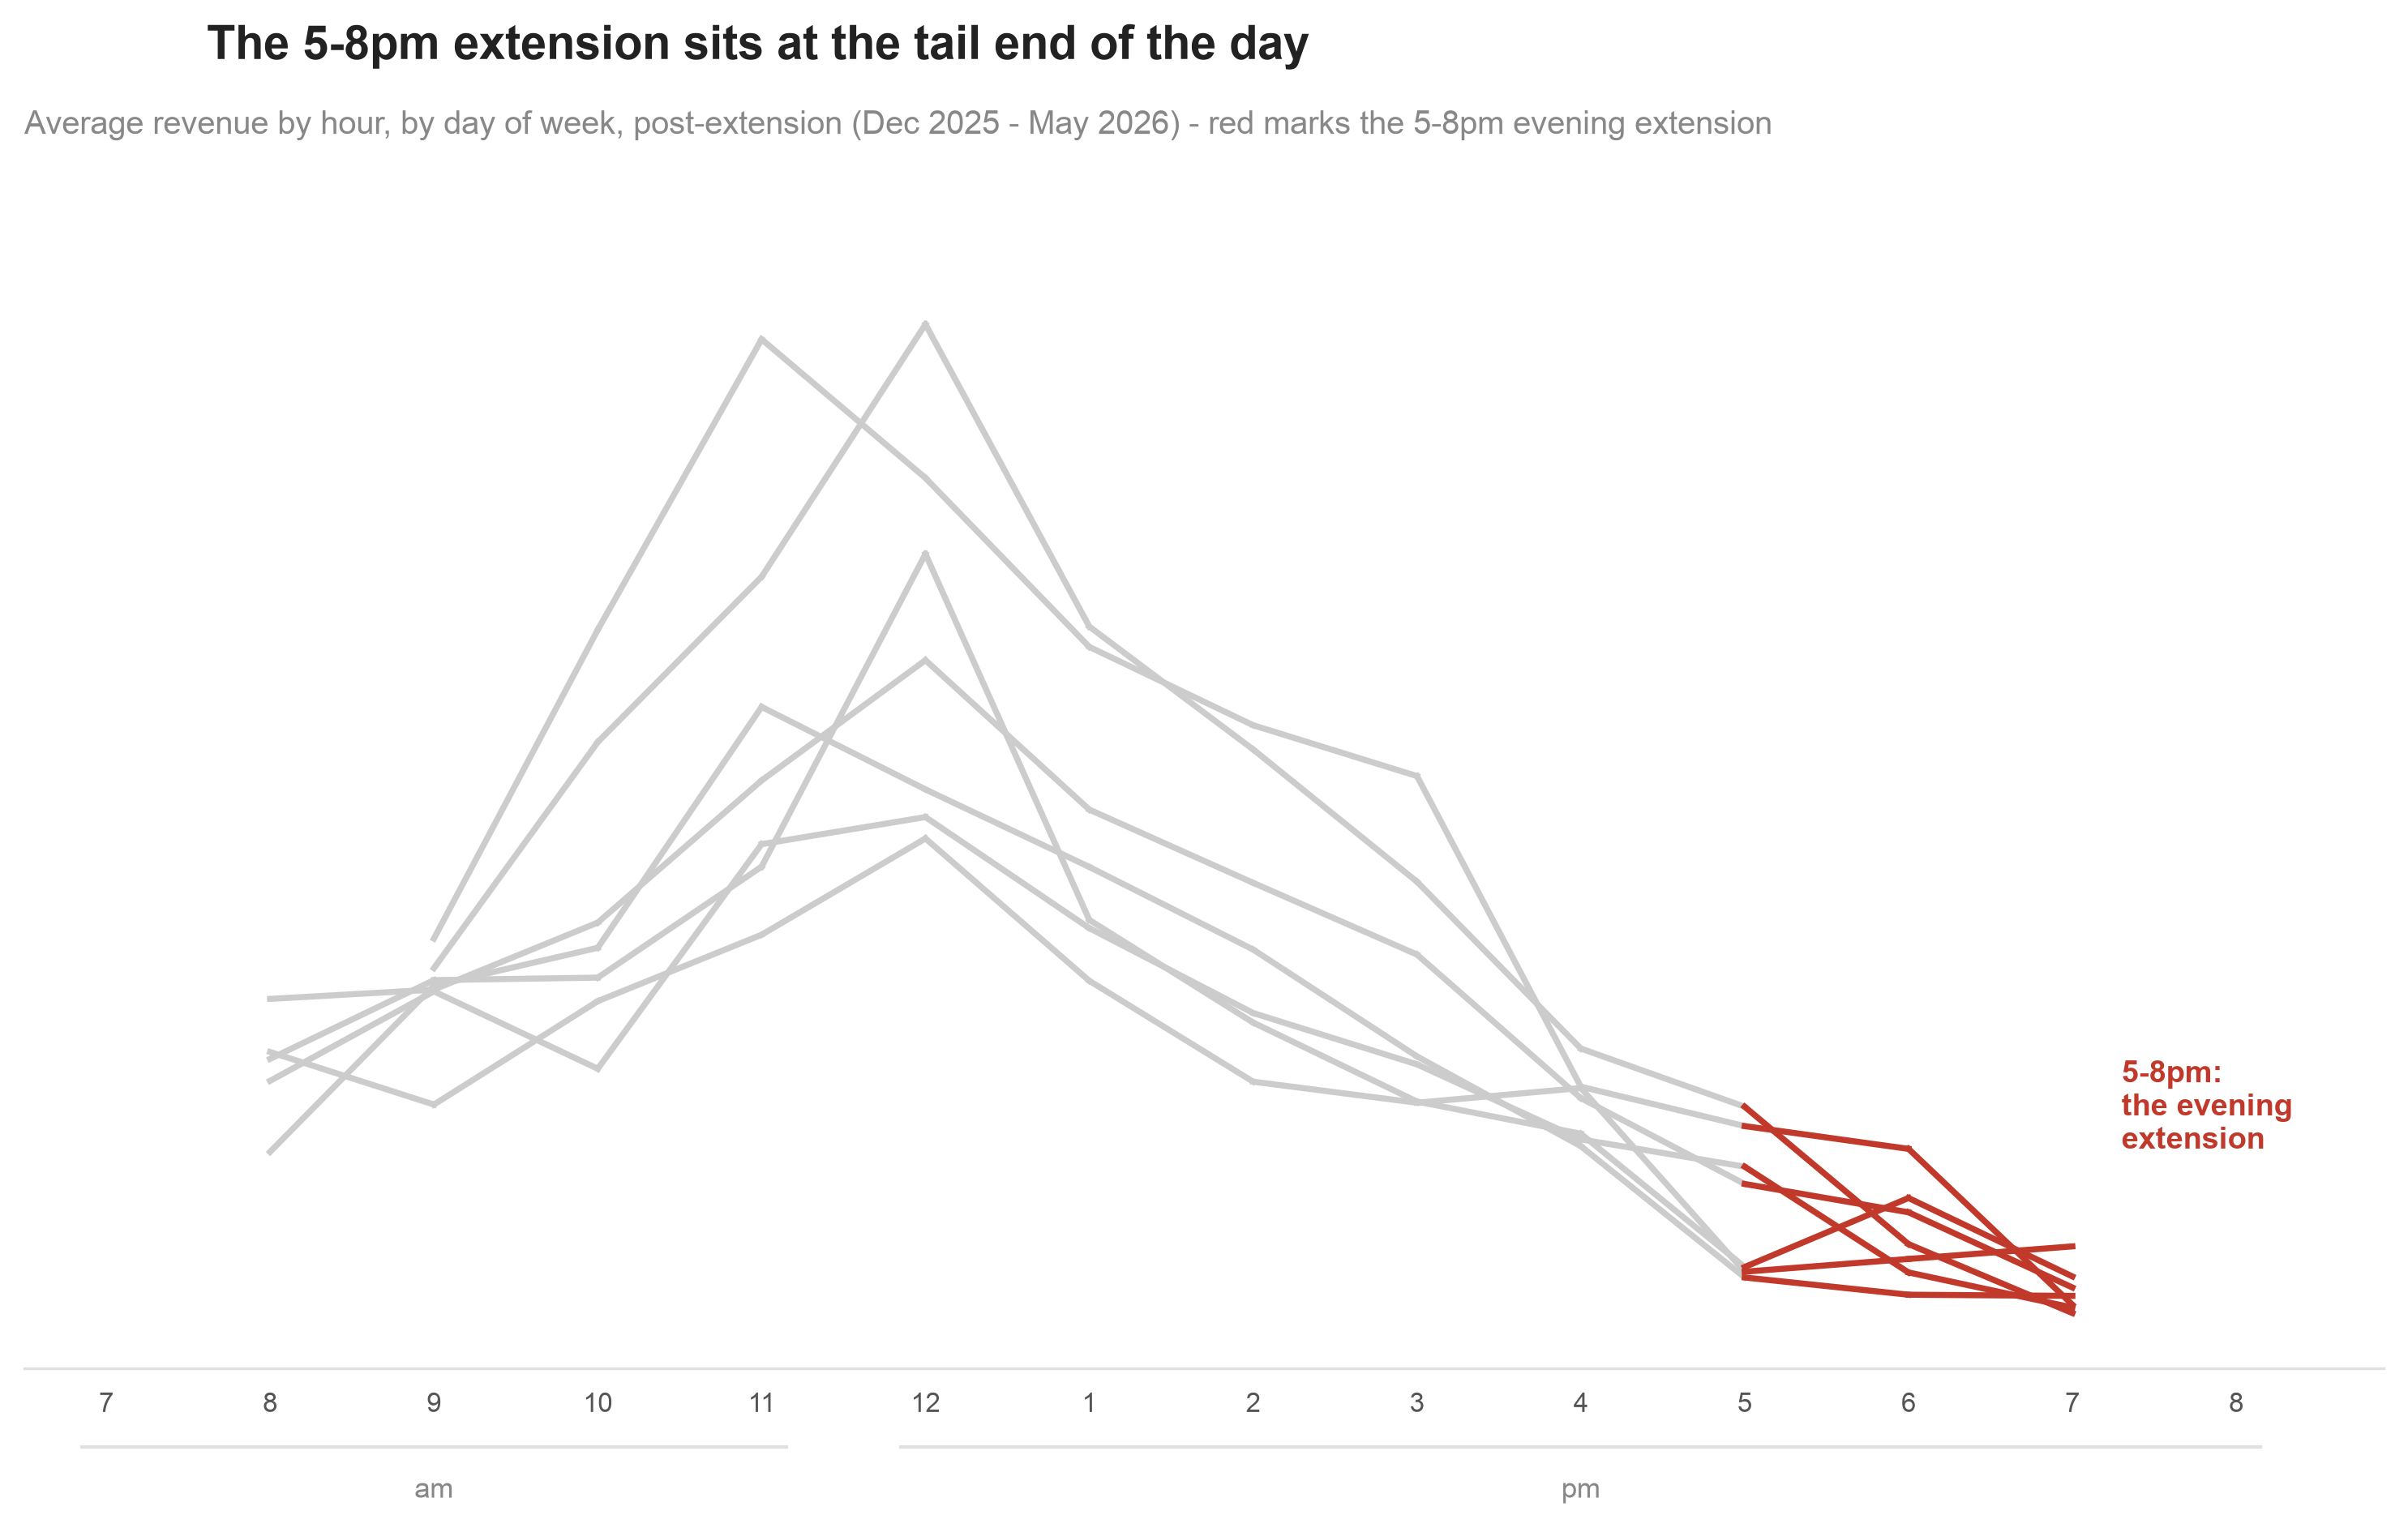

In [62]:
# CHART — Hourly revenue shape, 5-8pm highlighted (the evening extension window)

fig, ax = plt.subplots(figsize=(10, 6.5))

ZONE_START, ZONE_END = 17, 20  # the 5-8pm evening extension

for day in days:
    row = hourly_dow_revenue_post.loc[day].dropna()
    hrs, vals = row.index.tolist(), row.values
    for i in range(len(hrs) - 1):
        h1, h2 = hrs[i], hrs[i + 1]
        v1, v2 = vals[i], vals[i + 1]
        in_zone = h1 >= ZONE_START and h2 <= ZONE_END
        ax.plot([h1, h2], [v1, v2], color=(RED if in_zone else GREY_LINE),
                lw=1.8, zorder=(3 if in_zone else 2))

day_max = hourly_dow_revenue_post.max().max()
hours_list = list(range(7, 21))
hour_labels_local = [str(h if h <= 12 else h - 12) for h in hours_list]

last_data_hour = max(h for day in days for h, v in hourly_dow_revenue_post.loc[day].dropna().items())
ax.text(last_data_hour + 0.3, day_max * 0.25, '5-8pm:\nthe evening\nextension',
        ha='left', va='center', fontsize=9, color=RED, fontweight='bold')

fig.suptitle('The 5-8pm extension sits at the tail end of the day', x=0.09, ha='left', y=0.98,
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('Average revenue by hour, by day of week, post-extension (Dec 2025 - May 2026) - red marks the 5-8pm evening extension',
             loc='left', fontsize=9.5, color=MUTED, pad=10)

ax.set_ylim(0, day_max * 1.15)
ax.set_xlim(hours_list[0] - 0.5, hours_list[-1] + 0.9)
ax.set_xticks(hours_list)
ax.set_xticklabels(hour_labels_local, fontsize=8, color=TICK)
add_year_axis_groups(ax, [('am', hours_list[0], 11), ('pm', 12, hours_list[-1])])

for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.get_yaxis().set_visible(False)
ax.spines['bottom'].set_color(AXIS)
ax.tick_params(bottom=False, colors=TICK)
plt.subplots_adjust(left=0.015, right=0.985, top=0.8892, bottom=0.1294)
save_chart(fig, bbox=None)
plt.show()


In [63]:
# Summary of every chart exported (each chart cell above already saved itself via save_chart()
# at the moment it was created -- 4K-width PNGs, ready to hand off for the presentation)

exported = sorted(os.listdir(OUTPUT_DIR))
print(f'{len(exported)} charts saved to ./{OUTPUT_DIR}/\n')
for fname in exported:
    size_kb = os.path.getsize(os.path.join(OUTPUT_DIR, fname)) / 1024
    print(f'  {fname}  ({size_kb:,.0f} KB)')

41 charts saved to ./charts/

  01_monthly_revenue_is_up_82_since_new_ownership_took_over.png  (143 KB)
  02_revenue_was_already_climbing_before_the_extension.png  (148 KB)
  03_revenue_was_already_climbing_before_the_extension.png  (168 KB)
  04_growth_visibly_steepens_once_evening_hours_are_extended.png  (190 KB)
  05_revenue_rose_across_the_whole_day_not_just_the_evening.png  (248 KB)
  06_the_evening_extension_barely_registers_against_the_rest_of_t.png  (222 KB)
  07_5_8pm_accounts_for_just_9_of_total_post_extension_revenue.png  (118 KB)
  08_average_orders_per_hour.png  (213 KB)
  09_the_evening_hours_barely_add_any_traffic_either.png  (188 KB)
  10_5_8pm_accounts_for_just_7_of_total_post_extension_orders.png  (113 KB)
  11_5_8pm_a_quarter_of_the_hours_a_fraction_of_the_results.png  (132 KB)
  12_every_day_grew_after_the_extension_but_weekends_grew_the_mos.png  (196 KB)
  13_saturday_late_morning_and_sunday_midday_are_the_true_revenue.png  (123 KB)
  14_saturday_and_sunday_lead_th